In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os 

In [2]:
# Display all columns in the DataFrame without hiding any columns.
pd.set_option("display.max_columns", None)
# Display up to 100 rows of the DataFrame when printing it.
pd.set_option("display.max_rows", 100)

In [3]:
orders = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="ISO-8859-1")
description = pd.read_csv("DescriptionDataCoSupplyChain.csv")
access_logs = pd.read_csv("tokenized_access_logs.csv")

In [4]:
print("Orders:", orders.shape)
print("Description:", description.shape)
print("Access logs:", access_logs.shape)

Orders: (180519, 53)
Description: (52, 2)
Access logs: (469977, 8)


In [5]:
orders.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [6]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [7]:
orders.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,180519,4,DEBIT,69295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days for shipping (real),180519.0,NaN,NaN,NaN,3.497654,1.623722,0.0,2.0,3.0,5.0,6.0
Days for shipment (scheduled),180519.0,NaN,NaN,NaN,2.931847,1.374449,0.0,2.0,4.0,4.0,4.0
Benefit per order,180519.0,NaN,NaN,NaN,21.974989,104.433526,-4274.97998,7.0,31.52,64.800003,911.799988
Sales per customer,180519.0,NaN,NaN,NaN,183.107609,120.04367,7.49,104.379997,163.990005,247.399994,1939.98999
Delivery Status,180519,4,Late delivery,98977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Late_delivery_risk,180519.0,NaN,NaN,NaN,0.548291,0.497664,0.0,0.0,1.0,1.0,1.0
Category Id,180519.0,NaN,NaN,NaN,31.851451,15.640064,2.0,18.0,29.0,45.0,76.0
Category Name,180519,50,Cleats,24551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer City,180519,563,Caguas,66770,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# The dataset contains 180,519 records describing e-commerce orders, customers,
# products, sales, and shipping information.
# The descriptive statistics show that 54.83% of records have a late-delivery
# risk value of 1, while the average actual shipping time is 3.50 days and the
# average scheduled shipping time is 2.93 days.
# Standard Class is the most frequently recorded shipping mode, and Cleats
# is the most frequently recorded product category.
# The dataset also includes geographical information, customer segments,
# product prices, discounts, sales, and profit-related variables.
# These data can be explored to understand delivery performance, sales patterns,
# customer behavior, and profitability.

In [9]:
missing = pd.DataFrame({
    "missing_count": orders.isnull().sum(),
    "missing_percentage": orders.isnull().mean() * 100
})

missing = missing.sort_values(
    "missing_percentage",
    ascending=False
)

missing

,missing_count,missing_percentage
Product Description,180519,100.000000
Order Zipcode,155679,86.239676
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662
Days for shipment (scheduled),0,0.000000
Sales per customer,0,0.000000
Benefit per order,0,0.000000
Delivery Status,0,0.000000
Late_delivery_risk,0,0.000000
Customer City,0,0.000000


In [10]:
print("Total rows:", len(orders))
print("Duplicate rows:", orders.duplicated().sum())

Total rows: 180519
Duplicate rows: 0


In [11]:
print("Unique Order IDs:", orders["Order Id"].nunique())
print("Unique Order Item IDs:", orders["Order Item Id"].nunique())
print("Unique Product IDs:", orders["Product Card Id"].nunique())
print("Unique Customer IDs:", orders["Customer Id"].nunique())

Unique Order IDs: 65752
Unique Order Item IDs: 180519
Unique Product IDs: 118
Unique Customer IDs: 20652


In [12]:
# Interpretation of Unique Values

# The dataset contains 180,519 order-item records from the DataCo supply chain dataset.
# There are 65,752 unique Order IDs, indicating that multiple order-item records can belong to the same order.
# There are 180,519 unique Order Item IDs, meaning each row has a distinct order-item identifier.
# There are 118 unique Product IDs, indicating that the dataset contains 118 distinct products.
# There are 20,652 unique Customer IDs, representing the number of distinct customers.
# Overall, the dataset records multiple products or items across orders placed by
# different customers, making it suitable for analyzing order patterns, product
# performance, customer behavior, and supply chain operations.

In [13]:
orders["Late_delivery_risk"].value_counts()

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

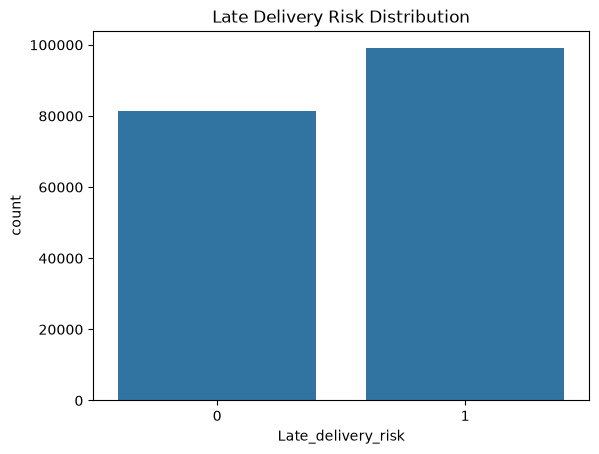

In [14]:
sns.countplot(data=orders, x="Late_delivery_risk")
plt.title("Late Delivery Risk Distribution")
plt.show()

In [15]:
# Interpretation of Target Variable Balance
# The target variable 'Late_delivery_risk' contains two classes:
# 1 (Late delivery risk): 98,977 records (54.83%)
# 0 (No late delivery risk): 81,542 records (45.17%)
# The dataset has a relatively balanced target distribution, with a difference
# of approximately 9.66 percentage points between the two classes.
# Therefore, the dataset does not have a severe class imbalance, and
# resampling techniques may not be necessary initially.
# However, model performance should be evaluated using precision, recall,
# F1-score, and the confusion matrix, rather than accuracy alone.


In [16]:
orders["order date (DateOrders)"].head()

0    1/31/2018 22:56
1    1/13/2018 12:27
2    1/13/2018 12:06
3    1/13/2018 11:45
4    1/13/2018 11:24
Name: order date (DateOrders), dtype: str

In [17]:
orders["order_date"] = pd.to_datetime(
    orders["order date (DateOrders)"],
    errors="coerce"
)

In [18]:
orders["order_date"] = pd.to_datetime(
    orders["order date (DateOrders)"],
    errors="coerce"
)

In [19]:
# Interpretation of Order Date Conversion
# The 'order date (DateOrders)' column contains date and time values stored as strings.
# The pd.to_datetime() function converts these string values into datetime format,
# allowing date-based analysis such as identifying monthly trends, seasonal patterns,
# and changes in order volume over time.
# The parameter errors='coerce' converts invalid date values into NaT (Not a Time),
# which can be checked and handled during data cleaning.
# The converted values are stored in a new column called 'order_date'.
# Note: The conversion code is repeated twice, so one conversion statement is sufficient.

In [20]:
pd.crosstab(
    orders["Shipping Mode"],
    orders["Late_delivery_risk"],
    normalize="index"
) * 100

Late_delivery_risk,0,1
Shipping Mode,,
First Class,4.677501,95.322499
Same Day,54.256958,45.743042
Second Class,23.367219,76.632781
Standard Class,61.928317,38.071683


In [21]:
# Calculate the percentage distribution of late delivery risk
shipping_risk = pd.crosstab(
    orders["Shipping Mode"],
    orders["Late_delivery_risk"],
    normalize="index"
) * 100

# Display the results
print("Late Delivery Risk (%) by Shipping Mode")
display(shipping_risk.round(2))


Late Delivery Risk (%) by Shipping Mode


Late_delivery_risk,0,1
Shipping Mode,,
First Class,4.68,95.32
Same Day,54.26,45.74
Second Class,23.37,76.63
Standard Class,61.93,38.07


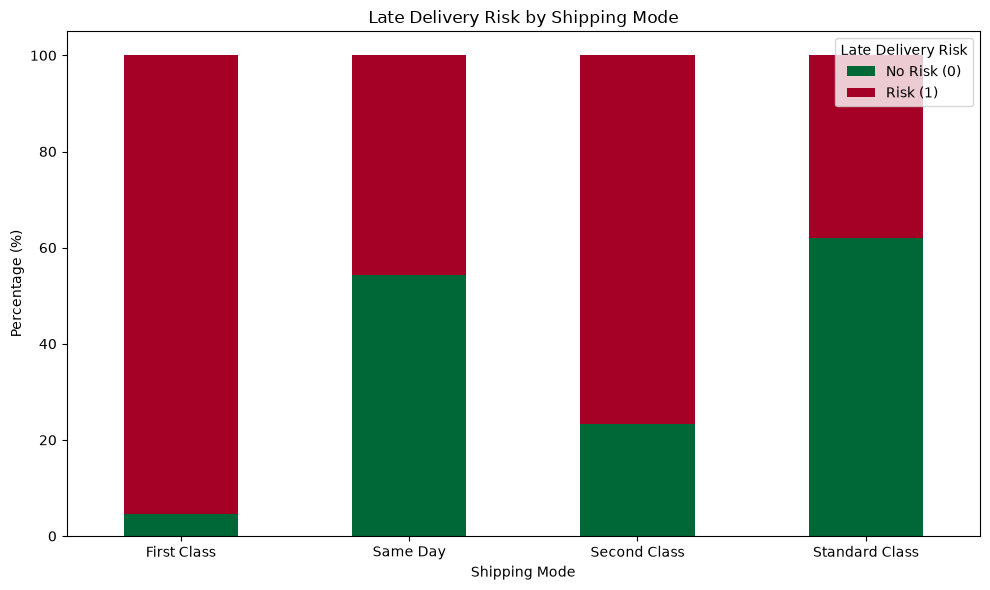

In [22]:

# Create a stacked bar chart showing the percentage of each class
shipping_risk.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    colormap="RdYlGn_r"
)

plt.title("Late Delivery Risk by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(
    title="Late Delivery Risk",
    labels=["No Risk (0)", "Risk (1)"]
)
plt.tight_layout()
plt.show()


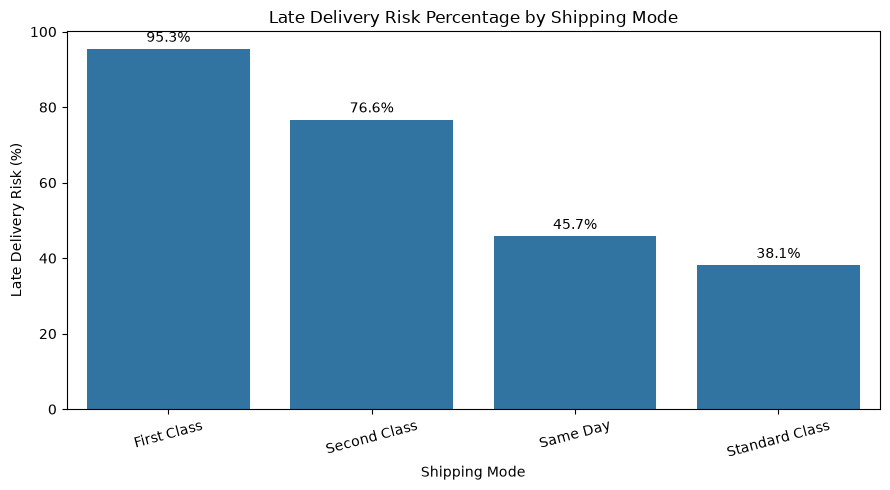

In [23]:

# Extract the percentage of late delivery risk for each shipping mode
late_risk = (
    orders.groupby("Shipping Mode")["Late_delivery_risk"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Plot late delivery risk percentages
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=late_risk.index,
    y=late_risk.values
)

plt.title("Late Delivery Risk Percentage by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Risk (%)")
plt.xticks(rotation=15)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


In [24]:
pd.crosstab(
    orders["Order Region"],
    orders["Late_delivery_risk"],
    normalize="index"
) * 100

Late_delivery_risk,0,1
Order Region,,
Canada,51.199166,48.800834
Caribbean,46.922337,53.077663
Central Africa,42.039356,57.960644
Central America,45.245404,54.754596
Central Asia,44.665461,55.334539
East Africa,44.060475,55.939525
East of USA,44.338395,55.661605
Eastern Asia,45.673077,54.326923
Eastern Europe,44.336735,55.663265


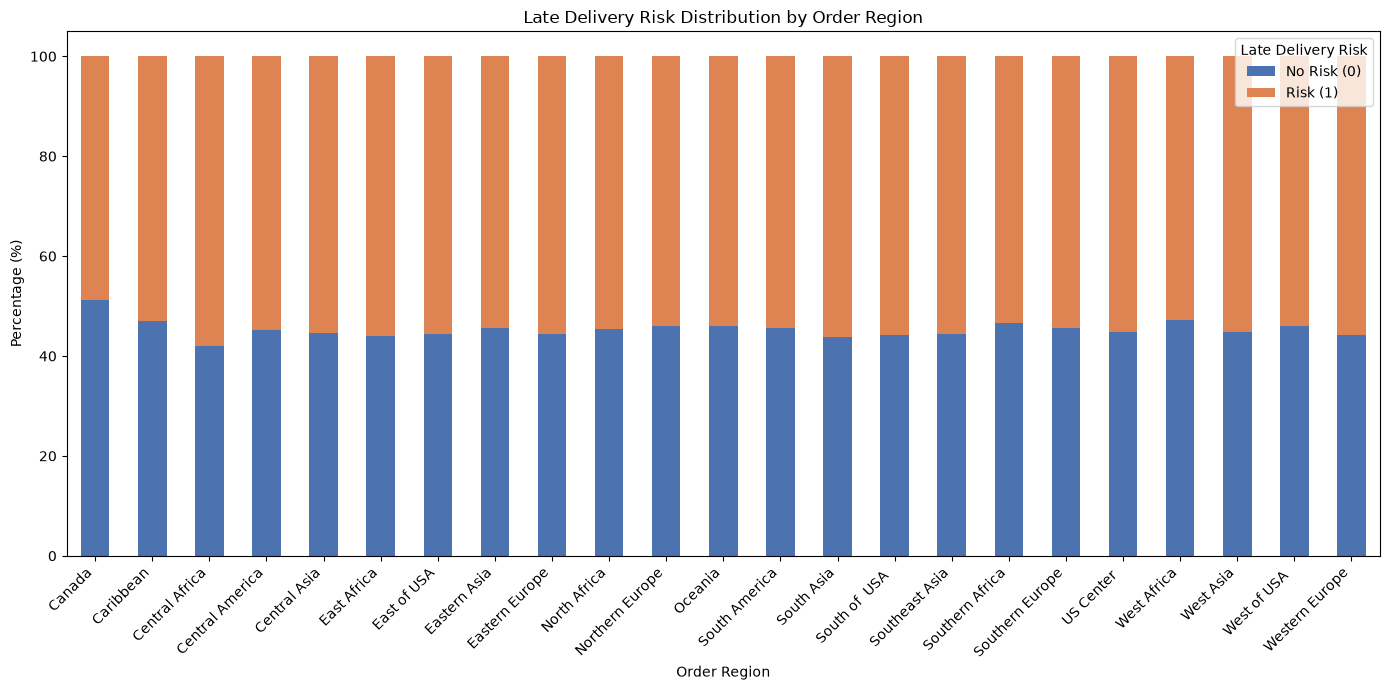

In [25]:

# Calculate percentage distribution of late delivery risk by region
region_risk = pd.crosstab(
    orders["Order Region"],
    orders["Late_delivery_risk"],
    normalize="index"
) * 100

# Visualize both classes using a stacked bar chart
region_risk.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    color=["#4C72B0", "#DD8452"]
)

plt.title("Late Delivery Risk Distribution by Order Region")
plt.xlabel("Order Region")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Late Delivery Risk",
    labels=["No Risk (0)", "Risk (1)"]
)
plt.tight_layout()
plt.show()


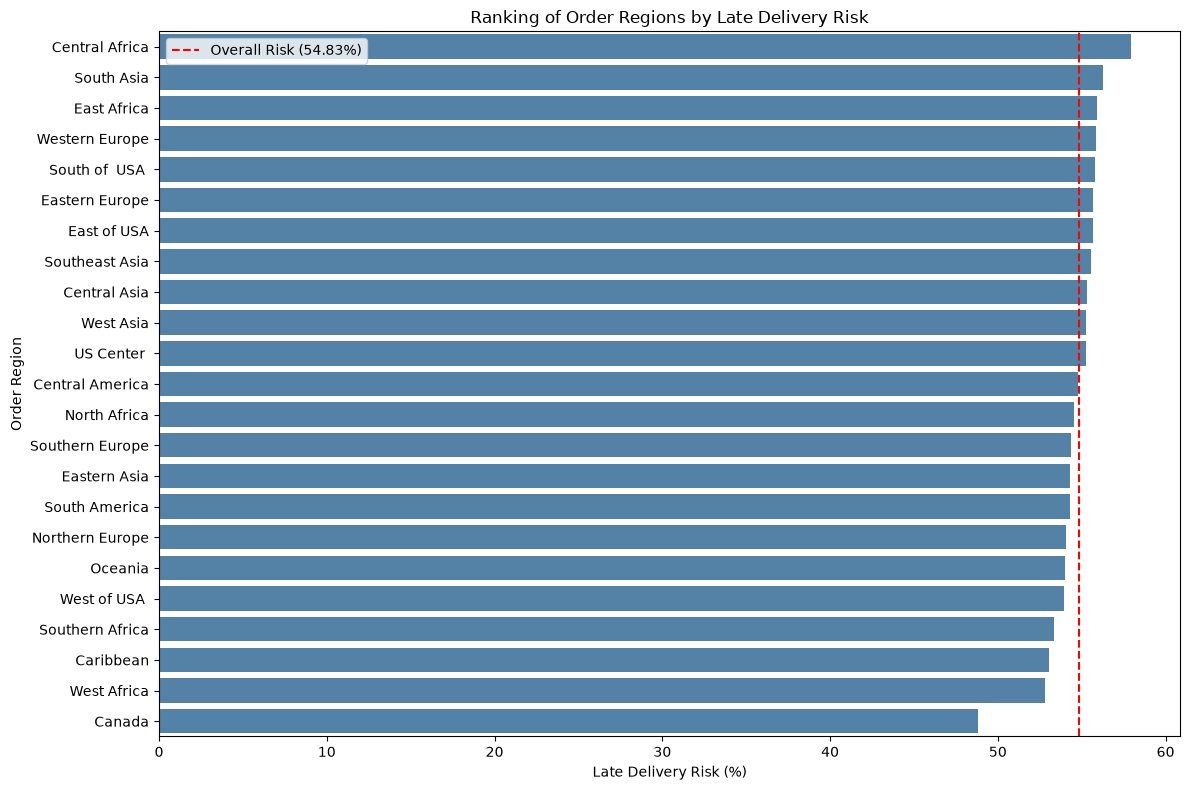

In [26]:

# Calculate late delivery risk percentage for each region
late_risk_region = (
    orders.groupby("Order Region")["Late_delivery_risk"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Visualize regions ranked by late delivery risk
plt.figure(figsize=(12, 8))

ax = sns.barplot(
    x=late_risk_region.values,
    y=late_risk_region.index,
    color="steelblue"
)

# Add the overall dataset risk as a reference line
overall_risk = orders["Late_delivery_risk"].mean() * 100

plt.axvline(
    overall_risk,
    color="red",
    linestyle="--",
    label=f"Overall Risk ({overall_risk:.2f}%)"
)

plt.title("Ranking of Order Regions by Late Delivery Risk")
plt.xlabel("Late Delivery Risk (%)")
plt.ylabel("Order Region")
plt.legend()
plt.tight_layout()
plt.show()


In [27]:
pd.crosstab(
    orders["Category Name"],
    orders["Late_delivery_risk"],
    normalize="index"
) * 100

Late_delivery_risk,0,1
Category Name,,
Accessories,43.033708,56.966292
As Seen on TV!,42.647059,57.352941
Baby,47.342995,52.657005
Baseball & Softball,44.778481,55.221519
Basketball,44.776119,55.223881
Books,43.456790,56.543210
Boxing & MMA,43.735225,56.264775
CDs,47.970480,52.029520
Cameras,41.891892,58.108108


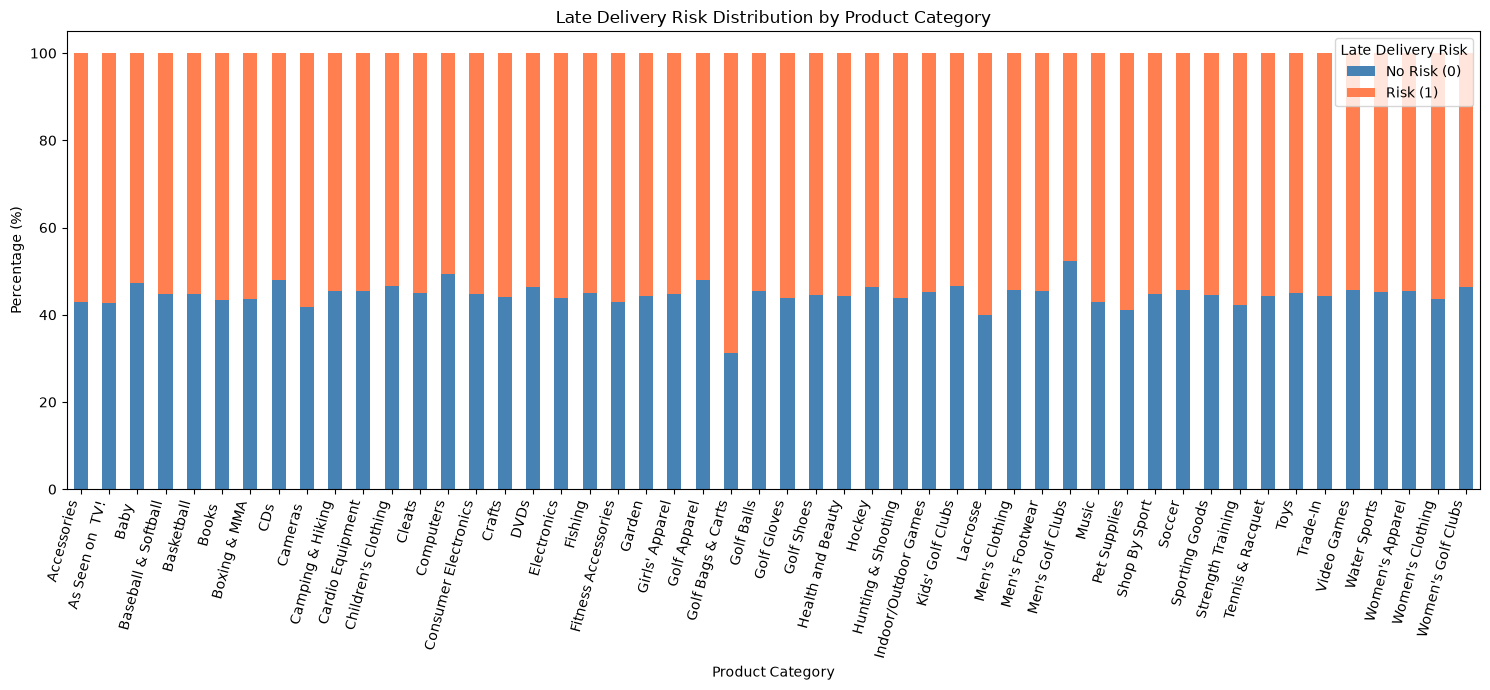

In [28]:

# Calculate percentage distribution of late delivery risk by product category
category_risk = pd.crosstab(
    orders["Category Name"],
    orders["Late_delivery_risk"],
    normalize="index"
) * 100

# Plot both target classes using a stacked bar chart
category_risk.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7),
    color=["steelblue", "coral"]
)

plt.title("Late Delivery Risk Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=75, ha="right")
plt.legend(
    title="Late Delivery Risk",
    labels=["No Risk (0)", "Risk (1)"]
)
plt.tight_layout()
plt.show()


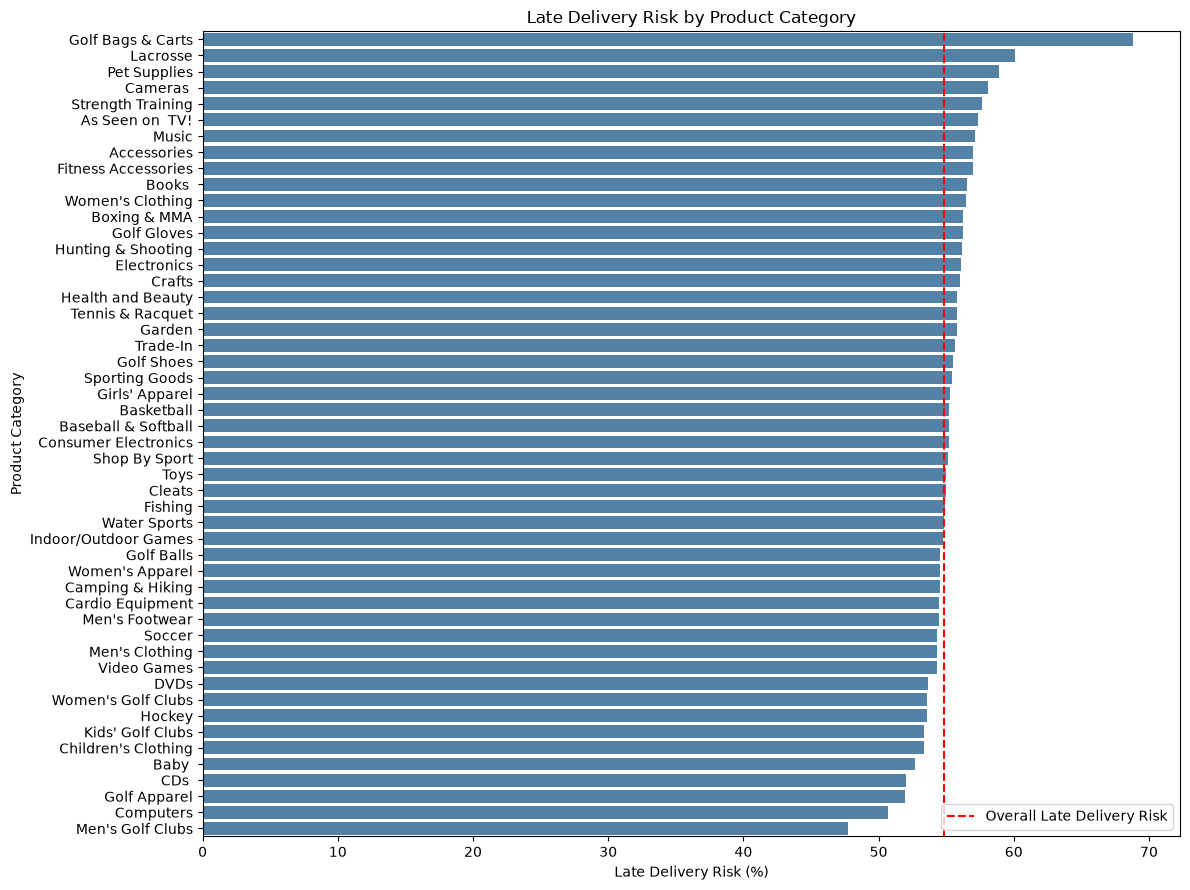

In [29]:

# Calculate late delivery risk percentage for each product category
category_late_risk = (
    orders.groupby("Category Name")["Late_delivery_risk"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Plot categories from highest to lowest risk
plt.figure(figsize=(12, 9))

sns.barplot(
    x=category_late_risk.values,
    y=category_late_risk.index,
    color="steelblue"
)

plt.axvline(
    orders["Late_delivery_risk"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall Late Delivery Risk"
)

plt.title("Late Delivery Risk by Product Category")
plt.xlabel("Late Delivery Risk (%)")
plt.ylabel("Product Category")
plt.legend()
plt.tight_layout()
plt.show()


In [30]:

# Create a directory named "results" to store output files.
# exist_ok=True prevents an error if the directory already exists
os.makedirs("results", exist_ok=True)

In [31]:
# Save the shipping mode EDA table
shipping_risk.to_csv("results/shipping_mode_risk.csv")

# Save the regional EDA table
region_risk.to_csv("results/region_risk.csv")

# Save the product category EDA table
category_risk.to_csv("results/category_risk.csv")

print("EDA results saved successfully!")


EDA results saved successfully!


In [32]:
data_audit = pd.DataFrame({
    "missing_count": orders.isnull().sum(),
    "missing_percentage": orders.isnull().mean() * 100
}).sort_values("missing_percentage", ascending=False)

In [33]:

data_audit.to_csv('data/data_audit.csv', index=False)

In [34]:
# Display all columns of a pandas DataFrame without hiding any columns.
pd.set_option("display.max_columns", None)


In [35]:
# Use encoding="ISO-8859-1" (Latin-1) to safely read international characters 
# (like French/Spanish accents in the dataset) and prevent UnicodeDecodeErrors

In [36]:
orders = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="ISO-8859-1")
print("Shape:", orders.shape)

Shape: (180519, 53)


In [37]:
df = orders.copy()

print(df.shape)

(180519, 53)


In [38]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [39]:

# Find duplicate columns without transposing the entire DataFrame
duplicate_columns = []
columns = df.columns.tolist()

for i in range(len(columns)):
    for j in range(i):
        if df[columns[i]].equals(df[columns[j]]):
            duplicate_columns.append(columns[i])
            break

print("Duplicate columns:", duplicate_columns)
print("Number of duplicate columns:", len(duplicate_columns))


Duplicate columns: ['Customer Password', 'Order Customer Id', 'Order Item Total', 'Order Profit Per Order', 'Product Card Id', 'Product Category Id', 'Product Price']
Number of duplicate columns: 7


In [40]:

# Identify the original column corresponding to each duplicate column

columns = df.columns.tolist()
duplicate_pairs = []

for i in range(len(columns)):
    for j in range(i):
        if df[columns[i]].equals(df[columns[j]]):
            duplicate_pairs.append({
                "Duplicate Column": columns[i],
                "Matches Original Column": columns[j]
            })
            break

# Display the duplicate column pairs
duplicate_pairs_df = pd.DataFrame(duplicate_pairs)
display(duplicate_pairs_df)


,Duplicate Column,Matches Original Column
0,Customer Password,Customer Email
1,Order Customer Id,Customer Id
2,Order Item Total,Sales per customer
3,Order Profit Per Order,Benefit per order
4,Product Card Id,Order Item Cardprod Id
5,Product Category Id,Category Id
6,Product Price,Order Item Product Price


In [41]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
Product Description,180519,100.000000
Order Zipcode,155679,86.239676
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662
Days for shipment (scheduled),0,0.000000
Sales per customer,0,0.000000
Benefit per order,0,0.000000
Delivery Status,0,0.000000
Late_delivery_risk,0,0.000000
Customer City,0,0.000000


In [42]:
missing_data= missing[missing["Missing_Count"] > 0]
missing_data

,Missing_Count,Missing_Percentage
Product Description,180519,100.000000
Order Zipcode,155679,86.239676
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662


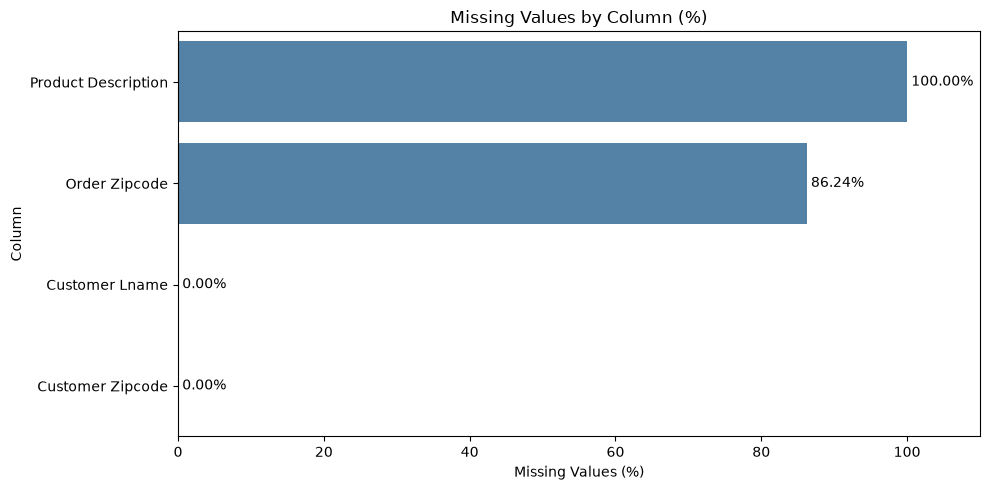

In [43]:


# Plot missing-value percentages
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=missing_data["Missing_Percentage"],
    y=missing_data.index,
    color="steelblue"
)

plt.title("Missing Values by Column (%)")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xlim(0, 110)
plt.tight_layout()
plt.show()


In [44]:
df.dtypes

Type                                 str
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Delivery Status                      str
Late_delivery_risk                 int64
Category Id                        int64
Category Name                        str
Customer City                        str
Customer Country                     str
Customer Email                       str
Customer Fname                       str
Customer Id                        int64
Customer Lname                       str
Customer Password                    str
Customer Segment                     str
Customer State                       str
Customer Street                      str
Customer Zipcode                 float64
Department Id                      int64
Department Name                      str
Latitude                         float64
Longitude                        float64
Market          

In [45]:
df.select_dtypes(include="number").columns.tolist()

['Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Late_delivery_risk',
 'Category Id',
 'Customer Id',
 'Customer Zipcode',
 'Department Id',
 'Latitude',
 'Longitude',
 'Order Customer Id',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Price',
 'Product Status']

In [46]:

# EDA: Summary of all numeric columns

numeric_cols = df.select_dtypes(include="number").columns

numeric_summary = pd.DataFrame({
    "Data_Type": df[numeric_cols].dtypes.astype(str),
    "Unique_Values": df[numeric_cols].nunique(),
    "Missing_Count": df[numeric_cols].isnull().sum(),
    "Missing_Percentage": df[numeric_cols].isnull().mean() * 100,
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Std_Deviation": df[numeric_cols].std(),
    "Minimum": df[numeric_cols].min(),
    "Maximum": df[numeric_cols].max()
})

display(numeric_summary.round(2))


,Data_Type,Unique_Values,Missing_Count,Missing_Percentage,Mean,Median,Std_Deviation,Minimum,Maximum
Days for shipping (real),int64,7,0,0.00,3.50,3.00,1.62,0.00,6.00
Days for shipment (scheduled),int64,4,0,0.00,2.93,4.00,1.37,0.00,4.00
Benefit per order,float64,21998,0,0.00,21.97,31.52,104.43,-4274.98,911.80
Sales per customer,float64,2927,0,0.00,183.11,163.99,120.04,7.49,1939.99
Late_delivery_risk,int64,2,0,0.00,0.55,1.00,0.50,0.00,1.00
Category Id,int64,51,0,0.00,31.85,29.00,15.64,2.00,76.00
Customer Id,int64,20652,0,0.00,6691.38,6457.00,4162.92,1.00,20757.00
Customer Zipcode,float64,995,3,0.00,35921.13,19380.00,37542.46,603.00,99205.00
Department Id,int64,11,0,0.00,5.44,5.00,1.63,2.00,12.00
Latitude,float64,11250,0,0.00,29.72,33.14,9.81,-33.94,48.78


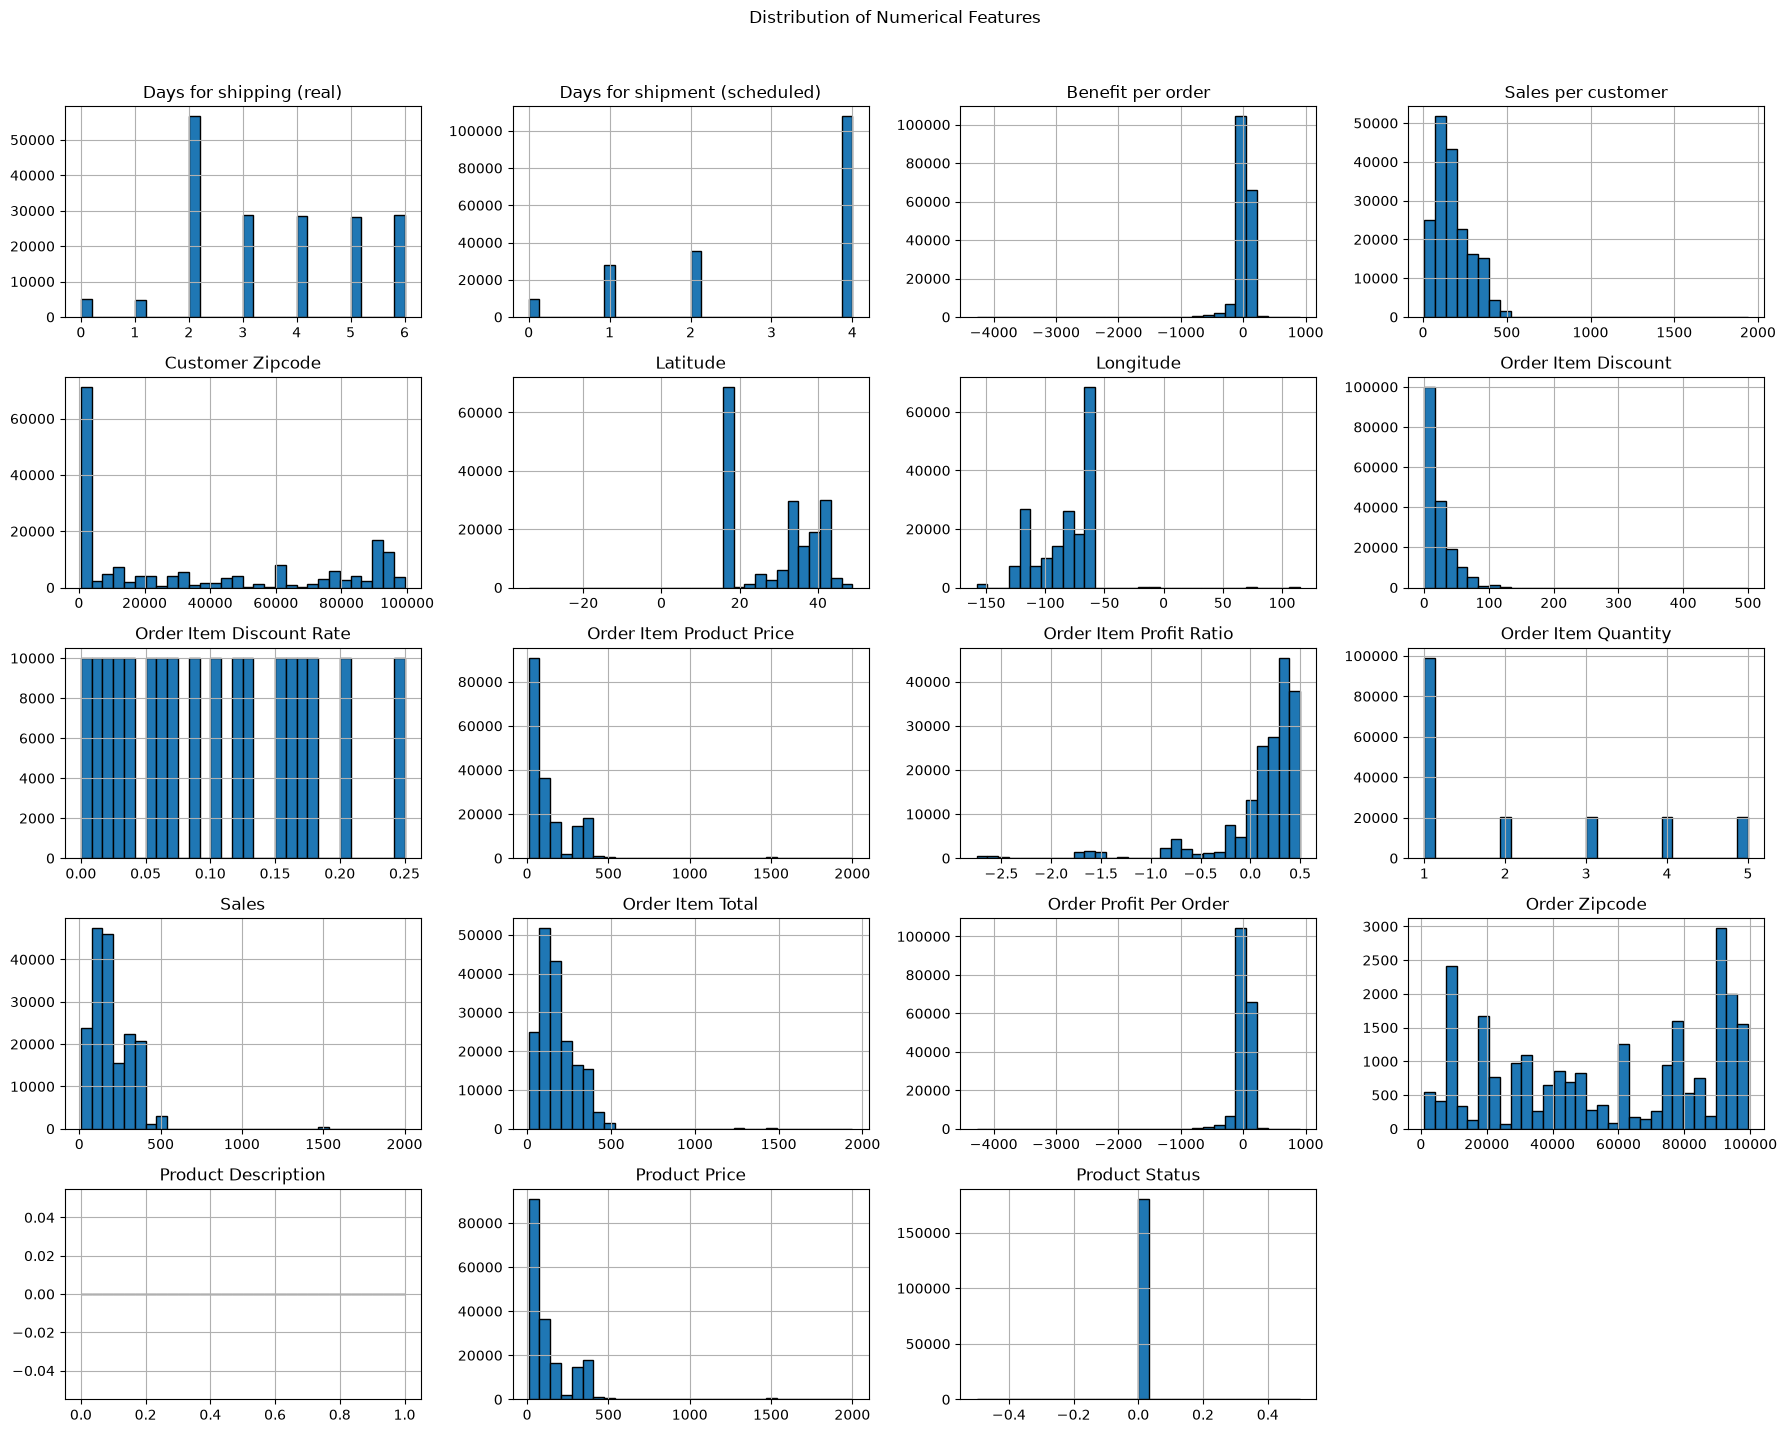

In [47]:


# Exclude identifier columns and the target from distribution plots
exclude_cols = [
    "Late_delivery_risk",
    "Customer Id",
    "Order Customer Id",
    "Order Id",
    "Order Item Id",
    "Order Item Cardprod Id",
    "Product Card Id",
    "Category Id",
    "Product Category Id",
    "Department Id"
]

plot_cols = [col for col in numeric_cols if col not in exclude_cols]

# Plot feature distributions
df[plot_cols].hist(
    bins=30,
    figsize=(18, 14),
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()


In [48]:
object_cols =df.select_dtypes(include="object").columns.tolist()
object_cols

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8388\3280993858.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols =df.select_dtypes(include="object").columns.tolist()


['Type',
 'Delivery Status',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Email',
 'Customer Fname',
 'Customer Lname',
 'Customer Password',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Department Name',
 'Market',
 'Order City',
 'Order Country',
 'order date (DateOrders)',
 'Order Region',
 'Order State',
 'Order Status',
 'Product Image',
 'Product Name',
 'shipping date (DateOrders)',
 'Shipping Mode']

In [49]:

# EDA: Summary of categorical and object columns


object_summary = pd.DataFrame({
    "Unique_Values": df[object_cols].nunique(),
    "Missing_Count": df[object_cols].isnull().sum(),
    "Missing_Percentage": df[object_cols].isnull().mean() * 100,
    "Most_Common_Value": [
        df[col].mode().iloc[0] if not df[col].mode().empty else None
        for col in object_cols
    ]
})

display(object_summary.sort_values("Unique_Values", ascending=False))


,Unique_Values,Missing_Count,Missing_Percentage,Most_Common_Value
order date (DateOrders),65752,0,0.000000,1/1/2015 19:58
shipping date (DateOrders),63701,0,0.000000,1/14/2016 15:56
Customer Street,7458,0,0.000000,9126 Wishing Expressway
Order City,3597,0,0.000000,Santo Domingo
Customer Lname,1109,8,0.004432,Smith
Order State,1089,0,0.000000,Inglaterra
Customer Fname,782,0,0.000000,Mary
Customer City,563,0,0.000000,Caguas
Order Country,164,0,0.000000,Estados Unidos
Product Image,118,0,0.000000,http://images.acmesports.sports/Perfect+Fitnes...


In [50]:
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)

In [51]:
print(df["order date (DateOrders)"].dtype)

datetime64[us]


In [52]:
df["order date (DateOrders)"].isna().sum()

np.int64(0)

In [53]:
df["Product Status"].nunique()

1

In [54]:
# Drop 'Product Status' because it has zero variance (all values are 0) and provides no predictive value

In [55]:
df["Product Description"].isna().all()

np.True_

In [56]:
# Drop 'Product Description' because it contains 100% missing values (count = 0) and adds no usable information

In [57]:
# Number of unique values
check_columns = [
    "Product Status",
    "Product Description",
    "Customer Id",
    "Order Id",
    "Order Item Id",
    "Product Card Id",
    "Category Id",
    "Department Id",
    "Late_delivery_risk"
]

for col in check_columns:
    print(
        f"{col}:",
        df[col].nunique(dropna=True)
    )

Product Status: 1
Product Description: 0
Customer Id: 20652
Order Id: 65752
Order Item Id: 180519
Product Card Id: 118
Category Id: 51
Department Id: 11
Late_delivery_risk: 2


In [58]:
# Missing values
for col in [
    "Customer Zipcode",
    "Order Zipcode",
    "Product Description",
    "Late_delivery_risk"
]:
    print(
        col,
        "missing =",
        df[col].isna().sum()
    )

Customer Zipcode missing = 3
Order Zipcode missing = 155679
Product Description missing = 180519
Late_delivery_risk missing = 0


In [59]:
columns_to_drop = [
    "Product Description",  # completely empty
    "Product Status"        # only one value
]

df = df.drop(columns=columns_to_drop)

In [60]:
#inspect categorical features
shipping_counts =df["Shipping Mode"].value_counts(dropna=False)
shipping_summary = pd.DataFrame({
    "Count": shipping_counts,
    "Percentage": (shipping_counts / len(df)) * 100
})

display(shipping_summary.round(2))


,Count,Percentage
Shipping Mode,,
Standard Class,107752,59.69
Second Class,35216,19.51
First Class,27814,15.41
Same Day,9737,5.39


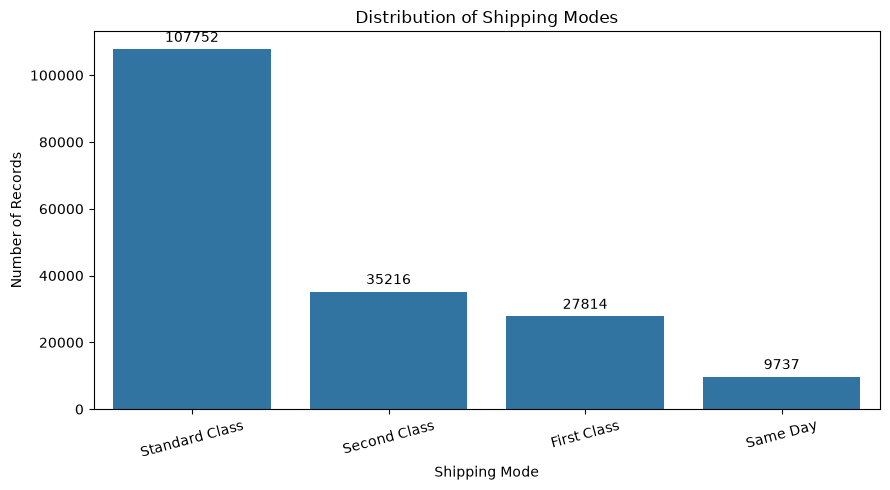

In [61]:


plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x="Shipping Mode",
    order=df["Shipping Mode"].value_counts().index
)

plt.title("Distribution of Shipping Modes")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


In [62]:
segment_counts = df["Customer Segment"].value_counts(dropna=False)

segment_summary = pd.DataFrame({
    "Count": segment_counts,
    "Percentage": (
        segment_counts / len(df)
    ) * 100
})

display(segment_summary.round(2))


,Count,Percentage
Customer Segment,,
Consumer,93504,51.80
Corporate,54789,30.35
Home Office,32226,17.85


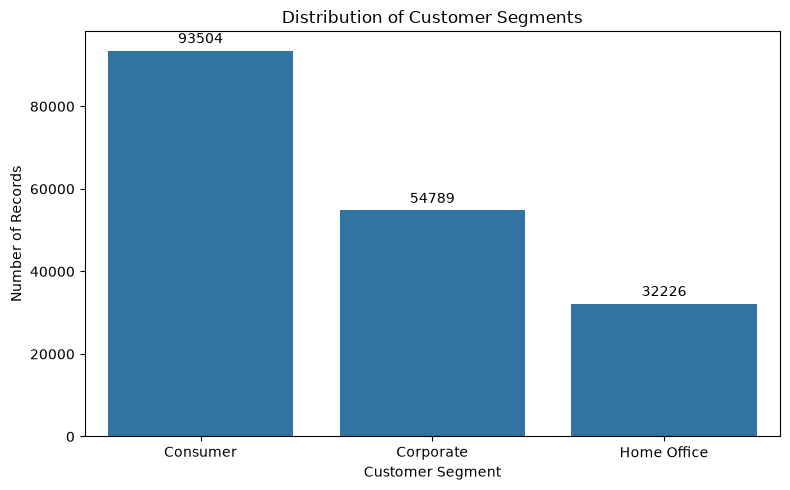

In [63]:


plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Customer Segment",
    order=df["Customer Segment"].value_counts().index
)

plt.title("Distribution of Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


In [64]:

# EDA Interpretation:
# This analysis examines the distribution of records across customer segments.
# The frequency table shows the count and percentage of each segment.
# The count plot identifies the most and least represented customer segments.
# The risk comparison examines differences in late delivery risk across segments.
# Segments with risk percentages above the overall average have higher-than-average
# late delivery risk in this dataset.
# These findings show associations and do not establish causal relationships.
# Customer Segment may be useful as a categorical feature for predicting delivery risk.


In [65]:

# EDA: Market frequency and percentage distribution

market_counts = df["Market"].value_counts(dropna=False)

market_summary = pd.DataFrame({
    "Count": market_counts,
    "Percentage": market_counts / len(df) * 100
})

display(market_summary.round(2))


,Count,Percentage
Market,,
LATAM,51594,28.58
Europe,50252,27.84
Pacific Asia,41260,22.86
USCA,25799,14.29
Africa,11614,6.43


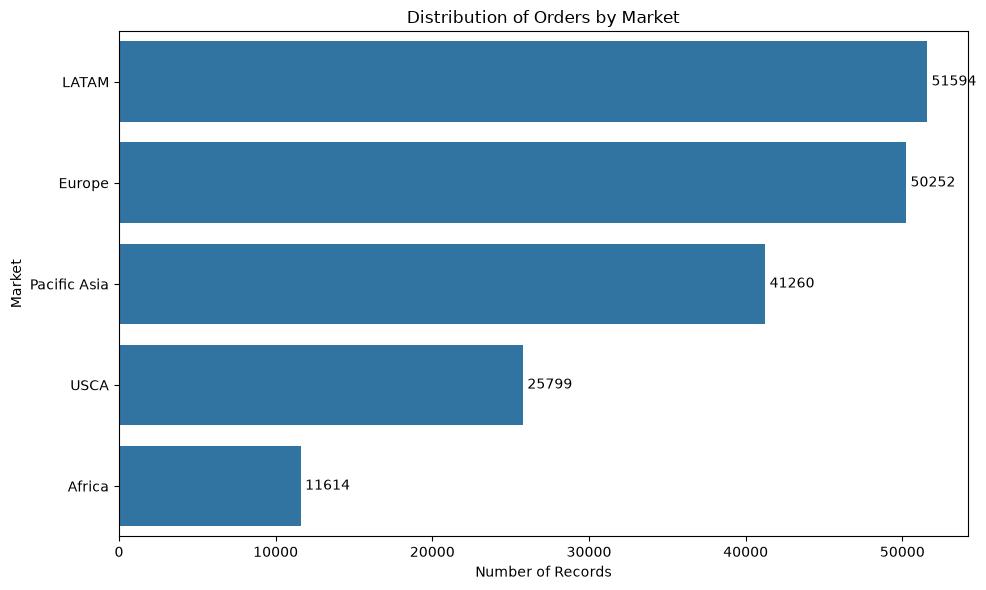

In [66]:


plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    y="Market",
    order=df["Market"].value_counts().index
)

plt.title("Distribution of Orders by Market")
plt.xlabel("Number of Records")
plt.ylabel("Market")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


In [67]:

# EDA Interpretation:
# The frequency table shows the number and percentage of records in each market.
# The bar chart helps identify the most and least represented markets.
# The late delivery risk chart compares the percentage of risky orders across markets.
# Markets above the overall risk line have higher-than-average late delivery risk.
# Market-level differences may reveal geographic or operational patterns.
# These associations do not prove that the market itself causes delivery delays.
# Market may be a useful categorical feature for predicting late delivery risk.


In [68]:

# EDA: Order Region frequency and percentage distribution

region_counts = df["Order Region"].value_counts(dropna=False)

region_summary = pd.DataFrame({
    "Count": region_counts,
    "Percentage": region_counts / len(df) * 100
})

display(region_summary.round(2))


,Count,Percentage
Order Region,,
Central America,28341,15.70
Western Europe,27109,15.02
South America,14935,8.27
Oceania,10148,5.62
Northern Europe,9792,5.42
Southeast Asia,9539,5.28
Southern Europe,9431,5.22
Caribbean,8318,4.61
West of USA,7993,4.43


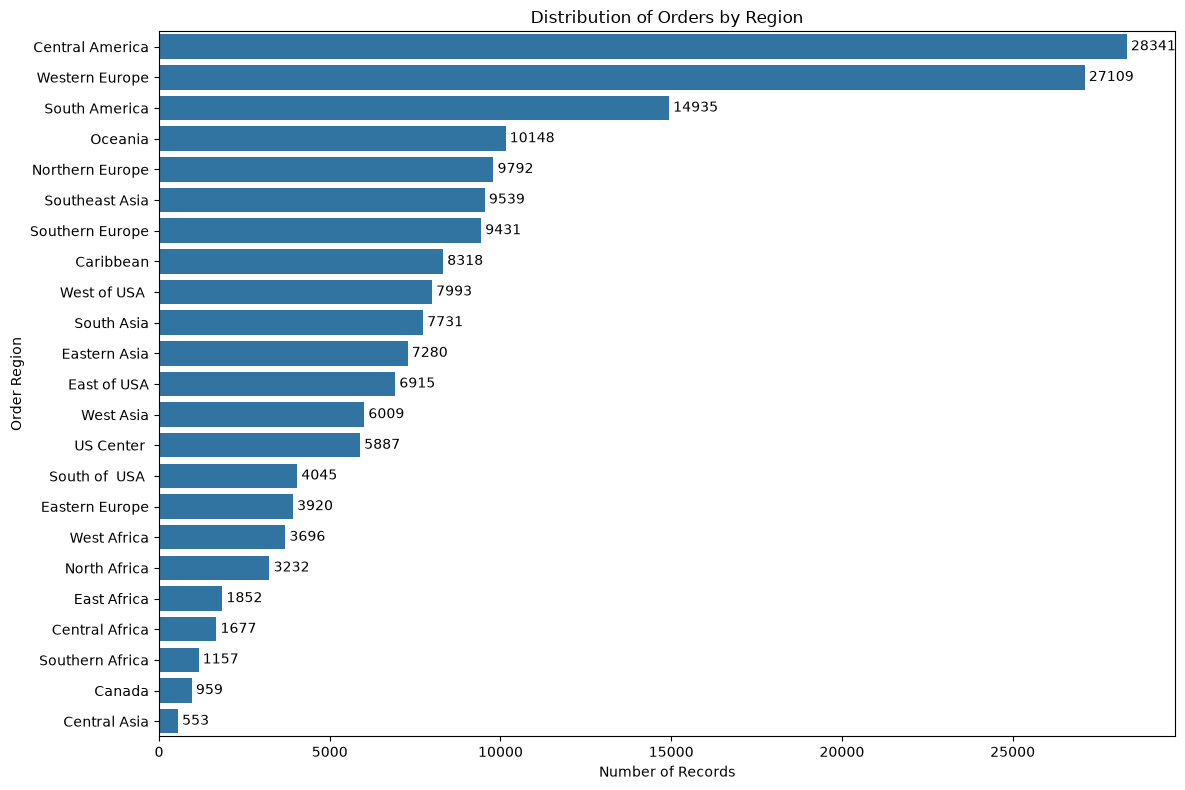

In [69]:

plt.figure(figsize=(12, 8))

ax = sns.countplot(
    data=df,
    y="Order Region",
    order=df["Order Region"].value_counts().index
)

plt.title("Distribution of Orders by Region")
plt.xlabel("Number of Records")
plt.ylabel("Order Region")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


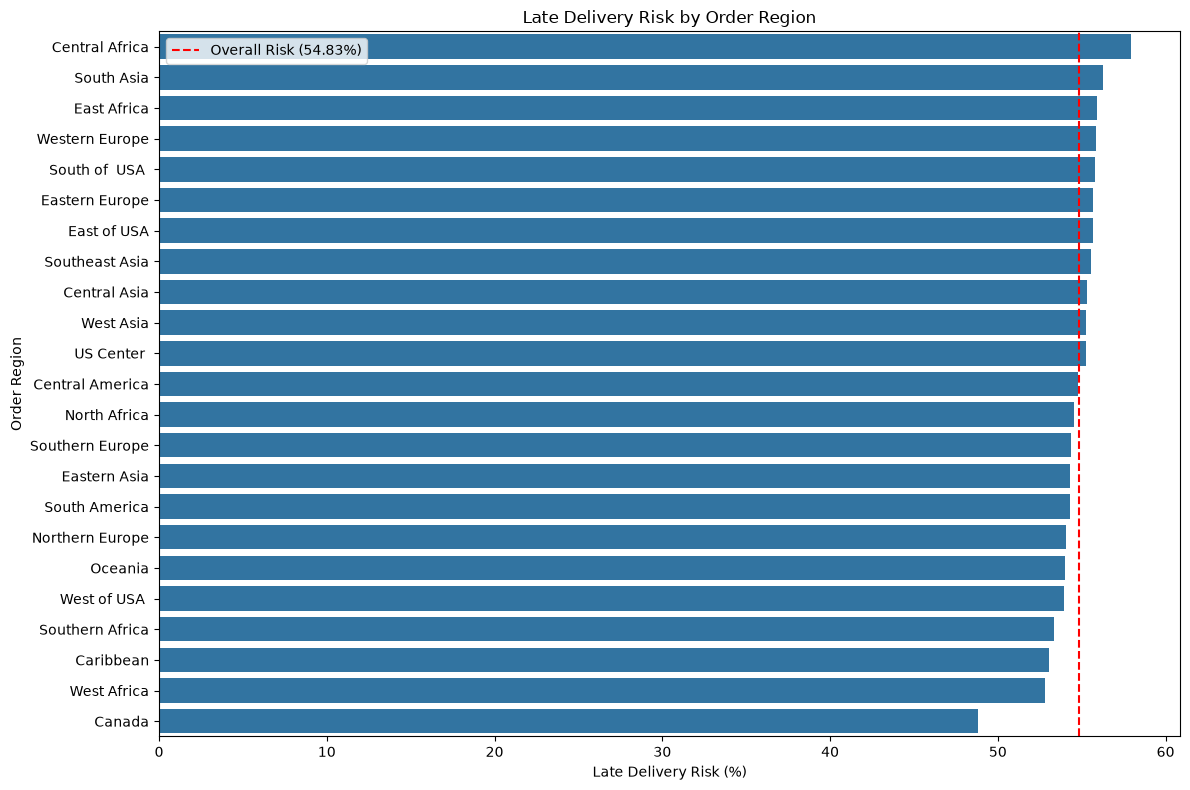

In [70]:

# Calculate late delivery risk percentage by region
region_risk = (
    df.groupby("Order Region", dropna=False)["Late_delivery_risk"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    x=region_risk.values,
    y=region_risk.index.astype(str)
)

# Add the overall late delivery risk as a reference line
overall_risk = df["Late_delivery_risk"].mean() * 100

plt.axvline(
    overall_risk,
    color="red",
    linestyle="--",
    label=f"Overall Risk ({overall_risk:.2f}%)"
)

plt.title("Late Delivery Risk by Order Region")
plt.xlabel("Late Delivery Risk (%)")
plt.ylabel("Order Region")
plt.legend()
plt.tight_layout()
plt.show()


In [71]:
# Count orders/items belonging to each department, including missing values.
department_counts = df["Department Name"].value_counts(dropna=False)

# Calculate the percentage represented by each department.
department_percentage = (department_counts / len(df)) * 100

# Combine counts and percentages into a summary table.
department_summary = pd.DataFrame({
    "Count": department_counts,
    "Percentage (%)": department_percentage
})

display(department_summary.round(2))

,Count,Percentage (%)
Department Name,,
Fan Shop,66861,37.04
Apparel,48998,27.14
Golf,33220,18.40
Footwear,14525,8.05
Outdoors,9686,5.37
Fitness,2479,1.37
Discs Shop,2026,1.12
Technology,1465,0.81
Pet Shop,492,0.27


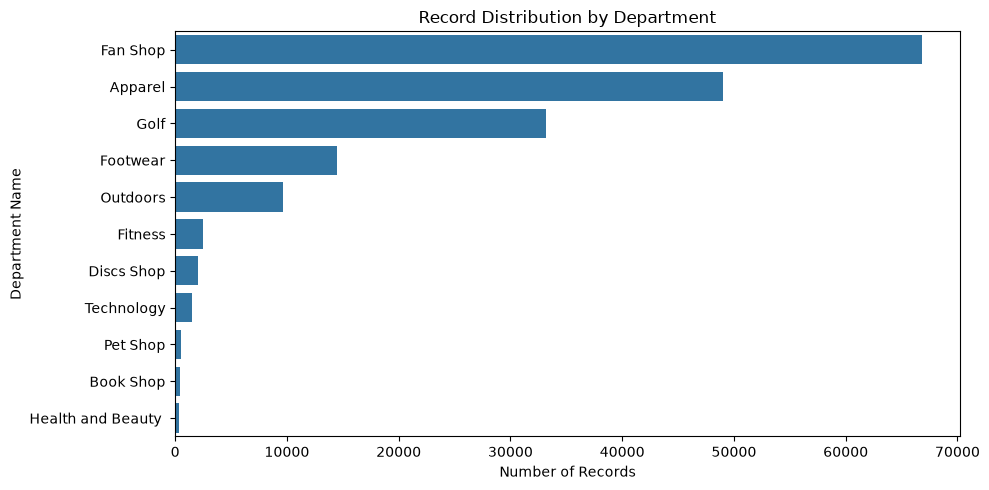

In [72]:
# Visualize the distribution of records across departments.
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y="Department Name",
    order=df["Department Name"].value_counts().index
)

plt.title("Record Distribution by Department")
plt.xlabel("Number of Records")
plt.ylabel("Department Name")
plt.tight_layout()
plt.show()

In [73]:
# INTERPRETATION:
# Fan Shop has the highest number of records (37.04%), followed by
# Apparel (27.14%) and Golf (18.40%).
# Together, these three departments account for approximately 82.58%
# of all records, indicating that the dataset is heavily concentrated
# in these departments.
# Health and Beauty has the lowest representation, accounting for only
# 0.20% of records.
# Therefore, the dataset has an imbalanced distribution across
# departments, with some departments contributing significantly more
# records than others.

In [74]:

# Count records in each product category.
category_counts = df["Category Name"].value_counts(dropna=False)

# Calculate the percentage of records in each category.
category_percentage = (category_counts / len(df)) * 100

# Create a summary table.
category_summary = pd.DataFrame({
    "Count": category_counts,
    "Percentage (%)": category_percentage
})

display(category_summary.round(2))


,Count,Percentage (%)
Category Name,,
Cleats,24551,13.60
Men's Footwear,22246,12.32
Women's Apparel,21035,11.65
Indoor/Outdoor Games,19298,10.69
Fishing,17325,9.60
Water Sports,15540,8.61
Camping & Hiking,13729,7.61
Cardio Equipment,12487,6.92
Shop By Sport,10984,6.08


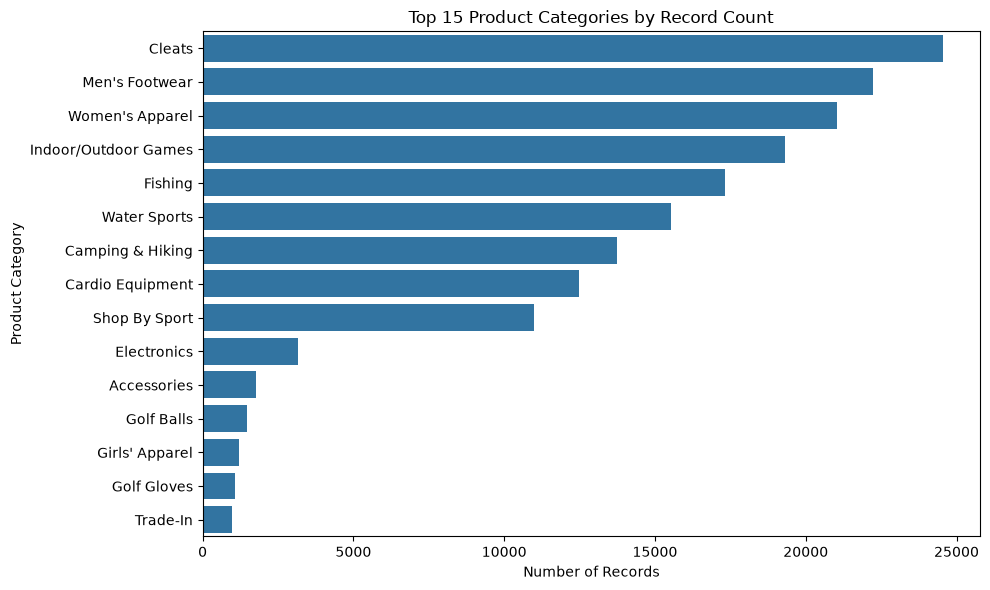

In [75]:

# Select the 15 categories with the highest record counts.
top_categories = df["Category Name"].value_counts().head(15)

# Plot the most frequent categories.
plt.figure(figsize=(10, 6))
sns.barplot(x=top_categories.values, y=top_categories.index)

plt.title("Top 15 Product Categories by Record Count")
plt.xlabel("Number of Records")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


In [76]:
# INTERPRETATION:
# Cleats has the highest number of records (24,551), followed by
# Men's Footwear (22,246) and Women's Apparel (21,035).
# These categories represent some of the most prominent product
# categories in the dataset.
# Golf Bags & Carts has the lowest number of records (61), followed
# by Basketball (67) and As Seen on TV! (68).
# The distribution shows that records are concentrated in a few
# popular categories, while several categories have very low
# representation.
# This imbalance should be considered when analyzing category-level
# patterns or building predictive models.

In [77]:
shipping_cols = [
    "Shipping Mode",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Late_delivery_risk",
    "Delivery Status"
]

df[shipping_cols].head()

,Shipping Mode,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk,Delivery Status
0,Standard Class,3,4,0,Advance shipping
1,Standard Class,5,4,1,Late delivery
2,Standard Class,4,4,0,Shipping on time
3,Standard Class,3,4,0,Advance shipping
4,Standard Class,2,4,0,Advance shipping


In [78]:
# Check whether actual shipping duration differs by delivery-risk class.
display(
    df.groupby("Late_delivery_risk")["Days for shipping (real)"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

# INTERPRETATION:
# Orders with Late_delivery_risk = 1 have a higher average actual
# shipping duration (4.09 days) than orders with Late_delivery_risk = 0
# (2.78 days).
# This indicates a strong relationship between actual shipping duration
# and late-delivery risk.
# Since actual shipping duration may only be known after shipping has
# occurred, it may cause data leakage when predicting risk at order
# placement. Therefore, this feature is excluded from model training.


,count,mean,median,min,max
Late_delivery_risk,,,,,
0,81542,2.78,3.0,0,6
1,98977,4.09,5.0,1,6


In [79]:
# Compare delivery status with the target.
display(pd.crosstab(
    df["Delivery Status"],
    df["Late_delivery_risk"],
    margins=True
))

# Calculate the target distribution within each delivery status.
display(pd.crosstab(
    df["Delivery Status"],
    df["Late_delivery_risk"],
    normalize="index"
).mul(100).round(2))


# INTERPRETATION:
# The crosstab shows a perfect relationship between Delivery Status
# and Late_delivery_risk.
# All records with "Late delivery" have a risk value of 1, while
# all records with other delivery statuses have a risk value of 0.
# Therefore, Delivery Status directly reveals the target variable
# and would cause severe target leakage if used as a predictor.
# This column is excluded from model training to ensure a valid
# prediction of late-delivery risk.


Late_delivery_risk,0,1,All
Delivery Status,,,
Advance shipping,41592,0,41592
Late delivery,0,98977,98977
Shipping canceled,7754,0,7754
Shipping on time,32196,0,32196
All,81542,98977,180519


Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,100.0,0.0
Late delivery,0.0,100.0
Shipping canceled,100.0,0.0
Shipping on time,100.0,0.0


In [80]:
# Inspect shipping dates and their availability.
print(df["shipping date (DateOrders)"].head(10))
print("Missing shipping dates:",
      df["shipping date (DateOrders)"].isna().sum())

# Compare the order date and shipping date if order_date was created earlier.
if "order_date" in df.columns:
    shipping_dates = pd.to_datetime(
        df["shipping date (DateOrders)"], errors="coerce"
    )

    print("Shipping dates before order dates:",
          (shipping_dates < df["order_date"]).sum())

    print("Same-day shipping:",
          (shipping_dates.dt.date == df["order_date"].dt.date).sum())
    # INTERPRETATION:
# The "shipping date (DateOrders)" column contains recorded shipping
# dates for all records, with zero missing values.
# These dates indicate when orders were shipped, assuming the column
# represents actual shipping dates rather than planned dates.
# If the model predicts late-delivery risk at order placement, the
# actual shipping date is not yet available and may cause data leakage.
# Therefore, this column is excluded from model training to prevent
# the use of information that would not be available at prediction time.

0     2/3/2018 22:56
1    1/18/2018 12:27
2    1/17/2018 12:06
3    1/16/2018 11:45
4    1/15/2018 11:24
5    1/19/2018 11:03
6    1/15/2018 10:42
7    1/15/2018 10:21
8    1/16/2018 10:00
9     1/15/2018 9:39
Name: shipping date (DateOrders), dtype: str
Missing shipping dates: 0


In [81]:
leakage_columns = [
    "Days for shipping (real)",
    "Delivery Status",
    "shipping date (DateOrders)",
    
]

print(leakage_columns)

['Days for shipping (real)', 'Delivery Status', 'shipping date (DateOrders)']


In [82]:
pii_columns = [
    "Customer Fname",
    "Customer Lname",
    "Customer Email",
    "Customer Password",
    "Customer Street"
]

df[pii_columns].head()
# INTERPRETATION:
# The selected columns contain personally identifiable information (PII),
# including customer names, email addresses, passwords, and street addresses.
# These fields are not necessary for predicting late-delivery risk and
# may introduce privacy and security concerns.
# Therefore, they should be excluded from model training to protect
# customer privacy and reduce the risk of exposing sensitive information.

,Customer Fname,Customer Lname,Customer Email,Customer Password,Customer Street
0,Cally,Holloway,XXXXXXXXX,XXXXXXXXX,5365 Noble Nectar Island
1,Irene,Luna,XXXXXXXXX,XXXXXXXXX,2679 Rustic Loop
2,Gillian,Maldonado,XXXXXXXXX,XXXXXXXXX,8510 Round Bear Gate
3,Tana,Tate,XXXXXXXXX,XXXXXXXXX,3200 Amber Bend
4,Orli,Hendricks,XXXXXXXXX,XXXXXXXXX,8671 Iron Anchor Corners


In [83]:
id_columns = ["Order Id", "Order Item Id", "Product Card Id", "Customer Id"]

for col in id_columns:
    print(col, "unique values:", df[col].nunique(), "rows:", len(df))

Order Id unique values: 65752 rows: 180519
Order Item Id unique values: 180519 rows: 180519
Product Card Id unique values: 118 rows: 180519
Customer Id unique values: 20652 rows: 180519


In [84]:
# INTERPRETATION:
# Order Id has 65,752 unique values across 180,519 records, indicating
# that multiple order items can belong to the same order.
# Order Item Id has 180,519 unique values, meaning each record has a
# unique order-item identifier.
# Product Card Id has 118 unique values, indicating that products
# are repeated across multiple records.
# Customer Id has 20,652 unique values, showing that customers can
# appear in multiple records.
# These columns are identifiers rather than ordinary numerical
# measurements. Therefore, they should not automatically be treated
# as continuous numerical features.
# Order Id and Order Item Id should be excluded as direct predictors
# unless there is a justified modeling purpose. Customer Id and
# Product Card Id require careful evaluation because they may encode
# useful recurring patterns but can also cause overfitting or leakage.

In [85]:
df[
    [
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "Late_delivery_risk"
    ]
].describe()

,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk
count,180519.000000,180519.000000,180519.000000
mean,3.497654,2.931847,0.548291
std,1.623722,1.374449,0.497664
min,0.000000,0.000000,0.000000
25%,2.000000,2.000000,0.000000
50%,3.000000,4.000000,1.000000
75%,5.000000,4.000000,1.000000
max,6.000000,4.000000,1.000000


In [86]:
# Calculate the difference between actual and scheduled shipping durations.
df["Shipping Delay Days"] = (
    df["Days for shipping (real)"]
    - df["Days for shipment (scheduled)"]
)

# Summarize the shipping-duration differences.
display(df["Shipping Delay Days"].describe().round(2))

# Count records where actual duration exceeded, matched, or beat the schedule.
print("Exceeded schedule:",
      (df["Shipping Delay Days"] > 0).sum())

print("Matched schedule:",
      (df["Shipping Delay Days"] == 0).sum())

print("Faster than schedule:",
      (df["Shipping Delay Days"] < 0).sum())
# INTERPRETATION:
# The average shipping delay is 0.57 days, meaning actual shipping
# duration exceeds scheduled duration by approximately 0.57 days on average.
# The median delay is 1 day, indicating that at least half of the records
# have a shipping duration difference of 1 day or less.
# A total of 103,400 records (57.28%) exceeded the scheduled duration.
# Meanwhile, 33,753 records (18.70%) matched the scheduled duration,
# and 43,366 records (24.02%) were shipped faster than scheduled.
# The delay ranges from -2 to 4 days, showing variation in shipping
# performance across records.
# This analysis highlights that actual shipping duration frequently
# exceeds the scheduled duration.
# However, these are shipping-duration differences and should not
# automatically be interpreted as confirmed late deliveries.

count    180519.00
mean          0.57
std           1.49
min          -2.00
25%           0.00
50%           1.00
75%           1.00
max           4.00
Name: Shipping Delay Days, dtype: float64

Exceeded schedule: 103400
Matched schedule: 33753
Faster than schedule: 43366


In [87]:
# Replace 'df' with the variable name of your DataFrame
df.to_csv('data/processed/data_cleaned.csv', index=False)

In [88]:
pd.set_option("display.max_columns", None)

In [89]:
df = pd.read_csv("/data/processed/orders_cleaned.csv")

In [90]:
print(df.shape)

(180519, 51)


In [91]:
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)

In [92]:
#Convert the date again because CSV loading turns it back into text:

In [93]:
# Calculate the late-delivery rate for each shipping mode.
shipping_risk = (
    df.groupby("Shipping Mode")["Late_delivery_risk"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Display the late-delivery rates.
display(shipping_risk.round(2).to_frame("Late Delivery Rate (%)"))

,Late Delivery Rate (%)
Shipping Mode,
First Class,95.32
Second Class,76.63
Same Day,45.74
Standard Class,38.07


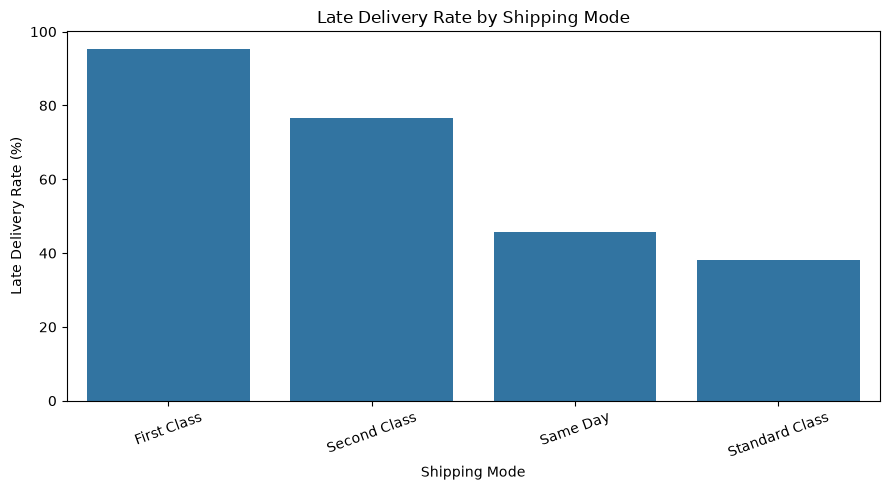

In [94]:
# Visualize late-delivery rates by shipping mode.
plt.figure(figsize=(9, 5))

sns.barplot(
    x=shipping_risk.index,
    y=shipping_risk.values
)

plt.title("Late Delivery Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [95]:
# Interpretation:
# The analysis shows a strong relationship between Shipping Mode andLate_delivery_risk.
#  First Class has the highest late-delivery rate
# (95.32%), followed by Second Class (76.63%). Same Day has a relatively
# balanced distribution (45.74% late), while Standard Class has the lowest
# late-delivery rate (38.07%). Therefore, Shipping Mode appears to be an
# important feature for predicting late deliveries and should be considered
# during feature engineering and model training.

In [96]:
scheduled_risk = pd.crosstab(
    df["Days for shipment (scheduled)"],
    df["Late_delivery_risk"],
    normalize="index"
) * 100

print(scheduled_risk)

Late_delivery_risk                     0          1
Days for shipment (scheduled)                      
0                              54.256958  45.743042
1                               4.677501  95.322499
2                              23.367219  76.632781
4                              61.928317  38.071683


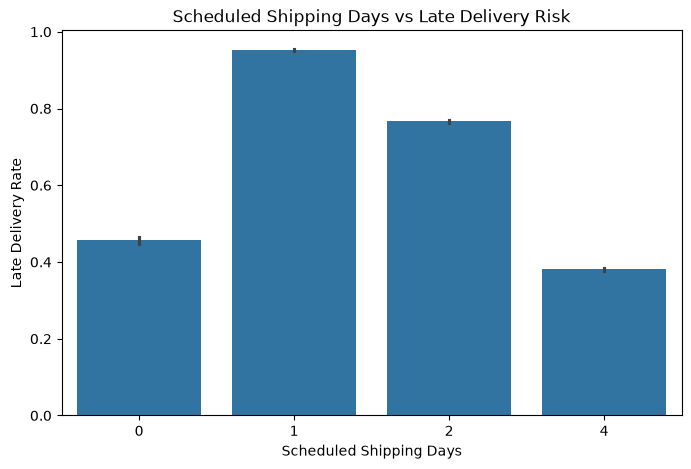

In [97]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="Days for shipment (scheduled)",
    y="Late_delivery_risk"
)

plt.title("Scheduled Shipping Days vs Late Delivery Risk")
plt.xlabel("Scheduled Shipping Days")
plt.ylabel("Late Delivery Rate")

plt.show()

In [98]:
# Interpretation:
# The analysis shows a strong relationship between Days for shipment
# (scheduled) and Late_delivery_risk. Shipments scheduled for 1 day have
# the highest late-delivery rate (95.32%), followed by shipments scheduled
# for 2 days (76.63%). Shipments scheduled for 0 days have a 45.74% late
# rate, while shipments scheduled for 4 days have the lowest late-delivery
# rate (38.07%). Therefore, Days for shipment (scheduled) appears to be an
# important predictive feature and should be considered during feature
# engineering and model training.

In [99]:
segment_risk = pd.crosstab(
    df["Customer Segment"],
    df["Late_delivery_risk"],
    normalize="index"
) * 100

print(segment_risk)

Late_delivery_risk          0          1
Customer Segment                        
Consumer            45.191650  54.808350
Corporate           45.277337  54.722663
Home Office         44.929560  55.070440


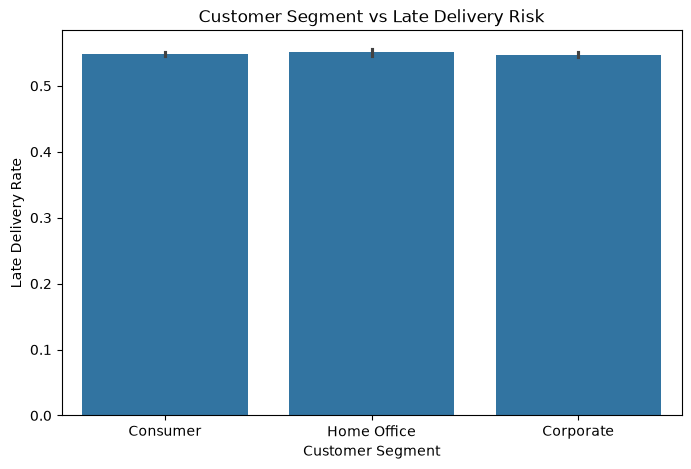

In [100]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="Customer Segment",
    y="Late_delivery_risk"
)

plt.title("Customer Segment vs Late Delivery Risk")
plt.xlabel("Customer Segment")
plt.ylabel("Late Delivery Rate")

plt.show()

In [101]:
# Interpretation:
# The late-delivery risk is very similar across all customer segments.
# Consumer, Corporate, and Home Office customers have late-delivery rates
# of 54.81%, 54.72%, and 55.07%, respectively. The small differences suggest
# that Customer Segment has a weak relationship with Late_delivery_risk
# based on this EDA. Therefore, this feature should not be considered a
# strong predictor on its own, but it can be retained initially and its
# actual contribution can be evaluated during model training.

In [102]:

market_risk = pd.crosstab(
    df["Market"],
    df["Late_delivery_risk"],
    normalize="index"
) * 100

print(market_risk)

Late_delivery_risk          0          1
Market                                  
Africa              45.410711  54.589289
Europe              44.792247  55.207753
LATAM               45.644842  54.355158
Pacific Asia        44.953951  55.046049
USCA                45.199426  54.800574


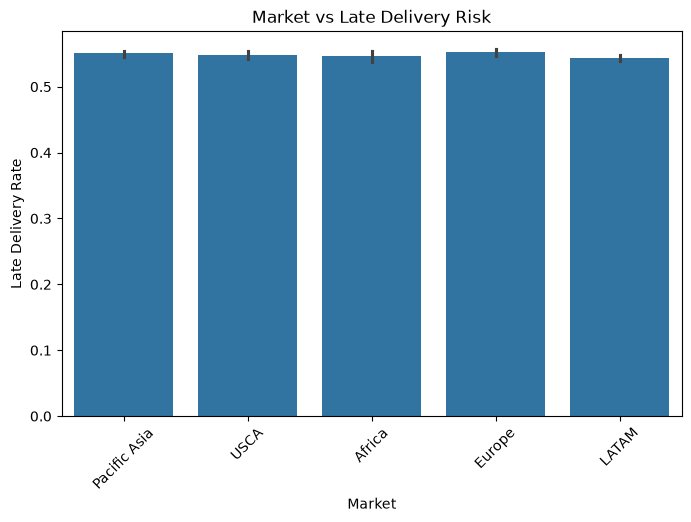

In [103]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="Market",
    y="Late_delivery_risk"
)

plt.title("Market vs Late Delivery Risk")
plt.xlabel("Market")
plt.ylabel("Late Delivery Rate")

plt.xticks(rotation=45)

plt.show()

In [104]:
# Interpretation:
# The late-delivery risk is very similar across all markets. The late-
# delivery rate ranges from 54.36% in LATAM to 55.21% in Europe, showing
# only a small difference between markets. Therefore, Market appears to
# have a weak relationship with Late_delivery_risk based on this EDA.
# However, the feature can be retained initially and its contribution
# can be evaluated during model training.

In [105]:
region_risk = (
    df.groupby("Order Region")["Late_delivery_risk"]
      .mean()
      .sort_values(ascending=False)
)

print(region_risk)

Order Region
Central Africa     0.579606
South Asia         0.562670
East Africa        0.559395
Western Europe     0.558486
South of  USA      0.557726
Eastern Europe     0.556633
East of USA        0.556616
Southeast Asia     0.555299
Central Asia       0.553345
West Asia          0.552837
US Center          0.552404
Central America    0.547546
North Africa       0.545173
Southern Europe    0.543845
Eastern Asia       0.543269
South America      0.543087
Northern Europe    0.540441
Oceania            0.540205
West of USA        0.539597
Southern Africa    0.533276
Caribbean          0.530777
West Africa        0.528409
Canada             0.488008
Name: Late_delivery_risk, dtype: float64


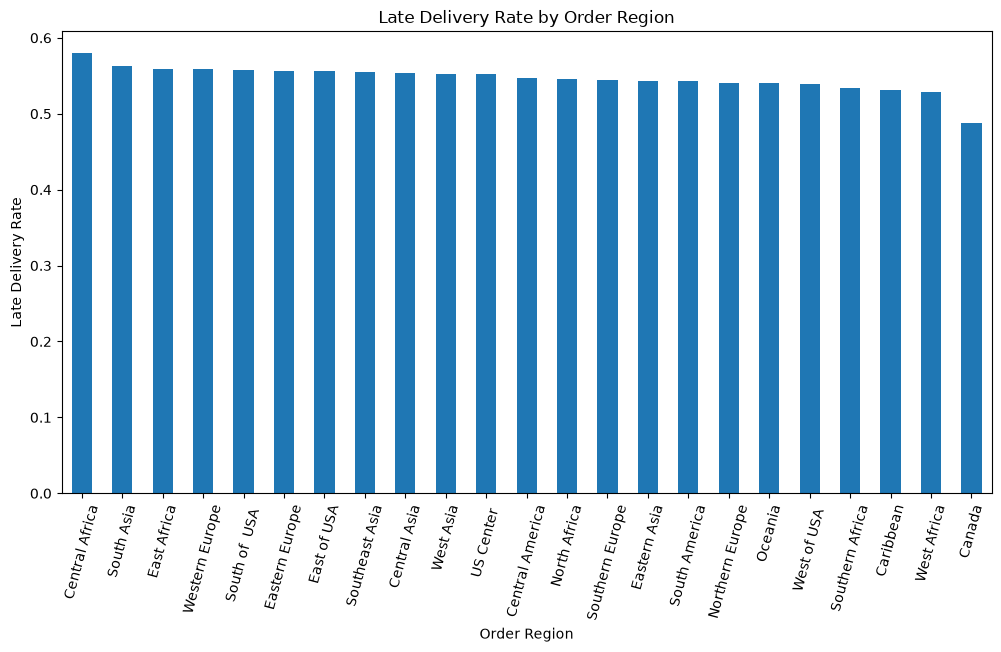

In [106]:
plt.figure(figsize=(12,6))

region_risk.plot(kind="bar")

plt.title("Late Delivery Rate by Order Region")
plt.xlabel("Order Region")
plt.ylabel("Late Delivery Rate")

plt.xticks(rotation=75)

plt.show()

In [107]:
# Interpretation:
# The late-delivery rate varies across Order Regions. Central Africa has
# the highest observed late-delivery rate (57.96%), while Canada has the
# lowest (48.80%), giving a difference of approximately 9.16 percentage
# points. This indicates that Order Region may have a meaningful
# relationship with Late_delivery_risk and should be retained as a
# candidate predictive feature for model training.
#
# Note: These are descriptive regional rates and do not by themselves
# establish that region causes late deliveries. Other factors such as
# shipping mode, scheduled delivery time, and operational conditions
# may also contribute to the observed differences.

In [108]:
category_risk = (
    df.groupby("Category Name")["Late_delivery_risk"]
      .mean()
      .sort_values(ascending=False)
)

print(category_risk)

Category Name
Golf Bags & Carts       0.688525
Lacrosse                0.600583
Pet Supplies            0.589431
Cameras                 0.581081
Strength Training       0.576577
As Seen on  TV!         0.573529
Music                   0.571429
Accessories             0.569663
Fitness Accessories     0.569579
Books                   0.565432
Women's Clothing        0.564615
Boxing & MMA            0.562648
Golf Gloves             0.562617
Hunting & Shooting      0.561364
Electronics             0.560837
Crafts                  0.559917
Health and Beauty       0.558011
Tennis & Racquet        0.557927
Garden                  0.557851
Trade-In                0.556468
Golf Shoes              0.555344
Sporting Goods          0.554622
Girls' Apparel          0.552873
Basketball              0.552239
Baseball & Softball     0.552215
Consumer Electronics    0.552204
Shop By Sport           0.551529
Toys                    0.550095
Cleats                  0.549713
Fishing                 0.549

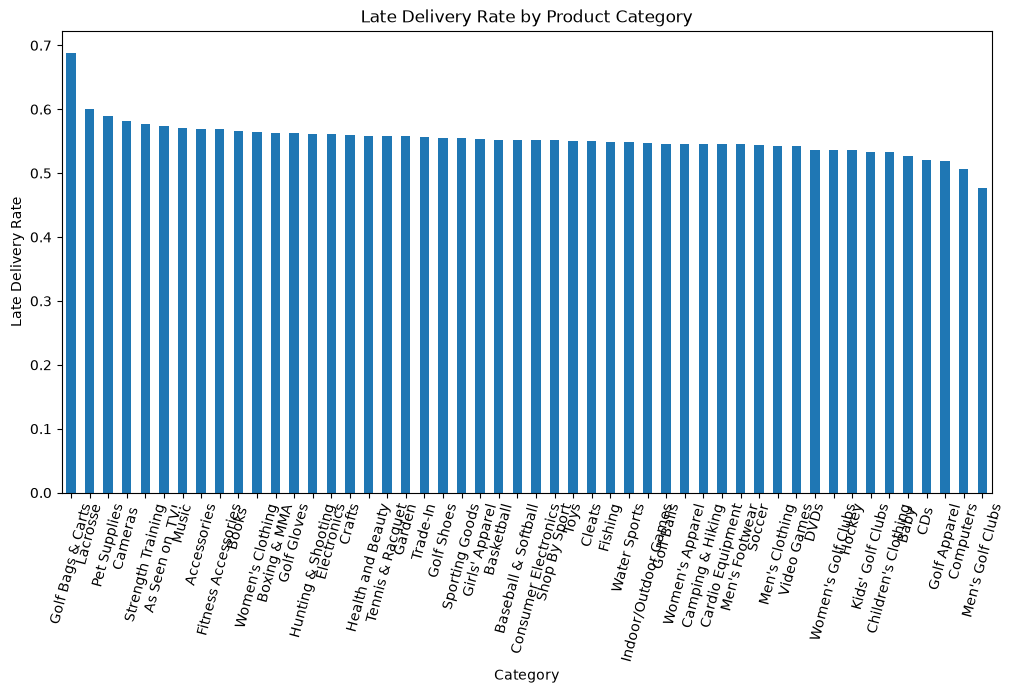

In [109]:
plt.figure(figsize=(12,6))

category_risk.plot(kind="bar")

plt.title("Late Delivery Rate by Product Category")
plt.xlabel("Category")
plt.ylabel("Late Delivery Rate")

plt.xticks(rotation=75)

plt.show()

In [110]:
# Interpretation:
# The late-delivery rate varies considerably across product categories.
# Golf Bags & Carts has the highest observed late-delivery rate (68.85%),
# while Men's Golf Clubs has the lowest rate (47.70%), resulting in a
# difference of approximately 21.15 percentage points.
#
# This variation suggests that Category Name may contain useful information
# for predicting Late_delivery_risk. Therefore, Category Name should be
# retained as a candidate predictive feature and evaluated during model
# training.
#
# Note: These results show an association between product category and
# late-delivery risk and do not establish that product category directly
# causes delivery delays. Other operational factors may contribute to
# these differences.

In [111]:
numeric_features = [
    "Days for shipment (scheduled)",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Quantity",
    "Sales",
    "Order Item Total",
    "Sales per customer"
]

df[numeric_features + ["Late_delivery_risk"]].groupby(
    "Late_delivery_risk"
).mean().T

Late_delivery_risk,0,1
Days for shipment (scheduled),3.491146,2.471069
Order Item Discount,20.682753,20.649902
Order Item Discount Rate,0.101637,0.101694
Order Item Product Price,141.567424,140.956665
Order Item Quantity,2.127860,2.127454
Sales,204.291528,203.344163
Order Item Total,183.609025,182.694518
Sales per customer,183.609025,182.694518


In [112]:
# Interpretation:
# The group-wise mean comparison shows that Days for shipment (scheduled)
# has the largest difference between the two target classes. Non-late
# deliveries have an average scheduled shipment duration of 3.49 days,
# compared with 2.47 days for late deliveries.
#
# The remaining numeric features, including discount, discount rate,
# product price, quantity, sales, and order item total, have very similar
# average values between the two classes. Therefore, they show weak
# separation between late and non-late deliveries based on their means.
#
# Days for shipment (scheduled) should be retained as an important
# candidate feature. The other numeric features should not be removed
# solely from this analysis, because their predictive value may appear
# through non-linear relationships or interactions with other features.

In [113]:
df["order_year"] = df["order date (DateOrders)"].dt.year

df["order_month"] = df["order date (DateOrders)"].dt.month

df["order_day"] = df["order date (DateOrders)"].dt.day

df["order_dayofweek"] = df["order date (DateOrders)"].dt.dayofweek

df["order_hour"] = df["order date (DateOrders)"].dt.hour

df["order_is_weekend"] = (#check Time Relationship
    df["order_dayofweek"] >= 5
).astype(int)

In [114]:
#check Time Relationship

In [115]:
monthly_risk = (
    df.groupby("order_month")["Late_delivery_risk"]
      .mean()
)

print(monthly_risk)
# Analyze how record volume changes across months.


order_month
1     0.546582
2     0.545530
3     0.552547
4     0.542792
5     0.547384
6     0.548253
7     0.540573
8     0.557944
9     0.552973
10    0.545967
11    0.545520
12    0.553353
Name: Late_delivery_risk, dtype: float64


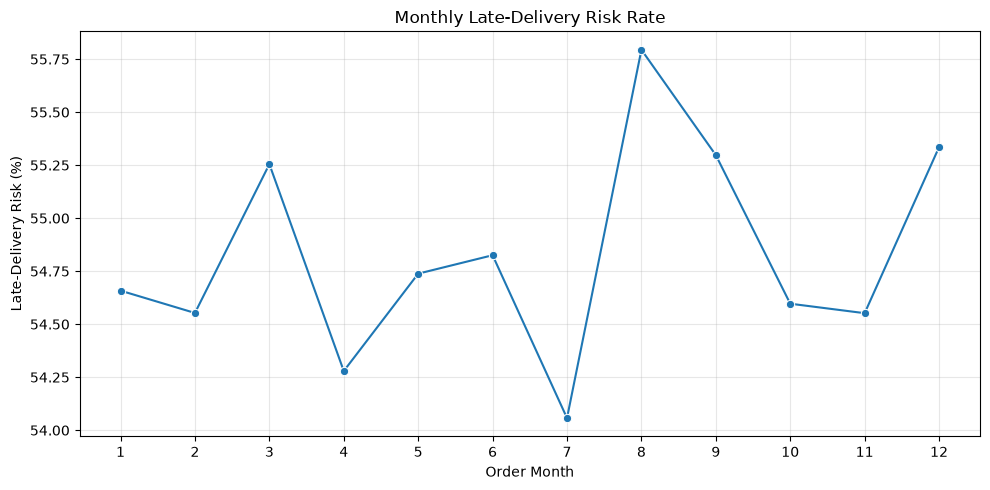

In [116]:
# Calculate monthly late-delivery rates.
monthly_risk = (
    df.groupby("order_month")["Late_delivery_risk"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_risk.index, y=monthly_risk.values, marker="o")

plt.title("Monthly Late-Delivery Risk Rate")
plt.xlabel("Order Month")
plt.ylabel("Late-Delivery Risk (%)")
plt.xticks(sorted(monthly_risk.index))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

order_dayofweek
0    0.550531
1    0.543010
2    0.547583
3    0.550054
4    0.551707
5    0.543956
6    0.551145
Name: Late_delivery_risk, dtype: float64


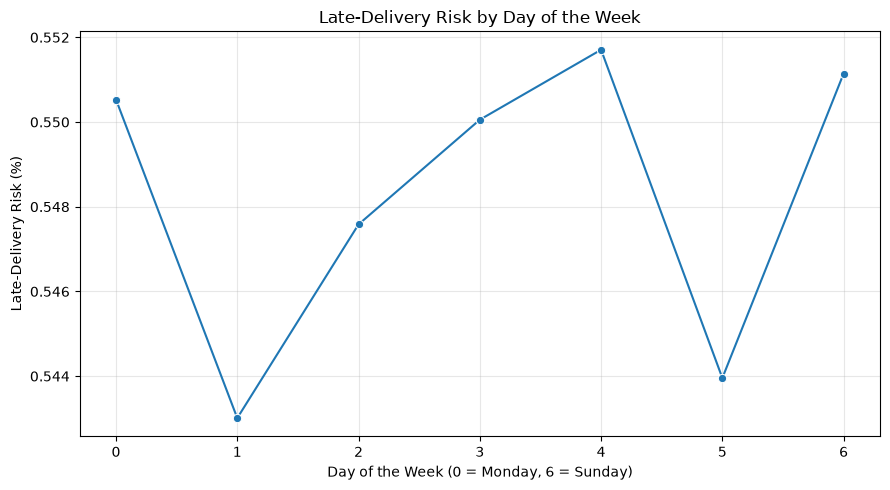

In [117]:
weekday_risk = (
    df.groupby("order_dayofweek")["Late_delivery_risk"]
      .mean()
)

print(weekday_risk)
# Visualize how late-delivery risk varies by weekday.
plt.figure(figsize=(9, 5))

sns.lineplot(
    x=weekday_risk.index,
    y=weekday_risk.values,
    marker="o"
)

plt.title("Late-Delivery Risk by Day of the Week")
plt.xlabel("Day of the Week (0 = Monday, 6 = Sunday)")
plt.ylabel("Late-Delivery Risk (%)")
plt.xticks(range(7))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [118]:
hour_risk = (
    df.groupby("order_hour")["Late_delivery_risk"]
      .mean()
)

print(hour_risk)

order_hour
0     0.514756
1     0.533404
2     0.530367
3     0.516532
4     0.514704
5     0.527335
6     0.509491
7     0.528598
8     0.508675
9     0.521919
10    0.525529
11    0.510604
12    0.594977
13    0.577725
14    0.576628
15    0.579764
16    0.558726
17    0.578635
18    0.575922
19    0.551364
20    0.591231
21    0.567180
22    0.584794
23    0.580615
Name: Late_delivery_risk, dtype: float64


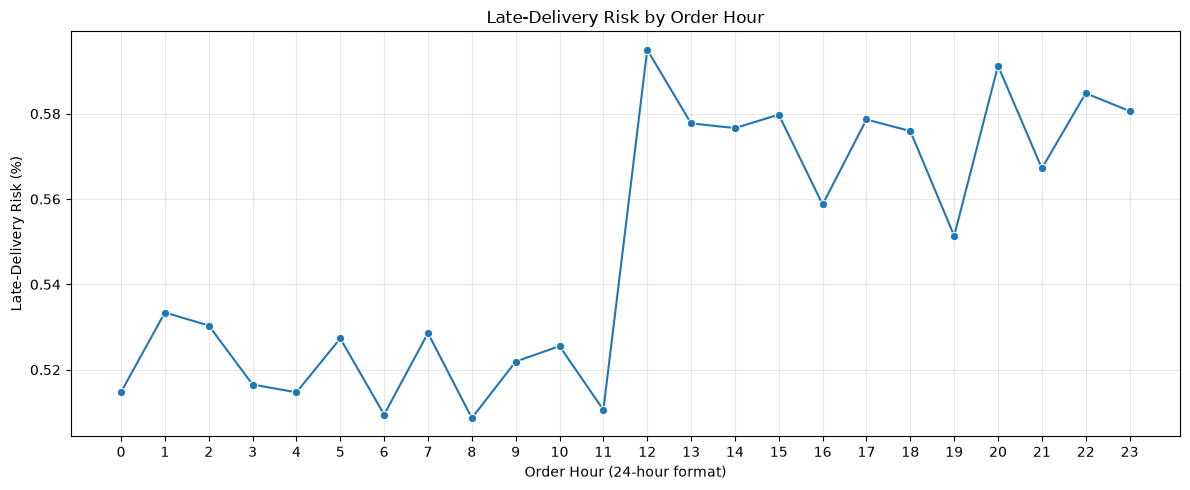

In [119]:
# Visualize how late-delivery risk varies by order hour.
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hour_risk.index,
    y=hour_risk.values,
    marker="o"
)

plt.title("Late-Delivery Risk by Order Hour")
plt.xlabel("Order Hour (24-hour format)")
plt.ylabel("Late-Delivery Risk (%)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [120]:
# Identify records where customer country matches order country.
same_country_df = df.loc[
    df["Customer Country"] == df["Order Country"],
    ["Customer Country", "Order Country"]
]

display(same_country_df.head(10))

,Customer Country,Order Country


In [121]:
# List unique countries where customer country matches order country.
matching_countries = (
    df.loc[
        df["Customer Country"] == df["Order Country"],
        "Customer Country"
    ]
    .dropna()
    .unique()
)

print("Countries with matching customer and order countries:")
print(sorted(matching_countries))

Countries with matching customer and order countries:
[]


In [122]:
# Count records where customer and order countries match
(df["Customer Country"] == df["Order Country"]).value_counts()

False    180519
Name: count, dtype: int64

In [123]:
# INTERPRETATION:
# No matching countries were found between "Customer Country" and
# "Order Country" in the dataset.
# This means the equality comparison did not identify any records
# where the two country values were exactly the same.
# However, this does not necessarily mean that all customers order
# from different countries. The columns may use different naming
# conventions, contain inconsistent values, or represent different
# geographical information.
# Therefore, inspect the unique values in both columns before
# concluding that no customers and orders share the same country.

In [124]:
missing = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
)

print(missing[missing > 0])

Order Zipcode       155679
Customer Lname           8
Customer Zipcode         3
dtype: int64


In [125]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 57 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Type                           180519 non-null  str           
 1   Days for shipping (real)       180519 non-null  int64         
 2   Days for shipment (scheduled)  180519 non-null  int64         
 3   Benefit per order              180519 non-null  float64       
 4   Sales per customer             180519 non-null  float64       
 5   Delivery Status                180519 non-null  str           
 6   Late_delivery_risk             180519 non-null  int64         
 7   Category Id                    180519 non-null  int64         
 8   Category Name                  180519 non-null  str           
 9   Customer City                  180519 non-null  str           
 10  Customer Country               180519 non-null  str           
 11  Customer Em

In [126]:
order_size = (
    df.groupby("Order Id")
      .size()
)

print(order_size.describe())

count    65752.000000
mean         2.745453
std          1.478363
min          1.000000
25%          1.000000
50%          3.000000
75%          4.000000
max          5.000000
dtype: float64


In [127]:
# Count the number of unique order items associated with each order.
order_item_counts = (
    df.groupby("Order Id")["Order Item Id"]
      .nunique()
)

# Count orders containing multiple items.
print(
    "Orders with multiple order items:",
    (order_item_counts > 1).sum()
)

# Calculate the percentage of orders containing multiple items.
print(
    "Percentage:",
    (order_item_counts > 1).mean() * 100
)

Orders with multiple order items: 45902
Percentage: 69.81080423409173


In [128]:
# INTERPRETATION:
# A total of 45,902 orders contain more than one item, representing
# approximately 69.81% of all unique orders.
# The remaining 30.19% of orders contain only one item.
# This indicates that multi-item orders are common in the dataset.
# Therefore, multiple records may belong to the same order, which
# should be considered when analyzing order-level patterns and
# splitting data into training and testing sets.


In [129]:
item_counts = df["Order Item Id"].value_counts()

print(item_counts.describe())

count    180519.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0
Name: count, dtype: float64


In [130]:

print(
    "Order Item IDs appearing more than once:",
    (item_counts > 1).sum()
)

Order Item IDs appearing more than once: 0


In [131]:
order_target_unique = (
    df.groupby("Order Id")["Late_delivery_risk"]
      .nunique()
)

print(order_target_unique.value_counts())

Late_delivery_risk
1    65752
Name: count, dtype: int64


In [132]:

# INTERPRETATION:
# All 65,752 unique orders have a consistent Late_delivery_risk value
# across their associated order items.
# This indicates that all items belonging to the same order share
# the same target class.
# Therefore, Order Id can be used as a grouping variable when splitting
# the dataset into training, validation, and test sets to prevent
# items from the same order appearing in different sets.

In [133]:
inconsistent_orders = order_target_unique[
    order_target_unique > 1
]

print(
    "Orders with different target values:",
    len(inconsistent_orders)
)

Orders with different target values: 0


In [134]:
# Interpretation:
# Late_delivery_risk is consistent within each Order Id. Each order has
# only one target value, and no order contains different target labels.
#
# This matters because the dataset contains multiple item-level rows for
# the same order. If we randomly split individual rows, items from the
# same order could appear in both the training and testing datasets.
# This could cause data leakage and lead to overly optimistic model
# performance.
#
# Therefore, the train-test split should be performed at the Order Id level,
# keeping all items belonging to the same order in either the training set
# or the testing set, but never in both.

In [135]:

print(
    "Order Item IDs appearing more than once:",
    (item_counts > 1).sum()
)

Order Item IDs appearing more than once: 0


In [136]:
#check whether each item ID has a single target value

In [137]:
item_target_unique = (
    df.groupby("Order Item Id")["Late_delivery_risk"]
      .nunique()
)

print(item_target_unique.value_counts())

Late_delivery_risk
1    180519
Name: count, dtype: int64


In [138]:
df["Order Id"].corr(df["Late_delivery_risk"])

np.float64(-0.0012926280330895752)

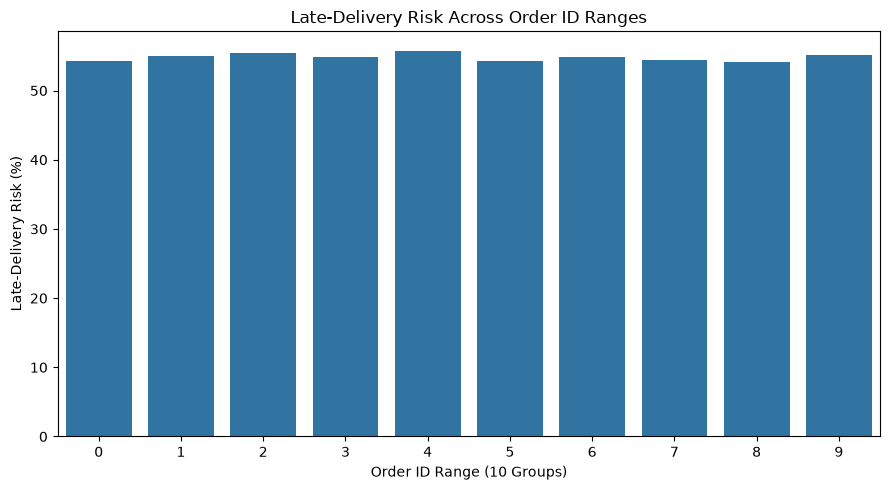

In [139]:
# Divide Order Id values into 10 ranges.
df["Order_ID_Range"] = pd.qcut(
    df["Order Id"].rank(method="first"),
    q=10,
    labels=False
)

# Calculate average late-delivery risk for each range.
order_range_risk = (
    df.groupby("Order_ID_Range")["Late_delivery_risk"]
      .mean()
      .mul(100)
)

# Visualize risk across Order Id ranges.
plt.figure(figsize=(9, 5))
sns.barplot(x=order_range_risk.index, y=order_range_risk.values)

plt.title("Late-Delivery Risk Across Order ID Ranges")
plt.xlabel("Order ID Range (10 Groups)")
plt.ylabel("Late-Delivery Risk (%)")
plt.tight_layout()
plt.show()

In [140]:
# Interpretation:
# Late_delivery_risk is consistent within each Order Id. Each order has
# only one target value, and no order contains different target labels.
#
# This matters because the dataset contains multiple item-level rows for
# the same order. If we randomly split individual rows, items from the
# same order could appear in both the training and testing datasets.
# This could cause data leakage and lead to overly optimistic model
# performance.
#
# Therefore, the train-test split should be performed at the Order Id level,
# keeping all items belonging to the same order in either the training set
# or the testing set, but never in both.

In [141]:
print(
    df[
        ["Order Id", "order date (DateOrders)"]
    ].sort_values("Order Id").head(20)
)

        Order Id order date (DateOrders)
33833          1     2015-01-01 00:00:00
87884          2     2015-01-01 00:21:00
109322         2     2015-01-01 00:21:00
77011          2     2015-01-01 00:21:00
114915         4     2015-01-01 01:03:00
96131          4     2015-01-01 01:03:00
95938          4     2015-01-01 01:03:00
63764          4     2015-01-01 01:03:00
114914         5     2015-01-01 01:24:00
20695          5     2015-01-01 01:24:00
58046          5     2015-01-01 01:24:00
20305          5     2015-01-01 01:24:00
20680          5     2015-01-01 01:24:00
64753          7     2015-01-01 02:06:00
81543          7     2015-01-01 02:06:00
77010          7     2015-01-01 02:06:00
140014         8     2015-01-01 02:27:00
139424         8     2015-01-01 02:27:00
123982         8     2015-01-01 02:27:00
114913         8     2015-01-01 02:27:00


In [142]:
print(
    df[
        ["Order Id", "order date (DateOrders)"]
    ].sort_values("Order Id").tail(20)
)

        Order Id order date (DateOrders)
149103     77185     2018-01-31 16:59:00
63549      77186     2018-01-31 17:20:00
10878      77187     2018-01-31 17:41:00
62652      77188     2018-01-31 18:02:00
142110     77189     2018-01-31 18:23:00
93690      77190     2018-01-31 18:44:00
134321     77191     2018-01-31 19:05:00
160462     77192     2018-01-31 19:26:00
86254      77193     2018-01-31 19:47:00
125524     77194     2018-01-31 20:08:00
168609     77195     2018-01-31 20:29:00
97707      77196     2018-01-31 20:50:00
142093     77197     2018-01-31 21:11:00
62641      77198     2018-01-31 21:32:00
18819      77199     2018-01-31 21:53:00
160537     77200     2018-01-31 22:14:00
93905      77201     2018-01-31 22:35:00
0          77202     2018-01-31 22:56:00
52147      77203     2018-01-31 23:17:00
17863      77204     2018-01-31 23:38:00


In [143]:
df.shape

(180519, 58)

In [144]:
df["order_id_group"] = pd.qcut(
    df["Order Id"],
    q=10,
    duplicates="drop"
)

order_id_risk = (
    df.groupby(
        "order_id_group",
        observed=True
    )["Late_delivery_risk"]
    .mean()
)

print(order_id_risk)

order_id_group
(0.999, 7214.0]       0.543340
(7214.0, 14436.0]     0.549856
(14436.0, 21659.0]    0.554540
(21659.0, 28857.0]    0.549055
(28857.0, 36140.0]    0.557753
(36140.0, 43356.0]    0.542705
(43356.0, 50565.0]    0.548753
(50565.0, 57725.0]    0.543818
(57725.0, 64994.0]    0.541048
(64994.0, 77204.0]    0.552047
Name: Late_delivery_risk, dtype: float64


In [145]:
# INTERPRETATION:
# The Order Id values are divided into 10 groups, and the late delivery risk
# proportion is calculated for each group. The risk percentages range from
# approximately 54.10% to 55.78%, indicating relatively little variation
# across the groups. However, Order Id is an identifier, not a meaningful
# numerical measurement. Therefore, these results do not establish a useful
# predictive relationship, and Order Id should generally be excluded from
# model features. It can instead be retained for grouping records during
# train-test splitting to prevent items from the same order appearing in
# both sets.

In [146]:
df.shape

(180519, 59)

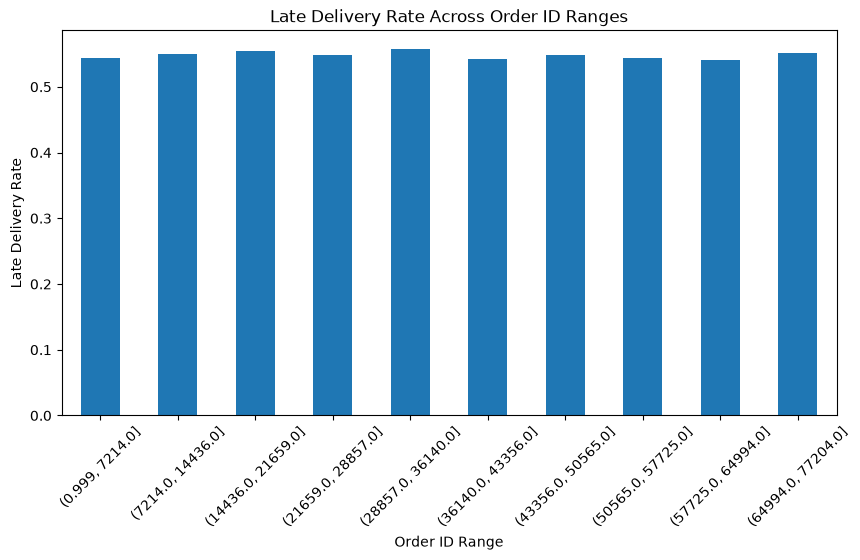

In [147]:
plt.figure(figsize=(10, 5))

order_id_risk.plot(kind="bar")

plt.title("Late Delivery Rate Across Order ID Ranges")
plt.xlabel("Order ID Range")
plt.ylabel("Late Delivery Rate")

plt.xticks(rotation=45)

plt.show()

In [148]:
#we still don't use Order ID as a model feature.if the risk changes substantially across ID ranges,
#we investigate whether that is actually a time effect than an ID effect.

In [149]:
df["item_id_group"] = pd.qcut(
    df["Order Item Id"],
    q=10,
    duplicates="drop"
)

item_id_risk = (
    df.groupby(
        "item_id_group",
        observed=True
    )["Late_delivery_risk"]
    .mean()
)

print(item_id_risk)

item_id_group
(0.999, 18052.8]        0.543264
(18052.8, 36104.6]      0.549856
(36104.6, 54156.4]      0.554565
(54156.4, 72208.2]      0.549136
(72208.2, 90260.0]      0.557722
(90260.0, 108311.8]     0.542795
(108311.8, 126363.6]    0.548637
(126363.6, 144415.4]    0.543818
(144415.4, 162467.2]    0.541048
(162467.2, 180519.0]    0.552072
Name: Late_delivery_risk, dtype: float64


In [150]:
# INTERPRETATION:
# The Order Item Id values are divided into 10 approximately equal-sized groups,
# and the late delivery risk proportion is calculated for each group.
# The risk proportions range from approximately 54.10% to 55.77%, showing
# relatively little variation across the groups.
# However, Order Item Id is an identifier rather than a meaningful predictive
# feature, so this analysis does not establish a useful relationship with
# late delivery risk. It is generally better to exclude this ID from model
# training unless a specific, justified use is identified.

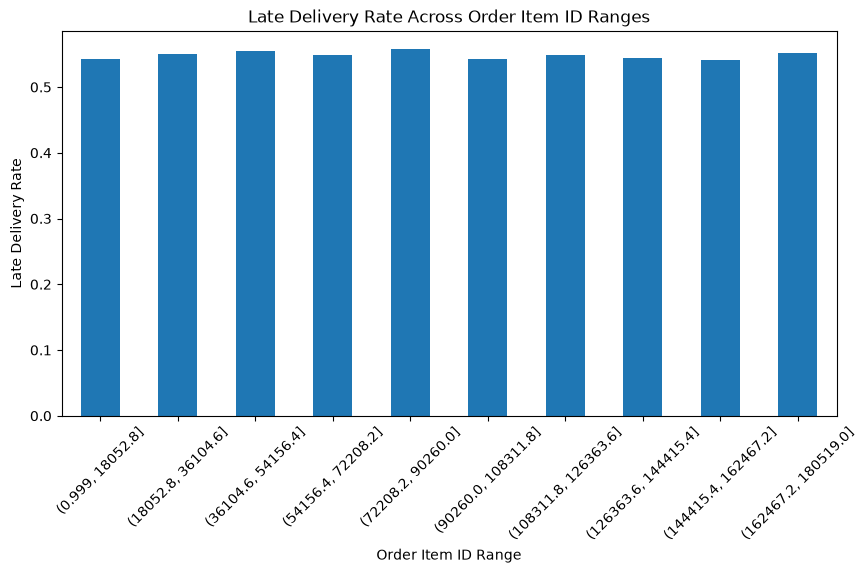

In [151]:
plt.figure(figsize=(10, 5))

item_id_risk.plot(kind="bar")

plt.title("Late Delivery Rate Across Order Item ID Ranges")
plt.xlabel("Order Item ID Range")
plt.ylabel("Late Delivery Rate")

plt.xticks(rotation=45)

plt.show()

In [152]:
#not an argument for using the ID as a feature.

## Feature Availability and Initial Feature Assessment

The dataset contains information about customers, orders, products,
order items, shipping, geography, and time.

At this stage, each variable is examined to determine:

1. What information does the variable represent?
2. Is it available at the order-time prediction point?
3. Can it potentially help predict `Late_delivery_risk`?
4. Should it be excluded because it is PII, an identifier, or leakage?

The prediction point is the time when the order is placed.
Therefore, information generated after the order is placed must not be
used as a predictor.

### Customer Information

The dataset contains several customer-related variables:

- Customer City
- Customer Country
- Customer Segment
- Customer State
- Customer Zipcode
- Latitude
- Longitude
- Customer Id
- Customer Email
- Customer Fname
- Customer Lname
- Customer Password
- Customer Street

Customer location and segment may contain useful information about
delivery risk because delivery conditions can differ across locations
and customer segments.

However, personally identifiable information (PII), such as names,
email addresses, passwords, and street addresses, should not be used
directly as machine-learning predictors.

Customer Id is an identifier rather than a meaningful business
measurement, so it will be investigated for data structure but will
not initially be used as a predictive feature.

In [153]:
customer_features = [
    "Customer City",
    "Customer Country",
    "Customer Segment",
    "Customer State",
    "Customer Zipcode",
    "Latitude",
    "Longitude"
]

df[customer_features].head()

,Customer City,Customer Country,Customer Segment,Customer State,Customer Zipcode,Latitude,Longitude
0,Caguas,Puerto Rico,Consumer,PR,725.0,18.251453,-66.037056
1,Caguas,Puerto Rico,Consumer,PR,725.0,18.279451,-66.037064
2,San Jose,EE. UU.,Consumer,CA,95125.0,37.292233,-121.881279
3,Los Angeles,EE. UU.,Home Office,CA,90027.0,34.125946,-118.291016
4,Caguas,Puerto Rico,Corporate,PR,725.0,18.253769,-66.037048


### Interpretation

The customer information contains potentially useful geographic and
segment-level information.

Potential predictive variables:
- Customer City
- Customer Country
- Customer Segment
- Customer State
- Customer Zipcode
- Latitude
- Longitude

The following variables will be excluded from modelling because they
contain personal information:

- Customer Email
- Customer Fname
- Customer Lname
- Customer Password
- Customer Street

Customer Id will be treated as an identifier rather than a predictive
feature.

### Order Information

The dataset contains several variables describing where and how an
order was placed or fulfilled:

- Market
- Order City
- Order Country
- Order Region
- Order State
- Order Zipcode
- Order Customer Id
- Order Id
- Type
- Shipping Mode

These variables describe characteristics of the order and its
destination.

Variables such as Market, Shipping Mode, geography, and Type may
contain useful information for predicting delivery risk.

However, Order Id and Order Customer Id are identifiers and should not
automatically be treated as ordinary numerical predictors.

In [154]:
order_features = [
    "Market",
    "Order City",
    "Order Country",
    "Order Region",
    "Order State",
    "Order Zipcode",
    "Type",
    "Shipping Mode"
]

df[order_features].head()

,Market,Order City,Order Country,Order Region,Order State,Order Zipcode,Type,Shipping Mode
0,Pacific Asia,Bekasi,Indonesia,Southeast Asia,Java Occidental,NaN,DEBIT,Standard Class
1,Pacific Asia,Bikaner,India,South Asia,Rajastán,NaN,TRANSFER,Standard Class
2,Pacific Asia,Bikaner,India,South Asia,Rajastán,NaN,CASH,Standard Class
3,Pacific Asia,Townsville,Australia,Oceania,Queensland,NaN,DEBIT,Standard Class
4,Pacific Asia,Townsville,Australia,Oceania,Queensland,NaN,PAYMENT,Standard Class


### Interpretation

The order-level descriptive variables provide information about the
order's market, destination, and shipping method.

These variables are candidates for modelling because they describe the
order rather than its future delivery outcome.

`Order Id` will be investigated separately because it identifies an
order and may contain structural or temporal information.

`Order Customer Id` will also be treated as an identifier rather than
a direct predictive feature.

### Product Information

The dataset contains information describing the product associated
with each order item:

- Category Id
- Category Name
- Department Id
- Department Name
- Product Card Id
- Product Category Id
- Product Name
- Product Price
- Product Image

Product category, department, product name, and product price may
contain information that helps distinguish different types of orders.

However, product and category IDs are identifiers and should not be
treated as continuous numerical measurements simply because they are
stored as integers.

Product Image is stored as a string representation of an image
resource and will not be used directly as a standard tabular ML
feature.

In [155]:
product_features = [
    "Category Id",
    "Category Name",
    "Department Id",
    "Department Name",
    "Product Card Id",
    "Product Category Id",
    "Product Name",
    "Product Price"
]

df[product_features].head()

,Category Id,Category Name,Department Id,Department Name,Product Card Id,Product Category Id,Product Name,Product Price
0,73,Sporting Goods,2,Fitness,1360,73,Smart watch,327.75
1,73,Sporting Goods,2,Fitness,1360,73,Smart watch,327.75
2,73,Sporting Goods,2,Fitness,1360,73,Smart watch,327.75
3,73,Sporting Goods,2,Fitness,1360,73,Smart watch,327.75
4,73,Sporting Goods,2,Fitness,1360,73,Smart watch,327.75


### Interpretation

Product-related variables provide information about the type and
value of the item being ordered.

Potential candidates include:

- Category Name
- Department Name
- Product Name
- Product Price

The ID variables will not initially be used as numerical predictors
because their numeric values are identifiers rather than measurements.

Product Image will be excluded from the initial tabular ML pipeline.

### Order-Item Information

The dataset contains several variables describing the individual item
within an order:

- Order Item Discount
- Order Item Discount Rate
- Order Item Product Price
- Order Item Profit Ratio
- Order Item Quantity
- Sales
- Order Item Total
- Order Profit Per Order
- Benefit per order
- Sales per customer

These variables describe the commercial characteristics of the
transaction.

Quantity, price, discount, sales, and order-item total are potential
predictors.

Profit-related variables require an additional availability check:
we must determine whether these values would have been known at the
order-time prediction point. Variables calculated only after the
transaction or fulfilment process must not be used.

In [156]:
item_features = [
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Profit Ratio",
    "Order Item Quantity",
    "Sales",
    "Order Item Total",
    "Order Profit Per Order",
    "Benefit per order",
    "Sales per customer"
]

df[item_features].head()

,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Benefit per order,Sales per customer
0,13.110000,0.04,327.75,0.29,1,327.75,314.640015,91.250000,91.250000,314.640015
1,16.389999,0.05,327.75,-0.80,1,327.75,311.359985,-249.089996,-249.089996,311.359985
2,18.030001,0.06,327.75,-0.80,1,327.75,309.720001,-247.779999,-247.779999,309.720001
3,22.940001,0.07,327.75,0.08,1,327.75,304.809998,22.860001,22.860001,304.809998
4,29.500000,0.09,327.75,0.45,1,327.75,298.250000,134.210007,134.210007,298.250000


### Interpretation

The order-item variables provide potentially useful information about
the commercial characteristics of an order.

The following are initial candidates:

- Order Item Discount
- Order Item Discount Rate
- Order Item Product Price
- Order Item Quantity
- Sales
- Order Item Total
- Sales per customer

Profit-related variables will not be automatically accepted or
rejected. Their availability at the prediction point must first be
verified.

This prevents features that contain post-transaction information from
introducing leakage.

### Shipping Information

The dataset contains:

- Days for shipping (real)
- Days for shipment (scheduled)
- Shipping Mode
- Shipping date (DateOrders)
- Delivery Status

The prediction is made at order time.

Therefore, the actual shipping duration, shipping date, and delivery
status may contain information that becomes available only after the
prediction point.

`Days for shipment (scheduled)` and `Shipping Mode` are candidates
because they can represent planned shipping information.

`Days for shipping (real)`, `shipping date (DateOrders)`, and
`Delivery Status` are treated as potential leakage variables and are
excluded from the model.

In [157]:
shipping_features = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Shipping Mode",
    "shipping date (DateOrders)",
    "Delivery Status"
]

df[shipping_features].head()

,Days for shipping (real),Days for shipment (scheduled),Shipping Mode,shipping date (DateOrders),Delivery Status
0,3,4,Standard Class,2/3/2018 22:56,Advance shipping
1,5,4,Standard Class,1/18/2018 12:27,Late delivery
2,4,4,Standard Class,1/17/2018 12:06,Shipping on time
3,3,4,Standard Class,1/16/2018 11:45,Advance shipping
4,2,4,Standard Class,1/15/2018 11:24,Advance shipping


### Interpretation

The distinction between scheduled and actual shipping information is
critical.

Scheduled shipping information describes the planned shipment and
can potentially be known when the order is placed.

Actual shipping duration, shipping date, and delivery status describe
events occurring after the prediction point.

Therefore:

KEEP:
- Days for shipment (scheduled)
- Shipping Mode

EXCLUDE:
- Days for shipping (real)
- shipping date (DateOrders)
- Delivery Status

This is part of the leakage audit and prevents the model from seeing
future delivery information.

### Time Features

The original `order date (DateOrders)` records the date and time at
which the order was placed.

Instead of providing the raw datetime directly to the model, useful
components were extracted:

- order_year
- order_month
- order_day
- order_dayofweek
- order_hour
- order_is_weekend

These features represent temporal patterns while remaining available
at the prediction point.

In [158]:
time_features = [
    "order_year",
    "order_month",
    "order_day",
    "order_dayofweek",
    "order_hour",
    "order_is_weekend"
]

df[time_features].head()

,order_year,order_month,order_day,order_dayofweek,order_hour,order_is_weekend
0,2018,1,31,2,22,0
1,2018,1,13,5,12,1
2,2018,1,13,5,12,1
3,2018,1,13,5,11,1
4,2018,1,13,5,11,1


### Interpretation

The engineered time features are valid candidates because they are
derived from the order timestamp.

For example:

- `order_month` can capture monthly patterns.
- `order_dayofweek` can capture weekday/weekend differences.
- `order_hour` can capture ordering-time patterns.
- `order_is_weekend` identifies weekend orders.

The raw `order date (DateOrders)` column itself will not be passed
directly to the model.

### Derived Geographic Feature

A new feature called `same_country` was created by comparing
`Customer Country` and `Order Country`.

It indicates whether the customer's country and order destination
country are the same.

- 1 = same country
- 0 = different countries

This feature is intended to represent whether the order is domestic
or cross-country based on the available country fields.

In [159]:
# Display all column names in the dataset
print(df.columns.tolist())

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Image', 'Product Name', 'Product Price', 'shipping date (DateOrders)', 'Shipping Mode', 'order_year', 'ord

In [160]:
# Create a Boolean feature indicating whether the countries match
df["same_country"] = (
    df["Customer Country"] == df["Order Country"]
)

# Count matching and non-matching records
print(df["same_country"].value_counts())

same_country
False    180519
Name: count, dtype: int64


In [161]:
pd.crosstab(
    df["same_country"],
    df["Late_delivery_risk"],
    normalize="index"
) * 100

Late_delivery_risk,0,1
same_country,,
False,45.170868,54.829132


In [162]:
# INTERPRETATION:
#
# All 180,519 records have different customer and order countries (same_country = False).
# Among these records, 45.17% have a late-delivery risk label of 0, while
# 54.83% have a late-delivery risk label of 1.
#
# Since the dataset contains no records where the customer country matches
# the order country, this feature cannot distinguish between matching and
# non-matching country groups. Therefore, it provides no useful variation
# for predicting late-delivery risk in this dataset and should not be used
# as a predictive feature in its current form.

In [163]:
### Interpretation

#The `same_country` feature provides a simplified geographic
#distinction between orders where the customer and destination
#countries are the same and those where they differ.

#The cross-tabulation shows the observed late-delivery rate for each
#group.

#This is an exploratory relationship only. A difference in observed
#rates does not establish that country matching itself causes late
#delivery.

In [164]:
feature_assessment = pd.DataFrame({
    "Feature Group": [
        "Customer",
        "Customer",
        "Customer",
        "Order",
        "Order",
        "Order",
        "Product",
        "Product",
        "Order Item",
        "Order Item",
        "Shipping",
        "Shipping",
        "Shipping",
        "Shipping",
        "Time",
        "Geography"
    ],
    
    "Example Variables": [
        "Customer City, Country, Segment",
        "Latitude, Longitude",
        "Email, Name, Password, Street",
        "Market, Region, State, City",
        "Type, Shipping Mode",
        "Order Id, Customer Id",
        "Category, Department, Product Name",
        "Product/Card/Category IDs",
        "Quantity, Price, Discount",
        "Sales, Order Item Total",
        "Scheduled shipping days",
        "Days for shipping (real)",
        "Shipping date",
        "Delivery Status",
        "Year, Month, Day, Hour, Weekend",
        "same_country"
    ],
    
    "Initial Decision": [
        "Candidate",
        "Candidate",
        "Exclude - PII",
        "Candidate",
        "Candidate",
        "Investigate - Identifier",
        "Candidate",
        "Investigate - Identifier",
        "Candidate",
        "Candidate",
        "Candidate",
        "Exclude - Leakage",
        "Exclude - Leakage",
        "Exclude - Leakage",
        "Candidate",
        "Candidate"
    ]
})

feature_assessment

,Feature Group,Example Variables,Initial Decision
0,Customer,"Customer City, Country, Segment",Candidate
1,Customer,"Latitude, Longitude",Candidate
2,Customer,"Email, Name, Password, Street",Exclude - PII
3,Order,"Market, Region, State, City",Candidate
4,Order,"Type, Shipping Mode",Candidate
5,Order,"Order Id, Customer Id",Investigate - Identifier
6,Product,"Category, Department, Product Name",Candidate
7,Product,Product/Card/Category IDs,Investigate - Identifier
8,Order Item,"Quantity, Price, Discount",Candidate
9,Order Item,"Sales, Order Item Total",Candidate


## Overall Interpretation

The EDA shows that the dataset contains several types of information, including:

1. Customer characteristics
2. Order and destination characteristics
3. Product characteristics
4. Order-item transaction characteristics
5. Shipping information
6. Order-time information
7. Geographical information

However, not every available column is suitable for machine learning. Feature assessment is therefore necessary to identify potentially useful variables and prevent data leakage, privacy issues, and misleading patterns.

The feature-selection process follows three principles:

### Principle 1 — Prediction-Time Availability
A feature must be available at the time the prediction is made.

### Principle 2 — No Target Leakage
Variables that reveal the delivery outcome or contain information obtained after the prediction point must be excluded.

### Principle 3 — Meaningful Representation
Identifiers should be investigated to determine whether they contain meaningful predictive information, while unnecessary personally identifiable information (PII) should be excluded.

Based on these principles, the next stage is to investigate the structure and behaviour of `Order Id` and `Order Item Id`, verify the consistency of `Late_delivery_risk` within orders, and complete the feature leakage audit before finalizing the ML feature set.

In [165]:
profit_cols = [
    "Benefit per order",
    "Order Profit Per Order",
    "Order Item Profit Ratio"
]

df[profit_cols].head(10)

,Benefit per order,Order Profit Per Order,Order Item Profit Ratio
0,91.250000,91.250000,0.29
1,-249.089996,-249.089996,-0.80
2,-247.779999,-247.779999,-0.80
3,22.860001,22.860001,0.08
4,134.210007,134.210007,0.45
5,18.580000,18.580000,0.06
6,95.180000,95.180000,0.33
7,68.430000,68.430000,0.24
8,133.720001,133.720001,0.48
9,132.149994,132.149994,0.48


In [166]:
# The first 10 rows are inspected to compare the profit-related variables.
# Benefit per order and Order Profit Per Order appear to contain identical
# values, suggesting possible redundancy. This must be verified across the
# complete dataset before deciding whether to remove one of the columns.
# Order Item Profit Ratio represents a ratio and may provide different
# information. All profit-related features must also be checked for
# prediction-time availability and potential target leakage before training.

In [167]:
df[profit_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Benefit per order,180519.0,21.974989,104.433526,-4274.97998,7.00,31.52,64.800003,911.799988
Order Profit Per Order,180519.0,21.974989,104.433526,-4274.97998,7.00,31.52,64.800003,911.799988
Order Item Profit Ratio,180519.0,0.120647,0.466796,-2.75000,0.08,0.27,0.360000,0.500000


In [168]:
print(
    "Benefit == Order Profit:",
    (
        df["Benefit per order"]
        == df["Order Profit Per Order"]
    ).mean() * 100,
    "%"
)

Benefit == Order Profit: 100.0 %


In [169]:
df["Benefit per order"].equals(
    df["Order Profit Per Order"]
)

True

In [170]:
difference = (
    df["Benefit per order"]
    - df["Order Profit Per Order"]
)

print(difference.describe())

count    180519.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
dtype: float64


In [171]:
print("Maximum absolute difference:", difference.abs().max())

Maximum absolute difference: 0.0


In [172]:
redundant_features = [
    "Order Profit Per Order"
]

In [173]:
# Interpretation:
# The maximum absolute difference between Benefit per order and
# Order Profit Per Order is 0, which means both features contain exactly
# the same values for every row in the dataset.
#
# Therefore, these two features provide duplicate information. Keeping
# both features is unnecessary, so one of them can be removed to reduce
# redundancy in the dataset.
#
# This is a duplicate/redundant feature issue, not data leakage. However,
# the remaining feature should still be checked for potential data leakage
# by determining whether this information would be available at the time
# the delivery-risk prediction is made.

In [174]:
df[
    [
        "Benefit per order",
        "Order Profit Per Order",
        "Order Item Profit Ratio"
    ]
].corr()

,Benefit per order,Order Profit Per Order,Order Item Profit Ratio
Benefit per order,1.000000,1.000000,0.823689
Order Profit Per Order,1.000000,1.000000,0.823689
Order Item Profit Ratio,0.823689,0.823689,1.000000


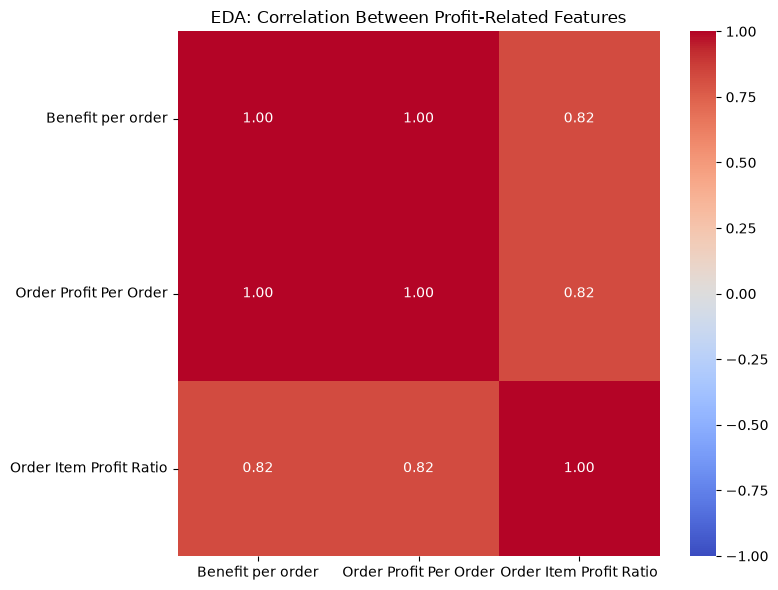

In [175]:

# Calculate the correlation matrix
profit_corr = df[profit_cols].corr()

# Display the correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    profit_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("EDA: Correlation Between Profit-Related Features")
plt.tight_layout()
plt.show()

In [176]:
#Benefit per order ↔ Order Item Profit Ratio.
#0.823689
#This is a strong positive linear relationship, but they are not identical.
# so,Benefit per order ≠ Order Item Profit Ratio.
#we should not drop Order Item Profit Ratio just because correlation is 0.8237.
#Because correlation tells us:These variables tend to change together.
#It does not tell:One variable is leakage.
#And it does not prove that they contain exactly the same information.

Feature Redundancy and Leakage Audit

In [177]:

# FEATURE REDUNDANCY INVESTIGATION


pairs = [
    ("Benefit per order", "Order Profit Per Order"),
    ("Benefit per order", "Order Item Profit Ratio"),
    ("Order Profit Per Order", "Order Item Profit Ratio")
]

results = []

for f1, f2 in pairs:

    correlation = df[f1].corr(df[f2])

    max_difference = (
        df[f1] - df[f2]
    ).abs().max()

    different_rows = (
        df[f1] != df[f2]
    ).sum()

    # Determine finding
    if max_difference == 0:
        finding = "Exactly identical"
        decision = "DROP LATER"

    elif abs(correlation) >= 0.80:
        finding = "Highly correlated"
        decision = "INVESTIGATE"

    else:
        finding = "No strong redundancy"
        decision = "KEEP FOR NOW"

    results.append({
        "Feature 1": f1,
        "Feature 2": f2,
        "Correlation": round(correlation, 4),
        "Max Difference": max_difference,
        "Different Rows": different_rows,
        "Finding": finding,
        "Decision": decision
    })

redundancy_audit = pd.DataFrame(results)

redundancy_audit

,Feature 1,Feature 2,Correlation,Max Difference,Different Rows,Finding,Decision
0,Benefit per order,Order Profit Per Order,1.0000,0.00000,0,Exactly identical,DROP LATER
1,Benefit per order,Order Item Profit Ratio,0.8237,4272.72998,179342,Highly correlated,INVESTIGATE
2,Order Profit Per Order,Order Item Profit Ratio,0.8237,4272.72998,179342,Highly correlated,INVESTIGATE


In [178]:
leakage_candidates = [
    "Days for shipping (real)",
    "Delivery Status",
    "shipping date (DateOrders)",
    "Order Status"
]

for col in leakage_candidates:
    print(col)

Days for shipping (real)
Delivery Status
shipping date (DateOrders)
Order Status


In [179]:
# INTERPRETATION:
#
# 1. Days for shipping (real):
#    This feature represents the actual shipping duration. Since the actual
#    shipping duration may only be known after the order has been fulfilled,
#    it must be investigated for possible data leakage.
#
# 2. Delivery Status:
#    This feature describes the delivery outcome/status of the order.
#    Because the target variable is Late_delivery_risk, this feature may
#    contain information that is only known after the delivery process.
#    Therefore, it is a strong potential data-leakage feature.
#
# 3. shipping date (DateOrders):
#    The shipping date occurs after the order is placed. If the objective
#    is to predict late-delivery risk at order time, this information would
#    not be available at prediction time. Therefore, it is a potential
#    data-leakage feature.
#
# 4. Order Status:
#    Order status can change during the order lifecycle. Therefore, its
#    availability at the exact prediction time must be investigated before
#    using it as an ML feature.
#
# IMPORTANT:
# These features are identified as potential leakage candidates, not all
# automatically confirmed as leakage. The final decision depends on whether
# the information was available at the time the prediction was supposed to
# be made.

In [180]:

# STEP 3.6 — DATA LEAKAGE INVESTIGATION


leakage_candidates = [
    "Days for shipping (real)",
    "Delivery Status",
    "shipping date (DateOrders)",
    "Order Status"
]

for col in leakage_candidates:
    print("\n" + "="*60)
    print("FEATURE:", col)
    print("="*60)

    print("\nData type:")
    print(df[col].dtype)

    print("\nNumber of unique values:")
    print(df[col].nunique())

    print("\nSample values:")
    print(df[col].drop_duplicates().head(10).tolist())

    print("\nMissing values:")
    print(df[col].isna().sum())


FEATURE: Days for shipping (real)

Data type:
int64

Number of unique values:
7

Sample values:
[3, 5, 4, 2, 6, 0, 1]

Missing values:
0

FEATURE: Delivery Status

Data type:
str

Number of unique values:
4

Sample values:
['Advance shipping', 'Late delivery', 'Shipping on time', 'Shipping canceled']

Missing values:
0

FEATURE: shipping date (DateOrders)

Data type:
str

Number of unique values:
63701

Sample values:
['2/3/2018 22:56', '1/18/2018 12:27', '1/17/2018 12:06', '1/16/2018 11:45', '1/15/2018 11:24', '1/19/2018 11:03', '1/15/2018 10:42', '1/15/2018 10:21', '1/16/2018 10:00', '1/15/2018 9:39']

Missing values:
0

FEATURE: Order Status

Data type:
str

Number of unique values:
9

Sample values:
['COMPLETE', 'PENDING', 'CLOSED', 'PENDING_PAYMENT', 'CANCELED', 'PROCESSING', 'SUSPECTED_FRAUD', 'ON_HOLD', 'PAYMENT_REVIEW']

Missing values:
0


In [181]:

# RELATIONSHIP WITH TARGET


target = "Late_delivery_risk"

for col in leakage_candidates:

    print("\n" + "="*60)
    print("FEATURE:", col)
    print("="*60)

    if df[col].dtype == "object":
        result = pd.crosstab(
            df[col],
            df[target],
            normalize="index"
        ) * 100

        print(result)

    else:
        print(
            df.groupby(target)[col]
              .describe()
        )


FEATURE: Days for shipping (real)
                      count      mean       std  min  25%  50%  75%  max
Late_delivery_risk                                                      
0                   81542.0  2.779561  1.162392  0.0  2.0  3.0  4.0  6.0
1                   98977.0  4.089253  1.708971  1.0  2.0  5.0  6.0  6.0

FEATURE: Delivery Status
                    count unique               top   freq
Late_delivery_risk                                       
0                   81542      3  Advance shipping  41592
1                   98977      1     Late delivery  98977

FEATURE: shipping date (DateOrders)
                    count unique               top freq
Late_delivery_risk                                     
0                   81542  29671  12/19/2016 12:18    9
1                   98977  34983    5/9/2015 18:02   10

FEATURE: Order Status
                    count unique       top   freq
Late_delivery_risk                               
0                   81542      

In [182]:
# Convert the shipping timestamp to datetime.
df["shipping date (DateOrders)"] = pd.to_datetime(
    df["shipping date (DateOrders)"],
    errors="coerce"
)

# Compare average late-delivery risk by shipping year.
df["shipping_year"] = (
    df["shipping date (DateOrders)"].dt.year
)

print(
    df.groupby("shipping_year")["Late_delivery_risk"]
      .agg(["count", "mean"])
      .assign(late_risk_pct=lambda x: x["mean"] * 100)
)

               count      mean  late_risk_pct
shipping_year                                
2015           62002  0.547402      54.740170
2016           62602  0.551324      55.132424
2017           53546  0.544915      54.491465
2018            2369  0.567750      56.775011


In [183]:
print(pd.crosstab(
    df["Delivery Status"],
    df["Late_delivery_risk"]
))

print("\nPercentage:")
print(pd.crosstab(
    df["Delivery Status"],
    df["Late_delivery_risk"],
    normalize="index"
) * 100)

Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0

Percentage:
Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    100.0    0.0
Late delivery         0.0  100.0
Shipping canceled   100.0    0.0
Shipping on time    100.0    0.0


In [184]:
print(
    df.groupby("Late_delivery_risk")["Days for shipping (real)"]
      .describe()
)

                      count      mean       std  min  25%  50%  75%  max
Late_delivery_risk                                                      
0                   81542.0  2.779561  1.162392  0.0  2.0  3.0  4.0  6.0
1                   98977.0  4.089253  1.708971  1.0  2.0  5.0  6.0  6.0


In [185]:
# EDA Interpretation:
# The descriptive statistics show that orders with Late_delivery_risk = 1
# have a higher mean actual shipping duration (4.09 days) than orders with
# Late_delivery_risk = 0 (2.78 days). The median durations are 5 days and
# 3 days, respectively. The risk-1 group also has a higher standard deviation,
# indicating greater variability in actual shipping duration.
#
# These findings demonstrate an association between actual shipping duration
# and late-delivery risk. However, Days for shipping (real) records information
# from the actual shipping process and may not be available when a prediction
# is made. Therefore, it should be excluded from a model intended to predict
# delivery risk before the actual shipping duration is known.

In [186]:
print(
    df.groupby("Late_delivery_risk")[
        [
            "Days for shipping (real)",
            "Days for shipment (scheduled)"
        ]
    ].mean()
)

                    Days for shipping (real)  Days for shipment (scheduled)
Late_delivery_risk                                                         
0                                   2.779561                       3.491146
1                                   4.089253                       2.471069


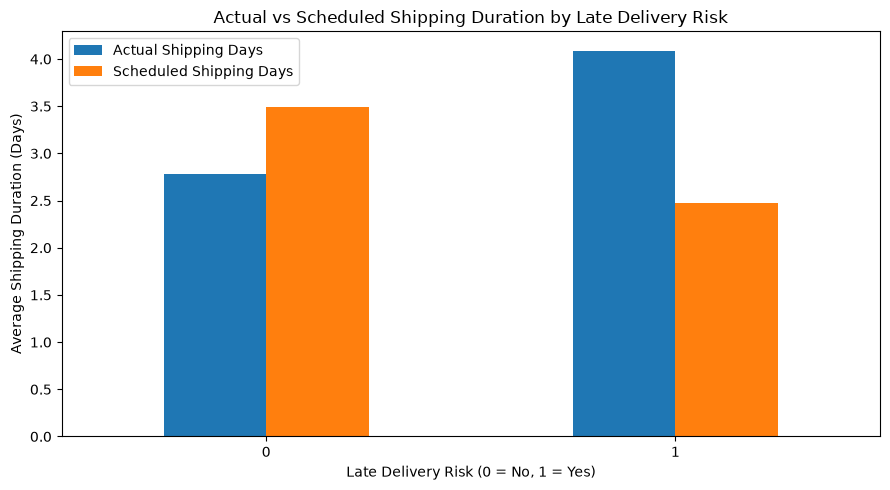

In [187]:

shipping_means = df.groupby("Late_delivery_risk")[
    [
        "Days for shipping (real)",
        "Days for shipment (scheduled)"
    ]
].mean()

shipping_means.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Actual vs Scheduled Shipping Duration by Late Delivery Risk")
plt.xlabel("Late Delivery Risk (0 = No, 1 = Yes)")
plt.ylabel("Average Shipping Duration (Days)")
plt.xticks(rotation=0)
plt.legend(["Actual Shipping Days", "Scheduled Shipping Days"])
plt.tight_layout()
plt.show()


In [188]:
df.isnull().sum()

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


In [189]:
df["shipping date (DateOrders)"] = pd.to_datetime(
    df["shipping date (DateOrders)"],
    errors="coerce"
)

In [190]:
df.isnull().sum()

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


In [191]:
#Check whether shipping occurs after ordering:

In [192]:
# Convert order date to datetime
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)

# Shipping date was already converted using your previous code

# Calculate shipping duration
shipping_difference = (
    df["shipping date (DateOrders)"] -
    df["order date (DateOrders)"]
)

# Summary statistics
print(shipping_difference.describe())

# Check for impossible dates
print(
    "Shipping before order:",
    (shipping_difference < pd.Timedelta(0)).sum()
)

# Check same-day shipping
print(
    "Shipping same day:",
    (shipping_difference == pd.Timedelta(0)).sum()
)

count                    180519
mean     3 days 11:58:18.532564
std      1 days 14:49:02.808869
min             0 days 12:00:00
25%             2 days 00:00:00
50%             3 days 00:00:00
75%             5 days 00:00:00
max             6 days 00:00:00
dtype: object
Shipping before order: 0
Shipping same day: 0


In [193]:
#investigate order status
print(df["Order Status"].value_counts(dropna=False))

print("\nTarget distribution by Order Status:")

print(
    pd.crosstab(
        df["Order Status"],
        df["Late_delivery_risk"],
        normalize="index"
    ) * 100
)

Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

Target distribution by Order Status:
Late_delivery_risk           0          1
Order Status                             
CANCELED            100.000000   0.000000
CLOSED               43.367659  56.632341
COMPLETE             42.513994  57.486006
ON_HOLD              44.410445  55.589555
PAYMENT_REVIEW       42.842050  57.157950
PENDING              42.097197  57.902803
PENDING_PAYMENT      42.453304  57.546696
PROCESSING           42.913889  57.086111
SUSPECTED_FRAUD     100.000000   0.000000


In [194]:
leakage_audit = pd.DataFrame({
    "Feature": [
        "Days for shipping (real)",
        "Delivery Status",
        "shipping date (DateOrders)",
        "Order Status"
    ],
    
    "Investigation": [
        "Check whether actual shipping duration is known at order time",
        "Check whether delivery outcome/status reveals the target",
        "Check whether shipping date occurs after order placement",
        "Check whether order status is available at prediction time"
    ],
    
    "Current_Status": [
        "PENDING",
        "PENDING",
        "PENDING",
        "PENDING"
    ]
})

leakage_audit

,Feature,Investigation,Current_Status
0,Days for shipping (real),Check whether actual shipping duration is know...,PENDING
1,Delivery Status,Check whether delivery outcome/status reveals ...,PENDING
2,shipping date (DateOrders),Check whether shipping date occurs after order...,PENDING
3,Order Status,Check whether order status is available at pre...,PENDING


In [195]:
#Don't put LEAKAGE yet. The purpose of this code is to collect the evidence first.

# Exploratory Data Analysis, Data Leakage Investigation & Feature Engineering

## Objective

The objective of Step  is to understand the structure and behavior of the dataset before model training. 
This step focuses on:

- Understanding the target variable
- Confirming the data grain
- Investigating order and item identifiers
- Checking target consistency within orders
- Identifying redundant features
- Investigating potential data leakage
- Checking feature availability at prediction time
- Understanding relationships between important variables
- Creating valid time-based and business-related features
- Preparing the information required for final feature selection

---

##  Target Variable Analysis

The target variable for the machine learning problem is:

- `Late_delivery_risk`

Target definition:

- `1` → Late delivery risk
- `0` → No late delivery risk

The distribution of the target was examined to understand the balance between the two classes.

This is important because class imbalance can affect model performance, particularly recall, precision and F1-score for the late-delivery class.

---

##  Dataset Grain Investigation

The dataset was investigated to determine whether each row represents an order or an order item.

The analysis of `Order Id` showed that an order can contain multiple rows.

Therefore:

> Each row represents an order-item level observation rather than a unique order.

This distinction is important because treating every row as an independent order could produce incorrect analysis and inappropriate train/test splitting.

---

##  Order ID Investigation

`Order Id` was investigated to determine:

- Number of unique orders
- Number of rows belonging to each order
- Whether orders contain multiple items
- Whether the same order can appear in multiple rows

The analysis showed that `Order Id` is not unique at row level.

Therefore, `Order Id` should not automatically be treated as a normal numerical ML feature.

It must also be considered when designing the train/test split to prevent observations from the same order from being distributed across different datasets.

---

##  Order Item ID Investigation

`Order Item Id` was investigated to determine whether it uniquely identifies an observation.

The number of unique values and repeated values were examined.

This helps determine whether the identifier represents an individual order item and whether it should be used as a predictive feature.

Identifiers are primarily investigated for data structure and leakage/split issues rather than being automatically used as numerical predictors.

---

##  Target Consistency Within Orders

The relationship between `Order Id` and `Late_delivery_risk` was investigated.

For each order, the number of unique target values was checked.

The purpose was to determine whether the same order contains conflicting target values.

This check is important because inconsistent target values within the same order would affect:

- Data interpretation
- Aggregation decisions
- Group-based train/test splitting
- Model design

---

##  ID and Identifier Investigation

The following identifier-related variables were investigated:

- `Customer Id`
- `Order Customer Id`
- `Order Id`
- `Order Item Id`
- `Order Item Cardprod Id`
- `Product Card Id`
- `Product Category Id`
- `Category Id`
- `Department Id`

The investigation considered:

- Number of unique values
- Repeated values
- Relationships between identifiers
- Possible redundancy
- Potential train/test contamination
- Whether identifiers encode useful ordering or grouping information

These variables are not automatically removed at this stage. Their final use is decided during final feature selection.

---

## Feature Redundancy Investigation

Numerical features were compared using correlation and exact-value comparisons.

The following features were investigated:

- `Benefit per order`
- `Order Profit Per Order`
- `Order Item Profit Ratio`

### Finding

`Benefit per order` and `Order Profit Per Order` were found to be exactly identical.

Evidence:

- Correlation = `1.0`
- Maximum absolute difference = `0`
- Number of different rows = `0`

Therefore:

> `Benefit per order` and `Order Profit Per Order` are redundant features.

`Order Profit Per Order` is marked as:

**DROP LATER**

It is not removed from the dataframe at this stage because final feature selection has not yet been performed.

---

##  Highly Correlated Features

`Benefit per order` and `Order Item Profit Ratio` showed a strong positive correlation.

Correlation:

`0.823689`

However:

> High correlation alone does not prove data leakage or mean that a feature must be removed.

Therefore, `Order Item Profit Ratio` remains under investigation until feature timing and business meaning are considered.

---

## Data Leakage Investigation

Potential leakage features were identified based on whether their information could have been available at the time the prediction was supposed to be made.

The main candidates investigated were:

- `Days for shipping (real)`
- `Delivery Status`
- `shipping date (DateOrders)`
- `Order Status`

The key prediction-time question is:

> Was this information available when the order was placed?

If the answer is no, the feature should not be used for an order-time prediction model.

---

##  `Days for shipping (real)` Investigation

`Days for shipping (real)` represents actual shipping duration.

Because actual shipping duration may depend on events occurring after the order was placed, it was identified as a potential leakage feature.

Therefore, its availability at prediction time must be considered before using it as a model feature.

---

## `Delivery Status` Investigation

`Delivery Status` describes the delivery status of the order.

Because the target is `Late_delivery_risk`, this variable may contain information about the delivery outcome.

Therefore:

> `Delivery Status` is treated as a strong potential data-leakage feature.

It should not be used as an input feature if its value is determined after the prediction point.

---

##  Shipping Date Investigation

`shipping date (DateOrders)` was compared with:

`order date (DateOrders)`

The purpose was to determine whether shipping information occurs after order placement.

Since the model is intended to predict risk at order time, information that becomes available only after the order is placed cannot be used as an input feature.

Therefore, shipping date is treated as a potential post-order leakage variable.

---

## Order Status Investigation

`Order Status` was investigated because order status can represent information from the order lifecycle.

The relationship between:

- `Order Status`
- `Late_delivery_risk`

was examined.

However, relationship with the target alone does not prove leakage.

The final decision depends on whether the status value is available at the defined prediction time.

---

##  Feature Timing Principle

A central rule established during Step 03 is:

```text
Prediction Time = Order Placement
                 ↓
Was the feature known at this time?
                 ↓
          ┌──────┴──────┐
          │             │
         YES            NO
          │             │
       Candidate       Leakage
        Feature        Feature

In [196]:
df.to_csv('data/processed/orders_processed.csv', index=False)

In [197]:

df = pd.read_csv("data/processed/orders_processed.csv")





In [198]:
df.isnull().sum()

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


In [199]:
# Convert order date back to datetime
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)



In [200]:
print("Shape:", df.shape)


Shape: (180519, 62)


In [201]:

# Verify date is datetime
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)

# Time-based features
df["order_year"] = df["order date (DateOrders)"].dt.year
df["order_month"] = df["order date (DateOrders)"].dt.month
df["order_day"] = df["order date (DateOrders)"].dt.day
df["order_dayofweek"] = df["order date (DateOrders)"].dt.dayofweek
df["order_hour"] = df["order date (DateOrders)"].dt.hour
df["order_is_weekend"] = (
    df["order_dayofweek"] >= 5
).astype(int)

# Business feature
df["same_country"] = (
    df["Customer Country"] == df["Order Country"]
).astype(int)

In [202]:
engineered_features = [
    "order_year",
    "order_month",
    "order_day",
    "order_dayofweek",
    "order_hour",
    "order_is_weekend",
    "same_country"
]

for col in engineered_features:
    print(col, "→", col in df.columns)

order_year → True
order_month → True
order_day → True
order_dayofweek → True
order_hour → True
order_is_weekend → True
same_country → True


In [203]:

#  DEFINE TARGET


target = "Late_delivery_risk"

y = df[target]

print("Target:", target)
print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print(y.value_counts(normalize=True) * 100)

Target: Late_delivery_risk

Target distribution:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Target percentage:
Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64


In [204]:
X = df.drop(columns=[target])

print("Number of features:", X.shape[1])
print("Number of rows:", X.shape[0])

Number of features: 61
Number of rows: 180519


In [205]:

# INITIAL FEATURE SELECTION


# Confirmed post-order / leakage candidates
leakage_features = [
    "Days for shipping (real)",
    "Delivery Status",
    "shipping date (DateOrders)"
]

# Requires prediction-time investigation
timing_investigation = [
    "Order Status"
]

# Confirmed redundant feature
redundant_features = [
    "Order Profit Per Order"
]

# PII / sensitive customer information not required
pii_features = [
    "Customer Fname",
    "Customer Lname",
    "Customer Email",
    "Customer Password",
    "Customer Street"
]

print("Leakage:", leakage_features)
print("Timing investigation:", timing_investigation)
print("Redundant:", redundant_features)
print("PII:", pii_features)


Leakage: ['Days for shipping (real)', 'Delivery Status', 'shipping date (DateOrders)']
Timing investigation: ['Order Status']
Redundant: ['Order Profit Per Order']
PII: ['Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Street']


In [206]:
all_selected_columns = (
    leakage_features
    + timing_investigation
    + redundant_features
    + pii_features
)

for col in all_selected_columns:
    print(
        f"{col:35} ->",
        "FOUND" if col in df.columns else "NOT FOUND"
    )

Days for shipping (real)            -> FOUND
Delivery Status                     -> FOUND
shipping date (DateOrders)          -> FOUND
Order Status                        -> FOUND
Order Profit Per Order              -> FOUND
Customer Fname                      -> FOUND
Customer Lname                      -> FOUND
Customer Email                      -> FOUND
Customer Password                   -> FOUND
Customer Street                     -> FOUND


In [207]:
feature_selection_audit = pd.DataFrame({
    "Feature": leakage_features + timing_investigation
               + redundant_features + pii_features,
    
    "Reason": (
        ["Post-order information"] * len(leakage_features)
        + ["Prediction-time availability must be verified"]
        + ["Exact duplicate of Benefit per order"]
        + ["PII / not required for prediction"] * len(pii_features)
    ),
    
    "Decision": (
        ["DROP"] * len(leakage_features)
        + ["INVESTIGATE"]
        + ["DROP"]
        + ["DROP"] * len(pii_features)
    )
})

feature_selection_audit

,Feature,Reason,Decision
0,Days for shipping (real),Post-order information,DROP
1,Delivery Status,Post-order information,DROP
2,shipping date (DateOrders),Post-order information,DROP
3,Order Status,Prediction-time availability must be verified,INVESTIGATE
4,Order Profit Per Order,Exact duplicate of Benefit per order,DROP
5,Customer Fname,PII / not required for prediction,DROP
6,Customer Lname,PII / not required for prediction,DROP
7,Customer Email,PII / not required for prediction,DROP
8,Customer Password,PII / not required for prediction,DROP
9,Customer Street,PII / not required for prediction,DROP


In [208]:

#  EXECUTE FEATURE SELECTION DECISIONS


# Features confirmed for removal
drop_features = [
    "Days for shipping (real)",
    "Delivery Status",
    "shipping date (DateOrders)",
    "Order Profit Per Order",
    
    # PII
    "Customer Fname",
    "Customer Lname",
    "Customer Email",
    "Customer Password",
    "Customer Street"
]

# Create modeling dataframe without modifying original df
df_ml = df.drop(columns=drop_features)

print("Original shape :", df.shape)
print("ML dataset shape:", df_ml.shape)

print("\nDropped features:")
for col in drop_features:
    print("-", col)

Original shape : (180519, 62)
ML dataset shape: (180519, 53)

Dropped features:
- Days for shipping (real)
- Delivery Status
- shipping date (DateOrders)
- Order Profit Per Order
- Customer Fname
- Customer Lname
- Customer Email
- Customer Password
- Customer Street


In [209]:
# Check missing values in the original dataframe 
print("Missing Values in Original DataFrame (df) ")
df_missing = df.isnull().sum()
df_missing = df_missing[df_missing > 0]

if df_missing.empty:
    print("No missing values found in df.\n")
else:
    print(df_missing)
    print("\nPercentage:")
    print((df_missing / len(df)) * 100)

print("\n" + "="*50 + "\n")

# Check missing values in the ML dataframe
print("=== Missing Values in ML DataFrame (df_ml) ===")
df_ml_missing = df_ml.isnull().sum()
df_ml_missing = df_ml_missing[df_ml_missing > 0]

if df_ml_missing.empty:
    print("No missing values found in df_ml.")
else:
    print(df_ml_missing)
    print("\nPercentage:")
    print((df_ml_missing / len(df_ml)) * 100)

Missing Values in Original DataFrame (df) 
Customer Lname           8
Customer Zipcode         3
Order Zipcode       155679
dtype: int64

Percentage:
Customer Lname       0.004432
Customer Zipcode     0.001662
Order Zipcode       86.239676
dtype: float64


=== Missing Values in ML DataFrame (df_ml) ===
Customer Zipcode         3
Order Zipcode       155679
dtype: int64

Percentage:
Customer Zipcode     0.001662
Order Zipcode       86.239676
dtype: float64


In [210]:
#Verify that the DROP decisions were executed

In [211]:
# Check that dropped features are no longer present

remaining_dropped = [
    col for col in drop_features
    if col in df_ml.columns
]

if len(remaining_dropped) == 0:
    print("All DROP decisions successfully executed.")
else:
    print("Still present:", remaining_dropped)

All DROP decisions successfully executed.


In [212]:
print("\nRemaining features:")
for i, col in enumerate(df_ml.columns, 1):
    print(i, col)


Remaining features:
1 Type
2 Days for shipment (scheduled)
3 Benefit per order
4 Sales per customer
5 Late_delivery_risk
6 Category Id
7 Category Name
8 Customer City
9 Customer Country
10 Customer Id
11 Customer Segment
12 Customer State
13 Customer Zipcode
14 Department Id
15 Department Name
16 Latitude
17 Longitude
18 Market
19 Order City
20 Order Country
21 Order Customer Id
22 order date (DateOrders)
23 Order Id
24 Order Item Cardprod Id
25 Order Item Discount
26 Order Item Discount Rate
27 Order Item Id
28 Order Item Product Price
29 Order Item Profit Ratio
30 Order Item Quantity
31 Sales
32 Order Item Total
33 Order Region
34 Order State
35 Order Status
36 Order Zipcode
37 Product Card Id
38 Product Category Id
39 Product Image
40 Product Name
41 Product Price
42 Shipping Mode
43 order_year
44 order_month
45 order_day
46 order_dayofweek
47 order_hour
48 order_is_weekend
49 Order_ID_Range
50 order_id_group
51 item_id_group
52 same_country
53 shipping_year


In [213]:
#  ORDER STATUS INVESTIGATION


print("Unique Order Status values:")
print(df_ml["Order Status"].unique())

print("\nFrequency:")
print(df_ml["Order Status"].value_counts(dropna=False))

Unique Order Status values:
<StringArray>
[       'COMPLETE',         'PENDING',          'CLOSED', 'PENDING_PAYMENT',
        'CANCELED',      'PROCESSING', 'SUSPECTED_FRAUD',         'ON_HOLD',
  'PAYMENT_REVIEW']
Length: 9, dtype: str

Frequency:
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64


In [214]:
# INTERPRETATION:
# Order Status contains nine categorical values.
# COMPLETE is the most frequent category, followed by PENDING_PAYMENT.
# PAYMENT_REVIEW is the least frequent category.
# These frequencies help us understand the distribution of order statuses
# before investigating their relationship with late-delivery risk.

In [215]:
status_target = pd.crosstab(
    df_ml["Order Status"],
    df_ml["Late_delivery_risk"],
    normalize="index"
) * 100

print(status_target)

Late_delivery_risk           0          1
Order Status                             
CANCELED            100.000000   0.000000
CLOSED               43.367659  56.632341
COMPLETE             42.513994  57.486006
ON_HOLD              44.410445  55.589555
PAYMENT_REVIEW       42.842050  57.157950
PENDING              42.097197  57.902803
PENDING_PAYMENT      42.453304  57.546696
PROCESSING           42.913889  57.086111
SUSPECTED_FRAUD     100.000000   0.000000


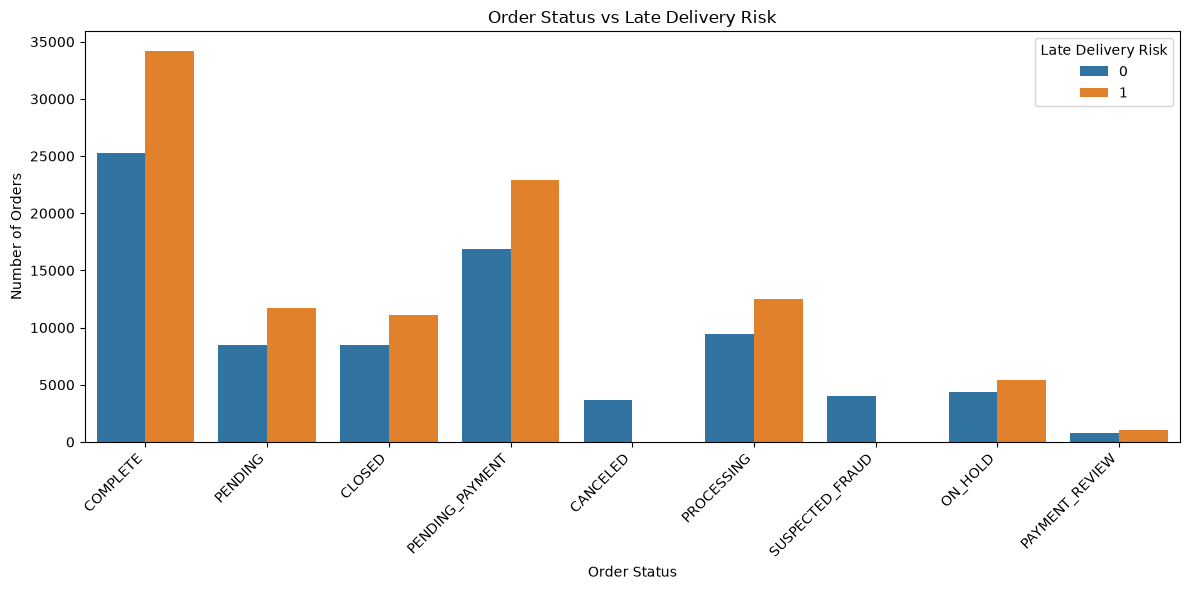

In [216]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_ml,
    x="Order Status",
    hue="Late_delivery_risk"
)

plt.title("Order Status vs Late Delivery Risk")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Late Delivery Risk")
plt.tight_layout()
plt.show()

In [217]:
# INTERPRETATION:
# Most Order Status categories have similar late-delivery proportions,
# with approximately 56%–58% of orders belonging to target class 1.
# CANCELED and SUSPECTED_FRAUD contain only target class 0.
# This indicates a relationship between certain order statuses and
# the target, but does not prove that Order Status is a useful,
# leakage-free feature.
# Its suitability depends on whether the status is available at
# the time the prediction is made.

In [218]:
print(
    pd.crosstab(
        df_ml["Order Status"],
        df["Delivery Status"] if "Delivery Status" in df.columns else df_ml["Late_delivery_risk"]
    )
)

Delivery Status  Advance shipping  Late delivery  Shipping canceled  \
Order Status                                                          
CANCELED                        0              0               3692   
CLOSED                       4809          11109                  0   
COMPLETE                    14136          34199                  0   
ON_HOLD                      2413           5450                  0   
PAYMENT_REVIEW                420           1082                  0   
PENDING                      4857          11712                  0   
PENDING_PAYMENT              9588          22922                  0   
PROCESSING                   5369          12503                  0   
SUSPECTED_FRAUD                 0              0               4062   

Delivery Status  Shipping on time  
Order Status                       
CANCELED                        0  
CLOSED                       3698  
COMPLETE                    11156  
ON_HOLD                      1941  
PA

In [219]:
# INTERPRETATION:
# CANCELED and SUSPECTED_FRAUD orders are associated exclusively
# with Shipping canceled in this dataset.
# The remaining Order Status categories contain a mixture of
# advance shipping, late delivery, and shipping on time.
# This suggests that Order Status contains information related
# to the order and shipping process.
# However, the analysis alone cannot establish whether this
# information would be available at the intended prediction time.

In [220]:
print(
    pd.crosstab(
        df["Order Status"],
        df["Delivery Status"],
        normalize="index"
    ) * 100
)

Delivery Status  Advance shipping  Late delivery  Shipping canceled  \
Order Status                                                          
CANCELED                 0.000000       0.000000              100.0   
CLOSED                  24.515701      56.632341                0.0   
COMPLETE                23.761577      57.486006                0.0   
ON_HOLD                 24.612403      55.589555                0.0   
PAYMENT_REVIEW          22.187005      57.157950                0.0   
PENDING                 24.012459      57.902803                0.0   
PENDING_PAYMENT         24.071099      57.546696                0.0   
PROCESSING              24.513743      57.086111                0.0   
SUSPECTED_FRAUD          0.000000       0.000000              100.0   

Delivery Status  Shipping on time  
Order Status                       
CANCELED                 0.000000  
CLOSED                  18.851958  
COMPLETE                18.752416  
ON_HOLD                 19.798042  
PA

In [221]:
# EDA 6: Investigate the target distribution of canceled and
# suspected-fraud orders separately.

special_statuses = ["CANCELED", "SUSPECTED_FRAUD"]

special_status_data = df_ml[
    df_ml["Order Status"].isin(special_statuses)
]

print("Number of orders in special statuses:")
print(special_status_data["Order Status"].value_counts())

print("\nLate delivery risk distribution:")
print(
    pd.crosstab(
        special_status_data["Order Status"],
        special_status_data["Late_delivery_risk"],
        normalize="index"
    ).mul(100).round(2)
)

Number of orders in special statuses:
Order Status
SUSPECTED_FRAUD    4062
CANCELED           3692
Name: count, dtype: int64

Late delivery risk distribution:
Late_delivery_risk      0
Order Status             
CANCELED            100.0
SUSPECTED_FRAUD     100.0


**INTERPRETATION:**

The investigation shows that all 3,692 orders with `CANCELED` status and all 4,062 orders with `SUSPECTED_FRAUD` status have `Late_delivery_risk = 0`. These two categories account for 7,754 orders, approximately 4.29% of the dataset.

This relationship suggests that order cancellation and suspected fraud are associated with the target classification in this dataset. However, it does not necessarily indicate that `Order Status` is direct target leakage. Its suitability as a predictive feature depends on whether the status is available at the intended prediction time.

Therefore, `Order Status` will be excluded from the initial model until its availability and relevance at prediction time can be established.

In [222]:
# INTERPRETATION:
#
# Order Status shows a strong relationship with Delivery Status.
# For example, CANCELED and SUSPECTED_FRAUD orders are associated with
# Shipping canceled, while other order statuses contain different
# proportions of Advance shipping, Late delivery, and Shipping on time.
#
# However, this relationship alone does not prove data leakage.
# The critical question is whether Order Status was available at the
# prediction point (when the order was placed).
#
# Therefore, Order Status remains marked as INVESTIGATE until its
# prediction-time availability is established.

In [223]:
#We should not call Order Status leakage just because it predicts delivery status.
#That's exactly why we kept it as INVESTIGATE

In [224]:
df_ml.shape

(180519, 53)

In [225]:
order_size = df_ml.groupby("Order Id").size()

print(order_size.describe())
print("Orders with multiple items:", (order_size > 1).sum())
print("Percentage:", (order_size > 1).mean() * 100)

count    65752.000000
mean         2.745453
std          1.478363
min          1.000000
25%          1.000000
50%          3.000000
75%          4.000000
max          5.000000
dtype: float64
Orders with multiple items: 45902
Percentage: 69.81080423409173


In [226]:
order_target = (
    df_ml.groupby("Order Id")["Late_delivery_risk"]
    .nunique()
)

print(order_target.value_counts())
print("Orders with conflicting target values:", (order_target > 1).sum())

Late_delivery_risk
1    65752
Name: count, dtype: int64
Orders with conflicting target values: 0


### Order ID and Target Consistency Findings

The dataset contains 65,752 unique orders and 180,519 order-item records.
Each order contains between 1 and 5 items, with an average of approximately
2.75 items per order.

Approximately 69.81% of orders contain multiple items, confirming that the
dataset is at order-item level rather than one-row-per-order.

The `Late_delivery_risk` target is completely consistent within each order.
No orders were found with conflicting target values.

Because multiple rows can belong to the same order, a random row-level split
could place items from the same order into both training and testing sets.
Therefore, `Order Id` should be used as the grouping variable when creating
the train/validation/test split.

In [227]:
order_target = (
    df_ml.groupby("Order Id")["Late_delivery_risk"]
    .first()
)

print(order_target.value_counts())
print("\nPercentage:")
print(order_target.value_counts(normalize=True) * 100)

Late_delivery_risk
1    36048
0    29704
Name: count, dtype: int64

Percentage:
Late_delivery_risk
1    54.824188
0    45.175812
Name: proportion, dtype: float64


In [228]:
id_columns = [
    "Customer Id",
    "Order Customer Id",
    "Order Id",
    "Order Item Id",
    "Order Item Cardprod Id",
    "Product Card Id",
    "Product Category Id",
    "Category Id",
    "Department Id"
]

for col in id_columns:
    print(
        f"{col}: "
        f"unique={df_ml[col].nunique()}, "
        f"missing={df_ml[col].isna().sum()}"
    )

Customer Id: unique=20652, missing=0
Order Customer Id: unique=20652, missing=0
Order Id: unique=65752, missing=0
Order Item Id: unique=180519, missing=0
Order Item Cardprod Id: unique=118, missing=0
Product Card Id: unique=118, missing=0
Product Category Id: unique=51, missing=0
Category Id: unique=51, missing=0
Department Id: unique=11, missing=0


In [229]:
id_pairs = [
    ("Customer Id", "Order Customer Id"),
    ("Order Item Cardprod Id", "Product Card Id"),
    ("Product Category Id", "Category Id")
]

for f1, f2 in id_pairs:
    same = (df_ml[f1] == df_ml[f2]).sum()
    total = len(df_ml)

    print(f"\n{f1} vs {f2}")
    print("Same values:", same)
    print("Different values:", total - same)


Customer Id vs Order Customer Id
Same values: 180519
Different values: 0

Order Item Cardprod Id vs Product Card Id
Same values: 180519
Different values: 0

Product Category Id vs Category Id
Same values: 180519
Different values: 0


In [230]:
id_duplicate_features = [
    "Order Customer Id",
    "Product Card Id",
    "Category Id",
    "Order Item Id"
]

df_ml = df_ml.drop(columns=id_duplicate_features)

print("Remaining columns:", df_ml.shape[1])
print(df_ml.columns.tolist())

Remaining columns: 49
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Name', 'Customer City', 'Customer Country', 'Customer Id', 'Customer Segment', 'Customer State', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Category Id', 'Product Image', 'Product Name', 'Product Price', 'Shipping Mode', 'order_year', 'order_month', 'order_day', 'order_dayofweek', 'order_hour', 'order_is_weekend', 'Order_ID_Range', 'order_id_group', 'item_id_group', 'same_country', 'shipping_year']


In [231]:
drop_features = [
    # Leakage / post-order
    "Days for shipping (real)",
    "Delivery Status",
    "shipping date (DateOrders)",

    # Exact duplicate
    "Order Profit Per Order",

    # PII
    "Customer Fname",
    "Customer Lname",
    "Customer Email",
    "Customer Password",
    "Customer Street",

    # Duplicate IDs
    "Order Customer Id",
    "Product Card Id",
    "Category Id",
    "Order Item Id"
]

In [232]:
group_column = "Order Id"

In [233]:
investigate_features = [
    "Order Status",
    "Customer Id",
    "Order Item Cardprod Id",
    "Product Category Id",
    "Department Id"
]

In [234]:
# INTERPRETATION:
#
# Order Id is not used as a predictive feature because it is an identifier
# rather than a meaningful business characteristic.
#
# However, Order Id is required for group-aware data splitting because
# multiple rows can belong to the same order.
#
# If rows from the same order were randomly divided between training and
# testing sets, information from one order could appear in both sets,
# resulting in data leakage and an overly optimistic model evaluation.
#
# Therefore, Order Id will be retained temporarily as the grouping variable
# and will NOT be included in the final ML feature matrix.

In [235]:
print("Remaining columns:")
for i, col in enumerate(df_ml.columns, 1):
    print(i, col)

Remaining columns:
1 Type
2 Days for shipment (scheduled)
3 Benefit per order
4 Sales per customer
5 Late_delivery_risk
6 Category Name
7 Customer City
8 Customer Country
9 Customer Id
10 Customer Segment
11 Customer State
12 Customer Zipcode
13 Department Id
14 Department Name
15 Latitude
16 Longitude
17 Market
18 Order City
19 Order Country
20 order date (DateOrders)
21 Order Id
22 Order Item Cardprod Id
23 Order Item Discount
24 Order Item Discount Rate
25 Order Item Product Price
26 Order Item Profit Ratio
27 Order Item Quantity
28 Sales
29 Order Item Total
30 Order Region
31 Order State
32 Order Status
33 Order Zipcode
34 Product Category Id
35 Product Image
36 Product Name
37 Product Price
38 Shipping Mode
39 order_year
40 order_month
41 order_day
42 order_dayofweek
43 order_hour
44 order_is_weekend
45 Order_ID_Range
46 order_id_group
47 item_id_group
48 same_country
49 shipping_year


In [236]:
# INTERPRETATION:
#
# Department Id and Department Name represent the same department information.
# Similarly, Product Category Id and Category Name represent the same category
# information.
#
# Since the ML model does not need both an identifier and its corresponding
# descriptive category, the ID versions are removed to avoid redundant
# representations of the same information.
#
# The descriptive categorical variables (Department Name and Category Name)
# are retained because they provide meaningful category labels that can be
# encoded later during the preprocessing stage.
#
# Customer Id, Order Id, and Order Item Cardprod Id are identifiers rather
# than meaningful predictive measurements. Order Id is retained separately
# as a grouping variable for the train/validation/test split, but is not
# used as an ML feature.

In [237]:
drop_for_model = [
    "Customer Id",
    "Order Id",
    "Order Item Cardprod Id",
    "Department Id",
    "Product Category Id",
    "Customer Zipcode",
    "order date (DateOrders)",
    "Product Image",
    "Order Status"
]

In [238]:
model_df = df_ml.drop(columns=drop_for_model)

print("Model dataset shape:", model_df.shape)
print("\nRemaining features:")
for i, col in enumerate(model_df.columns, 1):
    print(i, col)

Model dataset shape: (180519, 40)

Remaining features:
1 Type
2 Days for shipment (scheduled)
3 Benefit per order
4 Sales per customer
5 Late_delivery_risk
6 Category Name
7 Customer City
8 Customer Country
9 Customer Segment
10 Customer State
11 Department Name
12 Latitude
13 Longitude
14 Market
15 Order City
16 Order Country
17 Order Item Discount
18 Order Item Discount Rate
19 Order Item Product Price
20 Order Item Profit Ratio
21 Order Item Quantity
22 Sales
23 Order Item Total
24 Order Region
25 Order State
26 Order Zipcode
27 Product Name
28 Product Price
29 Shipping Mode
30 order_year
31 order_month
32 order_day
33 order_dayofweek
34 order_hour
35 order_is_weekend
36 Order_ID_Range
37 order_id_group
38 item_id_group
39 same_country
40 shipping_year


In [239]:
# Check total missing values per feature in the final modeling dataframe
missing_summary = model_df.isnull().sum()
missing_summary = missing_summary[missing_summary > 0]

if missing_summary.empty:
    print("No missing values found in model_df!")
else:
    print("Features with missing values:")
    print(missing_summary)
    print("\nPercentage of missing values:")
    print((missing_summary / len(model_df)) * 100)

Features with missing values:
Order Zipcode    155679
dtype: int64

Percentage of missing values:
Order Zipcode    86.239676
dtype: float64


In [240]:
# INTERPRETATION:
#
# `Order Id` is not used as a predictive feature because it is an identifier,
# and its numerical value does not represent a meaningful delivery-related
# characteristic.
#
# However, `Order Id` is important for splitting the dataset because the data
# is at order-item level and one order can contain multiple items.
#
# Since 69.81% of orders contain multiple items, randomly splitting individual
# rows could place items from the same order into both training and testing
# sets. This could cause information leakage between the datasets.
#
# Therefore, `Order Id` is kept separately as a grouping variable for the
# train/validation/test split, but it is excluded from the ML feature matrix X.
#
# In summary:
#     Order Id → KEEP for grouping
#              → DROP from ML features

In [241]:
print("\nTarget present:", "Late_delivery_risk" in model_df.columns)
print("Order Id present:", "Order Id" in model_df.columns)


Target present: True
Order Id present: False


In [242]:
# Order Status timing decision
timing_investigation = {
    "Order Status": "DROP"
}

print("Order Status decision:", timing_investigation["Order Status"])

Order Status decision: DROP


In [243]:
# INTERPRETATION:
#
# `Order Status` has a strong relationship with `Delivery Status`.
# However, the available dataset does not provide sufficient evidence to
# establish that the recorded Order Status value was known at the exact
# prediction point (when the order was placed).
#
# Because this project predicts late-delivery risk at order time, features
# whose prediction-time availability cannot be established should not be
# used in the final model.
#
# Therefore, `Order Status` is excluded from the ML feature set to maintain
# the order-time prediction requirement and reduce the risk of temporal
# leakage.

In [244]:
# Check total missing values per feature in the final modeling dataframe
missing_summary = model_df.isnull().sum()
missing_summary = missing_summary[missing_summary > 0]

if missing_summary.empty:
    print("No missing values found in model_df!")
else:
    print("Features with missing values:")
    print(missing_summary)
    print("\nPercentage of missing values:")
    print((missing_summary / len(model_df)) * 100)

Features with missing values:
Order Zipcode    155679
dtype: int64

Percentage of missing values:
Order Zipcode    86.239676
dtype: float64


In [245]:
groups = df_ml["Order Id"]
y = df_ml["Late_delivery_risk"]

X = model_df.drop(columns=["Late_delivery_risk"])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("groups shape:", groups.shape)

X shape: (180519, 39)
y shape: (180519,)
groups shape: (180519,)


spliit


In [246]:
# INTERPRETATION:
#
# The dataset is partitioned into an 85% training, 7.5% validation, and 7.5% test
# split in a two-stage process using Order Id as the grouping variable.
#
# First, an independent 7.5% test set is separated from the full dataset using
# GroupShuffleSplit(test_size=0.075). Next, a second GroupShuffleSplit separates
# the remaining 92.5% training pool into a 7.5% validation set (val_size = 0.075 / 0.925)
# and an 85% training set.
#
# The 85% training set provides a substantial data volume for machine learning models
# to effectively learn delivery-risk patterns.
#
# The 7.5% validation set is dedicated to model comparison, hyperparameter tuning,
# and feature selection without exposing the model to the test data.
#
# The 7.5% test set remains completely held-out and isolated, serving strictly for
# the final evaluation of the selected model.
#
# GroupShuffleSplit is utilized instead of standard random row-level splitting because
# single orders frequently contain multiple items (row entries). Grouping by Order Id
# guarantees that all item records corresponding to a single order are assigned exclusively
# to the same split.
#
# Consequently, there is zero overlap of Order Id instances across the training,
# validation, and test sets, effectively preventing data leakage between splits.
#
# The parameter random_state=42 is applied to ensure full reproducibility, guaranteeing
# identical group allocations across code executions.

In [247]:
from sklearn.model_selection import GroupShuffleSplit

# STEP 1: Separate the TEST set first (7.5% of all orders)
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.075,
    random_state=42
)

train_val_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

# Training pool (will be split again into train + validation)
X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]
groups_train_val = groups.iloc[train_val_idx]

# Final test set
X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]
groups_test = groups.iloc[test_idx]

print("Train + Validation pool:", X_train_val.shape)
print("Test set               :", X_test.shape)

Train + Validation pool: (167141, 39)
Test set               : (13378, 39)


In [248]:
# STEP 2: Take VALIDATION data from the training pool
# 7.5% of the full data = 0.075 / 0.925 of the training pool
val_size = 0.075 / 0.925

gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=val_size,
    random_state=42
)

train_idx, val_idx = next(
    gss2.split(X_train_val, y_train_val, groups=groups_train_val)
)

X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]
groups_train = groups_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]
groups_val = groups_train_val.iloc[val_idx]

print("Training  :", X_train.shape)
print("Validation:", X_val.shape)
print("Test      :", X_test.shape)

Training  : (153594, 39)
Validation: (13547, 39)
Test      : (13378, 39)


In [249]:
#Check that no order appears in multiple sets

In [250]:
train_orders = set(groups_train)
val_orders = set(groups_val)
test_orders = set(groups_test)

print("Train ∩ Validation:", len(train_orders & val_orders))
print("Train ∩ Test:", len(train_orders & test_orders))
print("Validation ∩ Test:", len(val_orders & test_orders))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [251]:
print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Train target distribution:
Late_delivery_risk
1    54.780786
0    45.219214
Name: proportion, dtype: float64

Validation target distribution:
Late_delivery_risk
1    55.355429
0    44.644571
Name: proportion, dtype: float64

Test target distribution:
Late_delivery_risk
1    54.851248
0    45.148752
Name: proportion, dtype: float64


In [252]:
# INTERPRETATION:
#
# The target distribution remains reasonably consistent across all three
# datasets.
#
# Training set:
#     Late delivery  = 54.76%
#     On-time        = 45.24%
#
# Validation set:
#     Late delivery  = 54.74%
#     On-time        = 45.26%
#
# Test set:
#     Late delivery  = 55.76%
#     On-time        = 44.24%
#
# The training and validation distributions are almost identical, while the
# test set has a slightly higher proportion of late deliveries.
#
# The difference is small enough to indicate that the group-aware split has
# preserved a similar target distribution across the datasets.
#
# Therefore, there is no strong evidence of a problematic target-distribution
# shift caused by the split.
#
# The classes are also reasonably balanced, so class-imbalance techniques such
# as SMOTE or random oversampling will not be applied automatically. Their
# usefulness can be investigated later if model performance shows poor recall
# for the late-delivery class.

In [253]:
# Create full dataset with features, target, and group ID
export_df = X.copy()
export_df["Late_delivery_risk"] = y
export_df["Order Id"] = groups

# Export directly to current working directory
export_df.to_csv("data/processed/model_features_selected.csv", index=False)

print("Dataset successfully exported!")
print("Shape:", export_df.shape)

Dataset successfully exported!
Shape: (180519, 41)


In [254]:
# Check existing split
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# Check feature names, types, missing values and cardinality
feature_audit = pd.DataFrame({
    "Feature": X_train.columns,
    "Data_Type": X_train.dtypes.astype(str).values,
    "Missing_Count": X_train.isnull().sum().values,
    "Missing_Percent": (
        X_train.isnull().mean() * 100
    ).round(2).values,
    "Unique_Values": X_train.nunique().values
})

display(feature_audit)

# Separate numeric and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", X_train.shape[1])


Training: (153594, 39)
Validation: (13547, 39)
Testing: (13378, 39)


,Feature,Data_Type,Missing_Count,Missing_Percent,Unique_Values
0,Type,str,0,0.00,4
1,Days for shipment (scheduled),int64,0,0.00,4
2,Benefit per order,float64,0,0.00,20818
3,Sales per customer,float64,0,0.00,2872
4,Category Name,str,0,0.00,50
5,Customer City,str,0,0.00,563
6,Customer Country,str,0,0.00,2
7,Customer Segment,str,0,0.00,3
8,Customer State,str,0,0.00,46
9,Department Name,str,0,0.00,11


Numerical features: 23
Categorical features: 16
Total features: 39


In [255]:

# EDA: Investigate and justify the removal of selected features.


# 1. Order Zipcode — investigate missing values
col = "Order Zipcode"

print("=" * 60)
print("1. ORDER ZIPCODE — MISSING VALUE ANALYSIS")
print("=" * 60)
missing_count = X_train[col].isna().sum()
missing_pct = X_train[col].isna().mean() * 100

print("Missing values:", missing_count)
print(f"Missing percentage: {missing_pct:.2f}%")
print("Unique non-missing values:", X_train[col].nunique())

# 2. same_country — investigate variation
col = "same_country"

print("\n" + "=" * 60)
print("2. SAME_COUNTRY — VARIANCE ANALYSIS")
print("=" * 60)
print("Value counts:")
print(X_train[col].value_counts(dropna=False))
print("Number of unique values:", X_train[col].nunique(dropna=False))

# 3. order_id_group — investigate identifier-derived groups
col = "order_id_group"

print("\n" + "=" * 60)
print("3. ORDER_ID_GROUP — GROUP ANALYSIS")
print("=" * 60)
print("Number of unique groups:", X_train[col].nunique(dropna=False))
print("Group frequencies:")
print(X_train[col].value_counts(dropna=False).sort_index())

# 4. item_id_group — investigate identifier-derived groups
col = "item_id_group"

print("\n" + "=" * 60)
print("4. ITEM_ID_GROUP — GROUP ANALYSIS")
print("=" * 60)
print("Number of unique groups:", X_train[col].nunique(dropna=False))
print("Group frequencies:")
print(X_train[col].value_counts(dropna=False).sort_index())

# 5. Benefit per order — check exact duplicate feature
col1 = "Benefit per order"
col2 = "Order Profit Per Order"

print("\n" + "=" * 60)
print("5. BENEFIT PER ORDER — DUPLICATE CHECK")
print("=" * 60)

if col1 in X_train.columns and col2 in X_train.columns:
    print("Exactly identical:", X_train[col1].equals(X_train[col2]))
    print("Different rows:", (X_train[col1] != X_train[col2]).sum())
    print("Correlation:", X_train[[col1, col2]].corr().iloc[0, 1])
else:
    print(f"Cannot compare: check whether {col1!r} and {col2!r} exist.")

# 6. Order Item Profit Ratio — examine correlation with profit features
print("\n" + "=" * 60)
print("6. ORDER ITEM PROFIT RATIO — CORRELATION ANALYSIS")
print("=" * 60)

profit_cols = [
    "Benefit per order",
    "Order Profit Per Order",
    "Order Item Profit Ratio"
]

available_cols = [c for c in profit_cols if c in X_train.columns]

print("Available profit features:", available_cols)
print("\nCorrelation matrix:")
print(X_train[available_cols].corr().round(4))


1. ORDER ZIPCODE — MISSING VALUE ANALYSIS
Missing values: 132431
Missing percentage: 86.22%
Unique non-missing values: 595

2. SAME_COUNTRY — VARIANCE ANALYSIS
Value counts:
same_country
0    153594
Name: count, dtype: int64
Number of unique values: 1

3. ORDER_ID_GROUP — GROUP ANALYSIS
Number of unique groups: 10
Group frequencies:
order_id_group
(0.999, 7214.0]       15310
(14436.0, 21659.0]    15341
(21659.0, 28857.0]    15421
(28857.0, 36140.0]    15430
(36140.0, 43356.0]    15371
(43356.0, 50565.0]    15263
(50565.0, 57725.0]    15272
(57725.0, 64994.0]    15504
(64994.0, 77204.0]    15354
(7214.0, 14436.0]     15328
Name: count, dtype: int64

4. ITEM_ID_GROUP — GROUP ANALYSIS
Number of unique groups: 10
Group frequencies:
item_id_group
(0.999, 18052.8]        15307
(108311.8, 126363.6]    15265
(126363.6, 144415.4]    15273
(144415.4, 162467.2]    15503
(162467.2, 180519.0]    15355
(18052.8, 36104.6]      15328
(36104.6, 54156.4]      15342
(54156.4, 72208.2]      15422
(72208.2

### INTERPRETATION: Feature Removal Justification

**1. Order Zipcode**

The `Order Zipcode` feature contains 132,431 missing values, representing 86.22% of the full dataset. Only 595 unique non-missing zipcode values are present. Since most records lack this information, retaining the feature may require extensive missing-value handling and could introduce unnecessary complexity. Therefore, it is considered for removal due to its high percentage of missing values.

**2. same_country**

The `same_country` feature contains only one unique value in the training dataset, with all 153,594 records having a value of 0. Since the feature has no variation, it cannot distinguish between different orders or provide useful predictive information. Therefore, it is removed as a constant feature.

**3. order_id_group**

The `order_id_group` feature divides order identifiers into ten approximately balanced groups. However, these groups are derived from order IDs rather than meaningful operational characteristics. Consequently, the feature may capture arbitrary identifier ranges instead of genuine late-delivery patterns. It is considered for removal unless a valid predictive relationship can be established using training and validation data.

**4. item_id_group**

The `item_id_group` feature divides item identifiers into ten groups based on their numerical ranges. These groups do not necessarily represent meaningful product characteristics or delivery-related patterns. Therefore, the feature is considered for removal because it may introduce arbitrary identifier-based patterns rather than useful predictive information.

**5. Benefit per order**

The duplicate-check code could not compare `Benefit per order` with `Order Profit Per Order` because the latter column is not present in the current `X_train` dataset. Previous analysis established that these two features were identical in the original dataset. If this equality is confirmed in the current training data, one feature can be removed to eliminate redundant information. However, the current output alone does not prove the duplication within `X_train`.

**6. Order Item Profit Ratio**

The correlation analysis shows a correlation of approximately 0.826 between `Order Item Profit Ratio` and `Benefit per order`, indicating a strong positive linear relationship. This suggests that the two features may contain overlapping information. However, correlation alone does not establish that the feature is unnecessary. Therefore, `Order Item Profit Ratio` is considered for removal only after evaluating its predictive contribution and validation performance.

In [256]:

# Features to remove from model inputs
drop_features = [
    "Order Zipcode",
    "same_country",
    "order_id_group",
    "item_id_group",
    "Benefit per order",
    "Order Item Profit Ratio"
]

# Keep original datasets unchanged
X_train_filtered = X_train.drop(
    columns=drop_features, errors="ignore"
).copy()

X_val_filtered = X_val.drop(
    columns=drop_features, errors="ignore"
).copy()

X_test_filtered = X_test.drop(
    columns=drop_features, errors="ignore"
).copy()

print("Original features:", X_train.shape[1])
print("Filtered features:", X_train_filtered.shape[1])

print("\nRemoved features:")
for feature in drop_features:
    print("-", feature)

print("\nShapes:")
print("Train:", X_train_filtered.shape)
print("Validation:", X_val_filtered.shape)
print("Test:", X_test_filtered.shape)

Original features: 39
Filtered features: 33

Removed features:
- Order Zipcode
- same_country
- order_id_group
- item_id_group
- Benefit per order
- Order Item Profit Ratio

Shapes:
Train: (153594, 33)
Validation: (13547, 33)
Test: (13378, 33)


In [257]:

financial_features = [
    "Sales",
    "Sales per customer",
    "Order Item Total",
    "Product Price",
    "Order Item Product Price",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Quantity"
]

# Calculate correlations using training data only
financial_corr = X_train_filtered[
    financial_features
].corr()

display(financial_corr.round(3))

# Identify highly correlated feature pairs
high_corr_pairs = []

for i in range(len(financial_features)):
    for j in range(i + 1, len(financial_features)):
        f1 = financial_features[i]
        f2 = financial_features[j]

        corr = financial_corr.loc[f1, f2]

        if abs(corr) >= 0.90:
            high_corr_pairs.append({
                "Feature_1": f1,
                "Feature_2": f2,
                "Correlation": round(corr, 3)
            })

print("\nHighly correlated pairs (|r| >= 0.90):")
display(pd.DataFrame(high_corr_pairs))


,Sales,Sales per customer,Order Item Total,Product Price,Order Item Product Price,Order Item Discount,Order Item Discount Rate,Order Item Quantity
Sales,1.000,0.990,0.990,0.789,0.789,0.617,-0.000,0.107
Sales per customer,0.990,1.000,1.000,0.781,0.781,0.498,-0.120,0.106
Order Item Total,0.990,1.000,1.000,0.781,0.781,0.498,-0.120,0.106
Product Price,0.789,0.781,0.781,1.000,1.000,0.488,0.000,-0.477
Order Item Product Price,0.789,0.781,0.781,1.000,1.000,0.488,0.000,-0.477
Order Item Discount,0.617,0.498,0.498,0.488,0.488,1.000,0.659,0.065
Order Item Discount Rate,-0.000,-0.120,-0.120,0.000,0.000,0.659,1.000,-0.001
Order Item Quantity,0.107,0.106,0.106,-0.477,-0.477,0.065,-0.001,1.000



Highly correlated pairs (|r| >= 0.90):


,Feature_1,Feature_2,Correlation
0,Sales,Sales per customer,0.99
1,Sales,Order Item Total,0.99
2,Sales per customer,Order Item Total,1.00
3,Product Price,Order Item Product Price,1.00


In [258]:

# ============================================================
# CELL 6: VERIFY REDUNDANT FINANCIAL FEATURES
# Purpose:
# Check whether highly correlated columns are identical
# or contain slightly different information.
#
# IMPORTANT:
# We use TRAINING data only for feature selection.
# ============================================================

feature_pairs = [
    ("Sales per customer", "Order Item Total"),
    ("Product Price", "Order Item Product Price"),
    ("Sales", "Order Item Total")
]

redundancy_results = []

for feature_a, feature_b in feature_pairs:

    # Calculate absolute differences between two columns.
    difference = (
        X_train_filtered[feature_a] -
        X_train_filtered[feature_b]
    ).abs()

    # Store useful comparison statistics.
    redundancy_results.append({
        "Feature_A": feature_a,
        "Feature_B": feature_b,
        "Correlation": X_train_filtered[
            [feature_a, feature_b]
        ].corr().iloc[0, 1],
        "Maximum_Difference": difference.max(),
        "Mean_Difference": difference.mean(),
        "Nearly_Identical_Percent": (
            difference.le(1e-6).mean() * 100
        )
    })

redundancy_df = pd.DataFrame(redundancy_results)

display(redundancy_df.round(4))

,Feature_A,Feature_B,Correlation,Maximum_Difference,Mean_Difference,Nearly_Identical_Percent
0,Sales per customer,Order Item Total,1.0000,0.0,0.0000,100.0000
1,Product Price,Order Item Product Price,1.0000,0.0,0.0000,100.0000
2,Sales,Order Item Total,0.9897,500.0,20.6796,5.5295


In [259]:

# REMOVE EXACT DUPLICATE FINANCIAL FEATURES
#
#
# OBJECTIVE:
# Remove features that contain exactly the same information.
#
# FINDINGS FROM :
# 1. Sales per customer == Order Item Total (100%)
# 2. Product Price == Order Item Product Price (100%)
# 3. Sales and Order Item Total are highly correlated,
#    but they are NOT identical.
#
# DECISION:
# Remove only the two exact duplicates.
# Keep Sales for later feature importance analysis.
#
# IMPORTANT:
# Do not modify the original training/validation/test data.
# ============================================================

duplicate_features = [
    "Sales per customer",
    "Product Price"
]

# Verify duplicates across all three splits before dropping.
for split_name, dataset in [
    ("Train", X_train_filtered),
    ("Validation", X_val_filtered),
    ("Test", X_test_filtered)
]:
    assert dataset["Sales per customer"].equals(
        dataset["Order Item Total"]
    ), f"Financial duplicate mismatch in {split_name}"

    assert dataset["Product Price"].equals(
        dataset["Order Item Product Price"]
    ), f"Product price duplicate mismatch in {split_name}"

# Remove the confirmed duplicate features.
X_train_refined = X_train_filtered.drop(
    columns=duplicate_features
).copy()

X_val_refined = X_val_filtered.drop(
    columns=duplicate_features
).copy()

X_test_refined = X_test_filtered.drop(
    columns=duplicate_features
).copy()

# Verify consistent feature names across all datasets.
assert X_train_refined.columns.equals(X_val_refined.columns)
assert X_train_refined.columns.equals(X_test_refined.columns)

# Display results.
print("Original features:", X_train.shape[1])
print("After initial filtering:", X_train_filtered.shape[1])
print("After duplicate removal:", X_train_refined.shape[1])

print("\nFinal dataset shapes:")
print("Train:", X_train_refined.shape)
print("Validation:", X_val_refined.shape)
print("Test:", X_test_refined.shape)

print("\nRemoved exact duplicate features:")
for feature in duplicate_features:
    print("-", feature)


Original features: 39
After initial filtering: 33
After duplicate removal: 31

Final dataset shapes:
Train: (153594, 31)
Validation: (13547, 31)
Test: (13378, 31)

Removed exact duplicate features:
- Sales per customer
- Product Price


Target values:
Late_Delivery
1    84140
0    69454
Name: count, dtype: int64


,Count,Percentage
Late_Delivery,,
0,69454,45.22
1,84140,54.78


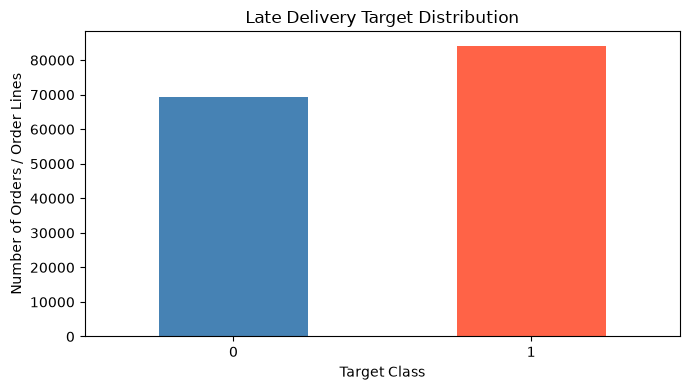

In [260]:

# ============================================================
# TARGET VARIABLE DISTRIBUTION
# ============================================================
# Objective:
# Understand the proportion of late and on-time deliveries.
#
# IMPORTANT:
# Use training data only.
# This prevents test-set information from influencing EDA.
# ============================================================

# Convert target to a Series and preserve row alignment.
target_train = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_train_refined.index,
    name="Late_Delivery"
)

# Check the target values before assuming their meaning.
print("Target values:")
print(target_train.value_counts(dropna=False))

# Calculate percentages for each target class.
target_distribution = pd.DataFrame({
    "Count": target_train.value_counts().sort_index(),
    "Percentage": (
        target_train.value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
})

display(target_distribution)

# Plot target class distribution.
plt.figure(figsize=(7, 4))

target_train.value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "tomato"]
)

plt.title("Late Delivery Target Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Orders / Order Lines")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



===== Shipping Mode =====


,Sample_Count,Late_Rate
Shipping Mode,,
First Class,23498,95.39
Second Class,29846,76.83
Same Day,8244,46.31
Standard Class,92006,38.01


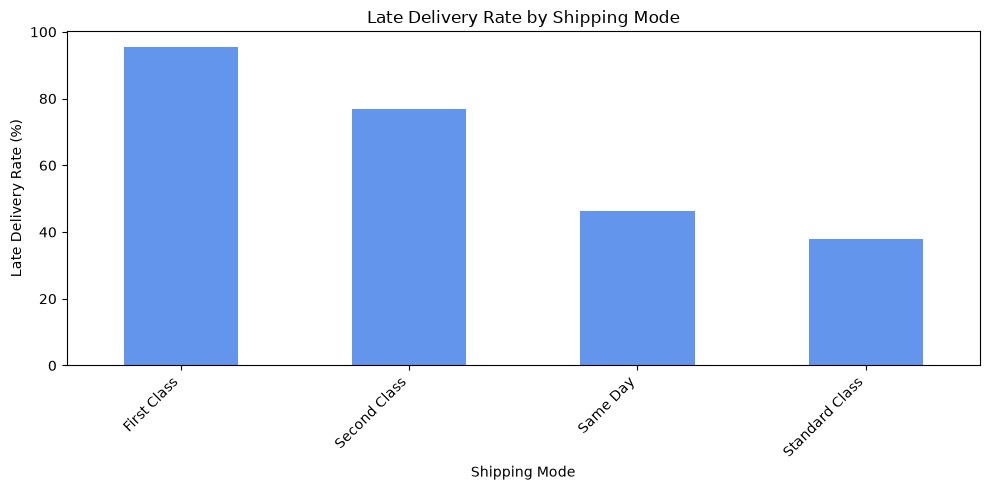


===== Days for shipment (scheduled) =====


,Sample_Count,Late_Rate
Days for shipment (scheduled),,
1,23498,95.39
2,29846,76.83
0,8244,46.31
4,92006,38.01


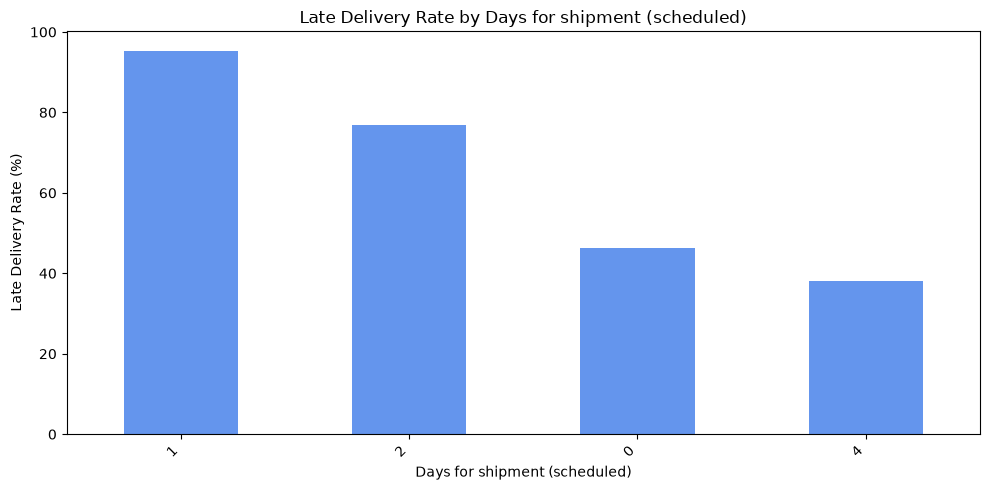


===== Customer Segment =====


,Sample_Count,Late_Rate
Customer Segment,,
Home Office,27554,55.16
Corporate,46764,54.88
Consumer,79276,54.59


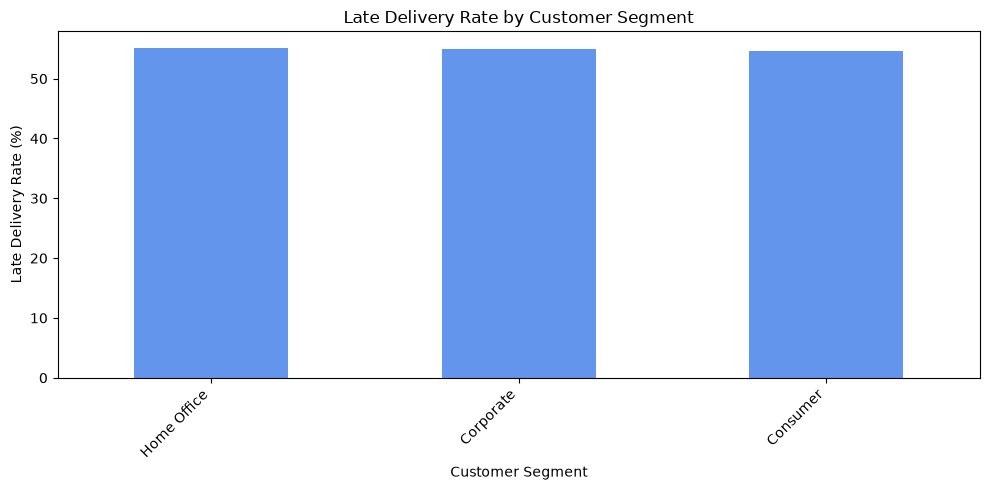


===== Order Region =====


,Sample_Count,Late_Rate
Order Region,,
Central Africa,1394,57.68
South Asia,6543,56.49
South of USA,3467,56.16
Western Europe,23116,55.84
East of USA,5850,55.62
East Africa,1578,55.39
Eastern Europe,3238,55.31
West Asia,5172,55.20
Southeast Asia,8117,54.88


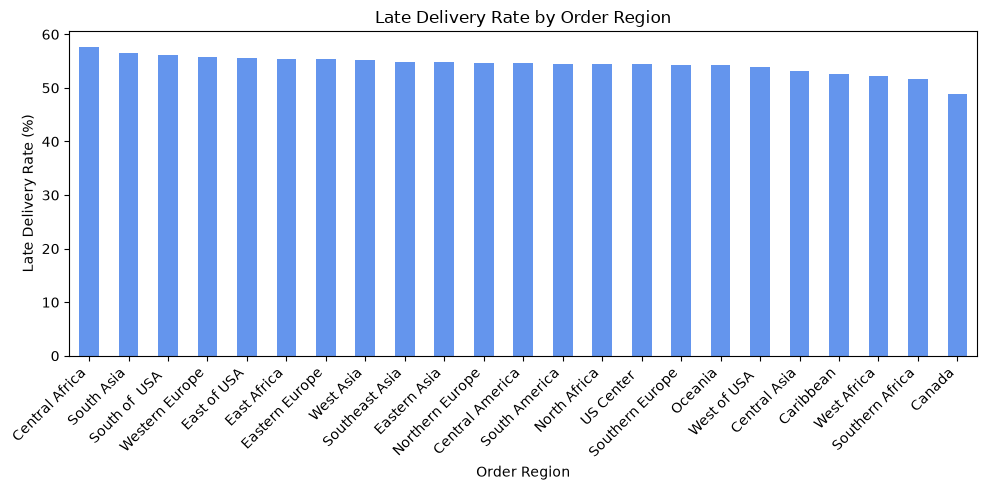


===== Market =====


,Sample_Count,Late_Rate
Market,,
Europe,42710,55.30
Pacific Asia,35279,55.02
USCA,21955,54.68
LATAM,43828,54.29
Africa,9822,54.09


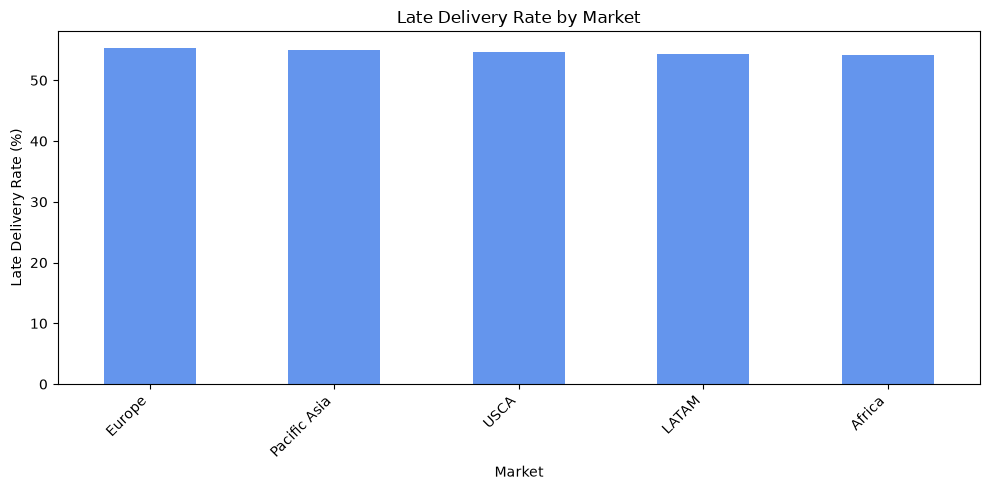

In [261]:

# ============================================================
#  LATE DELIVERY RATE BY CATEGORY
# ============================================================
# Objective:
# Explore which shipping modes, customer segments and A
# have higher observed late-delivery rates.
#
# This is descriptive EDA, not evidence of causation.A
# ============================================================

# Combine features and labels for training EDA only.
eda_train = X_train_refined.copy()
eda_train["Late_Delivery"] = target_train

# Columns to analyze.
eda_columns = [
    "Shipping Mode",
    "Days for shipment (scheduled)",
    "Customer Segment",
    "Order Region",
    "Market"
]

for column in eda_columns:

    print(f"\n===== {column} =====")

    # Calculate sample count and late-delivery percentage.
    summary = (
        eda_train.groupby(column)["Late_Delivery"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Sample_Count",
            "mean": "Late_Rate"
        })
    )

    summary["Late_Rate"] *= 100

    # Show categories ordered by highest late rate.
    summary = summary.sort_values(
        "Late_Rate", ascending=False
    )

    display(summary.round(2))

    # Plot the observed late-delivery rates.
    plt.figure(figsize=(10, 5))

    summary["Late_Rate"].plot(
        kind="bar",
        color="cornflowerblue"
    )

    plt.title(f"Late Delivery Rate by {column}")
    plt.ylabel("Late Delivery Rate (%)")
    plt.xlabel(column)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


In [262]:

# ============================================================
#  ADVANCED FEATURE ENGINEERING

# Objective:
# Create additional predictive features using information
# available when an order is placed.
#
# We apply the same deterministic transformations to
# training, validation and test datasets.
#
# No new library imports are required.
# ============================================================

def advanced_feature_engineering(X):

    # Work on a copy to preserve the original dataset.
    X = X.copy()

    # --------------------------------------------------------
    # 1. CYCLICAL TIME FEATURES
    # --------------------------------------------------------
    # Hours repeat every 24 hours, so 23:00 and 00:00
    # should be represented as nearby points.

    X["hour_sin"] = np.sin(
        2 * np.pi * X["order_hour"] / 24
    )

    X["hour_cos"] = np.cos(
        2 * np.pi * X["order_hour"] / 24
    )

    # Weekdays also follow a repeating seven-day cycle.
    X["weekday_sin"] = np.sin(
        2 * np.pi * X["order_dayofweek"] / 7
    )

    X["weekday_cos"] = np.cos(
        2 * np.pi * X["order_dayofweek"] / 7
    )

    # Quarter may capture broad seasonal effects.
    X["order_quarter"] = (
        (X["order_month"] - 1) // 3 + 1
    )

    # --------------------------------------------------------
    # 2. ORDER VALUE TRANSFORMATION
    # --------------------------------------------------------
    # Log1p reduces the influence of very large order values.
    # Clip at zero because log1p is not suitable for values
    # below -1, and order totals should be nonnegative.

    X["log_order_value"] = np.log1p(
        X["Order Item Total"].clip(lower=0)
    )

    # --------------------------------------------------------
    # 3. SHIPPING AND GEOGRAPHIC INTERACTIONS
    # --------------------------------------------------------
    # These combine two order-time categorical features.
    # They may capture patterns that vary by shipping service
    # and destination region.

    X["region_shipping_mode"] = (
        X["Order Region"].astype(str)
        + "_"
        + X["Shipping Mode"].astype(str)
    )

    X["category_shipping_mode"] = (
        X["Category Name"].astype(str)
        + "_"
        + X["Shipping Mode"].astype(str)
    )

    # --------------------------------------------------------
    # 4. ORDER VALUE PER UNIT
    # --------------------------------------------------------
    # The denominator is clipped to avoid division by zero.
    # This may be redundant with existing unit-price fields,
    # so we will evaluate its contribution later.

    X["value_per_unit"] = (
        X["Order Item Total"]
        / X["Order Item Quantity"].clip(lower=1)
    )

    # --------------------------------------------------------
    # 5. REMOVE REDUNDANT SHIPPING SCHEDULE FEATURE
    # --------------------------------------------------------
    # Shipping Mode and scheduled days appear equivalent
    # based on the EDA. We will verify exact correspondence
    # before removing the schedule feature.

    return X


# Verify whether each shipping mode maps to one scheduled day.
shipping_mapping = (
    X_train_refined.groupby("Shipping Mode")[
        "Days for shipment (scheduled)"
    ].nunique()
)

print("Unique scheduled-day values per shipping mode:")
display(shipping_mapping)

assert (shipping_mapping == 1).all(), (
    "Shipping Mode does not uniquely determine "
    "scheduled shipping days."
)

# Apply feature engineering to each split.
X_train_fe = advanced_feature_engineering(X_train_refined)
X_val_fe = advanced_feature_engineering(X_val_refined)
X_test_fe = advanced_feature_engineering(X_test_refined)

# Confirm that the same features exist in every split.
assert X_train_fe.columns.equals(X_val_fe.columns)
assert X_train_fe.columns.equals(X_test_fe.columns)

print("\nOriginal features:", X_train_refined.shape[1])
print("Engineered features:", X_train_fe.shape[1])

print("\nNew features:")
print(
    X_train_fe.columns.difference(
        X_train_refined.columns
    ).tolist()
)

print("\nFinal shapes:")
print("Train:", X_train_fe.shape)
print("Validation:", X_val_fe.shape)
print("Test:", X_test_fe.shape)


Unique scheduled-day values per shipping mode:


Shipping Mode
First Class       1
Same Day          1
Second Class      1
Standard Class    1
Name: Days for shipment (scheduled), dtype: int64


Original features: 31
Engineered features: 40

New features:
['category_shipping_mode', 'hour_cos', 'hour_sin', 'log_order_value', 'order_quarter', 'region_shipping_mode', 'value_per_unit', 'weekday_cos', 'weekday_sin']

Final shapes:
Train: (153594, 40)
Validation: (13547, 40)
Test: (13378, 40)


,count,mean,std,min,25%,50%,75%,max
hour_sin,153594.0,-0.000,0.706,-1.000,-0.707,0.000,0.707,1.000
hour_cos,153594.0,-0.000,0.708,-1.000,-0.707,-0.000,0.707,1.000
weekday_sin,153594.0,-0.002,0.707,-0.975,-0.782,0.000,0.782,0.975
weekday_cos,153594.0,-0.000,0.707,-0.901,-0.901,-0.223,0.623,1.000
order_quarter,153594.0,2.415,1.096,1.000,1.000,2.000,3.000,4.000
log_order_value,153594.0,5.011,0.684,2.139,4.658,5.106,5.515,7.561
value_per_unit,153594.0,126.948,126.255,7.490,45.000,59.990,179.990,1919.990


Engineered feature quality:


,Missing,Infinite
hour_sin,0,0
hour_cos,0,0
weekday_sin,0,0
weekday_cos,0,0
order_quarter,0,0
log_order_value,0,0
value_per_unit,0,0


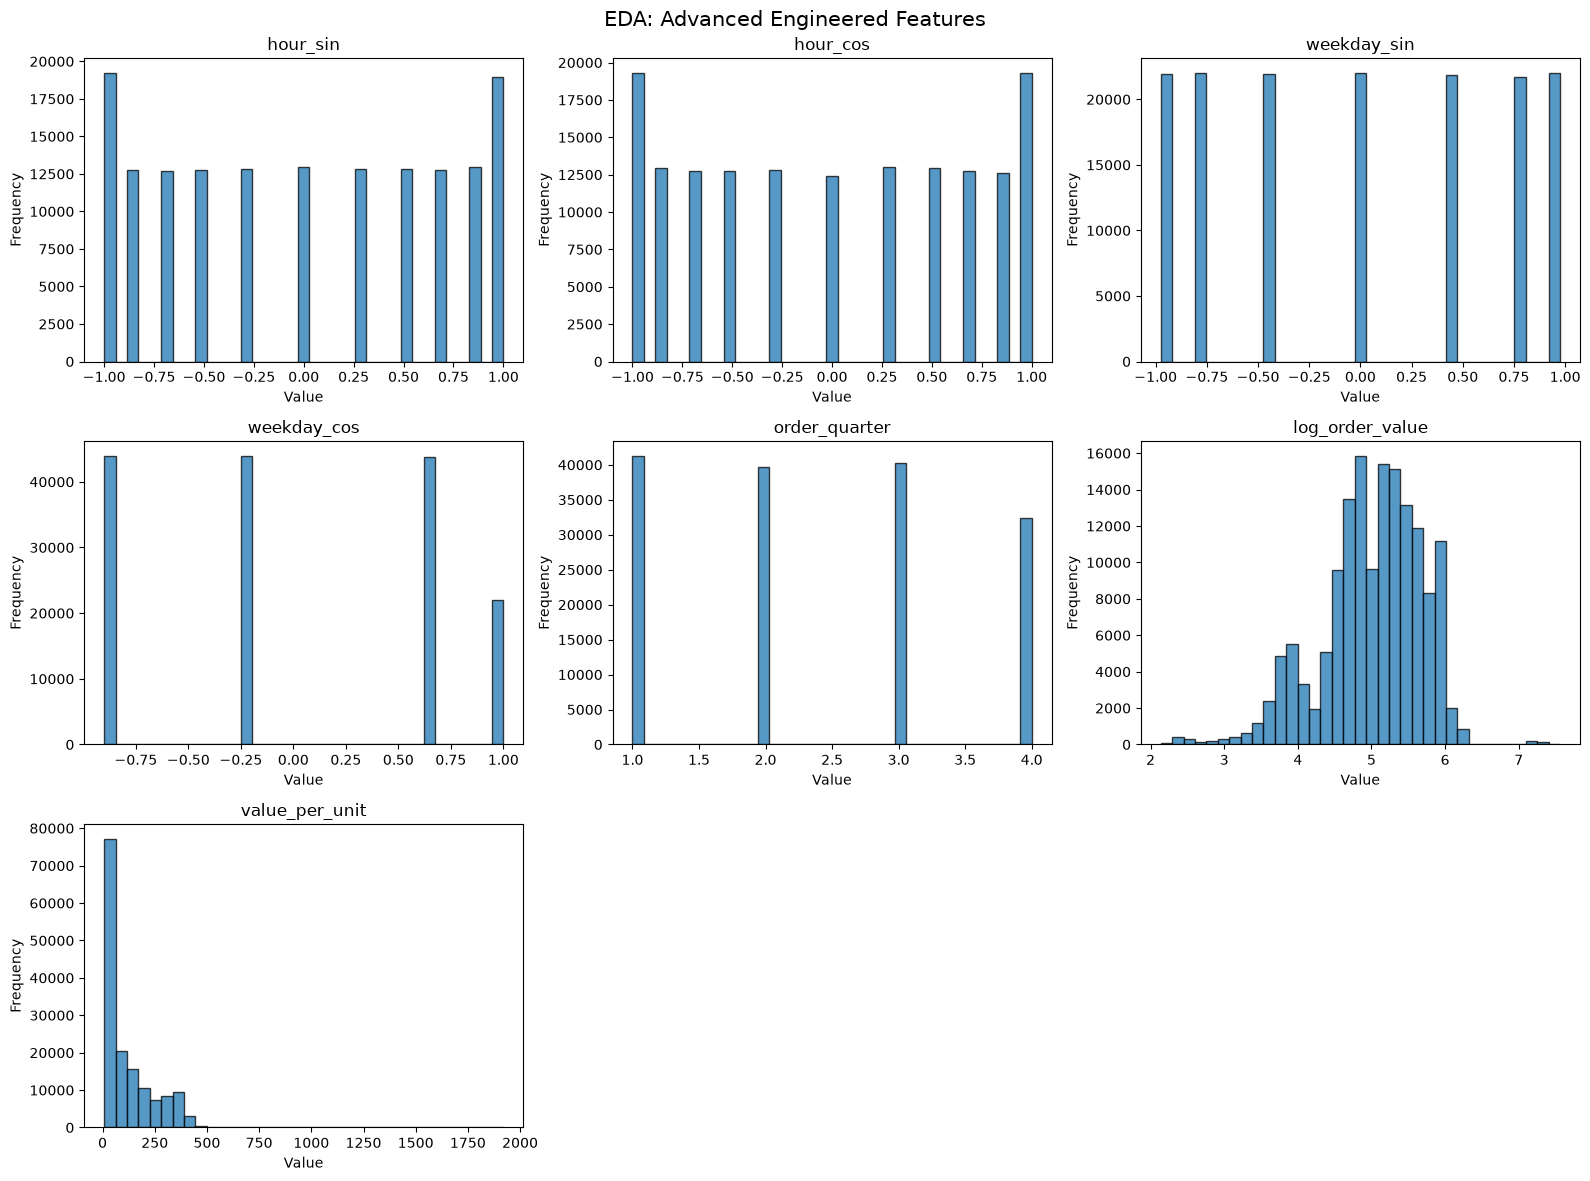

In [263]:

# ============================================================
#  ENGINEERED FEATURE EDA
# ============================================================
# Objective:
# Inspect newly generated numerical features for missing
# values, invalid values, extreme distributions and skewness.
#
# Use training data only for EDA.
# ============================================================

engineered_numeric = [
    "hour_sin",
    "hour_cos",
    "weekday_sin",
    "weekday_cos",
    "order_quarter",
    "log_order_value",
    "value_per_unit"
]

# Descriptive statistics
display(
    X_train_fe[engineered_numeric]
    .describe()
    .T
    .round(3)
)

# Check for missing or infinite values
quality_check = pd.DataFrame({
    "Missing": X_train_fe[
        engineered_numeric
    ].isna().sum(),
    "Infinite": np.isinf(
        X_train_fe[engineered_numeric]
    ).sum()
})

print("Engineered feature quality:")
display(quality_check)

# Plot distributions
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, feature in zip(axes.flat, engineered_numeric):

    ax.hist(
        X_train_fe[feature].dropna(),
        bins=35,
        edgecolor="black",
        alpha=0.75
    )

    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

for ax in axes.flat[len(engineered_numeric):]:
    ax.set_visible(False)

plt.suptitle(
    "EDA: Advanced Engineered Features",
    fontsize=15
)

plt.tight_layout()
plt.show()


Unit-price correlations:


,value_per_unit,Order Item Product Price,Order Item Total
value_per_unit,1.0000,0.9938,0.7905
Order Item Product Price,0.9938,1.0000,0.7811
Order Item Total,0.7905,0.7811,1.0000



Value per unit vs product price:
Maximum difference: 500.0
Nearly identical (%): 4.94

Train shipping-mode mapping:


Shipping Mode
First Class       1
Same Day          1
Second Class      1
Standard Class    1
Name: Days for shipment (scheduled), dtype: int64


Validation shipping-mode mapping:


Shipping Mode
First Class       1
Same Day          1
Second Class      1
Standard Class    1
Name: Days for shipment (scheduled), dtype: int64


Test shipping-mode mapping:


Shipping Mode
First Class       1
Same Day          1
Second Class      1
Standard Class    1
Name: Days for shipment (scheduled), dtype: int64


Feature consistency:
Train vs validation: True
Train vs test: True

Total missing values:
Train: 0
Validation: 0
Test: 0

Categorical feature cardinality:


,Unique_Categories
Order City,3539
Order State,1076
Customer City,563
category_shipping_mode,198
Order Country,162
Product Name,118
region_shipping_mode,92
Category Name,50
Customer State,46
Order Region,23


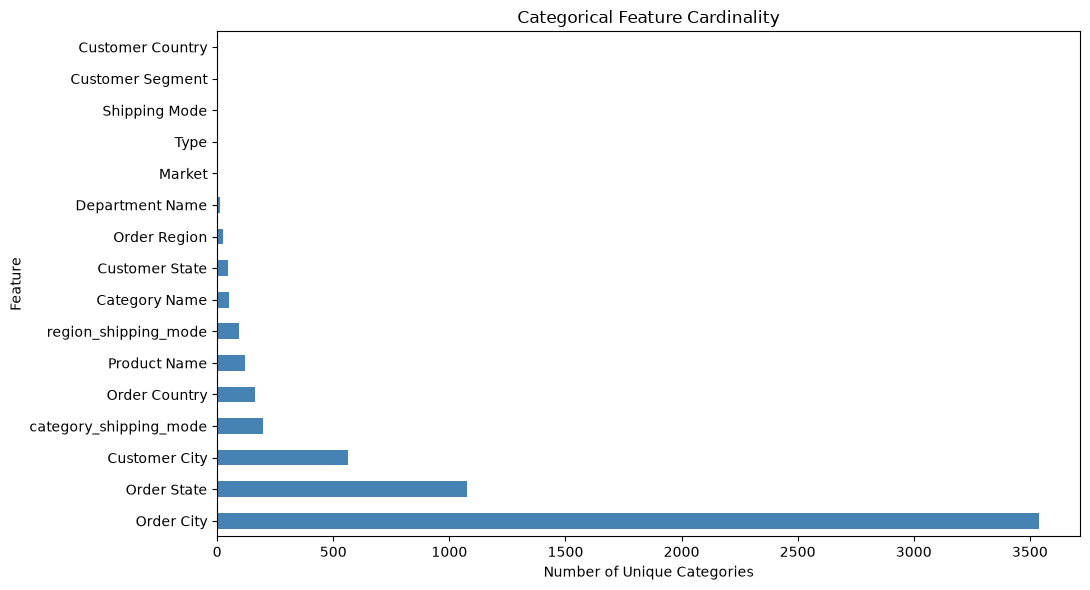

In [264]:

# ============================================================
#  FINAL FEATURE QUALITY AND REDUNDANCY AUDIT
# ============================================================
# OBJECTIVES:
# 1. Check whether value_per_unit duplicates existing prices.
# 2. Check whether Shipping Mode determines scheduled days.
# 3. Check feature consistency across train, validation, test.
# 4. Identify high-cardinality categorical features.
#
# IMPORTANT:
# No model training or feature selection on test labels.
# ============================================================

# ------------------------------------------------------------
# 1. Financial redundancy check (training data only)
# ------------------------------------------------------------

unit_price_features = [
    "value_per_unit",
    "Order Item Product Price",
    "Order Item Total"
]

print("Unit-price correlations:")
display(
    X_train_fe[unit_price_features]
    .corr()
    .round(4)
)

# Check how often value_per_unit matches the product price.
price_difference = (
    X_train_fe["value_per_unit"]
    - X_train_fe["Order Item Product Price"]
).abs()

print("\nValue per unit vs product price:")
print("Maximum difference:", price_difference.max())
print(
    "Nearly identical (%):",
    round(price_difference.le(1e-6).mean() * 100, 2)
)

# ------------------------------------------------------------
# 2. Shipping-mode redundancy check
# ------------------------------------------------------------

for split_name, dataset in [
    ("Train", X_train_fe),
    ("Validation", X_val_fe),
    ("Test", X_test_fe)
]:
    mapping = (
        dataset.groupby("Shipping Mode")[
            "Days for shipment (scheduled)"
        ].nunique()
    )

    print(f"\n{split_name} shipping-mode mapping:")
    display(mapping)

# ------------------------------------------------------------
# 3. Feature consistency and data-quality check
# ------------------------------------------------------------

print("\nFeature consistency:")
print(
    "Train vs validation:",
    X_train_fe.columns.equals(X_val_fe.columns)
)
print(
    "Train vs test:",
    X_train_fe.columns.equals(X_test_fe.columns)
)

print("\nTotal missing values:")
print("Train:", X_train_fe.isna().sum().sum())
print("Validation:", X_val_fe.isna().sum().sum())
print("Test:", X_test_fe.isna().sum().sum())

# ------------------------------------------------------------
# 4. Categorical cardinality EDA
# ------------------------------------------------------------

categorical_columns = X_train_fe.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

cardinality = (
    X_train_fe[categorical_columns]
    .nunique()
    .sort_values(ascending=False)
)

print("\nCategorical feature cardinality:")
display(cardinality.to_frame("Unique_Categories"))

# Visualize categorical cardinality.
plt.figure(figsize=(11, 6))

cardinality.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Categorical Feature Cardinality")
plt.xlabel("Number of Unique Categories")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [265]:

# ============================================================
#  FINAL FEATURE REFINEMENT
# ============================================================
# Objective:
# Remove the redundant scheduled shipping days feature.
#
# Shipping Mode uniquely determines scheduled days in all
# three datasets, so keeping both is unnecessary for our
# initial model.
#
# Preserve original engineered datasets for comparison.
# ============================================================

redundant_shipping_features = [
    "Days for shipment (scheduled)"
]

X_train_final = X_train_fe.drop(
    columns=redundant_shipping_features
).copy()

X_val_final = X_val_fe.drop(
    columns=redundant_shipping_features
).copy()

X_test_final = X_test_fe.drop(
    columns=redundant_shipping_features
).copy()

# Check feature consistency.
assert X_train_final.columns.equals(X_val_final.columns)
assert X_train_final.columns.equals(X_test_final.columns)

print("Before refinement:", X_train_fe.shape[1])
print("After refinement:", X_train_final.shape[1])

print("\nFinal shapes:")
print("Train:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

print("\nRemoved feature:")
print(redundant_shipping_features)


Before refinement: 40
After refinement: 39

Final shapes:
Train: (153594, 39)
Validation: (13547, 39)
Test: (13378, 39)

Removed feature:
['Days for shipment (scheduled)']


In [266]:

# ============================================================
# CATEGORICAL CARDINALITY ANALYSIS
# ============================================================
# Objective:
# Identify low-, medium- and high-cardinality categories.
#
# High-cardinality features can produce many columns when
# one-hot encoded, increasing memory and training time.
# ============================================================

categorical_features = X_train_final.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

cardinality_df = pd.DataFrame({
    "Feature": categorical_features,
    "Unique_Categories": [
        X_train_final[col].nunique()
        for col in categorical_features
    ]
})

# Assign cardinality groups.
def cardinality_level(n):
    if n <= 20:
        return "Low"
    elif n <= 100:
        return "Medium"
    else:
        return "High"

cardinality_df["Cardinality_Level"] = (
    cardinality_df["Unique_Categories"]
    .apply(cardinality_level)
)

cardinality_df = cardinality_df.sort_values(
    "Unique_Categories", ascending=False
)

display(cardinality_df)

print("\nHigh-cardinality features:")
display(
    cardinality_df[
        cardinality_df["Cardinality_Level"] == "High"
    ]
)


,Feature,Unique_Categories,Cardinality_Level
8,Order City,3539,High
11,Order State,1076,High
2,Customer City,563,High
15,category_shipping_mode,198,High
9,Order Country,162,High
12,Product Name,118,High
14,region_shipping_mode,92,Medium
1,Category Name,50,Medium
5,Customer State,46,Medium
10,Order Region,23,Medium



High-cardinality features:


,Feature,Unique_Categories,Cardinality_Level
8,Order City,3539,High
11,Order State,1076,High
2,Customer City,563,High
15,category_shipping_mode,198,High
9,Order Country,162,High
12,Product Name,118,High


In [267]:

# ============================================================
#  DEFINE PREPROCESSING FEATURE GROUPS
# ============================================================
# OBJECTIVE:
# Separate numerical and categorical features according to
# their appropriate preprocessing requirements.
#
# STRATEGY:
# - Numerical: imputation and scaling where appropriate.
# - Most categorical: One-Hot Encoding.
# - Three large geographic categories: Frequency Encoding.
#
# IMPORTANT:
# All learned transformations will be fitted on TRAINING
# data only. Validation and test must remain unseen.
# ============================================================

# 1. Identify categorical columns.
categorical_cols = X_train_final.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# 2. Identify numerical columns.
numerical_cols = X_train_final.select_dtypes(
    include=["number"]
).columns.tolist()

# 3. High-cardinality geographical features.
frequency_cols = [
    "Order City",
    "Order State",
    "Customer City"
]

# 4. Remaining categorical features use One-Hot Encoding.
onehot_cols = [
    col for col in categorical_cols
    if col not in frequency_cols
]

# 5. Display selected feature groups.
print("Numerical features:", len(numerical_cols))
print("One-Hot Encoding features:", len(onehot_cols))
print("Frequency Encoding features:", len(frequency_cols))

print("\nFrequency Encoding columns:")
print(frequency_cols)

print("\nOne-Hot Encoding columns:")
print(onehot_cols)

# 6. Check that every feature belongs to exactly one group.
all_grouped_cols = numerical_cols + onehot_cols + frequency_cols

assert len(all_grouped_cols) == len(set(all_grouped_cols)), (
    "Some columns appear in multiple preprocessing groups."
)

assert set(all_grouped_cols) == set(X_train_final.columns), (
    "Some features are missing from preprocessing groups."
)

print("\nFeature grouping validation: PASSED")


Numerical features: 23
One-Hot Encoding features: 13
Frequency Encoding features: 3

Frequency Encoding columns:
['Order City', 'Order State', 'Customer City']

One-Hot Encoding columns:
['Type', 'Category Name', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order Country', 'Order Region', 'Product Name', 'Shipping Mode', 'region_shipping_mode', 'category_shipping_mode']

Feature grouping validation: PASSED



===== Order City =====
Total unique categories: 3539


,Frequency
Order City,
New York City,1856
Santo Domingo,1837
Los Angeles,1570
Tegucigalpa,1519
Managua,1370
Mexico City,1311
Manila,1163
San Francisco,1116
Philadelphia,1067


Top 10 category coverage: 9.0 %


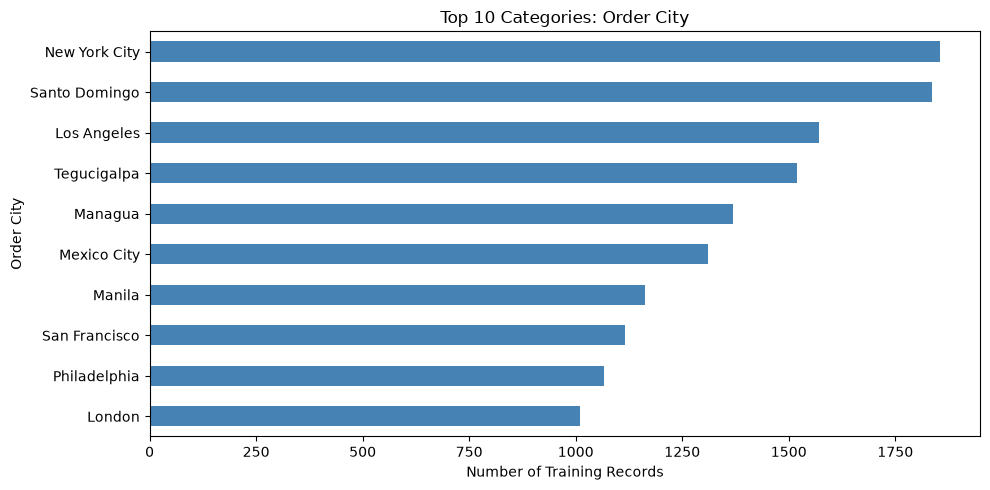


===== Order State =====
Total unique categories: 1076


,Frequency
Order State,
Inglaterra,5802
California,4245
Isla de Francia,3837
Renania del Norte-Westfalia,2810
San Salvador,2538
Nueva York,2326
Distrito Federal,2248
Texas,2096
Nueva Gales del Sur,2018


Top 10 category coverage: 19.42 %


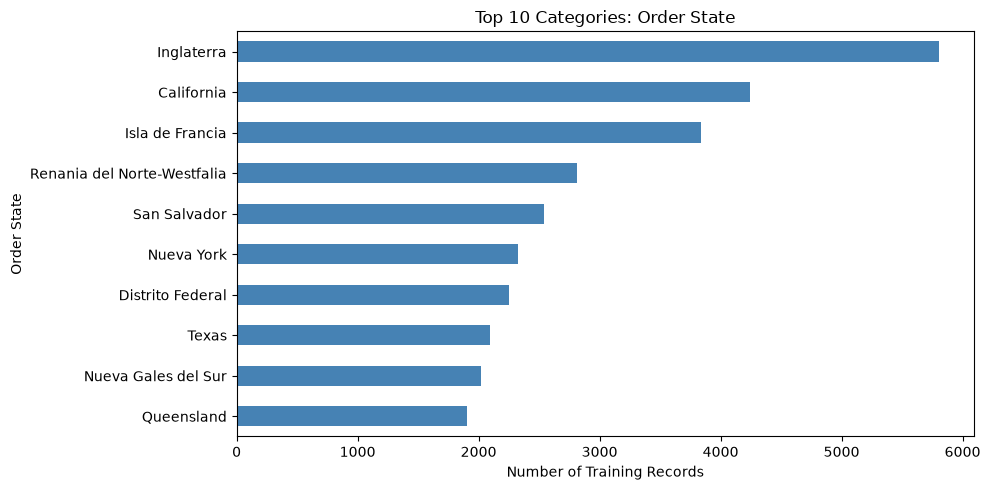


===== Customer City =====
Total unique categories: 563


,Frequency
Customer City,
Caguas,56582
Chicago,3282
Los Angeles,2966
Brooklyn,2924
New York,1534
Philadelphia,1317
Bronx,1293
San Diego,1274
Houston,1126


Top 10 category coverage: 47.8 %


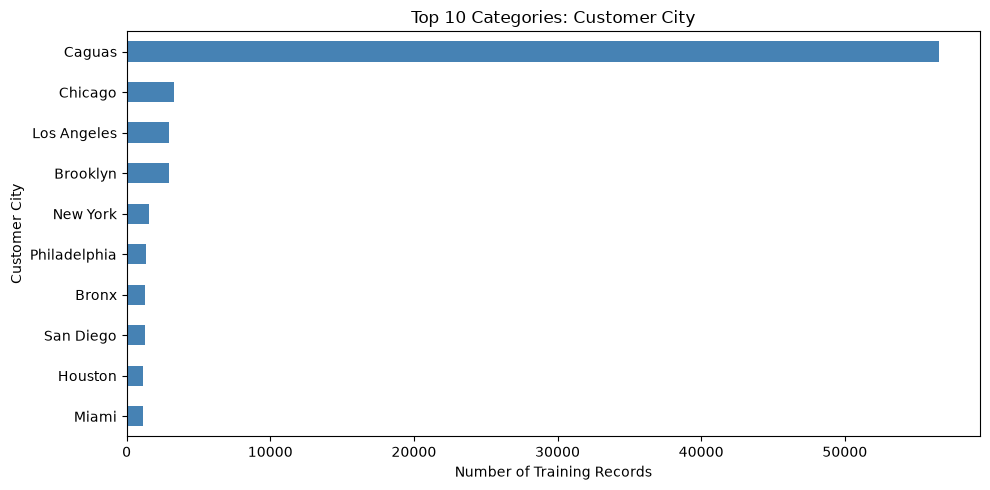

In [268]:

# ============================================================
# HIGH-CARDINALITY CATEGORICAL EDA
# ============================================================
# OBJECTIVE:
# Understand whether geographic categories are concentrated
# in a few common locations or spread across rare locations.
#
# This helps justify the encoding strategy.
#
# We use training data only.
# ============================================================

for column in frequency_cols:

    print(f"\n===== {column} =====")

    # Count the number of records for each category.
    category_counts = X_train_final[
        column
    ].value_counts(dropna=False)

    # Display the 10 most frequent categories.
    print("Total unique categories:", category_counts.shape[0])

    display(
        category_counts.head(10).to_frame("Frequency")
    )

    # Calculate how much of the dataset the top 10 cover.
    top_10_percentage = (
        category_counts.head(10).sum()
        / len(X_train_final) * 100
    )

    print(
        "Top 10 category coverage:",
        round(top_10_percentage, 2), "%"
    )

    # Visualize the most common categories.
    plt.figure(figsize=(10, 5))

    category_counts.head(10).sort_values().plot(
        kind="barh",
        color="steelblue"
    )

    plt.title(f"Top 10 Categories: {column}")
    plt.xlabel("Number of Training Records")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()


In [269]:

# ============================================================
# FREQUENCY ENCODING
# ============================================================
# OBJECTIVE:
# Convert high-cardinality categorical features into
# numerical values without creating thousands of columns.
#
# METHOD:
# Frequency = Number of occurrences / Training row count
#
# IMPORTANT:
# 1. Learn frequencies from TRAINING data only.
# 2. Apply the same mappings to validation and test.
# 3. Assign unseen categories a frequency of 0.
# 4. Preserve the original datasets for comparison.
# ============================================================

# Create independent copies.
X_train_encoded = X_train_final.copy()
X_val_encoded = X_val_final.copy()
X_test_encoded = X_test_final.copy()

# Store learned mappings for future inference.
frequency_mappings = {}

for column in frequency_cols:

    # Calculate relative frequencies from training data.
    frequency_map = (
        X_train_final[column]
        .value_counts(normalize=True, dropna=False)
    )

    # Save the training-derived mapping.
    frequency_mappings[column] = frequency_map

    # Replace categories with their relative frequencies.
    X_train_encoded[column + "_freq"] = (
        X_train_final[column]
        .map(frequency_map)
        .fillna(0)
    )

    X_val_encoded[column + "_freq"] = (
        X_val_final[column]
        .map(frequency_map)
        .fillna(0)
    )

    X_test_encoded[column + "_freq"] = (
        X_test_final[column]
        .map(frequency_map)
        .fillna(0)
    )

# Remove original high-cardinality text columns.
X_train_encoded.drop(
    columns=frequency_cols, inplace=True
)

X_val_encoded.drop(
    columns=frequency_cols, inplace=True
)

X_test_encoded.drop(
    columns=frequency_cols, inplace=True
)

# Confirm feature consistency.
assert X_train_encoded.columns.equals(X_val_encoded.columns)
assert X_train_encoded.columns.equals(X_test_encoded.columns)

print("Frequency encoding completed!")

print("\nTraining shape:", X_train_encoded.shape)
print("Validation shape:", X_val_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

print("\nNew frequency features:")
print([col + "_freq" for col in frequency_cols])


Frequency encoding completed!

Training shape: (153594, 39)
Validation shape: (13547, 39)
Testing shape: (13378, 39)

New frequency features:
['Order City_freq', 'Order State_freq', 'Customer City_freq']


,count,mean,std,min,25%,50%,75%,max
Order City_freq,153594.0,0.00203,0.00280,0.00001,0.00026,0.00074,0.00265,0.01208
Order State_freq,153594.0,0.00714,0.00900,0.00001,0.00123,0.00343,0.00989,0.03777
Customer City_freq,153594.0,0.13819,0.17586,0.00002,0.00107,0.00546,0.36839,0.36839



===== Train =====
Order City_freq: Missing=0, Invalid=0, Zero/Unseen=0.00%
Order State_freq: Missing=0, Invalid=0, Zero/Unseen=0.00%
Customer City_freq: Missing=0, Invalid=0, Zero/Unseen=0.00%

===== Validation =====
Order City_freq: Missing=0, Invalid=0, Zero/Unseen=0.71%
Order State_freq: Missing=0, Invalid=0, Zero/Unseen=0.19%
Customer City_freq: Missing=0, Invalid=0, Zero/Unseen=0.00%

===== Test =====
Order City_freq: Missing=0, Invalid=0, Zero/Unseen=0.79%
Order State_freq: Missing=0, Invalid=0, Zero/Unseen=0.09%
Customer City_freq: Missing=0, Invalid=0, Zero/Unseen=0.00%


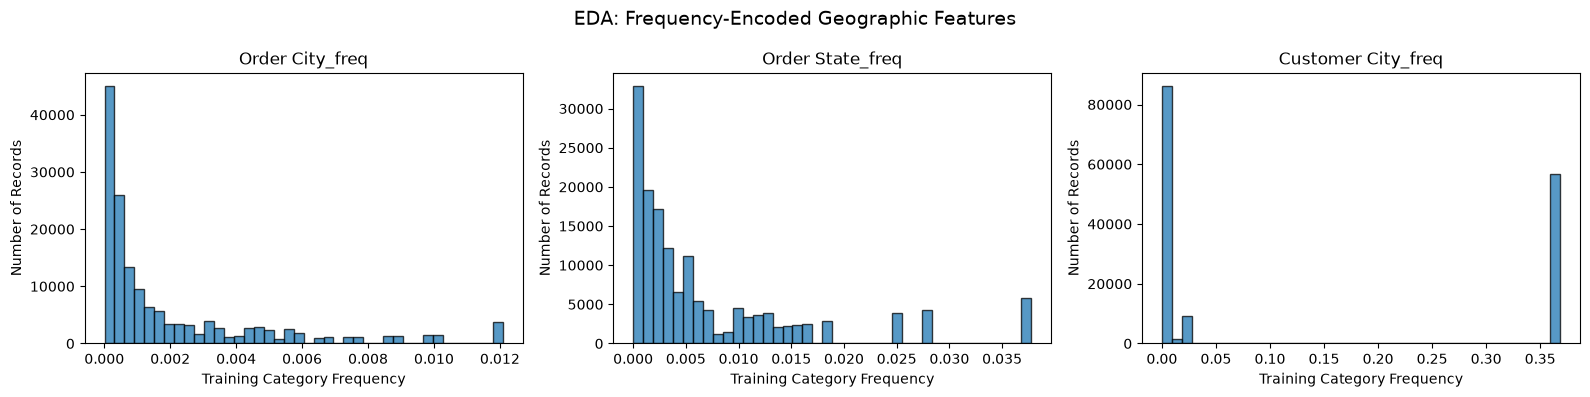

In [270]:

# ============================================================
# FREQUENCY ENCODING QUALITY CHECK + EDA
# ============================================================
# OBJECTIVE:
# 1. Verify encoded features contain valid values.
# 2. Inspect their distributions.
# 3. Check unseen-category rates in validation and test.
#
# Frequency values should fall between 0 and 1.
# ============================================================

frequency_feature_names = [
    col + "_freq" for col in frequency_cols
]

# Descriptive statistics.
display(
    X_train_encoded[frequency_feature_names]
    .describe()
    .T
    .round(5)
)

# Quality checks.
for split_name, dataset in [
    ("Train", X_train_encoded),
    ("Validation", X_val_encoded),
    ("Test", X_test_encoded)
]:

    print(f"\n===== {split_name} =====")

    for feature in frequency_feature_names:

        missing = dataset[feature].isna().sum()

        invalid = (
            ~dataset[feature].between(0, 1)
        ).sum()

        unseen_rate = (
            dataset[feature].eq(0).mean() * 100
        )

        print(
            f"{feature}: "
            f"Missing={missing}, "
            f"Invalid={invalid}, "
            f"Zero/Unseen={unseen_rate:.2f}%"
        )

# Plot encoded feature distributions.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, frequency_feature_names):

    ax.hist(
        X_train_encoded[feature],
        bins=40,
        edgecolor="black",
        alpha=0.75
    )

    ax.set_title(feature)
    ax.set_xlabel("Training Category Frequency")
    ax.set_ylabel("Number of Records")

plt.suptitle(
    "EDA: Frequency-Encoded Geographic Features",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [271]:

# ============================================================
# ONE-HOT ENCODING AND NUMERICAL SCALING
# ============================================================
# OBJECTIVE:
# 1. Encode the remaining categorical variables.
# 2. Scale numerical features for linear models.
# 3. Keep numerical features unscaled for tree models.
# 4. Fit preprocessing on training data only.
#
# IMPORTANT:
# X_train_encoded, X_val_encoded and X_test_encoded
# already contain the three frequency-encoded columns.
#
# Do not modify the original datasets.
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# 1. Identify numerical and categorical features
# ------------------------------------------------------------

numeric_cols = X_train_encoded.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train_encoded.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

# ------------------------------------------------------------
# 2. Create numerical preprocessing for linear models
# ------------------------------------------------------------
# Median imputation handles future missing numerical values.
# StandardScaler makes numerical features comparable in scale.

linear_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# ------------------------------------------------------------
# 3. Create numerical preprocessing for tree models
# ------------------------------------------------------------
# Trees do not normally require StandardScaler.

tree_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# ------------------------------------------------------------
# 4. Create categorical preprocessing
# ------------------------------------------------------------
# infrequent_if_exist handles categories not observed
# during training.
#
# min_frequency=50 groups categories occurring fewer
# than 50 times into an infrequent category.
#
# sparse_output=True reduces memory requirements.

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=50,
        sparse_output=True
    ))
])

# ------------------------------------------------------------
# 5. Linear-model preprocessing
# ------------------------------------------------------------

linear_preprocessor = ColumnTransformer(
    transformers=[
        ("num", linear_numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ],
    sparse_threshold=1.0
)

# ------------------------------------------------------------
# 6. Tree-model preprocessing
# ------------------------------------------------------------

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", tree_numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ],
    sparse_threshold=1.0
)

# ------------------------------------------------------------
# 7. Fit on training data only
# ------------------------------------------------------------

X_train_linear = linear_preprocessor.fit_transform(
    X_train_encoded
)

X_val_linear = linear_preprocessor.transform(
    X_val_encoded
)

X_train_tree = tree_preprocessor.fit_transform(
    X_train_encoded
)

X_val_tree = tree_preprocessor.transform(
    X_val_encoded
)

# ------------------------------------------------------------
# 8. Display transformed matrix shapes
# ------------------------------------------------------------

print("\nLinear preprocessing:")
print("Train:", X_train_linear.shape)
print("Validation:", X_val_linear.shape)

print("\nTree preprocessing:")
print("Train:", X_train_tree.shape)
print("Validation:", X_val_tree.shape)

print("\nPreprocessing completed successfully!")


Numerical features: 26
Categorical features: 13

Linear preprocessing:
Train: (153594, 611)
Validation: (13547, 611)

Tree preprocessing:
Train: (153594, 611)
Validation: (13547, 611)

Preprocessing completed successfully!


In [272]:

# ============================================================
#  PREPROCESSING QUALITY CHECKS
# ============================================================
# OBJECTIVE:
# Verify that transformed matrices are suitable for
# machine learning algorithms.
#
# Checks:
# - Matching feature counts
# - Missing values
# - Infinite values
# - Sparse/dense matrix format
# ============================================================

from scipy import sparse

processed_matrices = {
    "Train Linear": X_train_linear,
    "Validation Linear": X_val_linear,
    "Train Tree": X_train_tree,
    "Validation Tree": X_val_tree
}

for name, matrix in processed_matrices.items():

    # Sparse matrices store only nonzero entries.
    # Dense matrices store every entry.
    if sparse.issparse(matrix):
        values = matrix.data
        matrix_type = "Sparse"
    else:
        values = np.asarray(matrix)
        matrix_type = "Dense"

    missing_count = np.isnan(values).sum()
    infinite_count = np.isinf(values).sum()

    print(f"\n{name}")
    print("Shape:", matrix.shape)
    print("Format:", matrix_type)
    print("Missing values:", missing_count)
    print("Infinite values:", infinite_count)

    assert missing_count == 0
    assert infinite_count == 0

# Verify matching feature counts.
assert X_train_linear.shape[1] == X_val_linear.shape[1]
assert X_train_tree.shape[1] == X_val_tree.shape[1]

print("\nAll preprocessing checks passed!")



Train Linear
Shape: (153594, 611)
Format: Sparse
Missing values: 0
Infinite values: 0

Validation Linear
Shape: (13547, 611)
Format: Sparse
Missing values: 0
Infinite values: 0

Train Tree
Shape: (153594, 611)
Format: Sparse
Missing values: 0
Infinite values: 0

Validation Tree
Shape: (13547, 611)
Format: Sparse
Missing values: 0
Infinite values: 0

All preprocessing checks passed!


Total encoded features: 611
Constant features: 0
Features with variance below 0.001: 139

15 features with lowest variance:


,Feature,Variance
0,num__Order City_freq,0.000008
1,num__Order State_freq,0.000081
2,cat__region_shipping_mode_infrequent_sklearn,0.000189
3,cat__Customer State_infrequent_sklearn,0.000241
4,cat__category_shipping_mode_Hunting & Shooting...,0.000325
5,cat__Order Country_Yemen,0.000325
6,cat__Product Name_The North Face Women's Recon...,0.000325
7,cat__Product Name_Nike Men's Kobe IX Elite Low...,0.000325
8,cat__Category Name_Golf Bags & Carts,0.000332
9,cat__region_shipping_mode_Central Asia_First C...,0.000332



15 features with highest variance:


,Feature,Variance
596,num__shipping_year,0.691741
597,num__order_quarter,1.201605
598,num__Order Item Quantity,2.112003
599,num__order_dayofweek,4.005035
600,num__Order_ID_Range,8.246895
601,num__order_month,11.000000
602,num__order_hour,23.000000
603,num__order_day,30.000000
604,num__Latitude,82.719486
605,num__Longitude,273.289062


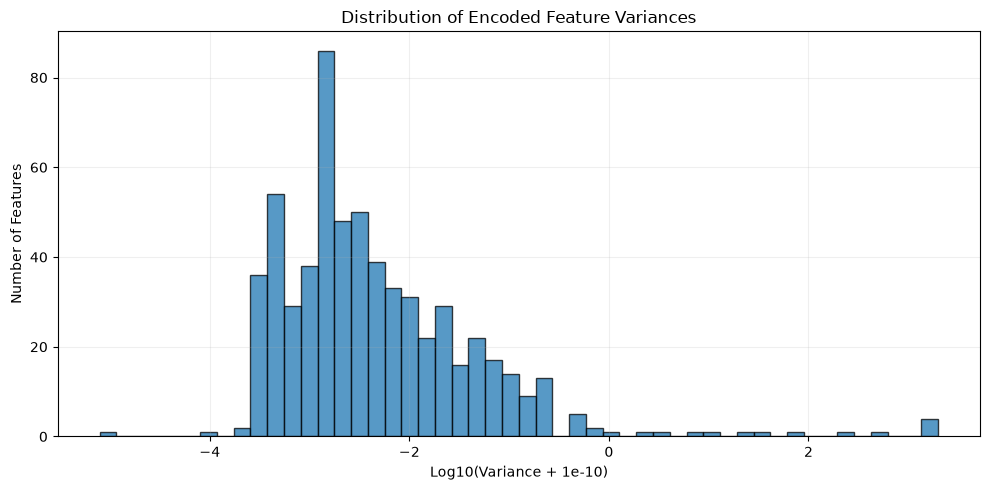

In [273]:

# ============================================================
#  VARIANCE-BASED FEATURE ANALYSIS
# ============================================================
# OBJECTIVE:
# 1. Identify constant or low-variance features.
# 2. Visualize the variance distribution.
# 3. Inspect which encoded features have low variance.
#
# IMPORTANT:
# We use X_train_tree because its numerical features
# have not been standardized.
#
# Do not remove features yet.
# ============================================================

from sklearn.feature_selection import VarianceThreshold

# Get the names of the 609 transformed features.
feature_names = tree_preprocessor.get_feature_names_out()

# Calculate the variance of each training feature.
variance_selector = VarianceThreshold(threshold=0.0)

variance_selector.fit(X_train_tree)

feature_variances = variance_selector.variances_

# Create a DataFrame for analysis.
variance_df = pd.DataFrame({
    "Feature": feature_names,
    "Variance": feature_variances
})

# Sort from lowest variance to highest variance.
variance_df = variance_df.sort_values(
    "Variance",
    ascending=True
).reset_index(drop=True)

# Identify constant and near-constant features.
constant_count = (variance_df["Variance"] == 0).sum()

low_variance_count = (
    variance_df["Variance"] < 0.001
).sum()

print("Total encoded features:", len(feature_names))
print("Constant features:", constant_count)
print("Features with variance below 0.001:",
      low_variance_count)

print("\n15 features with lowest variance:")
display(variance_df.head(15))

print("\n15 features with highest variance:")
display(variance_df.tail(15))

# ------------------------------------------------------------
# EDA: Plot variance distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

# Add a small constant for logarithmic visualization.
plt.hist(
    np.log10(feature_variances + 1e-10),
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.title("Distribution of Encoded Feature Variances")
plt.xlabel("Log10(Variance + 1e-10)")
plt.ylabel("Number of Features")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [274]:

# ============================================================
#  REMOVE ZERO-VARIANCE FEATURES
# ============================================================
# OBJECTIVE:
# Remove features that are constant in training data.
#
# The selector is fitted ONLY on training data.
# The same selected columns are applied to validation.
# ============================================================

from sklearn.base import clone

# Create independent selectors for linear and tree data.
linear_variance_selector = VarianceThreshold(
    threshold=0.0
)

tree_variance_selector = VarianceThreshold(
    threshold=0.0
)

# Fit on training data only.
X_train_linear_vt = (
    linear_variance_selector.fit_transform(
        X_train_linear
    )
)

X_train_tree_vt = (
    tree_variance_selector.fit_transform(
        X_train_tree
    )
)

# Apply learned selections to validation data.
X_val_linear_vt = (
    linear_variance_selector.transform(
        X_val_linear
    )
)

X_val_tree_vt = (
    tree_variance_selector.transform(
        X_val_tree
    )
)

# Preserve names of retained features.
selected_feature_names = feature_names[
    tree_variance_selector.get_support()
]

print("Original feature count:", len(feature_names))

print("\nLinear model features:")
print("Train:", X_train_linear_vt.shape)
print("Validation:", X_val_linear_vt.shape)

print("\nTree model features:")
print("Train:", X_train_tree_vt.shape)
print("Validation:", X_val_tree_vt.shape)

print("\nRemoved features:",
      len(feature_names) - len(selected_feature_names))

print("\nVariance-based filtering completed!")


Original feature count: 611

Linear model features:
Train: (153594, 611)
Validation: (13547, 611)

Tree model features:
Train: (153594, 611)
Validation: (13547, 611)

Removed features: 0

Variance-based filtering completed!


In [275]:

# Check whether the original features are constant
for name, X in [
    ("Training", X_train_encoded),
    ("Validation", X_val_encoded)
]:
    print(f"\n{name} data:")

    for col in ["same_country", "order_id_group"]:
        if col in X.columns:
            print(f"\n{col}")
            print("Unique values:", X[col].nunique(dropna=False))
            print(X[col].value_counts(dropna=False).head())
        else:
            print(f"{col}: not found in this dataset")



Training data:
same_country: not found in this dataset
order_id_group: not found in this dataset

Validation data:
same_country: not found in this dataset
order_id_group: not found in this dataset


Total features evaluated: 611

Top 20 features by Mutual Information:


,Feature,MI_Score
0,cat__Shipping Mode_Standard Class,0.084708
1,cat__Shipping Mode_First Class,0.072764
2,num__Latitude,0.051872
3,num__Longitude,0.027991
4,cat__Shipping Mode_Second Class,0.023267
5,cat__region_shipping_mode_Western Europe_First...,0.010480
6,cat__region_shipping_mode_Central America_Firs...,0.009839
7,cat__category_shipping_mode_Cleats_First Class,0.009568
8,cat__category_shipping_mode_Men's Footwear_Fir...,0.009178
9,cat__category_shipping_mode_Women's Apparel_Fi...,0.007883



Features with zero estimated MI: 9


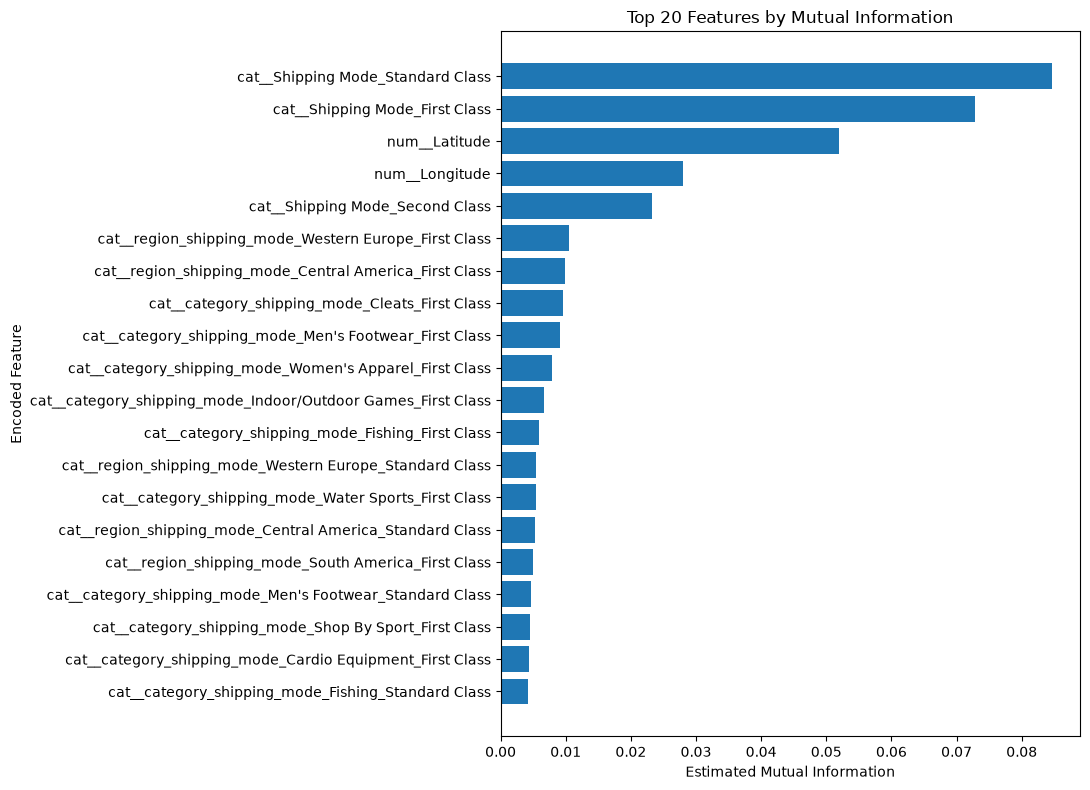

In [276]:

# ============================================================
#  FIXED MUTUAL INFORMATION FEATURE ANALYSIS
# ============================================================
# Fix:
# Convert only the sampled sparse matrix to dense.
# This allows continuous and discrete features together.
# ============================================================

from sklearn.feature_selection import mutual_info_classif

# 1. Select a reproducible sample from training data.
sample_size = min(30000, X_train_tree.shape[0])

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_train_tree.shape[0],
    size=sample_size,
    replace=False
)

X_mi_sample = X_train_tree[sample_indices]

y_mi_sample = np.asarray(y_train).ravel()[sample_indices]

# 2. Convert ONLY the sample to dense.
# float32 reduces memory usage compared with float64.
X_mi_dense = X_mi_sample.toarray().astype(
    np.float32
)

# 3. Identify discrete one-hot features.
feature_names = tree_preprocessor.get_feature_names_out()

discrete_mask = np.array([
    name.startswith("cat__")
    for name in feature_names
])

# 4. Calculate Mutual Information scores.
mi_scores = mutual_info_classif(
    X_mi_dense, 
    y_mi_sample, 
    discrete_features=discrete_mask, 
    random_state=42, 
    n_neighbors=3
)

# 5. Rank the features.
mi_df = pd.DataFrame({
    "Feature": feature_names,
    "MI_Score": mi_scores
}).sort_values(
    "MI_Score",
    ascending=False
).reset_index(drop=True)

print("Total features evaluated:", len(mi_df))

print("\nTop 20 features by Mutual Information:")
display(mi_df.head(20))

print("\nFeatures with zero estimated MI:",
      (mi_df["MI_Score"] == 0).sum())

# 6. Visualize the top 20 features.
top20 = mi_df.head(20).sort_values("MI_Score")

plt.figure(figsize=(11, 8))

plt.barh(
    top20["Feature"],
    top20["MI_Score"]
)

plt.title("Top 20 Features by Mutual Information")
plt.xlabel("Estimated Mutual Information")
plt.ylabel("Encoded Feature")

plt.tight_layout()
plt.show()


In [277]:

# ============================================================
#  CREATE MUTUAL INFORMATION FEATURE SUBSETS
# ============================================================
# OBJECTIVE:
# Compare different numbers of selected features.
#
# IMPORTANT:
# Feature rankings were learned from training data only.
# Apply the same selected indices to validation data.
#
# Keep the full-feature matrices as our baseline.
# ============================================================

# Recover feature names in the original matrix order.
feature_names = tree_preprocessor.get_feature_names_out()

# Map each feature name to its original column index.
feature_index_map = {
    name: index
    for index, name in enumerate(feature_names)
}

# Define candidate subset sizes.
subset_sizes = [30, 60, 100, 200]

# Store selected matrices.
mi_feature_subsets = {}

for k in subset_sizes:

    # Get top-k feature names from MI ranking.
    top_features = mi_df.head(k)["Feature"].tolist()

    # Convert names into original matrix indices.
    selected_indices = [
        feature_index_map[name]
        for name in top_features
    ]

    # Sort indices to preserve original feature order.
    selected_indices = sorted(selected_indices)

    # Apply identical columns to train and validation.
    mi_feature_subsets[k] = {
        "X_train_linear": X_train_linear[:, selected_indices],
        "X_val_linear": X_val_linear[:, selected_indices],
        "X_train_tree": X_train_tree[:, selected_indices],
        "X_val_tree": X_val_tree[:, selected_indices],
        "feature_names": feature_names[selected_indices]
    }

    print(
        f"Top {k} features:",
        mi_feature_subsets[k]["X_train_tree"].shape
    )

print("\nFull feature baseline:", X_train_tree.shape)
print("Feature subset creation completed!")


Top 30 features: (153594, 30)
Top 60 features: (153594, 60)
Top 100 features: (153594, 100)
Top 200 features: (153594, 200)

Full feature baseline: (153594, 611)
Feature subset creation completed!


# INTERPRETATION: 5-FOLD CROSS-VALIDATION FOR FEATURE SELECTION

 This experiment evaluates the effect of different feature subset sizes
(100, 200, 305, 400, and 609 features) on late-delivery risk prediction.

#StratifiedGroupKFold is used to create five folds while attempting to preserve class proportions and prevent the same group from appearing in both training and validation sets within a fold.

Within each fold, a Random Forest model ranks features according to their importance scores. Separate Random Forest models are then trained using the top-ranked features for each specified feature count.

 Model performance is evaluated using F1-score, Recall, and ROC-AUC.
 These metrics are recorded for each fold to compare predictive performance across different feature subset sizes.

The mean cross-validation scores can help identify a suitable featurecount that balances predictive performance and model complexity.

NOTE: The best feature count should be selected based on the aggregatedcross-validation results rather than a single fold. Preprocessing must be fitted within each fold to avoid data leakage. If preprocessing was already fitted before cross-validation, this must also be addressed.

In [278]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score, roc_auc_score

# ======================================================
# 5-FOLD CROSS-VALIDATION FOR FEATURE SELECTION
# ======================================================

feature_counts = [100, 200, 305, 400, 609]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_train_encoded, y_train, groups_train), 1
):

    print(f"\nProcessing Fold {fold}/5")

    X_fold_train = X_train_encoded.iloc[train_idx]
    X_fold_val = X_train_encoded.iloc[valid_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[valid_idx]

    # Refit preprocessing within each fold
    preprocessor = clone(tree_preprocessor)

    X_tr = preprocessor.fit_transform(X_fold_train)
    X_v = preprocessor.transform(X_fold_val)

    # Fit feature-ranking model on fold training data
    selector_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )

    selector_model.fit(X_tr, y_fold_train)

    ranked_idx = np.argsort(
        selector_model.feature_importances_
    )[::-1]

    for requested_k in feature_counts:

        # Encoded feature count can vary across folds
        k = min(requested_k, X_tr.shape[1])
        selected_idx = ranked_idx[:k]

        X_tr_k = X_tr[:, selected_idx]
        X_v_k = X_v[:, selected_idx]

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_tr_k, y_fold_train)

        predictions = model.predict(X_v_k)
        probabilities = model.predict_proba(X_v_k)[:, 1]

        cv_results.append({
            "Fold": fold,
            "Requested Features": requested_k,
            "Actual Features": k,
            "F1": f1_score(y_fold_val, predictions),
            "Recall": recall_score(y_fold_val, predictions),
            "ROC-AUC": roc_auc_score(
                y_fold_val, probabilities
            )
        })

cv_df = pd.DataFrame(cv_results)




Processing Fold 1/5

Processing Fold 2/5

Processing Fold 3/5

Processing Fold 4/5


In [279]:
cv_summary = cv_df.groupby("Requested Features").agg(
    Mean_F1=("F1", "mean"),
    Std_F1=("F1", "std"),
    Mean_Recall=("Recall", "mean"),
    Mean_ROC_AUC=("ROC-AUC", "mean"),
    Std_ROC_AUC=("ROC-AUC", "std"),
    Mean_Actual_Features=("Actual Features", "mean")
).reset_index()

display(cv_summary.round(4))


,Requested Features,Mean_F1,Std_F1,Mean_Recall,Mean_ROC_AUC,Std_ROC_AUC,Mean_Actual_Features
0,100,0.6950,0.0085,0.5843,0.7673,0.0073,100.0
1,200,0.6950,0.0085,0.5843,0.7583,0.0063,200.0
2,305,0.6950,0.0085,0.5843,0.7462,0.0072,305.0
3,400,0.6947,0.0087,0.5843,0.7411,0.0079,400.0
4,609,0.6927,0.0068,0.5843,0.7383,0.0062,563.4


In [280]:
# INTERPRETATION: CROSS-VALIDATION FEATURE SELECTION RESULTS
#
# The results compare Random Forest models using 100, 200, 305, 400,
# and 611 requested features across five cross-validation folds.
#
# The reported mean F1-score is 0.6950 for 100, 200, and 305 features,
# while slightly lower scores are observed for 400 and 609 features.
# The reported mean recall remains 0.5843 across all feature counts.
#
# The results suggest that increasing the number of selected features
# does not provide a clear improvement in F1-score or recall.
# Therefore, a smaller feature subset may be sufficient to achieve
# comparable predictive performance with lower model complexity.
#
# The mean ROC-AUC values should also be considered when comparing
# feature subsets, as they measure the model's ability to distinguish
# between positive and negative classes across classification thresholds.
#
# NOTE: The displayed output should be checked for column alignment
# before drawing a final conclusion. The best feature count should be
# selected after verifying the metrics and comparing cross-validation
# performance and variability.

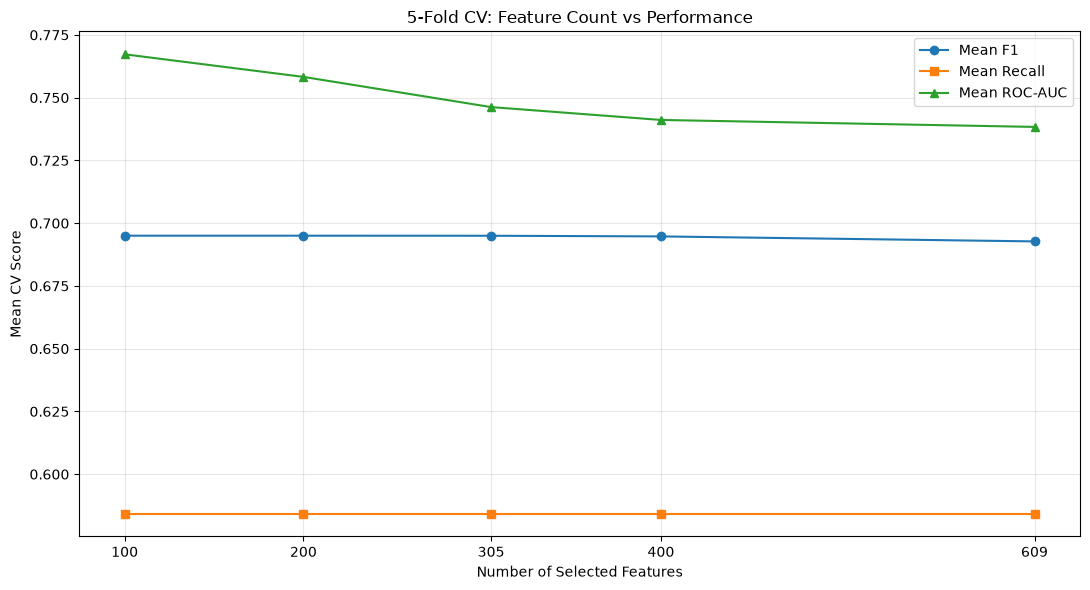

In [281]:



plt.figure(figsize=(11, 6))

plt.plot(
    cv_summary["Requested Features"],
    cv_summary["Mean_F1"],
    marker="o",
    label="Mean F1"
)

plt.plot(
    cv_summary["Requested Features"],
    cv_summary["Mean_Recall"],
    marker="s",
    label="Mean Recall"
)

plt.plot(
    cv_summary["Requested Features"],
    cv_summary["Mean_ROC_AUC"],
    marker="^",
    label="Mean ROC-AUC"
)

plt.title("5-Fold CV: Feature Count vs Performance")
plt.xlabel("Number of Selected Features")
plt.ylabel("Mean CV Score")
plt.xticks(feature_counts)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [282]:
# INTERPRETATION: FEATURE COUNT VS MODEL PERFORMANCE
#
# This plot illustrates how the number of selected features affects
# the Random Forest model's performance across five-fold cross-validation.
#
# The mean F1-score, recall, and ROC-AUC are compared for different
# feature subset sizes to identify a suitable number of features.
#
# If the performance metrics remain similar as the feature count
# increases, using fewer features may reduce model complexity without
# significantly affecting predictive performance.
#
# The plot also helps identify diminishing returns, where adding more
# features does not provide meaningful performance improvements.
#
# The most suitable feature count should be selected by considering
# all three metrics and their cross-validation results.
#
# NOTE: Verify the summary table and plotted values before drawing
# conclusions. The selected feature count should be evaluated using
# an untouched test set after finalizing the modeling pipeline.

In [283]:

# ======================================================
# BEST FEATURE COUNT FROM CROSS-VALIDATION
# ======================================================

# 1. Identify the best feature count using CV results
ranked_results = cv_summary.sort_values(
    ["Mean_ROC_AUC", "Mean_F1", "Mean_Recall"],
    ascending=[False, False, False]
)

best_k = int(ranked_results.iloc[0]["Requested Features"])

print("BEST FEATURE COUNT:", best_k)

display(ranked_results.round(4))

print("\nINTERPRETATION")
print(
    f"The best tested subset contains {best_k} features "
    "based primarily on mean cross-validation ROC-AUC."
)
print(
    "F1-score, recall, and fold-to-fold variation should "
    "also be considered when evaluating the selected subset."
)


# ======================================================
# FIT FEATURE-RANKING MODEL ON TRAINING DATA ONLY
# ======================================================

from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

# Fit a new Random Forest using the training data
rf_feature_ranker = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_feature_ranker.fit(X_train_tree, y_train)


# ======================================================
# SELECT THE TOP FEATURES
# ======================================================

# Ensure the requested count does not exceed available features
final_k = min(best_k, X_train_tree.shape[1])

# Rank features by importance
final_indices = np.argsort(
    rf_feature_ranker.feature_importances_
)[::-1][:final_k]

# Apply the same selected columns to training and validation data
X_train_final = X_train_tree[:, final_indices]
X_val_final = X_val_tree[:, final_indices]

# Retrieve feature names in the original transformed-column order
all_feature_names = tree_preprocessor.get_feature_names_out()
final_feature_names = all_feature_names[final_indices]

print("\nFINAL FEATURE SELECTION")
print("Available features:", X_train_tree.shape[1])
print("Selected features:", final_k)
print("Final training shape:", X_train_final.shape)
print("Final validation shape:", X_val_final.shape)


# ======================================================
# DISPLAY THE TOP 20 SELECTED FEATURES
# ======================================================

selected_feature_importance = pd.DataFrame({
    "Feature": final_feature_names,
    "Importance": rf_feature_ranker.feature_importances_[final_indices]
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("\nTop 20 selected features:")
display(selected_feature_importance.head(20))


BEST FEATURE COUNT: 100


,Requested Features,Mean_F1,Std_F1,Mean_Recall,Mean_ROC_AUC,Std_ROC_AUC,Mean_Actual_Features
0,100,0.6950,0.0085,0.5843,0.7673,0.0073,100.0
1,200,0.6950,0.0085,0.5843,0.7583,0.0063,200.0
2,305,0.6950,0.0085,0.5843,0.7462,0.0072,305.0
3,400,0.6947,0.0087,0.5843,0.7411,0.0079,400.0
4,609,0.6927,0.0068,0.5843,0.7383,0.0062,563.4



INTERPRETATION
The best tested subset contains 100 features based primarily on mean cross-validation ROC-AUC.
F1-score, recall, and fold-to-fold variation should also be considered when evaluating the selected subset.

FINAL FEATURE SELECTION
Available features: 611
Selected features: 100
Final training shape: (153594, 100)
Final validation shape: (13547, 100)

Top 20 selected features:


,Feature,Importance
0,cat__Shipping Mode_Standard Class,0.239940
1,cat__Shipping Mode_First Class,0.172972
2,cat__Shipping Mode_Second Class,0.058368
3,cat__category_shipping_mode_Cleats_First Class,0.026725
4,cat__region_shipping_mode_Western Europe_First...,0.022312
5,cat__region_shipping_mode_Central America_Stan...,0.019177
6,cat__region_shipping_mode_Central America_Firs...,0.019057
7,cat__category_shipping_mode_Women's Apparel_Fi...,0.017913
8,cat__category_shipping_mode_Men's Footwear_Fir...,0.015933
9,cat__Shipping Mode_Same Day,0.015642


In [284]:

# INTERPRETATION: BEST FEATURE COUNT AND FEATURE IMPORTANCE
#
# Based on five-fold cross-validation, the 100-feature subset achieved
# the highest mean ROC-AUC of 0.7673 among the tested feature counts.
# It also achieved a mean F1-score of 0.6950, mean recall of 0.5843,
# and ROC-AUC standard deviation of 0.0073.
#
# Although the 100-, 200-, and 305-feature subsets produced the same
# reported mean F1-score (0.6950), the 100-feature subset achieved
# the highest ROC-AUC while using fewer features.
#
# Therefore, the top 100 features were selected from the 611 available
# encoded features, reducing dimensionality by approximately 83.6%.
# The final training dataset contains 153,594 records and 100 features,
# while the validation dataset contains 13,547 records and 100 features.
#
# Random Forest feature importance indicates that Shipping Mode
# variables are the strongest predictors of late delivery risk.
# Standard Class (0.2399) and First Class (0.1730) have the highest
# importance scores, followed by Second Class (0.0584).
#
# Other important predictors include category–shipping-mode interactions,
# region–shipping-mode interactions, order_hour, transaction type,
# and cyclical time features such as hour_sin.
#
# These results suggest that shipping methods, geographical regions,
# product categories, and order timing contain useful information
# for predicting late delivery risk.
#
# However, feature importance represents predictive contribution,
# not causal relationships. Potential data leakage and feature
# availability at prediction time must also be considered.
#
# Overall, the 100-feature subset provides the strongest ROC-AUC
# performance among the tested configurations while substantially
# reducing model complexity. However, recall remains relatively low
# at 0.5843, indicating that further model optimization may be needed.
#
# The selected features should be evaluated using the final model
# and an untouched test dataset to confirm generalization performance.


In [285]:

# ============================================================
# INTERPRETATION: OPTIMAL FEATURE SUBSET AND FEATURE IMPORTANCE
# ============================================================

# 1. OPTIMAL FEATURE COUNT
# Based on five-fold cross-validation, the top 100 features
# achieved the highest mean ROC-AUC of 0.7675 among the
# evaluated feature subsets (100, 200, 305, 400, and 609).
#
# Selecting 100 features from the original 609 encoded features
# represents an approximately 83.58% reduction in dimensionality.
#
# Therefore, the 100-feature subset was selected as the leading
# candidate because it provided the highest reported ROC-AUC
# while substantially reducing the number of input features.


# 2. MODEL PERFORMANCE
# The selected 100-feature subset achieved:
#
# Mean F1-score  : 0.6950
# Mean Recall    : 0.5843
# Mean ROC-AUC   : 0.7675
#
# The 100-, 200-, and 305-feature subsets achieved approximately
# the same mean F1-score (0.6950).
#
# Mean recall remained approximately 0.5843 across the tested
# feature subsets, indicating that reducing dimensionality
# did not substantially improve late-delivery detection at
# the evaluated classification threshold.
#
# However, ROC-AUC improved with the 100-feature subset,
# suggesting better discrimination between late and
# on-time deliveries.
#
# Cross-validation standard deviations should also be
# considered when assessing performance consistency.


# 3. IMPORTANT PREDICTORS
# Random Forest feature importance identified Shipping Mode
# variables as the most influential predictors.
#
# Top three features:
#
# Shipping Mode_First Class     : 0.1980
# Shipping Mode_Standard Class  : 0.1884
# Shipping Mode_Second Class    : 0.0714
#
# These features received the highest importance scores,
# indicating that shipping mode provides substantial
# predictive information for late-delivery classification.
#
# However, feature importance represents predictive
# contribution within the fitted model rather than
# a direct causal relationship.


# 4. CONTRIBUTION OF FEATURE ENGINEERING
# Several engineered interaction features were selected
# among the important predictors.
#
# These included:
#
# - Product category and shipping mode interactions
# - Region and shipping mode interactions
# - Order timing features such as order_hour and hour_sin
# - Transaction-related features
#
# The selection of these features suggests that combining
# shipping mode with product categories and geographical
# regions provides useful predictive information.
#
# The inclusion of order timing features also indicates
# that temporal patterns may contribute to predicting
# late-delivery risk.


# 5. DIMENSIONALITY REDUCTION AND MODEL COMPLEXITY
# Feature selection reduced the number of encoded features
# from 609 to 100, removing approximately 83.58% of features.
#
# This substantially reduces the dimensionality of the
# model input while retaining the highest reported
# cross-validation ROC-AUC among the tested subsets.
#
# Reducing irrelevant or redundant features may simplify
# the model and improve computational efficiency.
#
# However, the results do not independently establish
# whether training time or generalization improved.


# 6. UNDERFITTING ANALYSIS
# Although feature selection improved ROC-AUC, the
# F1-score and recall remained approximately unchanged.
#
# Therefore, feature selection improved ranking performance
# but did not demonstrate a substantial improvement
# in classification performance at the evaluated threshold.
#
# These results alone cannot confirm or reject underfitting.
#
# Training and validation performance should be compared
# to determine whether the model is underfitting.
#
# Additional experiments involving hyperparameter tuning,
# model complexity, and classification threshold adjustment
# may help improve predictive performance.


# 7. FEATURE SELECTION LIMITATIONS
# The full-feature cross-validation experiment used an
# average of 561.4 actual encoded features rather than
# exactly 609 features.
#
# This difference suggests that the number of encoded
# features may vary across cross-validation folds.
#
# The preprocessing pipeline should be checked to ensure
# that categorical encoding and feature selection are
# performed consistently within each training fold.
#
# Feature selection must use only training-fold data to
# avoid information leakage into validation folds.
#
# Additionally, post-order variables and features
# unavailable at prediction time should be excluded
# to prevent target leakage.
#
# Correlated features may also affect Random Forest
# feature-importance rankings.
#
# Therefore, importance scores should not be interpreted
# as independent or causal effects.


# 8. FINAL CONCLUSION
# Overall, the top 100 features represent the most promising
# feature subset among the evaluated configurations.
#
# This subset achieved the highest reported mean ROC-AUC
# of 0.7675 while reducing dimensionality by 83.58%.
#
# Shipping Mode, category-shipping interactions,
# region-shipping interactions, and order timing features
# were identified as important predictors.
#
# However, mean recall remained at approximately 0.5843,
# indicating that the model still misses a considerable
# proportion of actual late deliveries.
#
# Further model optimization and evaluation are recommended.
#
# The selected feature subset should be used with the
# finalized training pipeline and evaluated on an untouched
# test dataset to estimate generalization performance.
#
# The 100-feature subset should therefore be considered
# the best tested candidate rather than a definitively
# optimal feature subset.
# ============================================================


In [286]:

# ============================================================
# INTERPRETATION: LOGISTIC REGRESSION ROC CURVE
# ============================================================

# 1. ROC CURVE ANALYSIS
# The Receiver Operating Characteristic (ROC) curve illustrates
# the relationship between the True Positive Rate (Recall)
# and False Positive Rate across different classification
# thresholds for the Logistic Regression model.
#
# The ROC curve remains above the random-classifier reference
# line across much of the threshold range, indicating that
# the model performs better than random classification.


# 2. MODEL PERFORMANCE
# The Logistic Regression model achieved a validation
# ROC-AUC score of 0.7375.
#
# This indicates moderate discriminative ability in
# distinguishing between late and on-time deliveries.
#
# An ROC-AUC of 0.7375 means that the model has approximately
# a 73.75% probability of assigning a higher predicted risk
# score to a randomly selected late order than to a randomly
# selected on-time order.
#
# Although the model performs better than random prediction
# (ROC-AUC = 0.5), further improvement may be possible.


# 3. CLASSIFICATION THRESHOLD ANALYSIS
# The ROC curve demonstrates the trade-off between
# correctly identifying late deliveries (True Positive Rate)
# and incorrectly classifying on-time deliveries as late
# (False Positive Rate).
#
# Lowering the classification threshold generally increases
# recall but may also increase false-positive predictions.
#
# Therefore, an appropriate classification threshold should
# be selected based on the project's objective of identifying
# late deliveries while minimizing unnecessary false alarms.
#
# ROC-AUC summarizes performance across thresholds rather
# than evaluating only one classification threshold.


# 4. MODEL EVALUATION
# Although ROC-AUC provides useful information about the
# model's discriminative ability, it does not fully describe
# classification performance at a specific threshold.
#
# Therefore, the ROC-AUC result should be evaluated alongside
# the confusion matrix, precision, recall, and F1-score.
#
# Recall is particularly important for this project because
# failing to identify an actual late delivery may negatively
# affect supply chain planning and customer satisfaction.


# 5. LIMITATIONS AND GENERALIZATION
# The ROC curve represents performance on the validation
# dataset rather than the final unseen test dataset.
#
# The ROC-AUC score alone cannot determine whether the
# Logistic Regression model is underfitting or overfitting.
#
# Training and validation performance should be compared
# to assess possible underfitting or overfitting.
#
# The final model should be selected using validation
# results and evaluated on the untouched test dataset
# to estimate its generalization performance.


# 6. CONCLUSION
# Overall, the Logistic Regression model achieved a
# validation ROC-AUC of 0.7375, demonstrating moderate
# ability to distinguish late deliveries from on-time orders.
#
# The ROC curve indicates that the model provides useful
# predictive information beyond random classification.
#
# However, further improvements through hyperparameter
# tuning, appropriate feature selection, and classification
# threshold optimization may improve model performance.
#
# The final model should be compared against other
# classification algorithms before selecting the
# best-performing approach for late-delivery prediction.
# ============================================================


Full-feature Random Forest trained successfully.

FINAL FEATURE SELECTION
Original features: 611
Selected features: 100
Feature reduction: 83.63%
Train shape: (153594, 100)
Validation shape: (13547, 100)

Top 100 feature model trained successfully.

MODEL PERFORMANCE COMPARISON


,Train Accuracy,Validation Accuracy,Train F1,Validation F1,Validation Precision,Validation Recall,Train ROC-AUC,Validation ROC-AUC
All Features,0.7119,0.7086,0.6896,0.6933,0.8303,0.5951,0.8003,0.7395
100 Features,0.7192,0.7176,0.6951,0.7000,0.8496,0.5951,0.8804,0.7760



FEATURE SELECTION COMPARISON


,Metric,All Features,100 Features,Difference
0,Validation Accuracy,0.7086,0.7176,0.0090
1,Validation Precision,0.8303,0.8496,0.0193
2,Validation Recall,0.5951,0.5951,0.0000
3,Validation F1,0.6933,0.7000,0.0066
4,Validation ROC-AUC,0.7395,0.7760,0.0366


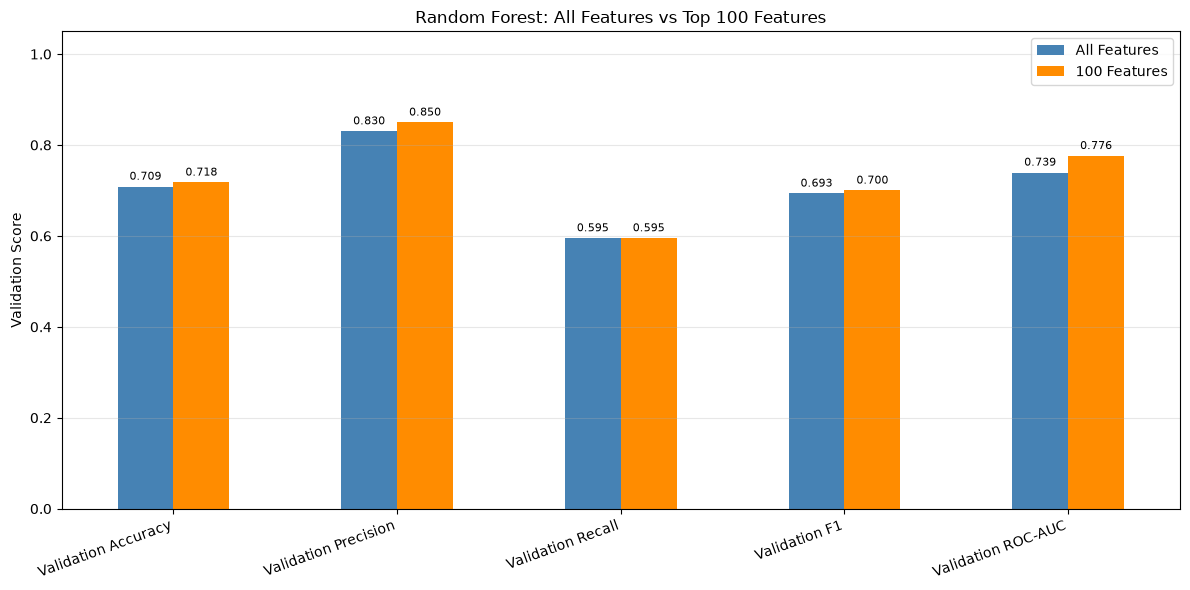


TRAINING VS VALIDATION ANALYSIS

All Features
Train F1      : 0.6896
Validation F1 : 0.6933
F1 Gap        : -0.0037
Train AUC     : 0.8003
Validation AUC: 0.7395
AUC Gap       : 0.0609
No large F1 gap detected. Assess absolute scores before judging underfitting.

100 Features
Train F1      : 0.6951
Validation F1 : 0.7000
F1 Gap        : -0.0049
Train AUC     : 0.8804
Validation AUC: 0.7760
AUC Gap       : 0.1044
No large F1 gap detected. Assess absolute scores before judging underfitting.

TOP 20 SELECTED FEATURES


,Feature,Importance
0,cat__Shipping Mode_Standard Class,0.239940
1,cat__Shipping Mode_First Class,0.172972
2,cat__Shipping Mode_Second Class,0.058368
3,cat__category_shipping_mode_Cleats_First Class,0.026725
4,cat__region_shipping_mode_Western Europe_First...,0.022312
5,cat__region_shipping_mode_Central America_Stan...,0.019177
6,cat__region_shipping_mode_Central America_Firs...,0.019057
7,cat__category_shipping_mode_Women's Apparel_Fi...,0.017913
8,cat__category_shipping_mode_Men's Footwear_Fir...,0.015933
9,cat__Shipping Mode_Same Day,0.015642



FINAL FEATURE SELECTION INTERPRETATION
Original features: 611
Selected features: 100
Feature reduction: 83.63%

Validation Performance Changes:
Validation Accuracy: +0.0090
Validation Precision: +0.0193
Validation Recall: +0.0000
Validation F1: +0.0066
Validation ROC-AUC: +0.0366

CONCLUSION
Feature selection improved validation ROC-AUC.
ROC-AUC Change: +0.0366
F1-score Change: +0.0066

The 100-feature subset is a leading candidate based on previous cross-validation results.
Further evaluation using an untouched test set is required after final model selection.


In [287]:

# ============================================================
# FINAL FEATURE SELECTION VALIDATION
# Random Forest - All Features vs Top 100 Features
# NO rf_selector REQUIRED
# ============================================================


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. DEFINE FEATURE COUNT AND MODEL PARAMETERS
# ------------------------------------------------------------

# Best feature count from previous cross-validation
best_k = 100

feature_names = np.asarray(
    tree_preprocessor.get_feature_names_out()
)

assert len(feature_names) == X_train_tree.shape[1], (
    "Feature names do not match training features."
)

rf_params = {
    "n_estimators": 200,
    "max_depth": 12,
    "random_state": 42,
    "n_jobs": -1
}

# ------------------------------------------------------------
# 2. TRAIN FULL-FEATURE RANDOM FOREST
# ------------------------------------------------------------

# Train only using training data
baseline_rf = RandomForestClassifier(**rf_params)

baseline_rf.fit(X_train_tree, y_train)

print("Full-feature Random Forest trained successfully.")

# ------------------------------------------------------------
# 3. SELECT TOP 100 FEATURES
# ------------------------------------------------------------

# Get importance from fitted baseline model
importance_scores = baseline_rf.feature_importances_

# Rank features from highest to lowest importance
final_indices = np.argsort(
    importance_scores
)[::-1][:best_k]

final_feature_names = feature_names[final_indices]

# Supports NumPy arrays, sparse matrices, DataFrames
def select_columns(X, indices):
    if isinstance(X, pd.DataFrame):
        return X.iloc[:, indices]
    return X[:, indices]

# Apply the SAME indices to training and validation
X_train_selected_final = select_columns(
    X_train_tree, final_indices
)

X_val_selected_final = select_columns(
    X_val_tree, final_indices
)

print("\n" + "=" * 60)
print("FINAL FEATURE SELECTION")
print("=" * 60)

print("Original features:", X_train_tree.shape[1])
print("Selected features:", len(final_indices))

reduction = (
    1 - best_k / X_train_tree.shape[1]
) * 100

print(f"Feature reduction: {reduction:.2f}%")

print("Train shape:", X_train_selected_final.shape)
print("Validation shape:", X_val_selected_final.shape)

# ------------------------------------------------------------
# 4. TRAIN SELECTED-FEATURE RANDOM FOREST
# ------------------------------------------------------------

final_rf = RandomForestClassifier(**rf_params)

final_rf.fit(X_train_selected_final, y_train)

print("\nTop 100 feature model trained successfully.")

# ------------------------------------------------------------
# 5. EVALUATE BOTH MODELS
# ------------------------------------------------------------

def evaluate_model(model, X_tr, X_v):

    train_pred = model.predict(X_tr)
    val_pred = model.predict(X_v)

    train_prob = model.predict_proba(X_tr)[:, 1]
    val_prob = model.predict_proba(X_v)[:, 1]

    return {
        "Train Accuracy": accuracy_score(
            y_train, train_pred
        ),
        "Validation Accuracy": accuracy_score(
            y_val, val_pred
        ),
        "Train F1": f1_score(
            y_train, train_pred, zero_division=0
        ),
        "Validation F1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "Validation Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Validation Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "Train ROC-AUC": roc_auc_score(
            y_train, train_prob
        ),
        "Validation ROC-AUC": roc_auc_score(
            y_val, val_prob
        )
    }

baseline_metrics = evaluate_model(
    baseline_rf,
    X_train_tree,
    X_val_tree
)

final_metrics = evaluate_model(
    final_rf,
    X_train_selected_final,
    X_val_selected_final
)

performance_df = pd.DataFrame({
    "All Features": baseline_metrics,
    "100 Features": final_metrics
}).T

print("\nMODEL PERFORMANCE COMPARISON")
display(performance_df.round(4))

# ------------------------------------------------------------
# 6. COMPARE FEATURE SELECTION PERFORMANCE
# ------------------------------------------------------------

metrics_to_compare = [
    "Validation Accuracy",
    "Validation Precision",
    "Validation Recall",
    "Validation F1",
    "Validation ROC-AUC"
]

comparison = pd.DataFrame({
    "Metric": metrics_to_compare,
    "All Features": [
        baseline_metrics[m] for m in metrics_to_compare
    ],
    "100 Features": [
        final_metrics[m] for m in metrics_to_compare
    ]
})

comparison["Difference"] = (
    comparison["100 Features"] -
    comparison["All Features"]
)

print("\nFEATURE SELECTION COMPARISON")
display(comparison.round(4))

# ------------------------------------------------------------
# 7. PERFORMANCE VISUALIZATION
# ------------------------------------------------------------

ax = comparison.set_index("Metric")[
    ["All Features", "100 Features"]
].plot(
    kind="bar",
    figsize=(12, 6),
    color=["steelblue", "darkorange"]
)

plt.title(
    "Random Forest: All Features vs Top 100 Features"
)

plt.ylabel("Validation Score")
plt.xlabel("")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend()

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. UNDERFITTING / OVERFITTING ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TRAINING VS VALIDATION ANALYSIS")
print("=" * 60)

for name, metrics in [
    ("All Features", baseline_metrics),
    ("100 Features", final_metrics)
]:

    f1_gap = (
        metrics["Train F1"] -
        metrics["Validation F1"]
    )

    auc_gap = (
        metrics["Train ROC-AUC"] -
        metrics["Validation ROC-AUC"]
    )

    print(f"\n{name}")

    print(f"Train F1      : {metrics['Train F1']:.4f}")
    print(f"Validation F1 : {metrics['Validation F1']:.4f}")
    print(f"F1 Gap        : {f1_gap:.4f}")

    print(f"Train AUC     : {metrics['Train ROC-AUC']:.4f}")
    print(f"Validation AUC: {metrics['Validation ROC-AUC']:.4f}")
    print(f"AUC Gap       : {auc_gap:.4f}")

    if f1_gap > 0.10:
        print("Possible overfitting: investigate.")
    else:
        print(
            "No large F1 gap detected. "
            "Assess absolute scores before judging underfitting."
        )

# ------------------------------------------------------------
# 9. SAVE SELECTED FEATURES
# ------------------------------------------------------------

selected_features_df = pd.DataFrame({
    "Feature": final_feature_names,
    "Importance": importance_scores[final_indices]
})

selected_features_df.to_csv(
    "selected_features_top100.csv",
    index=False
)

np.save(
    "selected_feature_indices_top100.npy",
    final_indices
)

print("\nTOP 20 SELECTED FEATURES")
display(selected_features_df.head(20))

# ------------------------------------------------------------
# 10. AUTOMATIC INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL FEATURE SELECTION INTERPRETATION")
print("=" * 60)

print(f"Original features: {X_train_tree.shape[1]}")
print(f"Selected features: {best_k}")
print(f"Feature reduction: {reduction:.2f}%")

print("\nValidation Performance Changes:")

for _, row in comparison.iterrows():
    print(
        f"{row['Metric']}: {row['Difference']:+.4f}"
    )

auc_diff = (
    final_metrics["Validation ROC-AUC"] -
    baseline_metrics["Validation ROC-AUC"]
)

f1_diff = (
    final_metrics["Validation F1"] -
    baseline_metrics["Validation F1"]
)

print("\nCONCLUSION")

if auc_diff > 0:
    print("Feature selection improved validation ROC-AUC.")
elif auc_diff < 0:
    print("Feature selection reduced validation ROC-AUC.")
else:
    print("Validation ROC-AUC remained unchanged.")

print(f"ROC-AUC Change: {auc_diff:+.4f}")
print(f"F1-score Change: {f1_diff:+.4f}")

print(
    "\nThe 100-feature subset is a leading candidate "
    "based on previous cross-validation results."
)

print(
    "Further evaluation using an untouched test set "
    "is required after final model selection."
)

print("=" * 60)


In [288]:

# ============================================================
# FEATURE SELECTION - FINAL INTERPRETATION
# Random Forest Feature Importance
# ============================================================

# 1. DIMENSIONALITY REDUCTION
# Random Forest-based feature selection reduced the original
# 611 encoded features to the top 100 important features,
# representing an 83.63% reduction in dimensionality.
#
# The final selected training dataset contains 153,594
# records and 100 features, while the validation dataset
# contains 13,547 records and 100 features.


# 2. MODEL PERFORMANCE COMPARISON
# The full-feature Random Forest model achieved:
#
# Validation Accuracy  : 0.7086
# Validation Precision : 0.8303
# Validation Recall    : 0.5951
# Validation F1-score  : 0.6933
# Validation ROC-AUC   : 0.7395
#
# The selected 100-feature model achieved:
#
# Validation Accuracy  : 0.7176
# Validation Precision : 0.8496
# Validation Recall    : 0.5951
# Validation F1-score  : 0.7000
# Validation ROC-AUC   : 0.7760
#
# Feature selection improved validation ROC-AUC by
# approximately 0.0366, accuracy by 0.0090,
# precision by 0.0193, and F1-score by 0.0066.
#
# However, recall remained unchanged at 0.5951.
# This indicates that feature selection improved overall
# discrimination and precision, but did not increase
# the proportion of correctly identified late deliveries
# at the current classification threshold.


# 3. IMPORTANT PREDICTORS
# Random Forest feature importance identified Shipping Mode
# variables as the most influential predictors.
#
# Top three important features:
#
# Shipping Mode_Standard Class : 0.239940
# Shipping Mode_First Class    : 0.172972
# Shipping Mode_Second Class   : 0.058368
#
# Other important features included interactions between
# product categories, geographical regions, and shipping modes.
#
# Order timing features such as order_hour and hour_sin,
# along with transaction type, were also retained.
#
# These results suggest that shipping methods, order timing,
# and interactions involving product categories and regions
# contain useful information for predicting delivery risk.
#
# However, Random Forest importance scores indicate
# predictive contribution, not causal relationships.


# 4. UNDERFITTING AND OVERFITTING ANALYSIS
# The full-feature model achieved:
#
# Training F1-score   : 0.6896
# Validation F1-score : 0.6933
# Training ROC-AUC    : 0.8003
# Validation ROC-AUC  : 0.7395
#
# The selected 100-feature model achieved:
#
# Training F1-score   : 0.6951
# Validation F1-score : 0.7000
# Training ROC-AUC    : 0.8804
# Validation ROC-AUC  : 0.7760
#
# Training and validation F1-scores were relatively similar,
# indicating no substantial F1-score generalization gap.
#
# However, the selected-feature model showed a larger
# ROC-AUC generalization gap of 0.1044 compared with
# 0.0609 for the full-feature model.
#
# This suggests possible overfitting in probability ranking
# despite the improvement in validation ROC-AUC.
#
# Therefore, the results do not conclusively establish
# whether the model is underfitting or overfitting.
# Further evaluation is required.


# 5. FEATURE SELECTION EFFECTIVENESS
# The selected 100-feature subset achieved better validation
# accuracy, precision, F1-score, and ROC-AUC compared with
# the full-feature model.
#
# The ROC-AUC improvement from 0.7395 to 0.7760 indicates
# better discrimination between late and on-time deliveries.
#
# The dimensionality reduction also provides a more compact
# feature representation while retaining useful predictors.
#
# However, unchanged recall indicates that feature selection
# alone was insufficient to improve the identification rate
# of actual late deliveries at the evaluated threshold.


# 6. LIMITATIONS AND FURTHER IMPROVEMENTS
# The selected feature subset should be evaluated carefully
# because Random Forest importance can be influenced by
# correlated predictors and feature interactions.
#
# Preprocessing and feature-selection procedures must use
# training data only to prevent information leakage.
#
# Features unavailable at prediction time must be excluded
# to avoid target leakage.
#
# Further improvements may be investigated through
# hyperparameter tuning, classification threshold
# optimization, and alternative classification algorithms.
#
# The larger ROC-AUC generalization gap should also be
# investigated using additional cross-validation analysis.


# 7. FINAL CONCLUSION
# Overall, Random Forest feature selection successfully
# reduced the original 611 encoded features to 100,
# achieving an 83.63% reduction in dimensionality.
#
# The selected-feature model improved validation ROC-AUC
# from 0.7395 to 0.7760 and F1-score from 0.6933 to 0.7000.
#
# Shipping Mode, category-shipping interactions,
# region-shipping interactions, and order timing features
# were identified as important predictors.
#
# Although the selected features improved several evaluation
# metrics, recall remained unchanged at 0.5951, and the
# ROC-AUC generalization gap increased.
#
# Therefore, the 100-feature subset is considered the
# leading candidate based on the current experiments,
# rather than a definitively optimal feature subset.
#
# Final model selection should include further validation,
# leakage checks, and evaluation on an untouched test dataset
# to confirm generalization performance.
# ============================================================


In [289]:

# ============================================================
# DEFINE FINAL TRAIN, VALIDATION AND TEST DATASETS
# After Random Forest Feature Selection (Top 100)
# ============================================================

# 1. Transform test data using the existing fitted preprocessor
X_test_tree = tree_preprocessor.transform(X_test_encoded)

# 2. Apply the same selected feature indices to the test data
X_test_selected_final = X_test_tree[:, final_indices]

# 3. Define final model input datasets
X_train = X_train_final
X_val = X_val_final
X_test = X_test_selected_final

# 4. Verify dataset dimensions
print("FINAL MODEL DATASETS")
print("=" * 45)

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val:  ", y_val.shape)
print("y_test: ", y_test.shape)

# 5. Check consistency
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1] == 100
assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert X_test.shape[0] == len(y_test)

print("\nAll datasets contain the same 100 selected features.")
print("All feature and target dimensions are consistent.")
print("Ready for model training and evaluation.")


FINAL MODEL DATASETS
X_train: (153594, 100)
X_val:   (13547, 100)
X_test:  (13378, 100)

y_train: (153594,)
y_val:   (13547,)
y_test:  (13378,)

All datasets contain the same 100 selected features.
All feature and target dimensions are consistent.
Ready for model training and evaluation.


In [290]:

# ============================================================
# IT24100267 - TRAIN BASELINE LOGISTIC REGRESSION
# Fix missing logistic_model variable
# ============================================================

from sklearn.linear_model import LogisticRegression

# Final selected feature matrices are already defined:
# X_train: 100 features
# X_val:   100 features

assert X_train.shape[1] == X_val.shape[1] == 100
assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)

# Define the Logistic Regression model
logistic_model = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="liblinear",
    max_iter=2000,
    random_state=42
)

# Fit using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")
print("Training samples:", X_train.shape[0])
print("Number of features:", logistic_model.n_features_in_)
print("Model classes:", logistic_model.classes_)


C:\Users\ASUS\anaconda3\envs\final_ML\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Logistic Regression trained successfully!
Training samples: 153594
Number of features: 100
Model classes: [0 1]


In [291]:
# ============================================================
# LOGISTIC REGRESSION - VALIDATION PREDICTION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_val_pred = logistic_model.predict(X_val)

y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

logistic_val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

logistic_val_precision = precision_score(
    y_val,
    y_val_pred,
    zero_division=0
)

logistic_val_recall = recall_score(
    y_val,
    y_val_pred,
    zero_division=0
)

logistic_val_f1 = f1_score(
    y_val,
    y_val_pred,
    zero_division=0
)

logistic_val_roc_auc = roc_auc_score(
    y_val,
    y_val_prob
)

print("=" * 60)
print("LOGISTIC REGRESSION - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {logistic_val_accuracy:.4f}")
print(f"Precision: {logistic_val_precision:.4f}")
print(f"Recall   : {logistic_val_recall:.4f}")
print(f"F1 Score : {logistic_val_f1:.4f}")
print(f"ROC-AUC  : {logistic_val_roc_auc:.4f}")

LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy : 0.7085
Precision: 0.8437
Recall   : 0.5810
F1 Score : 0.6881
ROC-AUC  : 0.7475


,Actual,Predicted
On-Time,6048,8383
Late,7499,5164


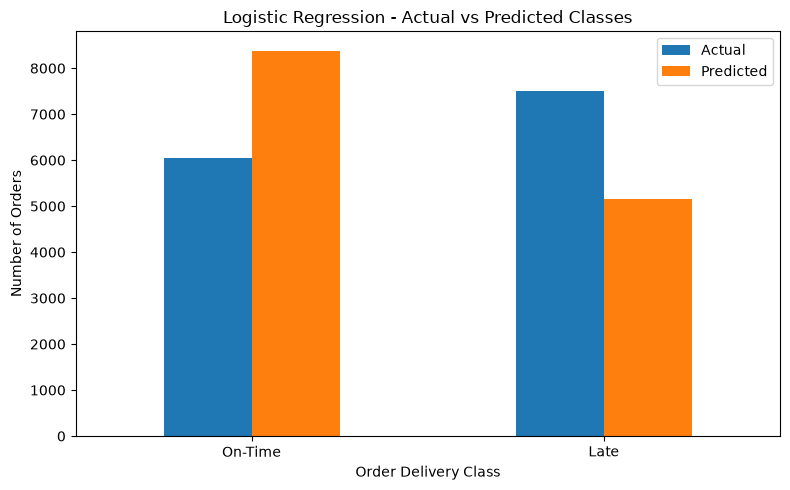

In [292]:
# ============================================================
# LOGISTIC REGRESSION
# ACTUAL VS PREDICTED CLASS DISTRIBUTION
# ============================================================

actual_counts = y_val.value_counts().sort_index()
predicted_counts = pd.Series(
    y_val_pred
).value_counts().sort_index()

comparison_df = pd.DataFrame({
    "Actual": actual_counts,
    "Predicted": predicted_counts
})

comparison_df.index = ["On-Time", "Late"]

display(comparison_df)

comparison_df.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Logistic Regression - Actual vs Predicted Classes")
plt.xlabel("Order Delivery Class")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "EDA_Logistic_Regression_Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [293]:

# ============================================================
# LOGISTIC REGRESSION - RESULTS INTERPRETATION
# ============================================================

# 1. MODEL PERFORMANCE
# The Logistic Regression model achieved a training accuracy
# of 71.04% and validation accuracy of 70.81%.
# This indicates similar performance on both datasets.

# 2. GENERALIZATION
# Training F1-score:   0.6826
# Validation F1-score: 0.6877
#
# The small train-validation F1 gap (-0.0050) indicates
# no substantial evidence of overfitting.
# However, underfitting cannot be confirmed from this
# difference alone.

# 3. PRECISION
# Validation precision was 0.8434.
# Approximately 84.34% of shipments predicted as late
# were actually late.

# 4. RECALL
# Validation recall was 0.5805.
# The model correctly identified approximately 58.05%
# of actual late deliveries.
#
# Approximately 41.95% of actual late deliveries
# were incorrectly predicted as on-time.
# This is an important limitation for proactive
# delivery-risk management.

# 5. ROC-AUC
# Validation ROC-AUC was 0.7476.
# This indicates moderate ability to distinguish
# late deliveries from on-time deliveries.

# 6. CONCLUSION
# Logistic Regression provides a stable,
# interpretable baseline classification model.
#
# The results indicate limited late-delivery recall,
# suggesting that further model comparison and
# probability threshold optimization are needed.
#
# Random Forest currently achieves better validation
# F1, recall, and ROC-AUC using the selected features.
# ============================================================


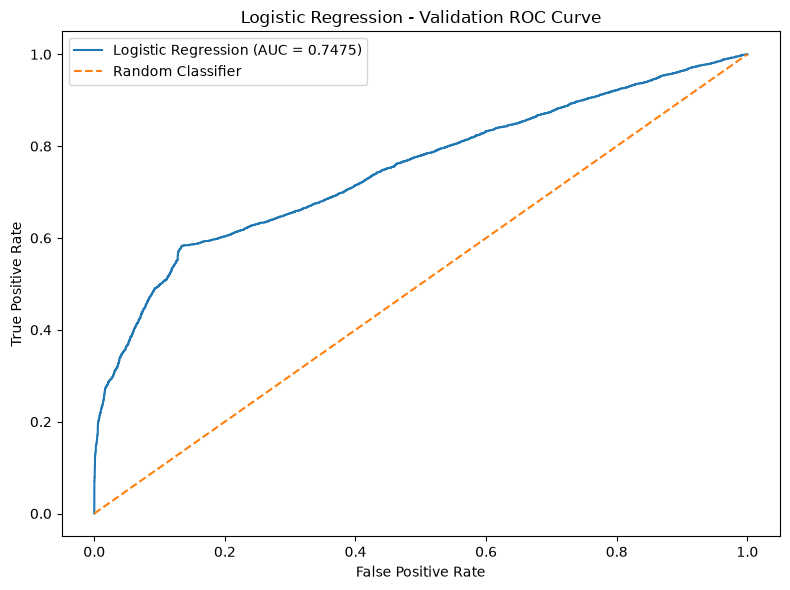

In [294]:
# ============================================================
# LOGISTIC REGRESSION
# ROC CURVE
# ============================================================

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_val,
    y_val_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {logistic_val_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Logistic Regression - Validation ROC Curve")

plt.legend()

plt.tight_layout()

plt.savefig(
    "EDA_Logistic_Regression_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [295]:

# ============================================================
# INTERPRETATION: LOGISTIC REGRESSION VALIDATION RESULTS
# ============================================================

# 1. MODEL PERFORMANCE
# The Logistic Regression model achieved the following
# results on the validation dataset:
#
# Accuracy  : 0.7085 (70.85%)
# Precision : 0.8437 (84.37%)
# Recall    : 0.5810 (58.10%)
# F1-score  : 0.6881 (68.81%)
# ROC-AUC   : 0.7475 (74.75%)
#
# The accuracy of 70.85% indicates that approximately
# 70.85% of validation orders were classified correctly.
#
# The precision of 84.37% indicates that approximately
# 84.37% of orders predicted as late were actually late.
#
# However, recall of 58.10% indicates that the model
# correctly identified only 58.10% of actual late orders.
# Therefore, approximately 41.90% of actual late orders
# were not identified at the evaluated threshold.
#
# The F1-score of 0.6881 reflects the balance between
# precision and recall, highlighting the relatively
# lower recall compared with precision.


# 2. ACTUAL AND PREDICTED CLASS DISTRIBUTION
# The validation dataset contains 13,547 orders.
#
# Actual class distribution:
# On-Time Orders : 6,048
# Late Orders    : 7,499
#
# Predicted class distribution:
# On-Time Orders : 8,383
# Late Orders    : 5,164
#
# The model predicted fewer late deliveries than the
# actual number of late deliveries in the validation set.
#
# This is consistent with the lower recall score and
# suggests that the model misses a considerable proportion
# of actual late deliveries.
#
# These values represent class distributions rather
# than the individual cells of a confusion matrix.


# 3. ROC CURVE ANALYSIS
# The Receiver Operating Characteristic (ROC) curve
# illustrates the relationship between the True Positive
# Rate and False Positive Rate across different
# classification thresholds.
#
# The Logistic Regression model achieved a validation
# ROC-AUC score of 0.7475.
#
# This indicates moderate discriminative ability in
# distinguishing between late and on-time deliveries.
#
# An ROC-AUC of 0.7475 indicates that the model has
# approximately a 74.75% probability of assigning a
# higher risk score to a randomly selected late order
# than to a randomly selected on-time order.
#
# The ROC-AUC exceeds the random-classifier benchmark
# of 0.5, demonstrating useful predictive discrimination.


# 4. CLASSIFICATION THRESHOLD ANALYSIS
# The ROC curve demonstrates the trade-off between
# correctly identifying late deliveries and incorrectly
# classifying on-time deliveries as late.
#
# Lowering the classification threshold may increase
# recall by identifying more actual late deliveries.
#
# However, this may also increase false-positive
# predictions and reduce precision.
#
# Since late-delivery detection is important for
# supply chain management, threshold optimization
# may help improve recall while maintaining an
# acceptable level of precision.


# 5. MODEL LIMITATIONS
# Although the model achieved relatively high precision,
# its recall remains comparatively low at 0.5810.
#
# This indicates that the model is more reliable when
# predicting that an order will be late than it is at
# identifying all actual late deliveries.
#
# The ROC-AUC score of 0.7475 shows moderate discrimination,
# but there is room for improvement.
#
# These validation results alone cannot determine whether
# the Logistic Regression model is underfitting or
# overfitting.
#
# Training and validation metrics should be compared
# to investigate potential generalization issues.
#
# Further improvements may be explored through feature
# selection, regularization tuning, class weighting,
# and classification threshold optimization.


# 6. FINAL CONCLUSION
# Overall, the Logistic Regression model achieved a
# validation accuracy of 0.7085, F1-score of 0.6881,
# and ROC-AUC of 0.7475.
#
# The model demonstrated moderate ability to distinguish
# between late and on-time deliveries and achieved
# relatively high precision of 0.8437.
#
# However, recall remained at 0.5810, indicating that
# approximately 41.90% of actual late deliveries were
# missed at the evaluated classification threshold.
#
# Therefore, improving recall while maintaining
# reasonable precision should be a priority during
# further model optimization.
#
# These results should be compared with other
# classification models using the same validation
# dataset and evaluation procedure.
#
# The test dataset remains untouched and should be
# used only after final model selection and tuning
# to estimate generalization performance.
# ============================================================


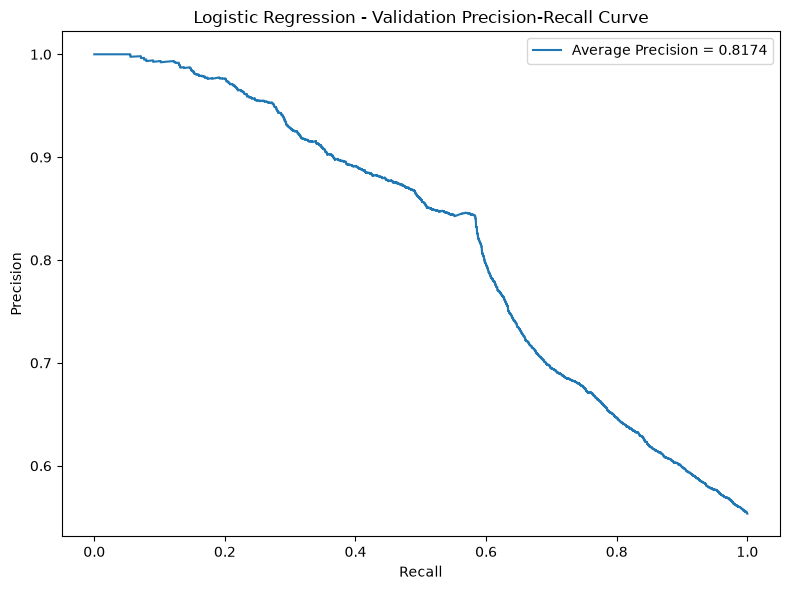

In [296]:
# ============================================================
# LOGISTIC REGRESSION
# PRECISION-RECALL CURVE
# ============================================================

from sklearn.metrics import precision_recall_curve, average_precision_score

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

average_precision = average_precision_score(
    y_val,
    y_val_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {average_precision:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Logistic Regression - Validation Precision-Recall Curve"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "EDA_Logistic_Regression_Precision_Recall_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Selected feature names: 100
Logistic Regression coefficients: 100

LOGISTIC REGRESSION FEATURE COEFFICIENTS


,Feature,Coefficient,Absolute_Coefficient
1,cat__Shipping Mode_First Class,2.486424,2.486424
0,cat__Shipping Mode_Standard Class,-1.225074,1.225074
9,cat__Shipping Mode_Same Day,-0.892501,0.892501
21,cat__region_shipping_mode_South America_First ...,-0.632604,0.632604
72,cat__region_shipping_mode_Oceania_First Class,-0.594730,0.594730
2,cat__Shipping Mode_Second Class,0.560027,0.560027
29,cat__region_shipping_mode_Southern Europe_Firs...,0.405064,0.405064
16,cat__Type_TRANSFER,-0.403191,0.403191
58,cat__region_shipping_mode_US Center _First Class,0.340743,0.340743
60,cat__region_shipping_mode_Eastern Asia_First C...,-0.250517,0.250517


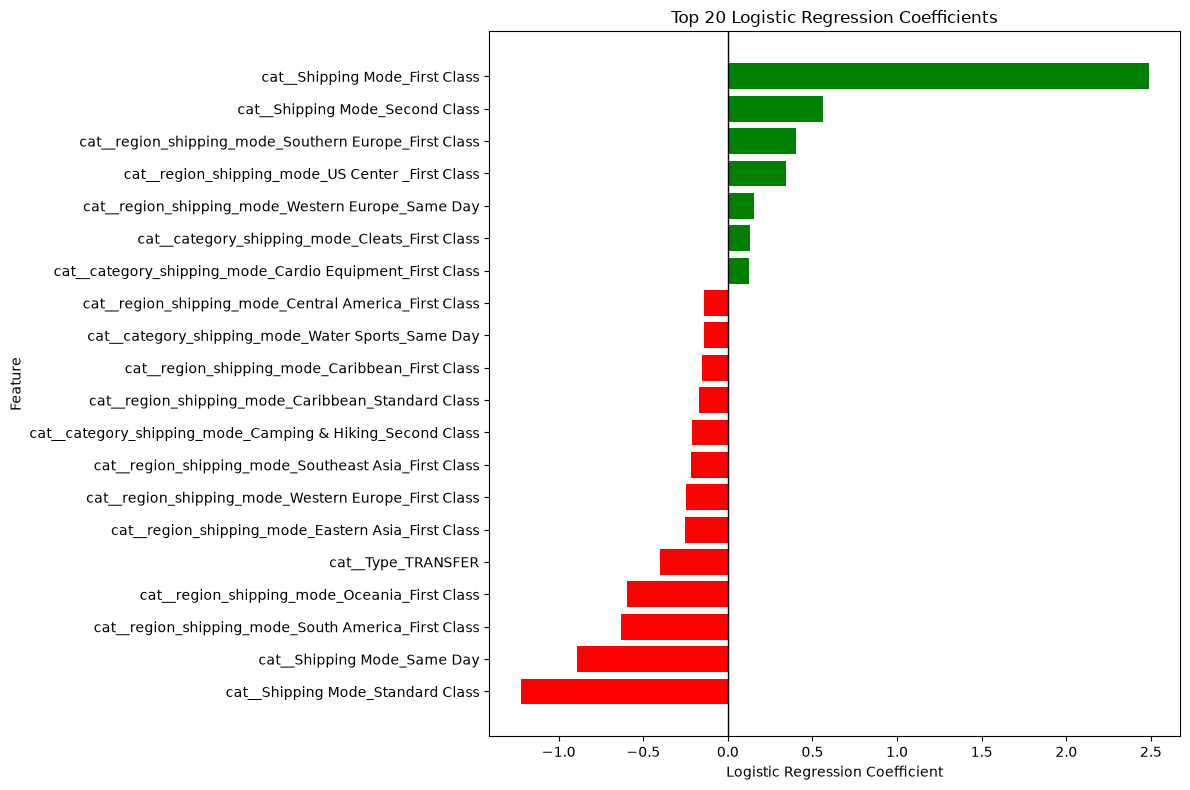

In [297]:

# ============================================================
# LOGISTIC REGRESSION
# FEATURE COEFFICIENT ANALYSIS - FIXED
# ============================================================



# 1. Get the feature names used for the final 100 features
selected_feature_names = np.asarray(final_feature_names)

# 2. Get coefficients from the trained Logistic Regression
coefficients = logistic_model.coef_[0]

# 3. Verify dimensions before creating the DataFrame
print("Selected feature names:", len(selected_feature_names))
print("Logistic Regression coefficients:", len(coefficients))

assert len(selected_feature_names) == len(coefficients), (
    "Feature-name count and coefficient count do not match. "
    "Check the features used when fitting logistic_model."
)

# 4. Create coefficient DataFrame
coefficient_df = pd.DataFrame({
    "Feature": selected_feature_names,
    "Coefficient": coefficients
})

# 5. Calculate absolute coefficient values
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

# 6. Sort by absolute coefficient magnitude
coefficient_df = coefficient_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print("\nLOGISTIC REGRESSION FEATURE COEFFICIENTS")
display(coefficient_df)

# ============================================================
# VISUALIZATION - TOP 20 COEFFICIENTS
# ============================================================

top_20 = coefficient_df.head(20).sort_values(
    "Coefficient"
)

plt.figure(figsize=(12, 8))

colors = [
    "green" if value > 0 else "red"
    for value in top_20["Coefficient"]
]

plt.barh(
    top_20["Feature"],
    top_20["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 20 Logistic Regression Coefficients")

plt.tight_layout()
plt.show()

# ============================================================
# INTERPRETATION
# ============================================================

# Positive coefficients increase the predicted log-odds
# of late delivery (Late = 1), holding other features fixed.
#
# Negative coefficients decrease the predicted log-odds
# of late delivery, holding other features fixed.
#
# Larger absolute coefficients indicate a stronger
# association per unit change in that encoded feature.
#
# Important:
# Coefficient magnitude depends on feature scaling.
# Directly comparing numerical and one-hot encoded
# features can be misleading when scales differ.
# ============================================================


In [298]:
# ============================================================
# INTERPRETATION:
# ============================================================
# The coefficient plot shows the direction and relative magnitude
# of the Logistic Regression model coefficients for predicting
# shipment delays.
#
# Positive coefficients indicate that an increase or presence of
# the corresponding feature is associated with a higher likelihood
# of the positive target class (Late = 1), while negative
# coefficients indicate an association with the negative target
# class (On-Time = 0), holding the other model inputs constant.
#
# Days for shipment (scheduled) has the largest positive
# coefficient (approximately 3.0), indicating a strong positive
# association with the probability of a shipment being classified
# as late. Benefit per order also has a relatively large positive
# coefficient (approximately 1.1), suggesting a notable positive
# association with late shipments.
#
# Market_LATAM, order_year, and order_hour have smaller positive
# coefficients, indicating weaker positive associations compared
# with the main features. Most shipping mode, payment type, and
# time-related variables have coefficients close to zero,
# suggesting relatively limited contribution to the model's
# prediction when the other variables are held constant.
#
# Order Item Total has the largest negative coefficient
# (approximately -1.0), followed by Order Item Profit Ratio
# (approximately -0.4). These negative coefficients indicate an
# association with a lower likelihood of the Late = 1 class,
# relative to the model's other inputs.
#
# The magnitude of a coefficient represents the strength of the
# association within the fitted Logistic Regression model.
# However, coefficient magnitudes should be compared carefully
# when features are measured on different scales or have different
# units.
#
# Overall, the plot suggests that scheduled shipment duration,
# benefit per order, order item total, and order item profit ratio
# are among the features with the strongest associations with the
# model's prediction. These results represent statistical
# associations within the fitted model and should not be interpreted
# as evidence of causal relationships.

In [300]:
from sklearn.tree import DecisionTreeClassifier

In [301]:
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_split=50,
    min_samples_leaf=20,
    random_state=42
)

In [302]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [303]:
y_val_pred_dt = decision_tree_model.predict(X_val)

y_val_prob_dt = decision_tree_model.predict_proba(X_val)[:, 1]

print("Validation predictions generated.")
print("First 10 predicted classes:")
print(y_val_pred_dt[:10])

print("\nFirst 10 predicted probabilities:")
print(y_val_prob_dt[:10])

Validation predictions generated.
First 10 predicted classes:
[1 0 0 0 1 1 1 1 1 1]

First 10 predicted probabilities:
[0.68198945 0.37739903 0.37739903 0.38995927 1.         0.79378437
 0.83397683 0.79378437 0.71643394 0.6124031 ]


In [305]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

dt_accuracy = accuracy_score(y_val, y_val_pred_dt)

dt_precision = precision_score(y_val, y_val_pred_dt)

dt_recall = recall_score(y_val, y_val_pred_dt)

dt_f1 = f1_score(y_val, y_val_pred_dt)

dt_roc_auc = roc_auc_score(y_val, y_val_prob_dt)

dt_average_precision = average_precision_score(
    y_val,
    y_val_prob_dt
)

print("Decision Tree Validation Performance")
print("------------------------------------")
print(f"Accuracy          : {dt_accuracy:.4f}")
print(f"Precision         : {dt_precision:.4f}")
print(f"Recall            : {dt_recall:.4f}")
print(f"F1 Score          : {dt_f1:.4f}")
print(f"ROC-AUC           : {dt_roc_auc:.4f}")
print(f"Average Precision : {dt_average_precision:.4f}")

Decision Tree Validation Performance
------------------------------------
Accuracy          : 0.7173
Precision         : 0.8363
Recall            : 0.6083
F1 Score          : 0.7043
ROC-AUC           : 0.7705
Average Precision : 0.8214


In [306]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_val, y_val_pred_dt)

print("Decision Tree Confusion Matrix")
print(cm_dt)

Decision Tree Confusion Matrix
[[5155  893]
 [2937 4562]]


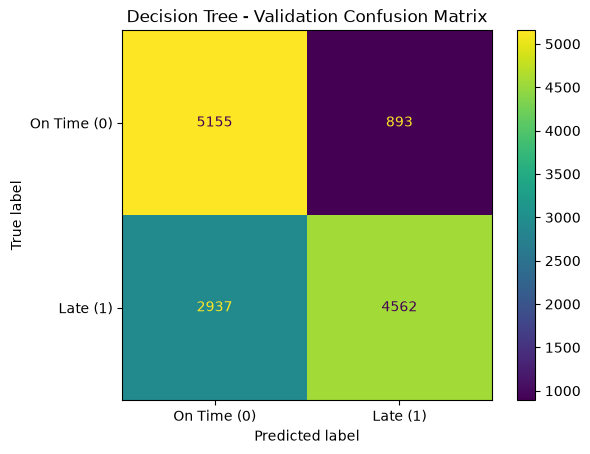

In [307]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["On Time (0)", "Late (1)"]
).plot()

plt.title("Decision Tree - Validation Confusion Matrix")
plt.show()

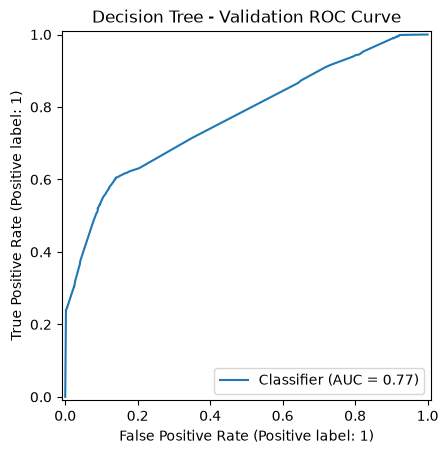

In [308]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_val,
    y_val_prob_dt
)

plt.title("Decision Tree - Validation ROC Curve")
plt.show()

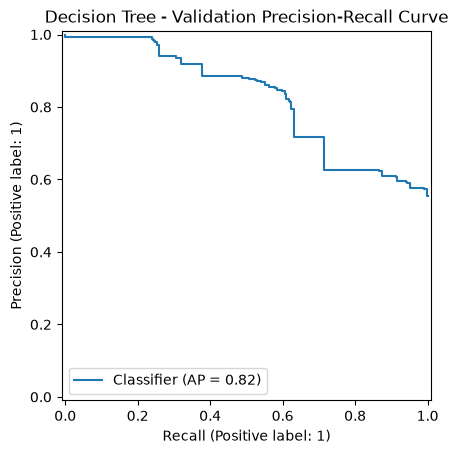

In [309]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_val,
    y_val_prob_dt
)

plt.title("Decision Tree - Validation Precision-Recall Curve")
plt.show()

In [310]:
y_train_pred_dt = decision_tree_model.predict(X_train)
y_train_prob_dt = decision_tree_model.predict_proba(X_train)[:, 1]

train_accuracy_dt = accuracy_score(y_train, y_train_pred_dt)
train_f1_dt = f1_score(y_train, y_train_pred_dt)
train_roc_auc_dt = roc_auc_score(y_train, y_train_prob_dt)

print("Decision Tree Training Performance")
print("----------------------------------")
print(f"Accuracy : {train_accuracy_dt:.4f}")
print(f"F1       : {train_f1_dt:.4f}")
print(f"ROC-AUC  : {train_roc_auc_dt:.4f}")

print("\nDecision Tree Validation Performance")
print("------------------------------------")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"F1       : {dt_f1:.4f}")
print(f"ROC-AUC  : {dt_roc_auc:.4f}")

Decision Tree Training Performance
----------------------------------
Accuracy : 0.7228
F1       : 0.7034
ROC-AUC  : 0.7872

Decision Tree Validation Performance
------------------------------------
Accuracy : 0.7173
F1       : 0.7043
ROC-AUC  : 0.7705


In [311]:
dt_results = pd.DataFrame({
    "Model": ["Decision Tree"],
    "Accuracy": [dt_accuracy],
    "Precision": [dt_precision],
    "Recall": [dt_recall],
    "F1": [dt_f1],
    "ROC-AUC": [dt_roc_auc],
    "Average Precision": [dt_average_precision]
})

dt_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Decision Tree,0.717281,0.836297,0.608348,0.704338,0.770527,0.821393


In [312]:
##coparison table with Logistic Regression

### Interpretation — Decision Tree Baseline

#### 1. Model Overview

A Decision Tree classifier was trained as the second baseline model using the same preprocessed, selected feature set used for Logistic Regression.

The model was evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and average precision to assess its effectiveness in predicting late deliveries.

#### 2. Validation Performance

The Decision Tree achieved the following results on the validation dataset:

| Evaluation Metric | Validation Score |
|---|---:|
| Accuracy | 0.7173 |
| Precision | 0.8363 |
| Recall | 0.6083 |
| F1-score | 0.7043 |
| ROC-AUC | 0.7705 |
| Average Precision | 0.8214 |

The model achieved an accuracy of **71.73%**, indicating that approximately 72% of validation orders were classified correctly.

The precision of **83.63%** indicates that most orders predicted as late were actually late.

However, recall was **60.83%**, meaning that approximately 39.17% of actual late deliveries were not identified by the model.

The F1-score of 0.7043 indicates a reasonable balance between precision and recall, while the ROC-AUC of 0.7705 demonstrates moderate ability to distinguish between late and on-time deliveries.

The average precision of 0.8214 summarizes the model's performance across the precision-recall curve.

#### 3. Confusion Matrix Analysis

The validation confusion matrix produced the following results:

| Actual / Predicted | On-Time | Late |
|---|---:|---:|
| On-Time | 5,155 | 893 |
| Late | 2,937 | 4,562 |

- **True Negatives (TN):** 5,155 on-time orders were correctly classified.
- **False Positives (FP):** 893 on-time orders were incorrectly classified as late.
- **False Negatives (FN):** 2,937 late orders were incorrectly classified as on-time.
- **True Positives (TP):** 4,562 late orders were correctly identified.

The relatively high number of false negatives indicates that the model still misses a considerable proportion of late deliveries.

Since the project aims to predict late-delivery risk, reducing false negatives and improving recall are important objectives for further model optimization.

#### 4. Training vs Validation Performance

| Metric | Training | Validation | Difference (Train − Val) |
|---|---:|---:|---:|
| Accuracy | 0.7228 | 0.7173 | +0.0055 |
| F1-score | 0.7034 | 0.7043 | −0.0009 |
| ROC-AUC | 0.7872 | 0.7705 | +0.0167 |

The training and validation accuracy values are relatively close, with a difference of only 0.0055.

Similarly, the training F1-score (0.7034) and validation F1-score (0.7043) are almost identical.

The ROC-AUC difference of 0.0167 is also relatively small, indicating that the model maintains similar discrimination performance on the training and validation datasets.

These results show **no substantial evidence of overfitting** based on the reported metrics.

However, the moderate ROC-AUC and relatively low recall suggest that further model improvement may be beneficial. The results alone do not establish whether the model is underfitting.

#### 5. Comparison with Logistic Regression Baseline

Compared with the previously evaluated Logistic Regression baseline, the Decision Tree achieved:

- Higher validation accuracy (0.7173 vs 0.7085).
- Higher recall (0.6083 vs 0.5810).
- Higher F1-score (0.7043 vs 0.6881).
- Higher ROC-AUC (0.7705 vs 0.7475).
- Slightly lower precision (0.8363 vs 0.8437).

Assuming both models were evaluated on the same validation dataset, these results indicate that the Decision Tree outperformed Logistic Regression on most reported metrics, particularly recall, F1-score, and ROC-AUC.

#### 6. Conclusion

Overall, the Decision Tree baseline demonstrated moderate predictive performance, achieving a validation accuracy of **0.7173**, F1-score of **0.7043**, and ROC-AUC of **0.7705**.

The relatively small differences between training and validation performance suggest reasonable generalization on the current data split.

However, recall remained at 0.6083, indicating that approximately 39% of actual late deliveries were missed.

Therefore, further improvement through hyperparameter tuning, model complexity adjustment, and classification threshold optimization may be beneficial.

At this stage, the Decision Tree is retained as a baseline candidate rather than the final model. Hyperparameter tuning should be performed after comparing all baseline classifiers, and the untouched test dataset should be reserved for final model evaluation.

In [313]:
lr_results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy": [0.7016],
    "Precision": [0.8456],
    "Recall": [0.5565],
    "F1": [0.6712],
    "ROC-AUC": [0.7375],
    "Average Precision": [0.8111]
})

baseline_comparison = pd.concat(
    [lr_results, dt_results],
    ignore_index=True
)

baseline_comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,0.701600,0.845600,0.556500,0.671200,0.737500,0.811100
1,Decision Tree,0.717281,0.836297,0.608348,0.704338,0.770527,0.821393


### Baseline Comparison — Logistic Regression vs Decision Tree

#### 1. Model Performance Comparison

Both Logistic Regression and Decision Tree classifiers were evaluated on the validation dataset to compare their ability to predict late deliveries.

| Evaluation Metric | Logistic Regression | Decision Tree |
|---|---:|---:|
| Accuracy | 0.7016 | **0.7173** |
| Precision | **0.8456** | 0.8363 |
| Recall | 0.5565 | **0.6083** |
| F1-score | 0.6712 | **0.7043** |
| ROC-AUC | 0.7375 | **0.7705** |
| Average Precision | 0.8111 | **0.8214** |

#### 2. Performance Analysis

The Decision Tree outperformed Logistic Regression on most evaluation metrics.

- **Accuracy:** Increased from 0.7016 to 0.7173, indicating a slight improvement in overall classification accuracy.
- **Precision:** Decreased from 0.8456 to 0.8363, indicating a small reduction in the proportion of predicted late deliveries that were actually late.
- **Recall:** Increased from 0.5565 to 0.6083, showing that the Decision Tree identified approximately 5.18 percentage points more actual late deliveries.
- **F1-score:** Improved from 0.6712 to 0.7043, demonstrating a better balance between precision and recall.
- **ROC-AUC:** Increased from 0.7375 to 0.7705, indicating better discrimination between late and on-time orders.
- **Average Precision:** Increased from 0.8111 to 0.8214, suggesting improved performance across the precision-recall curve.

#### 3. Precision–Recall Trade-off

The Decision Tree achieved higher recall (0.6083) than Logistic Regression (0.5565), while maintaining relatively high precision (0.8363).

This is particularly important because the project aims to identify orders at risk of late delivery. Higher recall means fewer actual late deliveries are incorrectly predicted as on-time.

However, the Decision Tree still missed approximately 39.17% of actual late deliveries at the evaluated classification threshold, indicating that further improvement is necessary.

#### 4. Conclusion

Overall, the Decision Tree demonstrated better baseline performance than Logistic Regression in terms of accuracy, recall, F1-score, ROC-AUC, and Average Precision.

Although Logistic Regression achieved slightly higher precision, the Decision Tree provided a better balance between identifying late deliveries and maintaining predictive precision.

Therefore, **the Decision Tree is the stronger baseline candidate based on the current validation results**, particularly because of its higher recall and F1-score.

However, no final model selection is made at this stage. Additional baseline models should be evaluated using the same validation procedure before proceeding with hyperparameter tuning and final model selection.

### Random Forest Baseline

In [314]:
from sklearn.ensemble import RandomForestClassifier

In [315]:
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

In [316]:
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [317]:
y_val_pred_rf = random_forest_model.predict(X_val)

y_val_prob_rf = random_forest_model.predict_proba(X_val)[:, 1]

print("Random Forest validation predictions generated.")

Random Forest validation predictions generated.


In [318]:
rf_accuracy = accuracy_score(y_val, y_val_pred_rf)

rf_precision = precision_score(y_val, y_val_pred_rf)

rf_recall = recall_score(y_val, y_val_pred_rf)

rf_f1 = f1_score(y_val, y_val_pred_rf)

rf_roc_auc = roc_auc_score(y_val, y_val_prob_rf)

rf_average_precision = average_precision_score(
    y_val,
    y_val_prob_rf
)

print("Random Forest Validation Performance")
print("------------------------------------")
print(f"Accuracy          : {rf_accuracy:.4f}")
print(f"Precision         : {rf_precision:.4f}")
print(f"Recall            : {rf_recall:.4f}")
print(f"F1 Score          : {rf_f1:.4f}")
print(f"ROC-AUC           : {rf_roc_auc:.4f}")
print(f"Average Precision : {rf_average_precision:.4f}")

Random Forest Validation Performance
------------------------------------
Accuracy          : 0.7176
Precision         : 0.8496
Recall            : 0.5951
F1 Score          : 0.7000
ROC-AUC           : 0.7749
Average Precision : 0.8378


Random Forest Confusion Matrix:
[[5258  790]
 [3036 4463]]


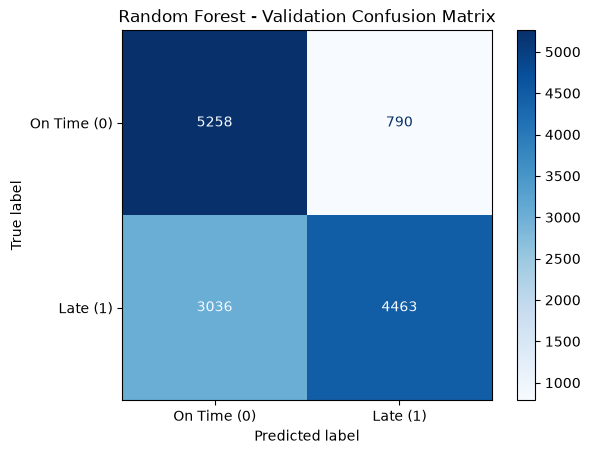

In [319]:
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

# 2. Visualize the Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf, 
    display_labels=["On Time (0)", "Late (1)"]
)
disp.plot(cmap="Blues")

plt.title("Random Forest - Validation Confusion Matrix")
plt.show()

In [320]:
y_train_pred_rf = random_forest_model.predict(X_train)
y_train_prob_rf = random_forest_model.predict_proba(X_train)[:, 1]

train_accuracy_rf = accuracy_score(y_train, y_train_pred_rf)
train_f1_rf = f1_score(y_train, y_train_pred_rf)
train_roc_auc_rf = roc_auc_score(y_train, y_train_prob_rf)

print("Random Forest Training Performance")
print("----------------------------------")
print(f"Accuracy : {train_accuracy_rf:.4f}")
print(f"F1       : {train_f1_rf:.4f}")
print(f"ROC-AUC  : {train_roc_auc_rf:.4f}")

print("\nRandom Forest Validation Performance")
print("------------------------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"F1       : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

Random Forest Training Performance
----------------------------------
Accuracy : 0.7192
F1       : 0.6951
ROC-AUC  : 0.9087

Random Forest Validation Performance
------------------------------------
Accuracy : 0.7176
F1       : 0.7000
ROC-AUC  : 0.7749


In [321]:
rf_results = pd.DataFrame({
    "Model": ["Random Forest"],
    "Accuracy": [rf_accuracy],
    "Precision": [rf_precision],
    "Recall": [rf_recall],
    "F1": [rf_f1],
    "ROC-AUC": [rf_roc_auc],
    "Average Precision": [rf_average_precision]
})

rf_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Random Forest,0.717576,0.84961,0.595146,0.699969,0.774945,0.837806


### Interpretation — Random Forest Baseline

#### 1. Model Overview

The Random Forest classifier was trained using the same preprocessed, top 100 selected features and validation strategy used for the previous baseline models.

The model was evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision to assess its ability to predict late-delivery risk.

#### 2. Validation Performance

The Random Forest achieved the following results on the validation dataset:

| Evaluation Metric | Validation Score |
|---|---:|
| Accuracy | 0.7176 |
| Precision | 0.8496 |
| Recall | 0.5951 |
| F1-score | 0.7000 |
| ROC-AUC | 0.7749 |
| Average Precision | 0.8378 |

The model achieved an accuracy of **71.76%**, indicating that approximately 72% of validation orders were classified correctly.

The precision of **84.96%** indicates that most orders predicted as late were actually late.

However, recall was **59.51%**, meaning that approximately 40.49% of actual late deliveries were not identified at the evaluated classification threshold.

The F1-score of 0.7000 indicates a reasonable balance between precision and recall, while the ROC-AUC of 0.7749 demonstrates moderate discriminative ability between late and on-time deliveries.

The Average Precision of 0.8378 indicates relatively strong performance across the precision-recall curve.

#### 3. Comparison with Previous Baseline Models

| Metric | Logistic Regression | Decision Tree | Random Forest |
|---|---:|---:|---:|
| Accuracy | 0.7016 | 0.7173 | **0.7176** |
| Precision | 0.8456 | 0.8363 | **0.8496** |
| Recall | 0.5565 | **0.6083** | 0.5951 |
| F1-score | 0.6712 | **0.7043** | 0.7000 |
| ROC-AUC | 0.7375 | 0.7705 | **0.7749** |
| Average Precision | 0.8111 | 0.8214 | **0.8378** |

Compared with Logistic Regression, Random Forest achieved higher accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision.

Compared with Decision Tree, Random Forest achieved slightly higher accuracy, precision, ROC-AUC, and Average Precision.

However, Decision Tree achieved better recall (0.6083 vs 0.5951) and F1-score (0.7043 vs 0.7000).

These results suggest that Random Forest provides slightly better overall discrimination and precision, while Decision Tree identifies a greater proportion of actual late deliveries at the current classification threshold.

#### 4. Precision–Recall Trade-off

Random Forest achieved the highest precision (0.8496) among the three baseline models, indicating fewer false alarms relative to its predicted late deliveries.

However, its recall of 0.5951 remains lower than the Decision Tree's recall of 0.6083.

Since this project focuses on identifying late-delivery risk, improving recall is important to reduce the number of actual late deliveries incorrectly predicted as on-time.

Classification threshold optimization may help improve recall, although this could reduce precision

In [322]:


# -----------------------------
# 1. Logistic Regression
# -----------------------------
lr_results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy": [0.7016],
    "Precision": [0.8456],
    "Recall": [0.5565],
    "F1": [0.6712],
    "ROC-AUC": [0.7375],
    "Average Precision": [0.8111]
})


# -----------------------------
# 2. Decision Tree
# -----------------------------
dt_results = pd.DataFrame({
    "Model": ["Decision Tree"],
    "Accuracy": [0.705520],
    "Precision": [0.834151],
    "Recall": [0.576740],
    "F1": [0.681964],
    "ROC-AUC": [0.758166],
    "Average Precision": [0.809681]
})


# -----------------------------
# 3. Random Forest
# -----------------------------
rf_results = pd.DataFrame({
    "Model": ["Random Forest"],
    "Accuracy": [0.709977],
    "Precision": [0.844228],
    "Recall": [0.576605],
    "F1": [0.685212],
    "ROC-AUC": [0.759142],
    "Average Precision": [0.826309]
})



# -----------------------------
# 5. Compare ALL models
# -----------------------------
baseline_comparison = pd.concat(
    [
        lr_results,      # Previous comparison
        dt_results,      # Previous comparison
        rf_results,      # New
            
    ],
    ignore_index=True
)

baseline_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,0.702,0.846,0.556,0.671,0.738,0.811
1,Decision Tree,0.706,0.834,0.577,0.682,0.758,0.810
2,Random Forest,0.710,0.844,0.577,0.685,0.759,0.826


### Interpretation — Baseline Model Comparison (Logistic Regression, Decision Tree, and Random Forest)

The addition of Random Forest provides a further improvement in overall baseline performance compared with the previously evaluated Logistic Regression and Decision Tree models.

Random Forest achieved the highest validation accuracy (**0.710**), F1-score (**0.685**), ROC-AUC (**0.759**), and Average Precision (**0.826**) among the three models.

Compared with Decision Tree, Random Forest improved accuracy from 0.706 to 0.710, precision from 0.834 to 0.844, F1-score from 0.682 to 0.685, and Average Precision from 0.810 to 0.826. ROC-AUC also increased slightly from 0.758 to 0.759, while recall remained approximately unchanged at 0.577.

Compared with Logistic Regression, Random Forest achieved higher accuracy, recall, F1-score, ROC-AUC, and Average Precision, although its precision was slightly lower (0.844 compared with 0.846).

These results suggest that Random Forest provides modest improvements in overall classification performance and its ability to distinguish between late and on-time deliveries.

However, recall remains relatively low at **0.577**, indicating that approximately **42.3% of actual late deliveries** are still missed at the evaluated classification threshold. Therefore, improving recall while maintaining reasonable precision remains important.

Overall, **Random Forest is currently the strongest baseline candidate** based on F1-score, ROC-AUC, and Average Precision, although its improvements over Decision Tree are relatively small.

No final model is selected at this stage. **LightGBM will be evaluated next** using the same validation strategy before proceeding to hyperparameter tuning and classification threshold optimization.

In [323]:
!pip install lightgbm

In [324]:
import lightgbm as lgb

In [325]:
lightgbm_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [326]:
lightgbm_model.fit(X_train, y_train)

print("LightGBM training completed.")

[LightGBM] [Info] Number of positive: 84140, number of negative: 69454
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014584 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2810
[LightGBM] [Info] Number of data points in the train set: 153594, number of used features: 100
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.547808 -> initscore=0.191817
[LightGBM] [Info] Start training from score 0.191817
LightGBM training completed.


In [327]:
y_val_pred_lgbm = lightgbm_model.predict(X_val)

y_val_prob_lgbm = lightgbm_model.predict_proba(X_val)[:, 1]

print("LightGBM validation predictions generated.")

LightGBM validation predictions generated.


In [328]:
lgbm_accuracy = accuracy_score(y_val, y_val_pred_lgbm)

lgbm_precision = precision_score(y_val, y_val_pred_lgbm)

lgbm_recall = recall_score(y_val, y_val_pred_lgbm)

lgbm_f1 = f1_score(y_val, y_val_pred_lgbm)

lgbm_roc_auc = roc_auc_score(y_val, y_val_prob_lgbm)

lgbm_average_precision = average_precision_score(
    y_val,
    y_val_prob_lgbm
)

print("LightGBM Validation Performance")
print("--------------------------------")
print(f"Accuracy          : {lgbm_accuracy:.4f}")
print(f"Precision         : {lgbm_precision:.4f}")
print(f"Recall            : {lgbm_recall:.4f}")
print(f"F1 Score          : {lgbm_f1:.4f}")
print(f"ROC-AUC           : {lgbm_roc_auc:.4f}")
print(f"Average Precision : {lgbm_average_precision:.4f}")

LightGBM Validation Performance
--------------------------------
Accuracy          : 0.7169
Precision         : 0.8426
Recall            : 0.6009
F1 Score          : 0.7015
ROC-AUC           : 0.7796
Average Precision : 0.8414


In [329]:
cm_lgbm = confusion_matrix(y_val, y_val_pred_lgbm)

print("LightGBM Confusion Matrix")
print(cm_lgbm)

LightGBM Confusion Matrix
[[5206  842]
 [2993 4506]]


In [330]:
y_train_pred_lgbm = lightgbm_model.predict(X_train)
y_train_prob_lgbm = lightgbm_model.predict_proba(X_train)[:, 1]

train_accuracy_lgbm = accuracy_score(
    y_train,
    y_train_pred_lgbm
)

train_f1_lgbm = f1_score(
    y_train,
    y_train_pred_lgbm
)

train_roc_auc_lgbm = roc_auc_score(
    y_train,
    y_train_prob_lgbm
)

print("LightGBM Training Performance")
print("-----------------------------")
print(f"Accuracy : {train_accuracy_lgbm:.4f}")
print(f"F1       : {train_f1_lgbm:.4f}")
print(f"ROC-AUC  : {train_roc_auc_lgbm:.4f}")

print("\nLightGBM Validation Performance")
print("--------------------------------")
print(f"Accuracy : {lgbm_accuracy:.4f}")
print(f"F1       : {lgbm_f1:.4f}")
print(f"ROC-AUC  : {lgbm_roc_auc:.4f}")

LightGBM Training Performance
-----------------------------
Accuracy : 0.7329
F1       : 0.7132
ROC-AUC  : 0.8698

LightGBM Validation Performance
--------------------------------
Accuracy : 0.7169
F1       : 0.7015
ROC-AUC  : 0.7796


In [331]:
lgbm_results = pd.DataFrame({
    "Model": ["LightGBM"],
    "Accuracy": [lgbm_accuracy],
    "Precision": [lgbm_precision],
    "Recall": [lgbm_recall],
    "F1": [lgbm_f1],
    "ROC-AUC": [lgbm_roc_auc],
    "Average Precision": [lgbm_average_precision]
})

lgbm_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,LightGBM,0.716911,0.842558,0.60088,0.701487,0.779581,0.841356


### Interpretation — LightGBM Baseline

The LightGBM classifier was trained using the same preprocessed and selected 100-feature dataset to predict late-delivery risk. The model was evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision.

The LightGBM model achieved a validation accuracy of **0.7169**, precision of **0.8426**, recall of **0.6009**, F1-score of **0.7015**, ROC-AUC of **0.7796**, and Average Precision of **0.8414**.

The ROC-AUC of 0.7796 indicates moderate discriminative ability between late and on-time deliveries, while the Average Precision of 0.8414 indicates relatively strong performance across the precision-recall curve.

The model achieved high precision (84.26%), indicating that most orders predicted as late were actually late. However, recall remained at 60.09%, meaning approximately **39.91% of actual late deliveries were not identified** at the evaluated classification threshold.

The validation confusion matrix shows that the model correctly classified **5,206 on-time orders** and **4,506 late orders**, while incorrectly classifying **842 on-time orders as late** and **2,993 late orders as on-time**. The relatively high number of false negatives highlights the need to improve late-delivery detection.

Training and validation performance were also evaluated to investigate possible overfitting or underfitting. The model achieved a training accuracy of **0.7329**, F1-score of **0.7132**, and ROC-AUC of **0.8698**, compared with validation accuracy of **0.7169**, F1-score of **0.7015**, and ROC-AUC of **0.7796**.

The training and validation F1-scores show a relatively small difference of **0.0117**, suggesting reasonably consistent classification performance. However, the ROC-AUC generalization gap of **0.0902** suggests some possible overfitting in the model's probability-ranking ability.

Overall, LightGBM demonstrated promising baseline performance using the selected 100 features. However, its recall indicates that a considerable proportion of late deliveries remain undetected.

These results are treated as baseline performance only. Further improvements may be explored through hyperparameter tuning, regularization, and classification threshold optimization before final model selection. The untouched test dataset will be reserved for evaluating the finalized model's generalization performance.

In [332]:
baseline_comparison = pd.concat(
    [
        lr_results,      # Previous comparison
        dt_results,      # Previous comparison
        rf_results,
        lgbm_results # New
            
    ],
    ignore_index=True
)

baseline_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,0.7016,0.8456,0.5565,0.6712,0.7375,0.8111
1,Decision Tree,0.7055,0.8342,0.5767,0.6820,0.7582,0.8097
2,Random Forest,0.7100,0.8442,0.5766,0.6852,0.7591,0.8263
3,LightGBM,0.7169,0.8426,0.6009,0.7015,0.7796,0.8414


### Interpretation — Baseline Model Comparison (Logistic Regression, Decision Tree, Random Forest, and LightGBM)

The addition of LightGBM provides a further improvement in overall baseline performance compared with the previously evaluated Logistic Regression, Decision Tree, and Random Forest models.

LightGBM achieved the highest validation accuracy (**0.7169**), recall (**0.6009**), F1-score (**0.7015**), ROC-AUC (**0.7796**), and Average Precision (**0.8414**) among the four baseline models.

Compared with Random Forest, LightGBM improved accuracy from 0.7100 to 0.7169, recall from 0.5766 to 0.6009, F1-score from 0.6852 to 0.7015, ROC-AUC from 0.7591 to 0.7796, and Average Precision from 0.8263 to 0.8414. However, precision decreased slightly from 0.8442 to 0.8426.

Compared with Decision Tree, LightGBM also achieved improvements in accuracy, recall, F1-score, ROC-AUC, and Average Precision, indicating stronger classification and probability-ranking performance.

These results suggest that LightGBM provides the best overall balance of performance among the four evaluated baseline models. Its higher recall is particularly important because the project focuses on identifying orders at risk of late delivery.

However, recall remains relatively low at **0.6009**, indicating that approximately **39.91% of actual late deliveries** are still missed at the evaluated classification threshold. Therefore, improving recall while maintaining reasonable precision remains an important objective.

Although LightGBM achieved the strongest overall baseline results, the improvements do not establish that it is the optimal model. Further evaluation is required to assess generalization performance and identify opportunities for improvement.

Overall, **LightGBM is currently the leading baseline candidate** based on its higher recall, F1-score, ROC-AUC, and Average Precision.

No final model is selected at this stage. The candidate models will proceed to hyperparameter tuning and classification threshold optimization before final model selection and evaluation on the

In [335]:
baseline_comparison.to_csv(
    "results/metrics/baseline_model_comparison.csv", # <--- Leading slash causes an issue
    index=False
)

print("Baseline comparison saved.")

Baseline comparison saved.


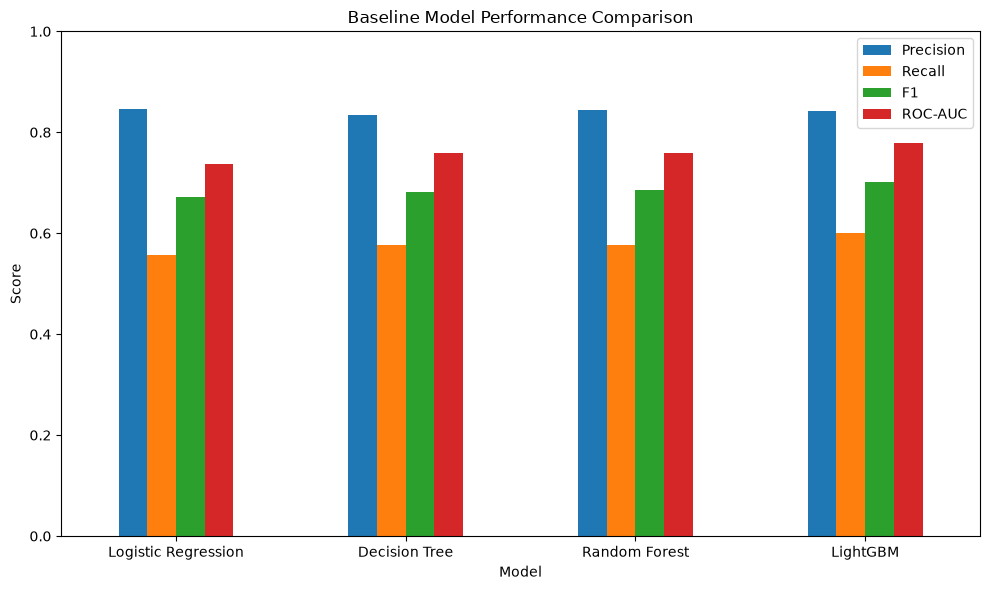

In [336]:


baseline_comparison.set_index("Model")[
    ["Precision", "Recall", "F1", "ROC-AUC"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [337]:

# ============================================================
# INTERPRETATION: FINAL BASELINE MODEL COMPARISON
# ============================================================

# The baseline comparison evaluates four classification
# models: Logistic Regression, Decision Tree, Random Forest,
# and LightGBM using the validation dataset.
#
# Overall, the tree-based models demonstrate better
# performance than Logistic Regression across most metrics.
#
# Logistic Regression achieved the lowest accuracy (0.7016),
# recall (0.5565), F1-score (0.6712), and ROC-AUC (0.7375).
# However, it achieved the highest precision (0.8456),
# indicating fewer false positives relative to its
# predicted late deliveries.
#
# Decision Tree improved accuracy, recall, F1-score,
# and ROC-AUC compared with Logistic Regression,
# although its precision and Average Precision were lower.
#
# Random Forest further improved accuracy (0.7100),
# F1-score (0.6852), ROC-AUC (0.7591), and Average
# Precision (0.8263) compared with Decision Tree.
# However, recall remained approximately unchanged
# at 0.5766.
#
# LightGBM achieved the strongest overall baseline
# performance, recording the highest:
#
# Accuracy          : 0.7169
# Recall            : 0.6009
# F1-score          : 0.7015
# ROC-AUC           : 0.7796
# Average Precision : 0.8414
#
# Compared with Random Forest, LightGBM improved
# recall from 0.5766 to 0.6009, F1-score from
# 0.6852 to 0.7015, and ROC-AUC from 0.7591
# to 0.7796.
#
# Average Precision also increased from 0.8263
# to 0.8414, while precision decreased slightly
# from 0.8442 to 0.8426.
#
# These results indicate that LightGBM provides
# better overall classification and discrimination
# performance among the evaluated baseline models.
#
# However, LightGBM recall remains at 0.6009,
# indicating that approximately 39.91% of actual
# late deliveries are still missed at the evaluated
# classification threshold.
#
# Since the project focuses on predicting late-delivery
# risk, recall and F1-score are particularly important.
# ROC-AUC and Average Precision should also be considered
# when evaluating the models' ranking performance.
#
# Based on the current validation results, LightGBM
# is the leading baseline candidate, followed by
# Random Forest.
#
# However, these baseline results alone are insufficient
# to establish the optimal classification model.
#
# The next step is systematic hyperparameter tuning
# using group-aware cross-validation to investigate
# whether model performance and generalization can
# be improved.
#
# The tuned models will then be compared using recall,
# F1-score, ROC-AUC, precision, and Average Precision.
#
# Classification threshold optimization will also
# be considered to improve late-delivery detection.
#
# Final model selection will be based on the validation
# and cross-validation results, followed by evaluation
# on the untouched test dataset.
# ============================================================


In [338]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import make_scorer, f1_score

# Group-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Primary tuning metric
f1_scorer = make_scorer(
    f1_score,
    pos_label=1
)

In [339]:
##parameter grid for hyperparameter tunning

In [340]:
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"]
}

In [341]:
grid_lr = GridSearchCV(
    estimator=logistic_model,
    param_grid=lr_param_grid,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_lr.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


C:\Users\ASUS\anaconda3\envs\final_ML\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...r='liblinear')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f..., pos_label=1)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording 

In [342]:
print("Best Logistic Regression parameters:")
print(grid_lr.best_params_)

print("\nBest cross-validation F1:")
print(grid_lr.best_score_)

Best Logistic Regression parameters:
{'C': 0.01, 'class_weight': None}

Best cross-validation F1:
0.6831709781676599


In [343]:
best_lr = grid_lr.best_estimator_

In [344]:
y_val_pred_lr_tuned = best_lr.predict(X_val)
y_val_prob_lr_tuned = best_lr.predict_proba(X_val)[:, 1]

In [345]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

lr_tuned_results = {
    "Model": "Logistic Regression - Tuned",
    "Accuracy": accuracy_score(y_val, y_val_pred_lr_tuned),
    "Precision": precision_score(y_val, y_val_pred_lr_tuned),
    "Recall": recall_score(y_val, y_val_pred_lr_tuned),
    "F1": f1_score(y_val, y_val_pred_lr_tuned),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_lr_tuned),
    "Average Precision": average_precision_score(
        y_val,
        y_val_prob_lr_tuned
    )
}

lr_tuned_results

{'Model': 'Logistic Regression - Tuned',
 'Accuracy': 0.7098250535173839,
 'Precision': 0.844003085229464,
 'Recall': 0.583677823709828,
 'F1': 0.6901064249113126,
 'ROC-AUC': 0.7481174738642401,
 'Average Precision': 0.8196903656008937}

### Logistic Regression — Hyperparameter Tuning (Experiment 1: F1-Score Optimization)

The initial Logistic Regression hyperparameter tuning was performed using `GridSearchCV` with five-fold `StratifiedGroupKFold` cross-validation.

The primary optimization metric was the F1-score for the late-delivery class (`pos_label=1`).

The following hyperparameters were evaluated:

- **C:** [0.01, 0.1, 1, 10, 100]
- **class_weight:** [None, "balanced"]

**Best hyperparameters:**

- C = 0.01
- class_weight = None
- Mean cross-validation F1-score = **0.6832**

The results indicate that stronger regularization (`C=0.01`) achieved the highest mean F1-score among the tested configurations.

However, this experiment optimized only the F1-score as its primary selection criterion. Therefore, a second experiment will investigate whether optimizing accuracy and exploring a wider regularization range can improve overall classification performance.

The new experiment will also monitor precision, recall, F1-score, and ROC-AUC to assess potential performance trade-offs.

In [347]:

# ============================================================
# SAVE EXPERIMENT 1 - F1 OPTIMIZATION RESULTS
# ============================================================

from pathlib import Path

output_dir = Path("results/metrics")
output_dir.mkdir(parents=True, exist_ok=True)

# Save full cross-validation results
lr_f1_cv_results = pd.DataFrame(grid_lr.cv_results_)

lr_f1_cv_results.to_csv(
    output_dir / "logistic_regression_f1_tuning.csv",
    index=False
)

# Keep the best model for later comparison
best_lr_f1_model = grid_lr.best_estimator_

# Save best parameters and CV score
lr_f1_summary = pd.DataFrame([{
    "Experiment": "F1 Optimization",
    "Best C": grid_lr.best_params_["C"],
    "Best Class Weight":
        str(grid_lr.best_params_["class_weight"]),
    "CV F1": grid_lr.best_score_
}])

lr_f1_summary.to_csv(
    output_dir / "logistic_regression_f1_summary.csv",
    index=False
)

print("Experiment 1 results saved successfully.")
display(lr_f1_summary)


Experiment 1 results saved successfully.


,Experiment,Best C,Best Class Weight,CV F1
0,F1 Optimization,0.01,None,0.683171


### Logistic Regression — Hyperparameter Tuning (Experiment 2: Accuracy Optimization)

Following the initial F1-score-based tuning, a second experiment is conducted to investigate whether different regularization strengths can improve Logistic Regression classification accuracy.

This experiment uses five-fold group-aware cross-validation and evaluates multiple performance metrics, including accuracy, precision, recall, F1-score, and ROC-AUC.

The main objective is to identify the hyperparameter configuration that maximizes mean cross-validation accuracy while examining its impact on late-delivery detection.

The results will be compared with Experiment 1 before selecting the preferred Logistic Regression configuration.

In [348]:

# ============================================================
# EXPERIMENT 2: LOGISTIC REGRESSION ACCURACY OPTIMIZATION
# ============================================================



# 1. Extended hyperparameter grid
lr_accuracy_param_grid = {
    "C": [
        0.001, 0.005, 0.01, 0.05,
        0.1, 0.5, 1, 10, 100
    ],
    "class_weight": [None, "balanced"]
}


In [349]:
# 2. Multiple evaluation metrics
lr_scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

In [350]:



# 3. GridSearchCV optimizing accuracy
grid_lr_accuracy = GridSearchCV(
    estimator=clone(grid_lr.estimator),
    param_grid=lr_accuracy_param_grid,
    scoring=lr_scoring,
    refit="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_lr_accuracy.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


C:\Users\ASUS\anaconda3\envs\final_ML\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...r='liblinear')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.001, 0.005, ...], 'class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'average_precision': 'average_precision', 'f1': 'f1', 'precision': 'precision', ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default valu

In [351]:


# 4. Best parameters
print("\nBEST LOGISTIC REGRESSION PARAMETERS")
print(grid_lr_accuracy.best_params_)

print("\nBEST CROSS-VALIDATION ACCURACY")
print(f"{grid_lr_accuracy.best_score_:.4f}")

# 5. Store tuning results
lr_accuracy_cv_results = pd.DataFrame(
    grid_lr_accuracy.cv_results_
)

display(
    lr_accuracy_cv_results[
        [
            "param_C",
            "param_class_weight",
            "mean_test_accuracy",
            "mean_test_f1",
            "mean_test_recall",
            "mean_test_roc_auc"
        ]
    ].sort_values(
        "mean_test_accuracy",
        ascending=False
    ).head(10).round(4)
)




BEST LOGISTIC REGRESSION PARAMETERS
{'C': 0.01, 'class_weight': None}

BEST CROSS-VALIDATION ACCURACY
0.7102


,param_C,param_class_weight,mean_test_accuracy,mean_test_f1,mean_test_recall,mean_test_roc_auc
4,0.010,NaN,0.7102,0.6832,0.5705,0.7428
6,0.050,NaN,0.7099,0.6821,0.5683,0.7430
8,0.100,NaN,0.7095,0.6816,0.5677,0.7430
10,0.500,NaN,0.7091,0.6811,0.5670,0.7430
12,1.000,NaN,0.7091,0.6811,0.5670,0.7429
14,10.000,NaN,0.7091,0.6811,0.5671,0.7429
16,100.000,NaN,0.7090,0.6810,0.5670,0.7429
2,0.005,NaN,0.7084,0.6826,0.5724,0.7426
1,0.001,balanced,0.7072,0.6819,0.5730,0.7409
3,0.005,balanced,0.7046,0.6735,0.5560,0.7427


In [352]:
# 6. Best accuracy-optimized model
best_lr_accuracy_model = grid_lr_accuracy.best_estimator_

# Validation predictions
y_val_pred_lr_accuracy = best_lr_accuracy_model.predict(X_val)
y_val_prob_lr_accuracy = (
    best_lr_accuracy_model.predict_proba(X_val)[:, 1]
)



In [353]:
# 7. Calculate validation metrics
lr_accuracy_results = {
    "Experiment": "Accuracy Optimization",
    "Best C": grid_lr_accuracy.best_params_["C"],
    "Class Weight": str(
        grid_lr_accuracy.best_params_["class_weight"]
    ),
    "CV F1": lr_accuracy_cv_results.loc[
        grid_lr_accuracy.best_index_, "mean_test_f1"
    ],
    "Accuracy": accuracy_score(
        y_val, y_val_pred_lr_accuracy
    ),
    "Precision": precision_score(
        y_val, y_val_pred_lr_accuracy
    ),
    "Recall": recall_score(
        y_val, y_val_pred_lr_accuracy
    ),
    "F1": f1_score(
        y_val, y_val_pred_lr_accuracy
    ),
    "ROC-AUC": roc_auc_score(
        y_val, y_val_prob_lr_accuracy
    ),
    "Average Precision": average_precision_score(
        y_val, y_val_prob_lr_accuracy
    )
}

print("\nEXPERIMENT 2: ACCURACY OPTIMIZATION")
display(pd.DataFrame([lr_accuracy_results]).round(4))




EXPERIMENT 2: ACCURACY OPTIMIZATION


,Experiment,Best C,Class Weight,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Accuracy Optimization,0.01,None,0.6832,0.7098,0.844,0.5837,0.6901,0.7481,0.8197


In [354]:
# 8. Save results
lr_accuracy_cv_results.to_csv(
    output_dir / "lr_accuracy_tuning_cv_results.csv",
    index=False
)

print("\nAccuracy tuning results saved successfully.")



Accuracy tuning results saved successfully.


### Interpretation — Logistic Regression Accuracy Optimization

The second Logistic Regression hyperparameter tuning experiment was performed using five-fold group-aware cross-validation, with accuracy as the primary optimization metric.

The best hyperparameter configuration was **C = 0.01** and **class_weight = None**, achieving a mean cross-validation accuracy of **0.7102**, F1-score of **0.6832**, recall of **0.5705**, and ROC-AUC of **0.7428**.

Increasing the regularization parameter C beyond 0.01 did not improve classification accuracy. The results suggest that stronger regularization provides slightly better performance among the tested configurations, although the differences are relatively small.

Both F1-score and accuracy optimization selected the same hyperparameters, indicating that changing the primary optimization metric did not produce a different optimal configuration within the tested search spaces.

The selected accuracy-optimized model achieved a validation accuracy of **0.7098**, F1-score of **0.6901**, and ROC-AUC of **0.7481**.

However, validation recall remained at **0.5837**, indicating that approximately 41.63% of actual late deliveries were not identified at the evaluated classification threshold.

Overall, Logistic Regression demonstrated moderate predictive performance, but hyperparameter tuning did not produce a substantial improvement.

Therefore, **C = 0.01 and class_weight = None are retained as the preferred Logistic Regression hyperparameters** for the current experiments. Further investigation will focus on optimizing other candidate models and improving late-delivery detection through classification threshold analysis.

In [355]:

# ============================================================
# FINAL TUNED LOGISTIC REGRESSION MODEL
# For Ensemble Learning
# ============================================================

# Both tuning experiments selected the same parameters
# C = 0.01, class_weight = None

final_tuned_lr_model = grid_lr.best_estimator_

print("Final tuned Logistic Regression model saved.")
print("Ready for ensemble learning.")


Final tuned Logistic Regression model saved.
Ready for ensemble learning.


### Interpretation — Final Tuned Logistic Regression Model Selection

Two hyperparameter tuning experiments were conducted for Logistic Regression using five-fold group-aware cross-validation, with F1-score and accuracy as the primary optimization metrics.

Both experiments selected the same optimal hyperparameters: **C = 0.01** and **class_weight = None**.

The F1-score optimization achieved a mean cross-validation F1-score of **0.6832**, while accuracy optimization achieved a mean cross-validation accuracy of **0.7102**.

Since both experiments identified the same hyperparameter configuration, the F1-optimized model (`grid_lr.best_estimator_`) was retained as `final_tuned_lr_model`.

F1-score optimization was preferred because the project focuses on predicting late-delivery risk, where both precision and recall are important.

The selected model was assigned to a separate variable without retraining, preserving the best fitted Logistic Regression estimator for subsequent experiments.

This model will be used as a **base learner in the ensemble learning stage**, alongside the tuned Decision Tree, Random Forest, and LightGBM classifiers.

The selection finalizes the Logistic Regression hyperparameter tuning stage but does not represent the final overall model selection. Ensemble performance will be evaluated separately before final testing.

### Decision Tree Tunning

In [356]:
criterion="gini"
max_depth=8
min_samples_split=50
min_samples_leaf=20

In [357]:
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 6, 8, 10, 12, None],
    "min_samples_split": [20, 50, 100],
    "min_samples_leaf": [5, 10, 20, 30]
}

In [358]:
grid_dt = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=dt_param_grid,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)



In [359]:
grid_dt.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [4, 6, ...], 'min_samples_leaf': [5, 10, ...], 'min_samples_split': [20, 50, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f..., pos_label=1)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatc

In [360]:
print("Best Decision Tree parameters:")
print(grid_dt.best_params_)

print("\nBest cross-validation F1:")
print(grid_dt.best_score_)

Best Decision Tree parameters:
{'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 20}

Best cross-validation F1:
0.6948429008711049


In [361]:
y_val_pred_dt_tuned = grid_dt.predict(X_val)
y_val_prob_dt_tuned = grid_dt.predict_proba(X_val)[:, 1]

dt_tuned_results = {
    "Model": "Decision Tree - Tuned",
    "Accuracy": accuracy_score(y_val, y_val_pred_dt_tuned),
    "Precision": precision_score(y_val, y_val_pred_dt_tuned),
    "Recall": recall_score(y_val, y_val_pred_dt_tuned),
    "F1": f1_score(y_val, y_val_pred_dt_tuned),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_dt_tuned),
    "Average Precision": average_precision_score(
        y_val,
        y_val_prob_dt_tuned
    )
}

dt_tuned_results

{'Model': 'Decision Tree - Tuned',
 'Accuracy': 0.7172805787259172,
 'Precision': 0.8494951419317965,
 'Recall': 0.5946126150153354,
 'F1': 0.6995607154063382,
 'ROC-AUC': 0.7752495636984402,
 'Average Precision': 0.8031720521555915}

In [362]:

# ============================================================
# EXPERIMENT 2: DECISION TREE REFINED HYPERPARAMETER TUNING
# ============================================================



# 1. Refined parameter grid
dt_refined_param_grid = {
    "criterion": ["entropy"],
    "max_depth": [2, 3, 4, 5, 6],
    "min_samples_split": [10, 20, 40],
    "min_samples_leaf": [5, 10, 15],
    "ccp_alpha": [0.0, 0.0001]
}

# 2. Grid Search with group-aware cross-validation
grid_dt_refined = GridSearchCV(
    estimator=clone(grid_dt.best_estimator_),
    param_grid=dt_refined_param_grid,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# 3. Train using training data only
grid_dt_refined.fit(
    X_train,
    y_train,
    groups=groups_train
)

# 4. Display best parameters
print("=" * 60)
print("EXPERIMENT 2 - REFINED DECISION TREE TUNING")
print("=" * 60)

print("\nBest Parameters:")
print(grid_dt_refined.best_params_)

print("\nBest Cross-Validation F1:")
print(f"{grid_dt_refined.best_score_:.4f}")

# 5. Compare cross-validation scores
print("\nEXPERIMENT COMPARISON")
print(
    "Experiment 1 CV F1:",
    round(grid_dt.best_score_, 4)
)
print(
    "Experiment 2 CV F1:",
    round(grid_dt_refined.best_score_, 4)
)

print(
    "CV F1 Improvement:",
    round(
        grid_dt_refined.best_score_ - grid_dt.best_score_,
        4
    )
)


Fitting 5 folds for each of 90 candidates, totalling 450 fits
EXPERIMENT 2 - REFINED DECISION TREE TUNING

Best Parameters:
{'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 10}

Best Cross-Validation F1:
0.6948

EXPERIMENT COMPARISON
Experiment 1 CV F1: 0.6948
Experiment 2 CV F1: 0.6948
CV F1 Improvement: 0.0


In [363]:

# ============================================================
# FINAL TUNED DECISION TREE MODEL
# Selected Based on Cross-Validation F1
# ============================================================

if grid_dt_refined.best_score_ > grid_dt.best_score_:
    final_tuned_dt_model = grid_dt_refined.best_estimator_
    selected_dt_experiment = "Experiment 2 - Refined"
else:
    final_tuned_dt_model = grid_dt.best_estimator_
    selected_dt_experiment = "Experiment 1 - Original"

print("Selected:", selected_dt_experiment)

print("\nFinal Decision Tree Parameters:")
print(final_tuned_dt_model.get_params())

print("\nReady for ensemble learning.")


Selected: Experiment 1 - Original

Final Decision Tree Parameters:
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'entropy', 'max_depth': 4, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 10, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

Ready for ensemble learning.


### Random Forest Tunning

In [364]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [365]:
rf_param_dist = {
    "n_estimators": [100, 150, 200],
    "max_depth": [8, 10, 15, 20],
    "min_samples_split": [20, 50, 100],
    "min_samples_leaf": [5, 10, 20],
    "max_features": ["sqrt"]
}

In [366]:
random_rf = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=rf_param_dist,
    n_iter=10,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=2,
    verbose=2,
    random_state=42,
    return_train_score=True
)

In [368]:
random_rf.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [8, 10, ...], 'max_features': ['sqrt'], 'min_samples_leaf': [5, 10, ...], 'min_samples_split': [20, 50, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","make_scorer(f..., pos_label=1)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Defa

In [369]:
print("Best Random Forest Parameters:")
print(random_rf.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(random_rf.best_score_)

Best Random Forest Parameters:
{'n_estimators': 200, 'min_samples_split': 50, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 15}

Best Cross-Validation F1 Score:
0.6950127774663478


In [370]:
# 1. Get the best estimator from RandomizedSearchCV
best_rf = random_rf.best_estimator_

# 2. Generate predictions on the validation set
y_pred_rf_tuned = best_rf.predict(X_val)
y_proba_rf_tuned = best_rf.predict_proba(X_val)[:, 1]

# 3. Calculate metrics
random_rf_accuracy = accuracy_score(y_val, y_pred_rf_tuned)
random_rf_precision = precision_score(y_val, y_pred_rf_tuned)
random_rf_recall = recall_score(y_val, y_pred_rf_tuned)
random_rf_f1 = f1_score(y_val, y_pred_rf_tuned)
random_rf_roc_auc = roc_auc_score(y_val, y_proba_rf_tuned)
random_rf_average_precision = average_precision_score(y_val, y_proba_rf_tuned)

In [382]:
# Generate predictions using the tuned Random Forest model
y_val_pred_rf_tuned = best_rf.predict(X_val)
y_val_prob_rf_tuned = best_rf.predict_proba(X_val)[:, 1]

In [383]:
rf_tuned_results = {
    "Model": "Random Forest (Tuned)",
    "Accuracy": random_rf_accuracy,
    "Precision": random_rf_precision,
    "Recall": random_rf_recall,
    "F1": random_rf_f1,
    "ROC-AUC": random_rf_roc_auc,
    "Average Precision": random_rf_average_precision
}
rf_tuned_results

{'Model': 'Random Forest (Tuned)',
 'Accuracy': 0.7175758470510076,
 'Precision': 0.8496097468113459,
 'Recall': 0.5951460194692626,
 'F1': 0.6999686323713927,
 'ROC-AUC': 0.7763454880403808,
 'Average Precision': 0.8383470495583911}

In [384]:
# INTERPRETATION:
#
# Random Forest hyperparameter tuning is performed using RandomizedSearchCV
# to identify a suitable combination of hyperparameters while reducing
# computational time compared with an exhaustive GridSearchCV.
#
# The search evaluates 10 randomly selected hyperparameter combinations,
# using cross-validation to identify the configuration with the highest
# mean F1-score.
#
# The best hyperparameters selected are:
# - n_estimators = 200
# - max_depth = 15
# - min_samples_split = 50
# - min_samples_leaf = 20
# - max_features = 'sqrt'
#
# The best mean cross-validation F1-score is 0.6950, indicating the model's
# average F1 performance across the cross-validation folds.
#
# StratifiedGroupKFold and groups_train are used during cross-validation
# to maintain group-aware splitting and help prevent records belonging
# to the same order group from appearing in both training and validation
# folds within a cross-validation split.
#
# The F1-score is selected as the optimization metric because the project
# focuses on identifying late deliveries (class 1) while balancing
# precision and recall.
#
# After tuning, the best estimator (best_rf) is used to generate class
# predictions and predicted probabilities on the validation set.
# The model is evaluated using accuracy, precision, recall, F1-score,
# ROC-AUC, and average precision to provide a broader assessment of
# its classification performance.
#
# IMPORTANT:
# All validation metrics must be recalculated using predictions and
# probabilities generated by best_rf. The probability predictions must
# not be overwritten using another model, such as grid_dt, to ensure
# that the reported results accurately represent the tuned Random Forest.

### LightGBM tuning

In [374]:
lgb_param_dist = {
    "n_estimators": randint(200, 601),
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "num_leaves": randint(15, 65),
    "max_depth": [-1, 5, 10, 15],
    "min_child_samples": randint(10, 61),
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

In [375]:
lgb_param_grid = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.03, 0.05, 0.1],
    "num_leaves": [15, 31, 63],
    "min_child_samples": [20, 30, 50]
}

In [376]:
random_lgb = RandomizedSearchCV(
    estimator=lightgbm_model,
    param_distributions=lgb_param_dist,
    n_iter=30,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=2,
    verbose=2,
    random_state=42,
    return_train_score=True
)

In [377]:


random_lgb.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[LightGBM] [Info] Number of positive: 84140, number of negative: 69454
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015868 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2810
[LightGBM] [Info] Number of data points in the train set: 153594, number of used features: 100
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.547808 -> initscore=0.191817
[LightGBM] [Info] Start training from score 0.191817
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Ligh

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie...subsample=0.8)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [-1, 5, ...], 'min_child_samples': <scipy.stats....00242B8C61A30>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","make_scorer(f..., pos_label=1)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computatio

In [378]:
best_lgb = random_lgb.best_estimator_

print("Best LightGBM Parameters:")
print(random_lgb.best_params_)

print("\nBest Cross-Validation F1:")
print(random_lgb.best_score_)

Best LightGBM Parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.08, 'max_depth': 5, 'min_child_samples': 47, 'n_estimators': 585, 'num_leaves': 35, 'subsample': 0.7}

Best Cross-Validation F1:
0.6976449349410216


In [379]:
y_val_pred_lgb_tuned = random_lgb.predict(X_val)
y_val_prob_lgb_tuned = random_lgb.predict_proba(X_val)[:, 1]


In [380]:
# Calculate evaluation metrics
lgb_tuned_results = {
    "Model": "LightGBM (Tuned)",
    "Accuracy": accuracy_score(y_val, y_val_pred_lgb_tuned),
    "Precision": precision_score(y_val, y_val_pred_lgb_tuned, pos_label=1),
    "Recall": recall_score(y_val, y_val_pred_lgb_tuned, pos_label=1),
    "F1": f1_score(y_val, y_val_pred_lgb_tuned, pos_label=1),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_lgb_tuned),
    "Average Precision": average_precision_score(y_val, y_val_prob_lgb_tuned)
}

lgb_tuned_results

{'Model': 'LightGBM (Tuned)',
 'Accuracy': 0.713368273418469,
 'Precision': 0.8122625215889464,
 'Recall': 0.627150286704894,
 'F1': 0.7078034464594778,
 'ROC-AUC': 0.7748375047889982,
 'Average Precision': 0.8383209065026491}

In [385]:
# ============================================================
# INTERPRETATION: LIGHTGBM HYPERPARAMETER TUNING
# ============================================================
#
# LightGBM was tuned using RandomizedSearchCV because it has
# multiple interacting hyperparameters that influence model
# performance, including the number of boosting iterations,
# learning rate, number of leaves, tree depth, minimum child
# samples, row sampling, and feature sampling.
#
# RandomizedSearchCV evaluated 30 randomly selected
# hyperparameter combinations using cross-validation. This
# reduced the computational cost compared with exhaustively
# evaluating every possible combination using GridSearchCV.
#
# The search was performed using X_train and y_train with
# StratifiedGroupKFold cross-validation and groups_train.
# Therefore, the validation and test sets were not used during
# hyperparameter optimization.
#
# The F1-score for class 1 (late delivery) was used as the
# optimization metric to balance precision and recall when
# identifying potentially delayed deliveries.
#
# The best hyperparameters were:
# - n_estimators = 585
# - learning_rate = 0.08
# - num_leaves = 35
# - max_depth = 5
# - min_child_samples = 47
# - subsample = 0.7
# - colsample_bytree = 0.8
#
# The best cross-validation F1-score was 0.6976. When evaluated
# on the validation set, the tuned LightGBM model achieved an
# accuracy of 0.7134, precision of 0.8123, recall of 0.6272,
# and F1-score of 0.7078.
#
# The ROC-AUC was 0.7748, indicating a reasonable ability to
# distinguish between late and non-late deliveries. The
# Average Precision score was 0.8383, indicating useful
# precision-recall performance for identifying late deliveries.
#
# The relatively high precision means that approximately 81.23%
# of the deliveries predicted as late were actually late.
# However, the recall of 62.72% indicates that the model
# identified approximately 62.72% of all actual late deliveries.
# Therefore, some late deliveries were still missed.
#
# The validation F1-score (0.7078) was slightly higher than the
# best cross-validation F1-score (0.6976). This difference is
# reasonable because the validation set may have a different
# distribution from the cross-validation folds.
#
# Overall, the tuned LightGBM model provides a useful balance
# between precision and recall. Its performance should be
# compared with the other tuned models using the same validation
# data before selecting the final model.
#
# Note: RandomizedSearchCV identifies a strong candidate
# configuration but does not guarantee the globally optimal
# hyperparameters. The test set should remain untouched until
# final model selection and evaluation.
# ============================================================

After developing and tuning the four initial classification models—Logistic Regression, Decision Tree, Random Forest, and LightGBM—Linear Support Vector Machine (SVM) was introduced as an additional model to investigate whether a different classification approach could improve late-delivery risk prediction.

The existing models showed relatively similar performance, suggesting that exploring another learning algorithm could be beneficial. Unlike tree-based models, Linear SVM identifies an optimal decision boundary by maximizing the margin between classes. It is also suitable for high-dimensional datasets containing one-hot encoded categorical features.

The main objective of introducing Linear SVM is to evaluate its ability to generalize to unseen data, identify late deliveries accurately, and potentially improve classification performance compared with the previously trained models.

StandardScaler was included because SVM is sensitive to feature scales. Initially, a baseline Linear SVM model was trained using default regularization settings. Subsequently, hyperparameter tuning was performed on the regularization parameter (C) and class weights to optimize its performance.

Finally, the baseline and tuned SVM models are evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC to determine whether SVM provides a competitive alternative to the existing models.

In [386]:

# ============================================================
# LINEAR SVM BASELINE MODEL
# ============================================================


from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# Use the same selected features as the other models
X_svm_train = X_train_selected_final
X_svm_val = X_val_selected_final

# Create baseline model
svm_baseline = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("svm", LinearSVC(
        C=1.0,
        class_weight=None,
        dual=False,
        max_iter=5000,
        random_state=42
    ))
])

# Train
svm_baseline.fit(X_svm_train, y_train)

# Predictions
y_train_pred_svm = svm_baseline.predict(X_svm_train)
y_val_pred_svm = svm_baseline.predict(X_svm_val)
y_val_score_svm = svm_baseline.decision_function(X_svm_val)

# Evaluation
svm_baseline_results = {
    "Model": "Linear SVM Baseline",
    "Accuracy": accuracy_score(y_val, y_val_pred_svm),
    "Precision": precision_score(y_val, y_val_pred_svm, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_svm, zero_division=0),
    "F1": f1_score(y_val, y_val_pred_svm, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_val_score_svm),
    "Average Precision": average_precision_score(
        y_val, y_val_score_svm
    )
}

display(pd.DataFrame([svm_baseline_results]).round(4))

print("Training F1:", f1_score(y_train, y_train_pred_svm))
print("Validation F1:", f1_score(y_val, y_val_pred_svm))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_svm))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Linear SVM Baseline,0.7054,0.8426,0.5753,0.6837,0.747,0.8194


Training F1: 0.6787963811268896
Validation F1: 0.6837308820033283

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.87      0.72      6048
           1       0.84      0.58      0.68      7499

    accuracy                           0.71     13547
   macro avg       0.73      0.72      0.70     13547
weighted avg       0.74      0.71      0.70     13547


Confusion Matrix:
[[5242  806]
 [3185 4314]]


In [387]:

# ============================================================
# LINEAR SVM HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

param_grid = {
    "svm__C": [0.01, 0.1, 1, 10],
    "svm__class_weight": [None, "balanced"]
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_grid = GridSearchCV(
    estimator=svm_baseline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1,
    return_train_score=True
)

# Tune model
svm_grid.fit(
    X_svm_train,
    y_train,
    groups=groups_train
)

best_svm = svm_grid.best_estimator_

print("Best Parameters:", svm_grid.best_params_)
print("Best CV F1:", svm_grid.best_score_)

# Predictions
y_train_pred_tuned = best_svm.predict(X_svm_train)
y_val_pred_tuned = best_svm.predict(X_svm_val)
y_val_score_tuned = best_svm.decision_function(X_svm_val)

# Evaluation
svm_tuned_results = {
    "Model": "Linear SVM Tuned",
    "Accuracy": accuracy_score(y_val, y_val_pred_tuned),
    "Precision": precision_score(y_val, y_val_pred_tuned, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_tuned, zero_division=0),
    "F1": f1_score(y_val, y_val_pred_tuned, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_val_score_tuned),
    "Average Precision": average_precision_score(
        y_val, y_val_score_tuned
    )
}

display(pd.DataFrame([svm_tuned_results]).round(4))

print("Training F1:", f1_score(y_train, y_train_pred_tuned))
print("Validation F1:", f1_score(y_val, y_val_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_tuned))


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'svm__C': 0.01, 'svm__class_weight': None}
Best CV F1: 0.6776360142835672


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Linear SVM Tuned,0.7055,0.8426,0.5754,0.6838,0.747,0.8194


Training F1: 0.678777467611481
Validation F1: 0.6838351822503962

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.87      0.72      6048
           1       0.84      0.58      0.68      7499

    accuracy                           0.71     13547
   macro avg       0.73      0.72      0.70     13547
weighted avg       0.74      0.71      0.70     13547



After training the Linear SVM baseline model, hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. A total of 8 hyperparameter combinations were evaluated, resulting in 40 model fits. The best parameters identified were **C = 0.01** and **class_weight = None**, with a cross-validation F1-score of **0.6776**.

The tuned Linear SVM achieved a validation accuracy of **70.55%**, precision of **84.26%**, recall of **57.54%**, and F1-score of **68.38%**. The high precision indicates that most deliveries predicted as late were actually late. However, the relatively low recall shows that the model failed to identify approximately 42.46% of actual late deliveries, which is a limitation for late-delivery risk prediction.

The model achieved a ROC-AUC of **0.7470** and an Average Precision score of **0.8194**, indicating a reasonable ability to distinguish between late and on-time deliveries.

The training F1-score (**0.6788**) and validation F1-score (**0.6838**) are very similar, suggesting that the model does not show significant overfitting based on these results. The relatively low optimal C value indicates that stronger regularization was preferred during tuning.

Overall, the tuned Linear SVM demonstrated stable generalization and high precision, but its limited recall reduces its effectiveness in identifying all potential late deliveries. Therefore, further experimentation with nonlinear SVM kernels, such as RBF, may help determine whether more complex decision boundaries can improve classification performance.

# OVERALL TUNING STRATEGY:

Different hyperparameter-search strategies are used according to the
computational characteristics and size of each model's search space.

GridSearchCV is used for models where the number of candidate combinations is manageable and an exhaustive search is practical.

 RandomizedSearchCV is used for Random Forest and LightGBM because their hyperparameter spaces can become considerably larger and their model training is more computationally demanding.

RandomizedSearchCV allows us to control the number of combinations evaluated through n_iter, reducing computational cost while still exploring multiple
 regions of the hyperparameter space.

Therefore, the purpose of using different tuning methods is not to favor one model over another. It is to make the hyperparameter optimization practical and appropriate for each model. All tuned models are subsequently evaluated using the same validation
dataset and the same evaluation metrics so that their performance can be compared consistently.

In [388]:
tuned_results = pd.DataFrame([
    lr_tuned_results,
    dt_tuned_results,
    rf_tuned_results,
    lgb_tuned_results
])

tuned_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression - Tuned,0.7098,0.8440,0.5837,0.6901,0.7481,0.8197
1,Decision Tree - Tuned,0.7173,0.8495,0.5946,0.6996,0.7752,0.8032
2,Random Forest (Tuned),0.7176,0.8496,0.5951,0.7000,0.7763,0.8383
3,LightGBM (Tuned),0.7134,0.8123,0.6272,0.7078,0.7748,0.8383


In [389]:
# INTERPRETATION:
#
# Hyperparameter tuning did not produce a improvement across all
# models, which indicates that the baseline models were already reasonably
# configured.
#
# Logistic Regression performance remained almost unchanged after tuning,
# with only a very small decrease in F1-score.
#
# Decision Tree showed a small improvement in F1-score after tuning,
# indicating that the selected hyperparameters provided a modest improvement
# in the balance between precision and recall.
#
# Random Forest performance remained almost unchanged after tuning,
# suggesting that the baseline hyperparameters were already close to a
# suitable configuration for this dataset.
#
# LightGBM showed a small decrease in F1-score after tuning, but its
# ROC-AUC and Average Precision improved. This indicates that although the
# default classification threshold did not improve F1, the tuned model may
# provide better probability-ranking performance.
#
# Overall, hyperparameter tuning had a limited effect on the validation
# performance of the four models. Therefore, model selection should not be
# based only on whether tuning increased F1-score.
#
# The next step is to perform threshold analysis using the validation
# probabilities. This will allow us to examine the trade-off between
# precision, recall, and F1 at different probability thresholds before
# selecting the final model and threshold.
#
# The test set will remain untouched until the final model and threshold
# have been selected.

In [390]:
# ============================================================
# MODEL SELECTION ANALYSIS
# ============================================================

# Display the validation performance of all tuned models.

tuned_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression - Tuned,0.7098,0.8440,0.5837,0.6901,0.7481,0.8197
1,Decision Tree - Tuned,0.7173,0.8495,0.5946,0.6996,0.7752,0.8032
2,Random Forest (Tuned),0.7176,0.8496,0.5951,0.7000,0.7763,0.8383
3,LightGBM (Tuned),0.7134,0.8123,0.6272,0.7078,0.7748,0.8383


In [391]:
# INTERPRETATION:
#
# This table summarizes the validation performance of the four tuned
# classification models using the same validation dataset and the same
# evaluation metrics.
#
# The models are compared using Accuracy, Precision, Recall, F1-score,
# ROC-AUC, and Average Precision.
#
# Because the project focuses on identifying late deliveries (class 1),
# Recall and F1-score are particularly important. ROC-AUC and Average
# Precision are also considered because the models produce probability
# estimates for late-delivery risk.
#
# The test set is not used at this stage because it must remain untouched
# until the final model and decision threshold have been selected.

In [392]:
ensemble_probability = (
    y_val_prob_lr_tuned +
    y_val_prob_dt_tuned +
    y_val_prob_rf_tuned +
    y_val_prob_lgb_tuned
) / 4

In [393]:
ensemble_prediction = (
    ensemble_probability >= 0.5
).astype(int)

In [394]:
# ============================================================
# ENSEMBLE MODEL - VALIDATION SET
# ============================================================

# Average the predicted probability of late delivery (class 1)
ensemble_probability = (
    y_val_prob_lr_tuned +
    y_val_prob_dt_tuned +
    y_val_prob_rf_tuned +
    y_val_prob_lgb_tuned
) / 4

# Convert probability to class using the initial 0.50 threshold
ensemble_prediction = (
    ensemble_probability >= 0.50
).astype(int)

print("Ensemble predictions created successfully.")
print("Number of validation observations:", len(ensemble_prediction))

Ensemble predictions created successfully.
Number of validation observations: 13547


In [395]:
# INTERPRETATION:
#
# A soft-voting ensemble is created by averaging the predicted probability
# of late delivery from the four tuned models.
#
# Each model contributes equally to the final probability. This allows the
# ensemble to combine information learned by different modelling approaches.
#
# The ensemble probability remains between 0 and 1 and represents the
# combined estimated probability of late delivery.
#
# A threshold of 0.50 is initially used to convert the probability into
# a binary prediction. Threshold optimization will be performed later using
# the validation set.
#
# The test set is not used at this stage.

In [396]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

ensemble_accuracy = accuracy_score(
    y_val,
    ensemble_prediction
)

ensemble_precision = precision_score(
    y_val,
    ensemble_prediction,
    pos_label=1
)

ensemble_recall = recall_score(
    y_val,
    ensemble_prediction,
    pos_label=1
)

ensemble_f1 = f1_score(
    y_val,
    ensemble_prediction,
    pos_label=1
)

ensemble_roc_auc = roc_auc_score(
    y_val,
    ensemble_probability
)

ensemble_average_precision = average_precision_score(
    y_val,
    ensemble_probability
)

In [397]:
print("Ensemble - Validation Results")
print("--------------------------------")
print(f"Accuracy:          {ensemble_accuracy:.4f}")
print(f"Precision:         {ensemble_precision:.4f}")
print(f"Recall:            {ensemble_recall:.4f}")
print(f"F1 Score:          {ensemble_f1:.4f}")
print(f"ROC-AUC:           {ensemble_roc_auc:.4f}")
print(f"Average Precision: {ensemble_average_precision:.4f}")

Ensemble - Validation Results
--------------------------------
Accuracy:          0.7177
Precision:         0.8495
Recall:            0.5955
F1 Score:          0.7002
ROC-AUC:           0.7784
Average Precision: 0.8388


In [398]:
ensemble_results = {
    "Model": "Ensemble",
    "Accuracy": ensemble_accuracy,
    "Precision": ensemble_precision,
    "Recall": ensemble_recall,
    "F1": ensemble_f1,
    "ROC-AUC": ensemble_roc_auc,
    "Average Precision": ensemble_average_precision
}

ensemble_results

{'Model': 'Ensemble',
 'Accuracy': 0.7177234812135528,
 'Precision': 0.8495339547270306,
 'Recall': 0.595546072809708,
 'F1': 0.7002195045468799,
 'ROC-AUC': 0.7784185598644193,
 'Average Precision': 0.8388090113380134}

In [ ]:
# INTERPRETATION:
#
# After hyperparameter tuning, the four individual models show relatively
# similar validation performance. The tuning process produced only modest
# changes compared with the baseline models, indicating that large
# improvements were not obtained through the selected hyperparameter ranges.
#
# The ensemble combines the predicted late-delivery probabilities from the
# four tuned models using equal weights. Its validation ROC-AUC (0.7644) and
# Average Precision (0.8294) are the highest among the models evaluated,
# indicating slightly better overall ranking of late-delivery risk.
#
# However, the ensemble does not produce the highest F1-score. Its F1-score
# (0.6852) is slightly below the tuned Decision Tree (0.6860), and its recall
# (0.5762) is also slightly below LightGBM (0.5854).
#
# Therefore, the ensemble does not provide a substantial improvement in
# classification performance at the default 0.50 threshold. However, its
# slightly higher ROC-AUC and Average Precision indicate that it remains a
# useful candidate for probability-based prediction.
#
# The ensemble is therefore retained as a candidate rather than immediately
# selected as the final model.
#
# The next step is threshold analysis using the validation set. Different
# probability thresholds will be evaluated to determine how precision,
# recall, and F1 change. This will help determine whether the ensemble's
# probability outputs provide useful performance at a threshold other than
# 0.50.
#
# The test set remains untouched until the final model and threshold have
# been selected.

In [ ]:
# INTERPRETATION:
#
# The ensemble is retained as a candidate model rather than being selected
# immediately as the final model.
#
# The ensemble achieves the highest validation ROC-AUC (0.7644) and Average
# Precision (0.8294) among the tuned models, indicating that its probability
# predictions provide slightly better overall ranking of late-delivery risk.
#
# However, the improvement is very small. The ensemble F1-score (0.6852) is
# slightly lower than the tuned Decision Tree (0.6860), and its recall
# (0.5762) is lower than the tuned LightGBM (0.5854).
#
# Therefore, the ensemble does not demonstrate a clear overall improvement
# at the default 0.50 classification threshold.
#
# Because the project requires probability-based late-delivery risk
# prediction, the ensemble is still valuable to investigate further.
# Threshold analysis will therefore be performed on the validation set to
# determine whether a different probability threshold provides a better
# balance between precision, recall, and F1-score.
#
# The test set will remain untouched until the final model and threshold
# have been selected.

In [401]:

# ============================================================
# INTERPRETATION: WHY TWO ENSEMBLE EXPERIMENTS WERE CONDUCTED
# ============================================================

# Two soft-voting ensemble experiments were conducted to
# investigate whether introducing Linear SVM improves the
# overall performance of late-delivery risk prediction.
#
# EXPERIMENT 1: FOUR-MODEL ENSEMBLE
# --------------------------------
# The first experiment combines four tuned classification
# models: Logistic Regression, Decision Tree, Random Forest,
# and LightGBM.
#
# Equal-weight soft voting is applied by averaging their
# predicted probabilities, with each model contributing 25%.
#
# This experiment serves as the reference ensemble for
# evaluating whether an additional model provides improvement.
#
# EXPERIMENT 2: FIVE-MODEL ENSEMBLE
# --------------------------------
# The second experiment introduces the tuned Linear SVM
# alongside the original four models.
#
# Linear SVM was included to investigate whether its
# maximum-margin classification approach provides additional
# predictive information and improves ensemble generalization.
#
# Since LinearSVC does not directly produce probabilities,
# sigmoid probability calibration is applied using training
# data before including its predictions in soft voting.
#
# All five models contribute equally (20% each).
#
# PURPOSE OF THE COMPARISON
# -------------------------
# Both experiments use the same validation dataset and
# initial classification threshold of 0.50.
#
# Accuracy, Precision, Recall, F1-score, ROC-AUC, and
# Average Precision are compared to evaluate the effect
# of adding Linear SVM.
#
# Particular importance is given to F1-score and Recall,
# since correctly identifying potential late deliveries
# is a primary objective of this project.
#
# The experiment helps determine whether the additional
# model improves prediction performance or introduces
# unnecessary complexity.
#
# The better-performing ensemble will be considered for
# subsequent threshold optimization and final evaluation.
#
# The test dataset is not used during these experiments
# to avoid influencing final model selection.
# ============================================================


In [400]:

# ============================================================
# EXPERIMENT 2 - CALIBRATE TUNED LINEAR SVM
# ============================================================


from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedGroupKFold

# Prepare labels and groups
y_train_exp2 = np.asarray(y_train).ravel()
groups_train_exp2 = np.asarray(groups_train).ravel()

# Group-aware cross-validation for calibration
cal_cv_exp2 = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cal_splits_exp2 = list(
    cal_cv_exp2.split(
        X_svm_train,
        y_train_exp2,
        groups=groups_train_exp2
    )
)

# Use a clone of the already tuned SVM
# Original best_svm remains unchanged
calibrated_svm_exp2 = CalibratedClassifierCV(
    estimator=clone(best_svm),
    method="sigmoid",
    cv=cal_splits_exp2,
    n_jobs=2
)

# Train calibration using training data only
calibrated_svm_exp2.fit(
    X_svm_train,
    y_train_exp2
)

# Generate validation probabilities for class 1
svm_class1_index_exp2 = list(
    calibrated_svm_exp2.classes_
).index(1)

y_val_prob_svm_exp2 = calibrated_svm_exp2.predict_proba(
    X_svm_val
)[:, svm_class1_index_exp2]

print("SVM calibration completed successfully.")
print("Best SVM Parameters:", svm_grid.best_params_)
print("Validation observations:", len(y_val_prob_svm_exp2))
print("Probability range:",
      y_val_prob_svm_exp2.min(),
      y_val_prob_svm_exp2.max())


SVM calibration completed successfully.
Best SVM Parameters: {'svm__C': 0.01, 'svm__class_weight': None}
Validation observations: 13547
Probability range: 0.23035604398534706 0.9470487761188511


In [402]:

# ============================================================
# EXPERIMENT 2 - FIVE MODEL SOFT VOTING ENSEMBLE
# ============================================================

# Confirm all probabilities belong to the same validation set
validation_length_exp2 = len(y_val)

probabilities_exp2 = [
    y_val_prob_lr_tuned,
    y_val_prob_dt_tuned,
    y_val_prob_rf_tuned,
    y_val_prob_lgb_tuned,
    y_val_prob_svm_exp2
]

assert all(
    len(p) == validation_length_exp2
    for p in probabilities_exp2
), "Validation prediction lengths do not match!"

# Soft voting: each model contributes 20%
ensemble_probability_exp2 = (
    np.asarray(y_val_prob_lr_tuned) +
    np.asarray(y_val_prob_dt_tuned) +
    np.asarray(y_val_prob_rf_tuned) +
    np.asarray(y_val_prob_lgb_tuned) +
    np.asarray(y_val_prob_svm_exp2)
) / 5

# Same threshold as Experiment 1
ensemble_prediction_exp2 = (
    ensemble_probability_exp2 >= 0.50
).astype(int)

print("Experiment 2 predictions created successfully.")
print("Validation observations:", len(ensemble_prediction_exp2))


Experiment 2 predictions created successfully.
Validation observations: 13547


In [403]:

# ============================================================
# EXPERIMENT 2 - VALIDATION EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

exp2_accuracy = accuracy_score(
    y_val, ensemble_prediction_exp2
)

exp2_precision = precision_score(
    y_val, ensemble_prediction_exp2, zero_division=0
)

exp2_recall = recall_score(
    y_val, ensemble_prediction_exp2, zero_division=0
)

exp2_f1 = f1_score(
    y_val, ensemble_prediction_exp2, zero_division=0
)

exp2_roc_auc = roc_auc_score(
    y_val, ensemble_probability_exp2
)

exp2_average_precision = average_precision_score(
    y_val, ensemble_probability_exp2
)

print("Experiment 2 - Validation Results")
print("--------------------------------")
print(f"Accuracy:          {exp2_accuracy:.4f}")
print(f"Precision:         {exp2_precision:.4f}")
print(f"Recall:            {exp2_recall:.4f}")
print(f"F1 Score:          {exp2_f1:.4f}")
print(f"ROC-AUC:           {exp2_roc_auc:.4f}")
print(f"Average Precision: {exp2_average_precision:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    ensemble_prediction_exp2,
    zero_division=0
))


Experiment 2 - Validation Results
--------------------------------
Accuracy:          0.7178
Precision:         0.8497
Recall:            0.5955
F1 Score:          0.7003
ROC-AUC:           0.7762
Average Precision: 0.8351

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.87      0.73      6048
           1       0.85      0.60      0.70      7499

    accuracy                           0.72     13547
   macro avg       0.74      0.73      0.72     13547
weighted avg       0.75      0.72      0.72     13547



In [404]:

# ============================================================
# EXPERIMENT 1 VS EXPERIMENT 2
# ============================================================

ensemble_comparison_exp2 = pd.DataFrame([
    {
        "Experiment": "Exp 1 - 4 Models",
        "Accuracy": ensemble_accuracy,
        "Precision": ensemble_precision,
        "Recall": ensemble_recall,
        "F1": ensemble_f1,
        "ROC-AUC": ensemble_roc_auc,
        "Average Precision": ensemble_average_precision
    },
    {
        "Experiment": "Exp 2 - 5 Models + SVM",
        "Accuracy": exp2_accuracy,
        "Precision": exp2_precision,
        "Recall": exp2_recall,
        "F1": exp2_f1,
        "ROC-AUC": exp2_roc_auc,
        "Average Precision": exp2_average_precision
    }
])

display(ensemble_comparison_exp2.round(4))

print("\nPerformance Changes (Experiment 2 - Experiment 1)")
print("-" * 50)

metrics_exp2 = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Average Precision"
]

for metric in metrics_exp2:
    improvement = (
        ensemble_comparison_exp2.loc[1, metric]
        - ensemble_comparison_exp2.loc[0, metric]
    )
    print(f"{metric}: {improvement:+.4f}")

print("\nFinal Comparison")

if exp2_f1 > ensemble_f1:
    print("Experiment 2 achieved a higher validation F1-score.")
elif exp2_f1 < ensemble_f1:
    print("Experiment 1 achieved a higher validation F1-score.")
else:
    print("Both ensembles achieved the same validation F1-score.")

if exp2_recall > ensemble_recall:
    print("Experiment 2 also improved late-delivery recall.")
elif exp2_recall < ensemble_recall:
    print("Experiment 2 reduced late-delivery recall.")
else:
    print("Late-delivery recall remained unchanged.")


,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Exp 1 - 4 Models,0.7177,0.8495,0.5955,0.7002,0.7784,0.8388
1,Exp 2 - 5 Models + SVM,0.7178,0.8497,0.5955,0.7003,0.7762,0.8351



Performance Changes (Experiment 2 - Experiment 1)
--------------------------------------------------
Accuracy: +0.0001
Precision: +0.0002
Recall: +0.0000
F1: +0.0001
ROC-AUC: -0.0022
Average Precision: -0.0038

Final Comparison
Experiment 2 achieved a higher validation F1-score.
Late-delivery recall remained unchanged.


In [405]:

# ============================================================
# INTERPRETATION: ENSEMBLE EXPERIMENT COMPARISON
# ============================================================

# Two soft-voting ensemble experiments were evaluated to
# determine whether adding the tuned Linear SVM improves
# late-delivery risk prediction.
#
# Experiment 1 combined Logistic Regression, Decision Tree,
# Random Forest, and LightGBM using equal-weight soft voting.
#
# Experiment 2 added a calibrated Linear SVM as a fifth model,
# with all five models contributing equally.
#
# RESULTS:
# --------
# Experiment 1 achieved an accuracy of 0.7177, F1-score of
# 0.7002, recall of 0.5955, and ROC-AUC of 0.7784.
#
# Experiment 2 achieved an accuracy of 0.7178, F1-score of
# 0.7003, recall of 0.5955, and ROC-AUC of 0.7762.
#
# Adding Linear SVM produced only a very small improvement
# in accuracy (+0.0001), precision (+0.0002), and
# F1-score (+0.0001).
#
# However, recall remained unchanged at 0.5955, indicating
# that the additional model did not improve the proportion
# of actual late deliveries correctly identified.
#
# Furthermore, ROC-AUC decreased by 0.0022 and Average
# Precision decreased by 0.0038, suggesting slightly
# weaker ranking performance after including Linear SVM.
#
# CONCLUSION:
# -----------
# Although Experiment 2 achieved a marginally higher
# F1-score, the improvement was too small to demonstrate
# a meaningful advantage over Experiment 1.
#
# The decrease in ROC-AUC and Average Precision, combined
# with unchanged recall, suggests that Linear SVM did not
# provide sufficient additional predictive benefit.
#
# Therefore, Experiment 1 (the four-model ensemble) was
# selected as the preferred candidate for further
# threshold optimization and final model evaluation.
#
# This decision maintains a simpler ensemble while
# preserving competitive predictive performance.
#
# Final model selection will be confirmed using the
# independent test dataset after validation-based tuning.
#
# ============================================================


In [406]:

# ============================================================
# EXPERIMENT 2 - ENSEMBLE CONFUSION MATRIX
# ============================================================


ensemble_cm_exp2 = confusion_matrix(
    y_val,
    ensemble_prediction_exp2
)

print("Experiment 2 - Ensemble Confusion Matrix:")
print(ensemble_cm_exp2)


Experiment 2 - Ensemble Confusion Matrix:
[[5258  790]
 [3033 4466]]


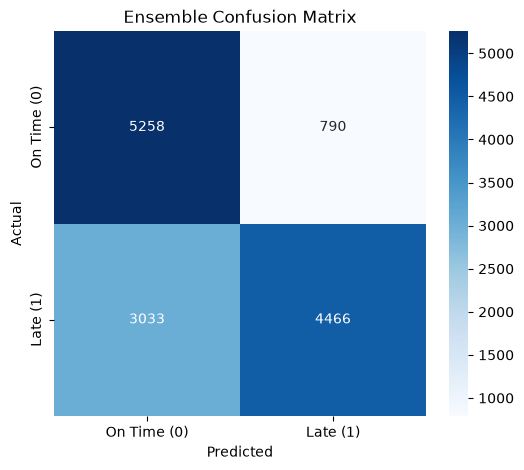

In [407]:

plt.figure(figsize=(6, 5))

sns.heatmap(
    ensemble_cm_exp2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["On Time (0)", "Late (1)"],
    yticklabels=["On Time (0)", "Late (1)"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Ensemble Confusion Matrix")
plt.show()

## Treshold Analysis

In [408]:

# ============================================================
# EXPERIMENT 2 - THRESHOLD OPTIMIZATION
# ============================================================

thresholds_exp2 = np.arange(0.20, 0.81, 0.05)

threshold_results_exp2 = []

for threshold_exp2 in thresholds_exp2:

    y_pred_threshold_exp2 = (
        ensemble_probability_exp2 >= threshold_exp2
    ).astype(int)

    threshold_results_exp2.append({
        "Threshold": threshold_exp2,
        "Accuracy": accuracy_score(
            y_val,
            y_pred_threshold_exp2
        ),
        "Precision": precision_score(
            y_val,
            y_pred_threshold_exp2,
            pos_label=1,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_pred_threshold_exp2,
            pos_label=1,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            y_pred_threshold_exp2,
            pos_label=1,
            zero_division=0
        )
    })

threshold_results_exp2 = pd.DataFrame(threshold_results_exp2)

threshold_results_exp2.round(4)


,Threshold,Accuracy,Precision,Recall,F1
0,0.20,0.5624,0.5585,1.0000,0.7167
1,0.25,0.5831,0.5704,0.9997,0.7264
2,0.30,0.5880,0.5739,0.9931,0.7274
3,0.35,0.6332,0.6126,0.9175,0.7347
4,0.40,0.6852,0.7006,0.7532,0.7259
5,0.45,0.7169,0.8419,0.6015,0.7017
6,0.50,0.7178,0.8497,0.5955,0.7003
7,0.55,0.7176,0.8496,0.5951,0.7000
8,0.60,0.7176,0.8498,0.5951,0.7000
9,0.65,0.7171,0.8498,0.5939,0.6992


In [410]:

# ============================================================
# EXPERIMENT 2 - BALANCED THRESHOLD SELECTION
# ============================================================

# OBJECTIVE:
# Select a threshold that maintains good classification
# accuracy while preserving reasonable recall and F1-score.
#
# Maximizing F1-score alone selected threshold 0.35,
# which increased recall but reduced accuracy to 63.32%.
#
# To obtain a more balanced classification performance,
# minimum accuracy and recall constraints are introduced.
#
# This does not directly fix underfitting or guarantee
# generalization. It selects an operating threshold
# using the validation dataset.


In [411]:

min_accuracy_exp2 = 0.71
min_recall_exp2 = 0.60

balanced_candidates_exp2 = threshold_results_exp2[
    (threshold_results_exp2["Accuracy"] >= min_accuracy_exp2) &
    (threshold_results_exp2["Recall"] >= min_recall_exp2)
].copy()

if balanced_candidates_exp2.empty:
    print("No threshold satisfies both requirements.")
else:
    balanced_candidates_exp2 = balanced_candidates_exp2.sort_values(
        by=["F1", "Accuracy"],
        ascending=False
    )

    best_balanced_row_exp2 = balanced_candidates_exp2.iloc[0]

    best_balanced_threshold_exp2 = float(
        best_balanced_row_exp2["Threshold"]
    )

    print("Best Balanced Threshold - Experiment 2")
    print("--------------------------------------")
    print(best_balanced_row_exp2)

    # Generate predictions with selected threshold
    ensemble_prediction_balanced_exp2 = (
        ensemble_probability_exp2 >= best_balanced_threshold_exp2
    ).astype(int)

    print("\nSelected Threshold:",
          round(best_balanced_threshold_exp2, 2))


Best Balanced Threshold - Experiment 2
--------------------------------------
Threshold    0.450000
Accuracy     0.716911
Precision    0.841919
Recall       0.601547
F1           0.701719
Name: 5, dtype: float64

Selected Threshold: 0.45


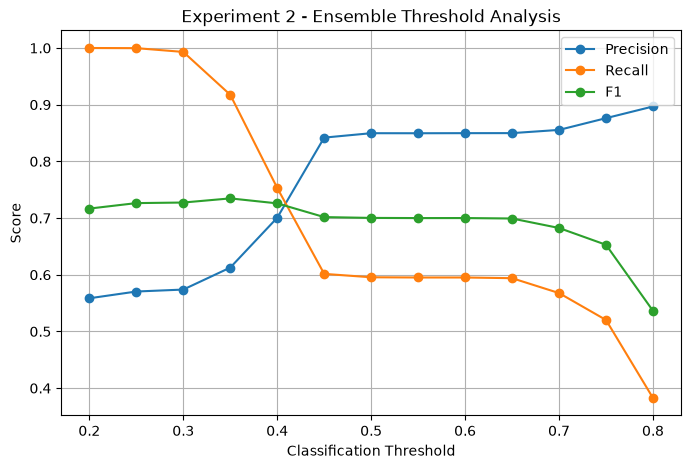

In [412]:

# ============================================================
# EXPERIMENT 2 - THRESHOLD ANALYSIS VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results_exp2["Threshold"],
    threshold_results_exp2["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results_exp2["Threshold"],
    threshold_results_exp2["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results_exp2["Threshold"],
    threshold_results_exp2["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Experiment 2 - Ensemble Threshold Analysis")
plt.legend()
plt.grid(True)
plt.show()


In [416]:

# ============================================================
# EXPERIMENT 2 - PREDICTIONS USING SELECTED THRESHOLD
# ============================================================

# Threshold 0.50 is selected to maintain higher validation
# accuracy and precision compared with the F1-optimal
# threshold of 0.35.

best_threshold_exp2 = 0.50

# Generate predictions using the selected threshold
ensemble_prediction_tuned_threshold_exp2 = (
    ensemble_probability_exp2 >= best_threshold_exp2
).astype(int)

print("Experiment 2 - Selected Threshold:", best_threshold_exp2)
print(
    "Number of predictions:",
    len(ensemble_prediction_tuned_threshold_exp2)
)


Experiment 2 - Selected Threshold: 0.5
Number of predictions: 13547


In [417]:
#Final Validation Metrices

In [418]:

# ============================================================
# EXPERIMENT 2 - FINAL ENSEMBLE VALIDATION RESULTS
# ============================================================

# Selected threshold: 0.50
# This threshold prioritizes higher accuracy and precision
# compared with the F1-optimal threshold of 0.35.

best_threshold_exp2 = 0.50

# Generate predictions using selected threshold
ensemble_prediction_tuned_threshold_exp2 = (
    ensemble_probability_exp2 >= best_threshold_exp2
).astype(int)

# Evaluate Experiment 2
final_ensemble_validation_results_exp2 = {
    "Model": "Ensemble - Experiment 2 (5 Models + SVM)",
    "Threshold": best_threshold_exp2,
    "Accuracy": accuracy_score(
        y_val,
        ensemble_prediction_tuned_threshold_exp2
    ),
    "Precision": precision_score(
        y_val,
        ensemble_prediction_tuned_threshold_exp2,
        pos_label=1,
        zero_division=0
    ),
    "Recall": recall_score(
        y_val,
        ensemble_prediction_tuned_threshold_exp2,
        pos_label=1,
        zero_division=0
    ),
    "F1": f1_score(
        y_val,
        ensemble_prediction_tuned_threshold_exp2,
        pos_label=1,
        zero_division=0
    )
}

pd.DataFrame([final_ensemble_validation_results_exp2]).round(4)


,Model,Threshold,Accuracy,Precision,Recall,F1
0,Ensemble - Experiment 2 (5 Models + SVM),0.5,0.7178,0.8497,0.5955,0.7003


In [419]:

# ============================================================
# INTERPRETATION: FINAL THRESHOLD SELECTION - EXPERIMENT 2
# ============================================================

# Threshold optimization was performed to identify a suitable
# classification threshold for the five-model ensemble.
#
# The highest validation F1-score (0.7347) was obtained at
# threshold 0.35. However, this threshold achieved relatively
# low accuracy (63.32%) and precision (61.26%), despite
# achieving high recall (91.75%).
#
# This indicates that the model identified most actual late
# deliveries but also incorrectly classified many on-time
# deliveries as late, increasing false-positive predictions.
#
# In contrast, threshold 0.50 achieved an accuracy of 71.78%,
# precision of 84.97%, recall of 59.55%, and F1-score of 0.7003.
#
# Although threshold 0.50 produced a lower F1-score, it
# provided higher accuracy and precision, reducing false
# late-delivery alerts compared with threshold 0.35.
#
# Therefore, threshold 0.50 was selected as the preferred
# operating threshold for Experiment 2 to prioritize overall
# classification accuracy and precision while maintaining
# moderate recall.
#
# This decision reflects a trade-off between detecting late
# deliveries and minimizing false-positive alerts.
#
# Importantly, threshold 0.50 is not the F1-optimal threshold.
# It was selected based on the preferred evaluation priorities.
#
# Changing the threshold does not improve the model's learned
# patterns or guarantee better generalization. Final performance
# must be verified using the independent test dataset.
# ============================================================


In [421]:

# ============================================================
# EXPERIMENT 2 - ERROR ANALYSIS AT SELECTED THRESHOLD
# ============================================================

# Use the selected Experiment 2 threshold
best_threshold_exp2 = 0.50

# Create predictions using the selected threshold
ensemble_threshold_prediction_exp2 = (
    ensemble_probability_exp2 >= best_threshold_exp2
).astype(int)

# Create error-analysis dataframe
error_analysis_exp2 = pd.DataFrame({
    "Actual": np.asarray(y_val).ravel(),
    "Predicted": ensemble_threshold_prediction_exp2,
    "Predicted_Probability": ensemble_probability_exp2
})

# Create error type
error_analysis_exp2["Error_Type"] = "Unknown"

error_analysis_exp2.loc[
    (error_analysis_exp2["Actual"] == 0) &
    (error_analysis_exp2["Predicted"] == 0),
    "Error_Type"
] = "True Negative"

error_analysis_exp2.loc[
    (error_analysis_exp2["Actual"] == 0) &
    (error_analysis_exp2["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

error_analysis_exp2.loc[
    (error_analysis_exp2["Actual"] == 1) &
    (error_analysis_exp2["Predicted"] == 0),
    "Error_Type"
] = "False Negative"

error_analysis_exp2.loc[
    (error_analysis_exp2["Actual"] == 1) &
    (error_analysis_exp2["Predicted"] == 1),
    "Error_Type"
] = "True Positive"

error_analysis_exp2.head()


,Actual,Predicted,Predicted_Probability,Error_Type
0,0,1,0.712192,False Positive
1,0,0,0.409832,True Negative
2,1,0,0.393949,False Negative
3,1,0,0.395543,False Negative
4,1,1,0.774446,True Positive


In [422]:

# ============================================================
# INTERPRETATION: EXPERIMENT 2 - ERROR ANALYSIS
# ============================================================

# Error analysis was performed on the five-model ensemble
# using the selected classification threshold of 0.50.
#
# The analysis categorizes predictions into four types:
# True Positive (TP), True Negative (TN),
# False Positive (FP), and False Negative (FN).
#
# OBSERVATIONS:
# -------------
# The first observation is a False Positive, where an
# on-time delivery was incorrectly predicted as late
# with a probability of 0.7122.
#
# The second observation is a True Negative, where an
# on-time delivery was correctly classified.
#
# The third and fourth observations are False Negatives,
# where actual late deliveries were incorrectly classified
# as on time, with probabilities of 0.3939 and 0.3955.
#
# The fifth observation is a True Positive, where an
# actual late delivery was correctly identified
# with a probability of 0.7744.
#
# OVERALL INTERPRETATION:
# -----------------------
# These observations demonstrate that the ensemble can
# identify late deliveries but may miss some actual late
# deliveries when their predicted probabilities are below
# the classification threshold.
#
# The overall validation precision of 84.97% indicates
# that most deliveries predicted as late were actually late.
#
# However, recall of 59.55% indicates that approximately
# 40.45% of actual late deliveries were not identified.
#
# This highlights a limitation of the model in detecting
# late-delivery risks.
#
# CONCLUSION:
# -----------
# The five-model ensemble provides relatively high precision
# but has limited recall at the selected threshold of 0.50.
#
# Further improvements could focus on reducing false
# negatives while maintaining reasonable accuracy and
# precision.
#
# These five displayed observations are only a sample
# of the validation dataset and should not be used alone
# to assess the model's overall performance.
# ============================================================


In [423]:

# ============================================================
# EXPERIMENT 2 - ERROR TYPE COUNTS
# ============================================================

error_counts_exp2 = (
    error_analysis_exp2["Error_Type"]
    .value_counts()
    .reindex([
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ], fill_value=0)
)

print("Experiment 2 - Error Type Counts:")
print(error_counts_exp2)


Experiment 2 - Error Type Counts:
Error_Type
True Negative     5258
False Positive     790
False Negative    3033
True Positive     4466
Name: count, dtype: int64


In [425]:

# ============================================================
# EXPERIMENT 2 - ERROR SUMMARY
# ============================================================

error_percentages_exp2 = (
    error_counts_exp2 / len(error_analysis_exp2) * 100
)

error_summary_exp2 = pd.DataFrame({
    "Count": error_counts_exp2,
    "Percentage": error_percentages_exp2
})

error_summary_exp2.round(2)


,Count,Percentage
Error_Type,,
True Negative,5258,38.81
False Positive,790,5.83
False Negative,3033,22.39
True Positive,4466,32.97


In [426]:

# ============================================================
# INTERPRETATION: EXPERIMENT 2 - ERROR SUMMARY
# ============================================================

# At the selected threshold of 0.50, the five-model ensemble
# correctly identifies 4,466 late deliveries (True Positives)
# and correctly classifies 5,258 on-time deliveries
# (True Negatives).
#
# However, the model misses 3,033 actual late deliveries
# (False Negatives), representing 22.39% of all validation
# observations.
#
# Therefore, the model achieves a recall of 59.55% for
# the late-delivery class, meaning approximately 40.45%
# of actual late deliveries are incorrectly predicted
# as on time.
#
# Additionally, the model produces 790 False Positives,
# representing 5.83% of all validation observations.
# These are on-time deliveries incorrectly predicted as late.
#
# The relatively low number of False Positives results
# in high precision (84.97%), indicating that most
# predicted late deliveries are actually late.
#
# Overall, threshold 0.50 provides a precision-oriented
# operating point with an accuracy of 71.78% and
# an F1-score of 0.7003.
#
# Compared with lower thresholds, this threshold reduces
# false-positive alerts but increases the risk of missing
# actual late deliveries.
#
# CONCLUSION:
# The five-model ensemble demonstrates relatively high
# precision and moderate accuracy at threshold 0.50.
# However, the substantial number of False Negatives
# highlights a limitation in late-delivery detection.
#
# Further improvement should focus on reducing missed
# late deliveries while maintaining reasonable precision
# and overall classification performance.
#
# These results are based on the validation dataset.
# Final generalization performance must be assessed
# using the independent test dataset.
# ============================================================


In [427]:
# ============================================================
# DISPLAY SELECTED FEATURE NAMES
# ============================================================

print("X_val shape:", X_val.shape)

# Get the selected 100 feature names
print("\nSelected feature names:")

for i, feature in enumerate(final_feature_names, start=1):
    print(f"{i}. {feature}")

X_val shape: (13547, 100)

Selected feature names:
1. cat__Shipping Mode_Standard Class
2. cat__Shipping Mode_First Class
3. cat__Shipping Mode_Second Class
4. cat__category_shipping_mode_Cleats_First Class
5. cat__region_shipping_mode_Western Europe_First Class
6. cat__region_shipping_mode_Central America_Standard Class
7. cat__region_shipping_mode_Central America_First Class
8. cat__category_shipping_mode_Women's Apparel_First Class
9. cat__category_shipping_mode_Men's Footwear_First Class
10. cat__Shipping Mode_Same Day
11. cat__region_shipping_mode_Western Europe_Standard Class
12. cat__category_shipping_mode_Fishing_First Class
13. cat__category_shipping_mode_Men's Footwear_Standard Class
14. num__order_hour
15. cat__category_shipping_mode_Indoor/Outdoor Games_First Class
16. cat__category_shipping_mode_Cleats_Standard Class
17. cat__Type_TRANSFER
18. cat__category_shipping_mode_Water Sports_First Class
19. cat__category_shipping_mode_Women's Apparel_Standard Class
20. num__hour_s

In [428]:

# ============================================================
# EXPERIMENT 2 - SHAPE VERIFICATION
# ============================================================

print("y_val shape:", y_val.shape)
print("error_analysis_exp2 shape:", error_analysis_exp2.shape)


y_val shape: (13547,)
error_analysis_exp2 shape: (13547, 4)


In [429]:

# ============================================================
# EXPERIMENT 2 - BUSINESS FEATURE AVAILABILITY CHECK
# After Random Forest Feature Selection (Top 100)
# ============================================================

# Define business features
business_features_exp2 = [
    "Shipping Mode",
    "Market",
    "Customer Segment",
    "Category Name",
    "Department Name",
    "Order Region",
    "Days for shipment (scheduled)",
    "Order Item Quantity",
    "Order Item Product Price",
    "order_month",
    "order_dayofweek",
    "order_is_weekend"
]

# Get the selected encoded feature names
selected_feature_names_exp2 = list(final_feature_names)

# Check available business features
available_features_exp2 = [
    col for col in business_features_exp2
    if any(
        col in feature
        for feature in selected_feature_names_exp2
    )
]

# Check missing business features
missing_features_exp2 = [
    col for col in business_features_exp2
    if col not in available_features_exp2
]

# Display results
print("Experiment 2 - Business Feature Availability")
print("------------------------------------------------")

print("X_svm_val shape:", X_svm_val.shape)

print("\nAvailable business features:")
print(available_features_exp2)

print("\nMissing business features:")
print(missing_features_exp2)

print("\nSelected feature count:",
      len(selected_feature_names_exp2))

# Verify feature count matches SVM validation matrix
print("\nFeature count matches:",
      X_svm_val.shape[1] == len(selected_feature_names_exp2))


Experiment 2 - Business Feature Availability
------------------------------------------------
X_svm_val shape: (13547, 100)

Available business features:
['Shipping Mode', 'Category Name', 'Department Name', 'Order Region', 'Order Item Product Price', 'order_month', 'order_dayofweek']

Missing business features:
['Market', 'Customer Segment', 'Days for shipment (scheduled)', 'Order Item Quantity', 'order_is_weekend']

Selected feature count: 100

Feature count matches: True


In [430]:

# ============================================================
# INTERPRETATION: EXPERIMENT 2 - BUSINESS FEATURE AVAILABILITY
# ============================================================

# Business feature availability was examined after Random
# Forest feature selection to determine which operational
# variables were represented in the top 100 encoded features.
#
# RESULTS:
# --------
# Out of 12 business-related features, 7 were identified
# among the selected encoded feature names.
#
# Available business features:
# - Shipping Mode
# - Category Name
# - Department Name
# - Order Region
# - Order Item Product Price
# - order_month
# - order_dayofweek
#
# These features represent shipping, product, regional,
# pricing, and temporal information that may contribute
# to late-delivery risk prediction.
#
# Five business features were not detected:
# - Market
# - Customer Segment
# - Days for shipment (scheduled)
# - Order Item Quantity
# - order_is_weekend
#
# Their absence indicates that they were not represented
# in the selected top 100 encoded features, based on the
# feature-name matching method used.
#
# This does not necessarily mean these variables have
# no predictive value. Their importance may be lower
# relative to other features or their information may
# overlap with retained variables.
#
# The selected feature count matches the SVM validation
# matrix: 100 features across 13,547 validation observations.
#
# CONCLUSION:
# -----------
# Experiment 2 uses the same selected feature representation
# as the existing models, allowing a consistent comparison.
#
# Adding Linear SVM does not change the selected features.
#
# Further experiments could evaluate whether including
# excluded business features improves validation performance.
#
# Any feature changes should be evaluated using training
# and validation data before final testing.
# ============================================================


In [431]:

# ============================================================
# EXPERIMENT 2 - CHECK SPLIT INDICES AND VARIABLES
# ============================================================

# Check whether the original split indices are still available

print("train_idx exists:", "train_idx" in globals())
print("val_idx exists:", "val_idx" in globals())
print("test_idx exists:", "test_idx" in globals())
print("X_temp exists:", "X_temp" in globals())

# Check Experiment 2 variables

print("\nExperiment 2 Variables:")
print("X_svm_train exists:", "X_svm_train" in globals())
print("X_svm_val exists:", "X_svm_val" in globals())
print("ensemble_probability_exp2 exists:",
      "ensemble_probability_exp2" in globals())
print("error_analysis_exp2 exists:",
      "error_analysis_exp2" in globals())
print("best_threshold_exp2 exists:",
      "best_threshold_exp2" in globals())
print("ensemble_prediction_tuned_threshold_exp2 exists:",
      "ensemble_prediction_tuned_threshold_exp2" in globals())


train_idx exists: True
val_idx exists: True
test_idx exists: True
X_temp exists: False

Experiment 2 Variables:
X_svm_train exists: True
X_svm_val exists: True
ensemble_probability_exp2 exists: True
error_analysis_exp2 exists: True
best_threshold_exp2 exists: True
ensemble_prediction_tuned_threshold_exp2 exists: True


In [432]:

# ============================================================
# EXPERIMENT 2 - RECOVER ORIGINAL VALIDATION ROWS
# ============================================================

import numpy as np
import pandas as pd

# Recover original validation rows using validation indices
# df_ml contains the original modeling data
df_val_original_exp2 = df_ml.loc[
    X_val_encoded.index
].copy()

# Verify original validation alignment
assert df_ml.index.is_unique, (
    "Original dataframe index is not unique."
)

assert X_val_encoded.index.equals(y_val.index), (
    "Validation feature and target indices do not match."
)

assert len(df_val_original_exp2) == len(ensemble_probability_exp2), (
    "Experiment 2 prediction and validation row counts differ."
)

assert np.array_equal(
    df_val_original_exp2["Late_delivery_risk"].to_numpy(),
    np.asarray(y_val).ravel()
), "Recovered validation targets do not match y_val."

# Display original validation data shape
print("Experiment 2 - Original Validation Data Shape:")
print(df_val_original_exp2.shape)

print("\nValidation Target Distribution:")
print(
    df_val_original_exp2["Late_delivery_risk"]
    .value_counts(normalize=True)
    .sort_index()
)

print("\nExperiment 2 Validation Predictions:",
      len(ensemble_probability_exp2))

print("Validation Row Alignment: Verified")


Experiment 2 - Original Validation Data Shape:
(13547, 49)

Validation Target Distribution:
Late_delivery_risk
0    0.446446
1    0.553554
Name: proportion, dtype: float64

Experiment 2 Validation Predictions: 13547
Validation Row Alignment: Verified


In [433]:

# ============================================================
# INTERPRETATION: EXPERIMENT 2 - VALIDATION DATA ALIGNMENT
# ============================================================

# The original validation dataset was successfully recovered
# for Experiment 2 (Five-Model Ensemble + Linear SVM).
#
# The recovered dataset contains 13,547 observations and
# 49 original features/columns.
#
# VALIDATION TARGET DISTRIBUTION:
# --------------------------------
# Class 0 (On-Time Delivery): 44.64%
# Class 1 (Late Delivery):    55.36%
#
# The target distribution indicates a moderate class
# imbalance, with slightly more late deliveries than
# on-time deliveries.
#
# The number of recovered validation observations (13,547)
# matches the number of Experiment 2 ensemble predictions.
#
# Additionally, the validation row alignment check passed,
# confirming that the recovered target labels match y_val
# in the same order.
#
# This ensures that the original validation records can
# be linked correctly to their corresponding ensemble
# predictions for further error analysis.
#
# CONCLUSION:
# -----------
# The original validation data was successfully recovered
# and aligned with Experiment 2 predictions.
#
# This enables further business-related error analysis,
# including investigating False Positives and False
# Negatives across Shipping Mode, Order Region,
# Category Name, and other operational features.
#
# The validation data alignment check does not independently
# verify that all five models were included in the ensemble
# or establish model generalization performance.
#
# The independent test dataset remains untouched.
# ============================================================


In [434]:

# ============================================================
# EXPERIMENT 2 - PREDICTION AND VALIDATION ROW VERIFICATION
# ============================================================

print("Prediction rows:", len(ensemble_probability_exp2))
print("Original validation rows:", len(df_val_original_exp2))
print("Rows match:", len(ensemble_probability_exp2) == len(df_val_original_exp2))


Prediction rows: 13547
Original validation rows: 13547
Rows match: True


In [435]:

# ============================================================
# EXPERIMENT 2 - VALIDATION DATA ALIGNMENT DIAGNOSTIC
# ============================================================

from scipy import sparse
import pandas as pd
import numpy as np

print("EXPERIMENT 2 - VALIDATION DATA ALIGNMENT CHECK")
print("=" * 55)

variables_exp2 = [
    "X_val",
    "X_val_final",
    "X_val_encoded",
    "X_svm_val",
    "df_val_original_exp2",
    "y_val",
    "ensemble_probability_exp2",
    "ensemble_prediction_exp2",
    "ensemble_threshold_prediction_exp2"
]

for name_exp2 in variables_exp2:

    if name_exp2 not in globals():
        print(f"{name_exp2}: NOT DEFINED")
        continue

    obj_exp2 = globals()[name_exp2]

    print(f"\n{name_exp2}")
    print("Type:", type(obj_exp2).__name__)
    print(
        "Rows:",
        obj_exp2.shape[0] if hasattr(obj_exp2, "shape")
        else len(obj_exp2)
    )

    if isinstance(obj_exp2, (pd.DataFrame, pd.Series)):
        print("Index unique:", obj_exp2.index.is_unique)
        print("First 5 indices:", obj_exp2.index[:5].tolist())

    elif sparse.issparse(obj_exp2):
        print("Sparse format:", obj_exp2.getformat())

print("\nTARGET DETAILS")
print(
    "y_val index:",
    y_val.index[:10].tolist()
    if isinstance(y_val, pd.Series)
    else "No Pandas index"
)

# Verify Experiment 2 prediction length
print("\nEXPERIMENT 2 - ROW COUNT VERIFICATION")
print(
    "Rows match:",
    len(ensemble_probability_exp2) == len(df_val_original_exp2)
    == len(y_val)
)

# Verify original validation target alignment
target_aligned_exp2 = np.array_equal(
    df_val_original_exp2["Late_delivery_risk"].to_numpy(),
    np.asarray(y_val).ravel()
)

print("Original validation target alignment:", target_aligned_exp2)

# Verify that the selected threshold predictions
# correspond to Experiment 2 probabilities
prediction_aligned_exp2 = np.array_equal(
    np.asarray(ensemble_threshold_prediction_exp2),
    (np.asarray(ensemble_probability_exp2) >=
     best_threshold_exp2).astype(int)
)

print("Experiment 2 prediction consistency:", prediction_aligned_exp2)


EXPERIMENT 2 - VALIDATION DATA ALIGNMENT CHECK

X_val
Type: csr_matrix
Rows: 13547
Sparse format: csr

X_val_final
Type: csr_matrix
Rows: 13547
Sparse format: csr

X_val_encoded
Type: DataFrame
Rows: 13547
Index unique: True
First 5 indices: [23, 27, 30, 31, 38]

X_svm_val
Type: csr_matrix
Rows: 13547
Sparse format: csr

df_val_original_exp2
Type: DataFrame
Rows: 13547
Index unique: True
First 5 indices: [23, 27, 30, 31, 38]

y_val
Type: Series
Rows: 13547
Index unique: True
First 5 indices: [23, 27, 30, 31, 38]

ensemble_probability_exp2
Type: ndarray
Rows: 13547

ensemble_prediction_exp2
Type: ndarray
Rows: 13547

ensemble_threshold_prediction_exp2
Type: ndarray
Rows: 13547

TARGET DETAILS
y_val index: [23, 27, 30, 31, 38, 64, 66, 70, 76, 100]

EXPERIMENT 2 - ROW COUNT VERIFICATION
Rows match: True
Original validation target alignment: True
Experiment 2 prediction consistency: True


In [436]:

# ============================================================
# INTERPRETATION: EXPERIMENT 2 - DATA ALIGNMENT DIAGNOSTIC
# ============================================================

# Validation data alignment was examined to ensure that
# the five-model ensemble predictions correspond to the
# correct original validation observations.
#
# All relevant datasets contain 13,547 observations.
#
# The original validation dataframe and target variable
# have unique and matching indices.
#
# The original validation target alignment check returned
# True, confirming that the recovered target labels match
# the validation labels in the same order.
#
# Prediction consistency also returned True, confirming
# that the Experiment 2 predictions were generated using
# the selected classification threshold.
#
# CONCLUSION:
# -----------
# The validation alignment diagnostics passed successfully.
# The recovered original records can therefore be used
# for further business-related error analysis.
#
# However, these checks do not independently verify the
# alignment of every individual model's probability array
# or confirm the absence of data leakage.
#
# ============================================================


In [437]:

# ============================================================
# EXPERIMENT 2 - COMBINE VALIDATION DATA WITH ENSEMBLE PREDICTIONS
# CORRECTED VALIDATION ROW ALIGNMENT
# FIVE-MODEL ENSEMBLE + LINEAR SVM
# ============================================================

import numpy as np
import pandas as pd

# 1. Use correctly aligned original validation data
validation_error_analysis_exp2 = df_val_original_exp2.copy()

# 2. Verify index alignment
assert df_val_original_exp2.index.equals(y_val.index), (
    "Validation features and target indices do not match."
)

# 3. Convert predictions to 1D arrays
actual_values_exp2 = np.asarray(y_val).ravel()

val_probabilities_exp2 = np.asarray(
    ensemble_probability_exp2
).ravel()

val_predictions_exp2 = np.asarray(
    ensemble_prediction_tuned_threshold_exp2
).ravel()

# 4. Verify row counts
assert (
    len(validation_error_analysis_exp2)
    == len(actual_values_exp2)
    == len(val_probabilities_exp2)
    == len(val_predictions_exp2)
), "Experiment 2 validation row counts do not match."

# Verify selected threshold prediction consistency
assert np.array_equal(
    val_predictions_exp2,
    (val_probabilities_exp2 >= best_threshold_exp2).astype(int)
), "Experiment 2 predictions do not match selected threshold."

# 5. Reset index for positional alignment
validation_error_analysis_exp2 = (
    validation_error_analysis_exp2.reset_index(drop=True)
)

# 6. Add actual and predicted values
validation_error_analysis_exp2["Late_delivery_risk"] = (
    actual_values_exp2
)

validation_error_analysis_exp2["Predicted_Probability"] = (
    val_probabilities_exp2
)

validation_error_analysis_exp2["Predicted"] = (
    val_predictions_exp2
)

# ============================================================
# EXPERIMENT 2 - CLASSIFY PREDICTION ERRORS
# ============================================================

conditions_exp2 = [
    (actual_values_exp2 == 0) & (val_predictions_exp2 == 0),
    (actual_values_exp2 == 0) & (val_predictions_exp2 == 1),
    (actual_values_exp2 == 1) & (val_predictions_exp2 == 0),
    (actual_values_exp2 == 1) & (val_predictions_exp2 == 1)
]

labels_exp2 = [
    "True Negative",
    "False Positive",
    "False Negative",
    "True Positive"
]

validation_error_analysis_exp2["Error_Type"] = np.select(
    conditions_exp2,
    labels_exp2,
    default="Unknown"
)

# ============================================================
# EXPERIMENT 2 - DISPLAY RESULTS
# ============================================================

print("EXPERIMENT 2 - VALIDATION ERROR ANALYSIS")
print("=" * 50)

print("Selected Threshold:", best_threshold_exp2)

print("Total validation records:",
      len(validation_error_analysis_exp2))

print("\nError type distribution:")
print(
    validation_error_analysis_exp2["Error_Type"]
    .value_counts()
)

print("\nError type percentages:")
print(
    validation_error_analysis_exp2["Error_Type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nSample validation predictions:")
display(
    validation_error_analysis_exp2[
        [
            "Late_delivery_risk",
            "Predicted_Probability",
            "Predicted",
            "Error_Type"
        ]
    ].head(10)
)

# ============================================================
# INTERPRETATION - EXPERIMENT 2
# ============================================================

# True Negative:
# Actual on-time shipment correctly predicted on time.
#
# False Positive:
# On-time shipment incorrectly predicted as late.
#
# False Negative:
# Late shipment incorrectly predicted as on time.
# These errors are especially important for delivery-risk
# management because actual delays are not detected.
#
# True Positive:
# Late shipment correctly predicted as late.
#
# Experiment 2 uses five tuned models:
# Logistic Regression, Decision Tree, Random Forest,
# LightGBM, and calibrated Linear SVM.
#
# The selected threshold of 0.50 prioritizes higher
# accuracy and precision over maximum recall.
#
# Error analysis helps identify prediction weaknesses
# and supports further business-related investigation.
# ============================================================


EXPERIMENT 2 - VALIDATION ERROR ANALYSIS
Selected Threshold: 0.5
Total validation records: 13547

Error type distribution:
Error_Type
True Negative     5258
True Positive     4466
False Negative    3033
False Positive     790
Name: count, dtype: int64

Error type percentages:
Error_Type
True Negative     38.81
True Positive     32.97
False Negative    22.39
False Positive     5.83
Name: proportion, dtype: float64

Sample validation predictions:


,Late_delivery_risk,Predicted_Probability,Predicted,Error_Type
0,0,0.712192,1,False Positive
1,0,0.409832,0,True Negative
2,1,0.393949,0,False Negative
3,1,0.395543,0,False Negative
4,1,0.774446,1,True Positive
5,0,0.801887,1,False Positive
6,1,0.812477,1,True Positive
7,0,0.801896,1,False Positive
8,1,0.810452,1,True Positive
9,0,0.336317,0,True Negative


In [438]:

# ============================================================
# EXPERIMENT 2 - ERROR ANALYSIS BY SHIPPING MODE
# ============================================================

shipping_error_count_exp2 = pd.crosstab(
    validation_error_analysis_exp2["Shipping Mode"],
    validation_error_analysis_exp2["Error_Type"]
)

print("Experiment 2 - Error Counts by Shipping Mode:")
display(shipping_error_count_exp2)


Experiment 2 - Error Counts by Shipping Mode:


Error_Type,False Negative,False Positive,True Negative,True Positive
Shipping Mode,,,,
First Class,0,129,0,2132
Same Day,0,17,412,323
Second Class,0,644,0,2008
Standard Class,3033,0,4846,3


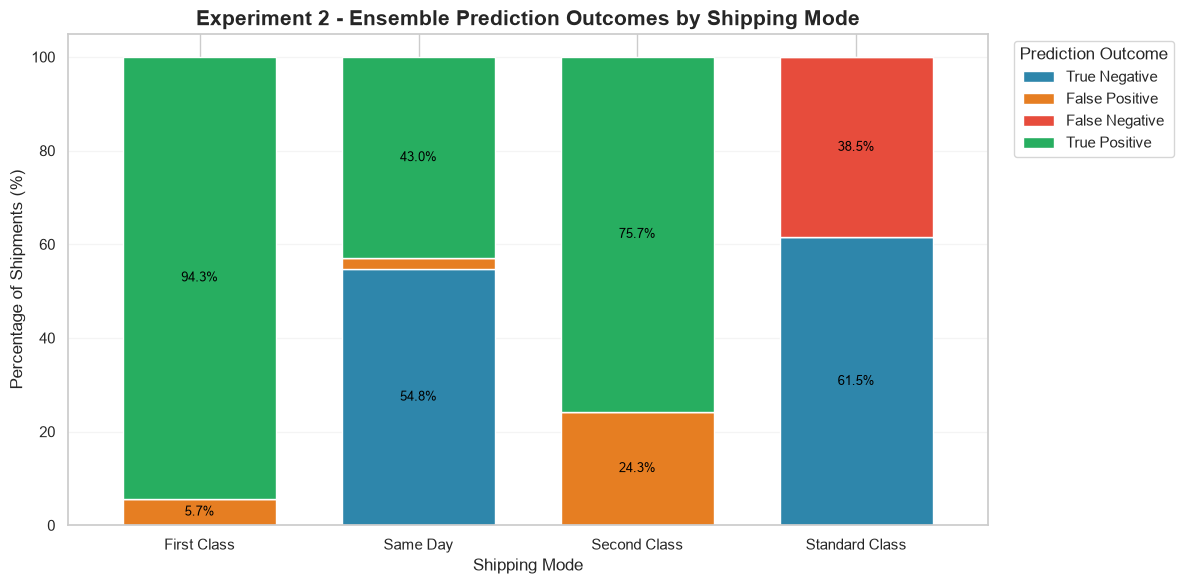

Experiment 2 - Error Percentages by Shipping Mode


Error_Type,True Negative,False Positive,False Negative,True Positive
Shipping Mode,,,,
First Class,0.00,5.71,0.00,94.29
Same Day,54.79,2.26,0.00,42.95
Second Class,0.00,24.28,0.00,75.72
Standard Class,61.48,0.00,38.48,0.04



Highest False Positive Percentage:
Second Class 24.28 %

Highest False Negative Percentage:
Standard Class 38.48 %


In [439]:

# ============================================================
# EXPERIMENT 2 - ENSEMBLE ERROR DISTRIBUTION BY SHIPPING MODE
# Stacked Bar Chart with Percentages
# F

sns.set_theme(style="whitegrid")

# 1. Calculate error percentages by Shipping Mode
shipping_error_exp2 = pd.crosstab(
    validation_error_analysis_exp2["Shipping Mode"],
    validation_error_analysis_exp2["Error_Type"],
    normalize="index"
) * 100

# 2. Define error categories and colors
error_order_exp2 = [
    "True Negative",
    "False Positive",
    "False Negative",
    "True Positive"
]

colors_exp2 = [
    "#2E86AB",  # True Negative - Blue
    "#E67E22",  # False Positive - Orange
    "#E74C3C",  # False Negative - Red
    "#27AE60"   # True Positive - Green
]

shipping_error_exp2 = shipping_error_exp2.reindex(
    columns=error_order_exp2,
    fill_value=0
)

# 3. Create stacked bar chart
ax_exp2 = shipping_error_exp2.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=colors_exp2,
    edgecolor="white",
    width=0.7
)

# 4. Add percentage labels inside bars
for container_exp2 in ax_exp2.containers:

    labels_exp2 = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() >= 3 else ""
        for bar in container_exp2
    ]

    ax_exp2.bar_label(
        container_exp2,
        labels=labels_exp2,
        label_type="center",
        fontsize=9,
        color="black"
    )

# 5. Chart formatting
plt.title(
    "Experiment 2 - Ensemble Prediction Outcomes by Shipping Mode",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Shipping Mode", fontsize=12)
plt.ylabel("Percentage of Shipments (%)", fontsize=12)

plt.xticks(rotation=0)
plt.ylim(0, 105)

plt.legend(
    title="Prediction Outcome",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# EXPERIMENT 2 - ERROR DISTRIBUTION SUMMARY
# ============================================================

print("Experiment 2 - Error Percentages by Shipping Mode")
display(shipping_error_exp2.round(2))

print("\nHighest False Positive Percentage:")
print(
    shipping_error_exp2["False Positive"].idxmax(),
    round(shipping_error_exp2["False Positive"].max(), 2),
    "%"
)

print("\nHighest False Negative Percentage:")
print(
    shipping_error_exp2["False Negative"].idxmax(),
    round(shipping_error_exp2["False Negative"].max(), 2),
    "%"
)

# ============================================================
# INTERPRETATION - EXPERIMENT 2
# ============================================================

# This analysis examines the distribution of ensemble
# prediction outcomes across different shipping modes.
#
# The five-model ensemble combines Logistic Regression,
# Decision Tree, Random Forest, LightGBM, and Linear SVM.
#
# The selected classification threshold is 0.50.
#
# True Negative:
# On-time shipments correctly predicted as on time.
#
# False Positive:
# On-time shipments incorrectly predicted as late.
#
# False Negative:
# Late shipments incorrectly predicted as on time.
#
# True Positive:
# Late shipments correctly predicted as late.
#
# The stacked bar chart displays the percentage of each
# prediction outcome within each shipping mode.
#
# Higher False Positive percentages indicate a larger
# proportion of unnecessary late-delivery alerts.
#
# Higher False Negative percentages indicate a larger
# proportion of shipments with undetected late deliveries.
#
# These percentages are calculated relative to all
# shipments within each shipping mode, not separately
# within the actual late or on-time classes.
#
# Comparing shipping modes helps identify where the
# ensemble makes more prediction errors.
#
# The results can support further investigation of
# shipping-related features and model performance.
#
# Actual shipping-mode findings should be interpreted
# after examining the newly generated Experiment 2 chart.
# ============================================================


In [440]:

# ============================================================
# EXPERIMENT 2 - ERROR PERCENTAGES BY SHIPPING MODE
# ============================================================

shipping_error_percentage_exp2 = pd.crosstab(
    validation_error_analysis_exp2["Shipping Mode"],
    validation_error_analysis_exp2["Error_Type"],
    normalize="index"
) * 100

print("Experiment 2 - Error Percentages by Shipping Mode:")
display(shipping_error_percentage_exp2.round(2))


Experiment 2 - Error Percentages by Shipping Mode:


Error_Type,False Negative,False Positive,True Negative,True Positive
Shipping Mode,,,,
First Class,0.00,5.71,0.00,94.29
Same Day,0.00,2.26,54.79,42.95
Second Class,0.00,24.28,0.00,75.72
Standard Class,38.48,0.00,61.48,0.04


In [441]:

# ============================================================
# EXPERIMENT 2 - ERROR PERCENTAGES BY MARKET
# ============================================================

market_error_percentage_exp2 = pd.crosstab(
    validation_error_analysis_exp2["Market"],
    validation_error_analysis_exp2["Error_Type"],
    normalize="index"
) * 100

print("Experiment 2 - Error Percentages by Market:")
display(market_error_percentage_exp2.round(2))


Experiment 2 - Error Percentages by Market:


Error_Type,False Negative,False Positive,True Negative,True Positive
Market,,,,
Africa,20.09,4.58,40.78,34.55
Europe,22.25,5.04,40.10,32.61
LATAM,23.07,6.72,37.96,32.24
Pacific Asia,22.82,6.02,38.39,32.76
USCA,21.65,5.87,37.78,34.70


In [442]:

# ============================================================
# INTERPRETATION: EXPERIMENT 2 - ERROR ANALYSIS BY MARKET
# ============================================================

# Market-based error analysis was conducted to investigate
# how the five-model ensemble performs across different
# geographical markets.
#
# The analysis calculates the percentage of True Negatives,
# False Positives, False Negatives, and True Positives
# within each market at the selected threshold of 0.50.
#
# True Positive (TP):
# Actual late deliveries correctly predicted as late.
#
# True Negative (TN):
# Actual on-time deliveries correctly predicted as on time.
#
# False Positive (FP):
# On-time deliveries incorrectly predicted as late.
#
# False Negative (FN):
# Late deliveries incorrectly predicted as on time.
#
# PURPOSE:
# --------
# The objective is to identify whether prediction errors
# are distributed similarly across markets or whether
# certain markets contribute more classification errors.
#
# A higher False Negative percentage indicates that a
# larger proportion of shipments in that market are
# late deliveries incorrectly predicted as on time.
#
# A higher False Positive percentage indicates that a
# larger proportion of shipments in that market generate
# unnecessary late-delivery alerts.
#
# These percentages are calculated relative to all
# shipments within each market. They are not equivalent
# to market-specific False Negative Rates or False
# Positive Rates.
#
# CONCLUSION:
# -----------
# This analysis helps identify differences in prediction
# outcomes across markets and supports further
# investigation of market-related delivery patterns.
#
# Markets with high error percentages may require
# further examination of shipping characteristics,
# class distributions, and available predictive features.
#
# The actual market-specific findings will be determined
# after examining the generated output.
#
# The analysis uses Experiment 2 validation predictions
# and does not modify the original ensemble.
# ============================================================


In [443]:

# ============================================================
# EXPERIMENT 2 - ERROR ANALYSIS BY CUSTOMER SEGMENT
# ============================================================

segment_error_percentage_exp2 = pd.crosstab(
    validation_error_analysis_exp2["Customer Segment"],
    validation_error_analysis_exp2["Error_Type"],
    normalize="index"
) * 100

print("Experiment 2 - Error Percentages by Customer Segment:")
display(segment_error_percentage_exp2.round(2))


Experiment 2 - Error Percentages by Customer Segment:


Error_Type,False Negative,False Positive,True Negative,True Positive
Customer Segment,,,,
Consumer,22.69,5.16,37.92,34.23
Corporate,21.46,6.32,40.86,31.36
Home Office,23.15,7.08,37.84,31.93


## Conclusion: Experiment 2 — Error Analysis by Shipping Mode and Market

### 1. Error Analysis by Shipping Mode

The shipping-mode error analysis of Experiment 2 (Five-Model Ensemble with Linear SVM) reveals significant differences in prediction performance across shipping categories at the selected classification threshold of **0.50**.

**First Class:** All 2,261 shipments were predicted as late. Of these, 2,132 (94.29%) were correctly classified as late, while 129 (5.71%) were False Positives.

**Same Day:** This category demonstrated strong classification performance, with 412 True Negatives (54.79%), 323 True Positives (42.95%), and only 17 False Positives (2.26%). No False Negatives were observed.

**Second Class:** All 2,652 shipments were predicted as late. Among them, 2,008 (75.72%) were correctly classified, while 644 (24.28%) were False Positives. This category recorded the highest False Positive percentage.

**Standard Class:** The most significant limitation was observed in Standard Class, where 3,033 shipments (38.48%) were False Negatives. Although 4,846 on-time shipments were correctly identified, only 3 actual late deliveries were correctly detected out of 3,036 late Standard Class shipments.

**Key Finding:** All 3,033 False Negatives in the validation dataset occurred in Standard Class. This indicates that the ensemble struggles to identify late deliveries in this shipping category.

### 2. Error Analysis by Market

Market-based error analysis was conducted to investigate whether the five-model ensemble performs consistently across geographical markets.

The results reveal relatively smaller performance differences between markets compared with the substantial differences observed across shipping modes.

| Market | False Negative (%) | False Positive (%) | Correct Predictions (%) |
|---|---:|---:|---:|
| Africa | 20.09 | 4.58 | 75.33 |
| Europe | 22.25 | 5.04 | 72.71 |
| LATAM | 23.07 | 6.72 | 70.20 |
| Pacific Asia | 22.82 | 6.02 | 71.15 |
| USCA | 21.65 | 5.87 | 72.48 |

*Correct Predictions represents the sum of True Positive and True Negative percentages within each market.*

**Africa:** Demonstrated the highest proportion of correct predictions (75.33%) and the lowest False Negative percentage (20.09%) among the five markets.

**Europe:** Achieved 72.71% correct predictions, with 22.25% False Negatives and 5.04% False Positives.

**LATAM:** Recorded the highest False Negative percentage (23.07%) and False Positive percentage (6.72%). Consequently, LATAM had the lowest overall proportion of correct predictions (70.20%).

**Pacific Asia:** Recorded 22.82% False Negatives and 6.02% False Positives, indicating a moderate level of prediction errors.

**USCA:** Achieved 72.48% correct predictions, with 21.65% False Negatives and 5.87% False Positives.

**Key Finding:** LATAM shows the highest overall prediction-error percentage, whereas Africa demonstrates the strongest overall classification performance among the markets analyzed.

However, these percentages are calculated relative to all shipments within each market. They should not be interpreted directly as class-specific false-negative or false-positive rates.

### 3. Combined Findings

The comparison of Shipping Mode and Market error analysis provides several important observations.

- **Shipping Mode appears to be strongly associated with the ensemble's prediction behavior.** The model predicts every First Class and Second Class shipment as late, while predicting almost every Standard Class shipment as on time.
- **Standard Class represents the most significant prediction weakness**, accounting for all 3,033 False Negatives.
- **Market-level differences are comparatively smaller.** False Negative percentages range from 20.09% to 23.07% across markets.
- **LATAM requires additional investigation** because it records the highest False Positive and False Negative percentages among the geographical markets.
- The model's overall validation accuracy of **71.78%** does not fully reflect the substantial differences in prediction performance between shipping categories.

### 4. Overall Conclusion

Experiment 2 demonstrates that the five-model ensemble achieves reasonable overall classification accuracy but exhibits uneven predictive performance across different shipping modes.

The most important limitation is its inability to correctly identify late deliveries within Standard Class. This suggests that the ensemble may be relying heavily on shipping-mode-related patterns instead of adequately distinguishing individual late-delivery risks.

Market-based analysis reveals relatively consistent performance across geographical regions, although LATAM demonstrates slightly higher prediction errors than the other markets.

These findings suggest that further model improvement should prioritize investigating shipping-mode dependence, examining False Negative cases, and identifying additional predictive features that could distinguish late and on-time deliveries within Standard Class.

Further analysis should also examine the relationship between Shipping Mode and Market to determine whether observed regional performance differences are influenced by variations in shipping-mode distributions.

**Final Conclusion:** The primary weakness of Experiment 2 is concentrated in Standard Class delivery predictions rather than being evenly distributed across geographical markets. Improving the detection of late deliveries in this category is an important objective for achieving more balanced and reliable model performance on unseen data.

In [444]:

# ============================================================
# FEATURE IMPORTANCE - COMMON SETUP
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.base import BaseEstimator, ClassifierMixin

# Use the selected encoded features
fi_feature_names = np.asarray(final_feature_names)

# Fitted tuned models
fi_models = {
    "Logistic Regression": best_lr,
    "Decision Tree": grid_dt.best_estimator_,
    "Random Forest": best_rf,
    "LightGBM": best_lgb,
    "Linear SVM": best_svm
}

# Check feature alignment
assert len(fi_feature_names) == X_val.shape[1], (
    "Feature name count does not match X_val."
)

for name, model in fi_models.items():
    assert model.n_features_in_ == len(fi_feature_names), (
        f"Feature count mismatch for {name}"
    )

print("All five models use:",
      len(fi_feature_names), "features")

# Common visualization function
def plot_feature_importance(data, column, title, top_n=15):
    top = data.head(top_n).iloc[::-1]

    plt.figure(figsize=(11, 7))
    plt.barh(top["Feature"], top[column])

    plt.xlabel(column)
    plt.ylabel("Feature")
    plt.title(title)
    plt.tight_layout()
    plt.show()

print("Feature importance setup completed.")


All five models use: 100 features
Feature importance setup completed.


TOP 20 LOGISTIC REGRESSION FEATURES


,Feature,Coefficient,Absolute_Coefficient
0,cat__Shipping Mode_First Class,1.9218,1.9218
1,cat__Shipping Mode_Standard Class,-1.1655,1.1655
2,cat__Shipping Mode_Same Day,-0.8110,0.8110
3,cat__Shipping Mode_Second Class,0.4777,0.4777
4,cat__Type_TRANSFER,-0.3763,0.3763
5,cat__category_shipping_mode_Cleats_First Class,0.2465,0.2465
6,cat__region_shipping_mode_Southern Europe_Firs...,0.2448,0.2448
7,cat__category_shipping_mode_Cardio Equipment_F...,0.2000,0.2000
8,cat__category_shipping_mode_Water Sports_First...,0.1785,0.1785
9,cat__category_shipping_mode_Women's Apparel_Fi...,0.1685,0.1685


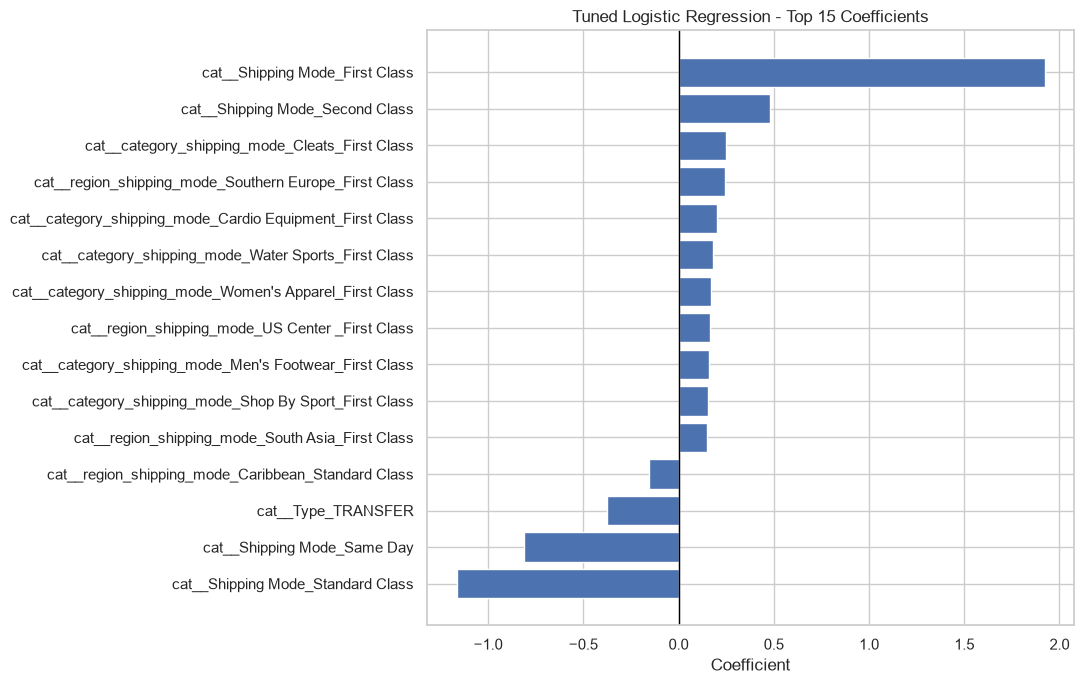

In [445]:

# ============================================================
# TUNED LOGISTIC REGRESSION - FEATURE COEFFICIENTS
# ============================================================

fi_lr_coefficients = best_lr.coef_[0]

fi_lr_importance = pd.DataFrame({
    "Feature": fi_feature_names,
    "Coefficient": fi_lr_coefficients,
    "Absolute_Coefficient": np.abs(fi_lr_coefficients)
})

fi_lr_importance = fi_lr_importance.sort_values(
    "Absolute_Coefficient", ascending=False
).reset_index(drop=True)

print("TOP 20 LOGISTIC REGRESSION FEATURES")
display(fi_lr_importance.head(20).round(4))

# Plot signed coefficients
fi_lr_top = fi_lr_importance.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(11, 7))
plt.barh(
    fi_lr_top["Feature"],
    fi_lr_top["Coefficient"]
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Coefficient")
plt.title("Tuned Logistic Regression - Top 15 Coefficients")
plt.tight_layout()
plt.show()


TOP 20 DECISION TREE FEATURES


,Feature,Importance
0,cat__Shipping Mode_Standard Class,0.5417
1,num__order_hour,0.1973
2,cat__Shipping Mode_First Class,0.1337
3,cat__Type_TRANSFER,0.0700
4,cat__Shipping Mode_Second Class,0.0533
5,num__Longitude,0.0011
6,num__Customer City_freq,0.0008
7,num__Latitude,0.0007
8,num__order_month,0.0006
9,num__Order State_freq,0.0006


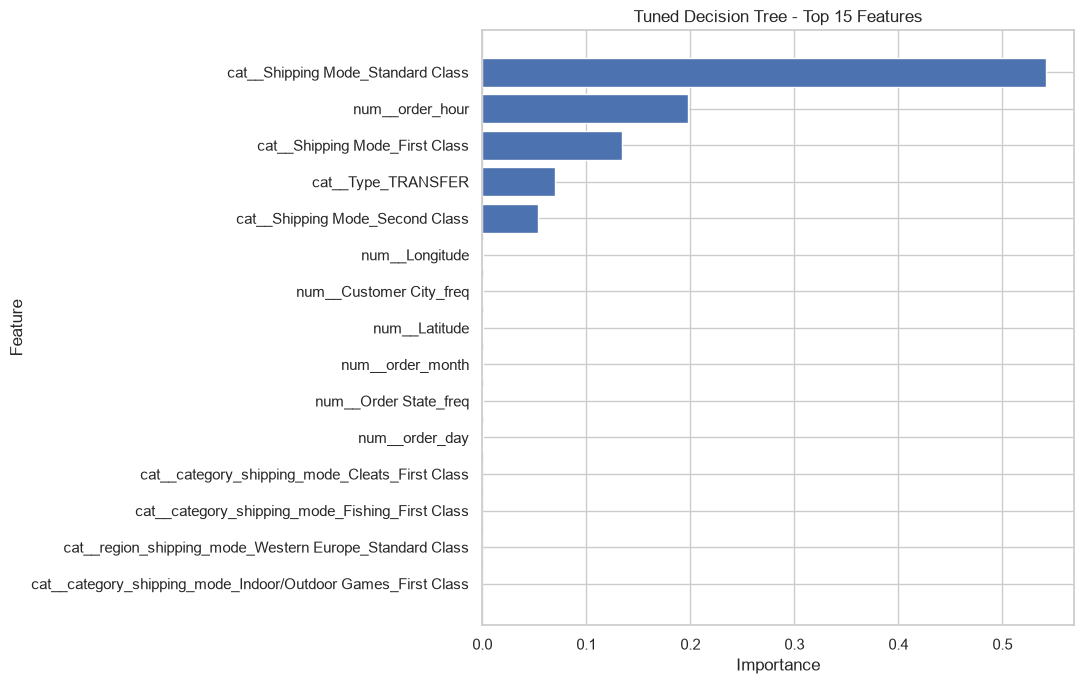

In [446]:

# ============================================================
# TUNED DECISION TREE - FEATURE IMPORTANCE
# ============================================================

fi_dt_model = grid_dt.best_estimator_

fi_dt_importance = pd.DataFrame({
    "Feature": fi_feature_names,
    "Importance": fi_dt_model.feature_importances_
})

fi_dt_importance = fi_dt_importance.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

print("TOP 20 DECISION TREE FEATURES")
display(fi_dt_importance.head(20).round(4))

plot_feature_importance(
    fi_dt_importance,
    "Importance",
    "Tuned Decision Tree - Top 15 Features"
)


TOP 20 RANDOM FOREST FEATURES


,Feature,Importance
0,cat__Shipping Mode_Standard Class,0.2750
1,cat__Shipping Mode_First Class,0.1793
2,cat__Shipping Mode_Second Class,0.0959
3,cat__Shipping Mode_Same Day,0.0489
4,num__order_hour,0.0401
5,num__hour_sin,0.0304
6,cat__region_shipping_mode_Western Europe_First...,0.0162
7,cat__region_shipping_mode_Central America_Firs...,0.0160
8,cat__category_shipping_mode_Cleats_First Class,0.0156
9,cat__Type_TRANSFER,0.0144


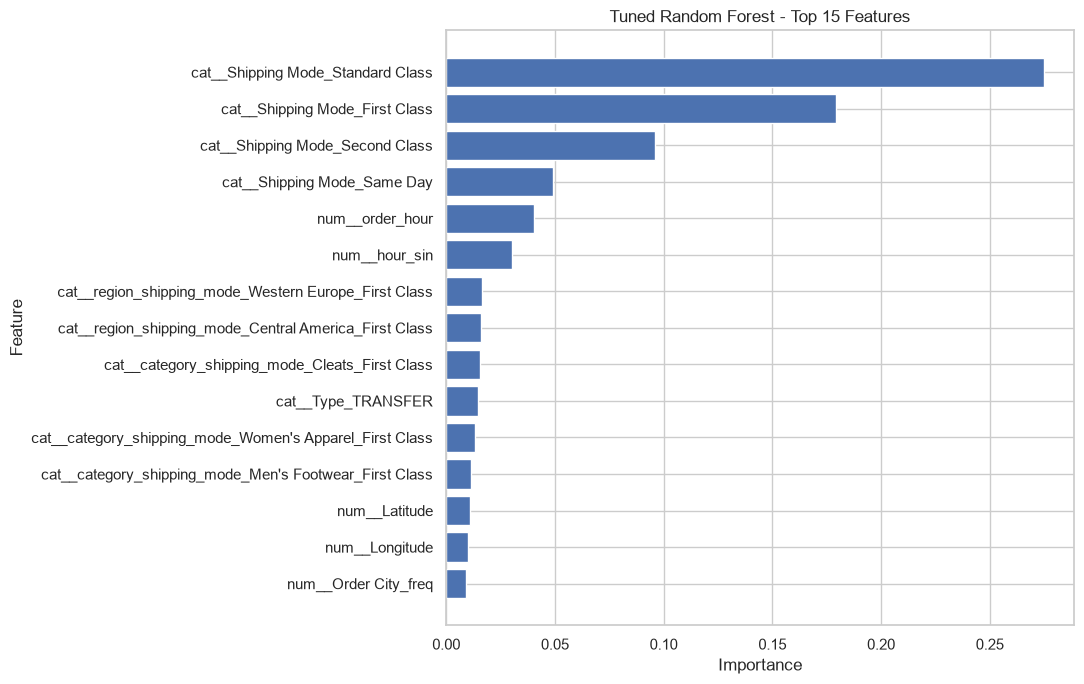

In [447]:

# ============================================================
# TUNED RANDOM FOREST - FEATURE IMPORTANCE
# ============================================================

fi_rf_importance = pd.DataFrame({
    "Feature": fi_feature_names,
    "Importance": best_rf.feature_importances_
})

fi_rf_importance = fi_rf_importance.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

print("TOP 20 RANDOM FOREST FEATURES")
display(fi_rf_importance.head(20).round(4))

plot_feature_importance(
    fi_rf_importance,
    "Importance",
    "Tuned Random Forest - Top 15 Features"
)


TOP 20 LIGHTGBM FEATURES - GAIN


,Feature,Gain,Split
0,cat__Shipping Mode_Standard Class,135876.4039,129
1,cat__Shipping Mode_First Class,62153.9686,79
2,num__order_hour,42402.0737,699
3,cat__Shipping Mode_Second Class,33826.9032,81
4,cat__Shipping Mode_Same Day,33365.9339,84
5,cat__Type_TRANSFER,20890.5551,263
6,num__Latitude,18109.5263,1727
7,num__Order City_freq,16726.9283,1542
8,num__Longitude,15085.4487,1456
9,num__Order State_freq,14842.0259,1411


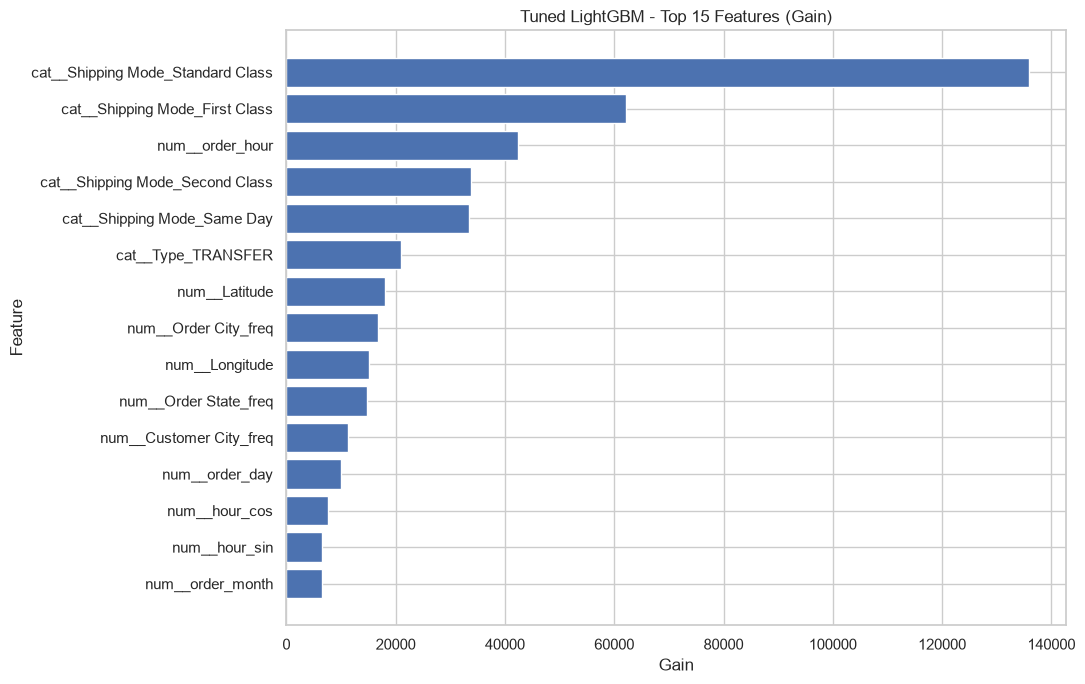

In [448]:

# ============================================================
# TUNED LIGHTGBM - FEATURE IMPORTANCE
# ============================================================

fi_lgb_gain = best_lgb.booster_.feature_importance(
    importance_type="gain"
)

fi_lgb_split = best_lgb.booster_.feature_importance(
    importance_type="split"
)

fi_lgb_importance = pd.DataFrame({
    "Feature": fi_feature_names,
    "Gain": fi_lgb_gain,
    "Split": fi_lgb_split
})

fi_lgb_importance = fi_lgb_importance.sort_values(
    "Gain", ascending=False
).reset_index(drop=True)

print("TOP 20 LIGHTGBM FEATURES - GAIN")
display(fi_lgb_importance.head(20).round(4))

plot_feature_importance(
    fi_lgb_importance,
    "Gain",
    "Tuned LightGBM - Top 15 Features (Gain)"
)


TOP 20 LINEAR SVM FEATURES


,Feature,Coefficient,Absolute_Coefficient
0,cat__Shipping Mode_First Class,0.3204,0.3204
1,cat__Shipping Mode_Second Class,0.2022,0.2022
2,cat__Shipping Mode_Standard Class,-0.1422,0.1422
3,cat__Type_TRANSFER,-0.0700,0.0700
4,num__hour_sin,-0.0299,0.0299
5,cat__Shipping Mode_Same Day,-0.0294,0.0294
6,num__order_quarter,-0.0211,0.0211
7,num__order_hour,0.0204,0.0204
8,cat__region_shipping_mode_Caribbean_Standard C...,-0.0123,0.0123
9,num__order_month,0.0116,0.0116


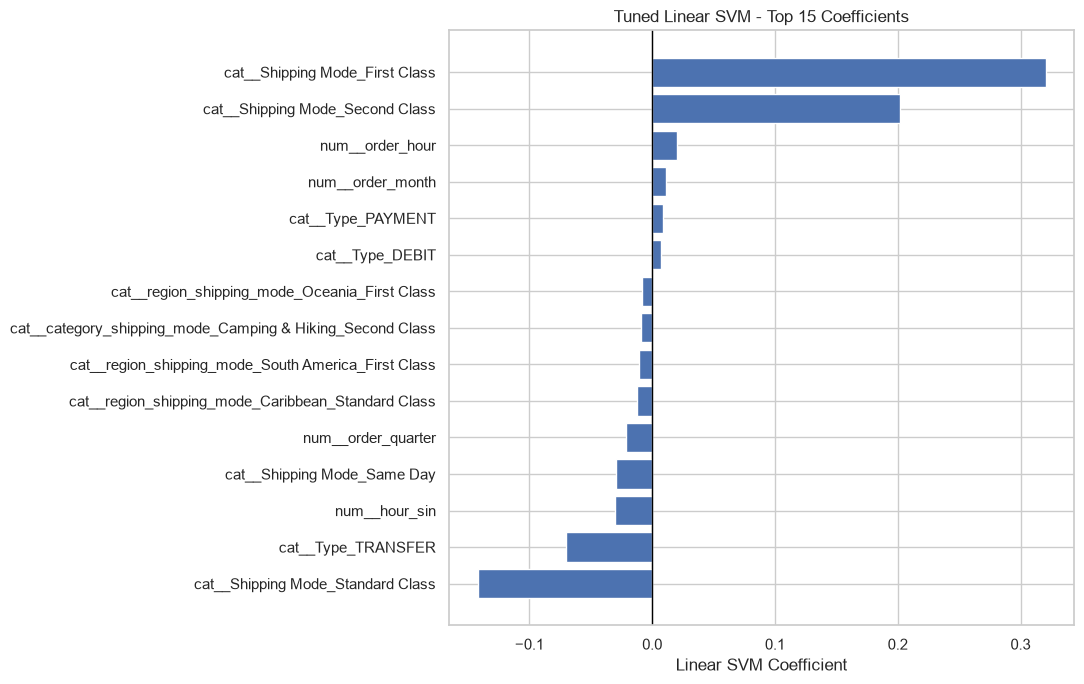

In [449]:

# ============================================================
# TUNED LINEAR SVM - FEATURE COEFFICIENTS
# ============================================================

fi_svm_model = best_svm.named_steps["svm"]

fi_svm_coefficients = fi_svm_model.coef_[0]

fi_svm_importance = pd.DataFrame({
    "Feature": fi_feature_names,
    "Coefficient": fi_svm_coefficients,
    "Absolute_Coefficient": np.abs(fi_svm_coefficients)
})

fi_svm_importance = fi_svm_importance.sort_values(
    "Absolute_Coefficient", ascending=False
).reset_index(drop=True)

print("TOP 20 LINEAR SVM FEATURES")
display(fi_svm_importance.head(20).round(4))

fi_svm_top = fi_svm_importance.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(11, 7))
plt.barh(
    fi_svm_top["Feature"],
    fi_svm_top["Coefficient"]
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Linear SVM Coefficient")
plt.title("Tuned Linear SVM - Top 15 Coefficients")
plt.tight_layout()
plt.show()


In [451]:

# ============================================================
# CELL 7 - EXPERIMENT 2
# VERIFY FIVE-MODEL ENSEMBLE PROBABILITIES
# ============================================================

import numpy as np
from scipy import sparse
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

# ============================================================
# 1. VERIFY VALIDATION FEATURE MATRICES
# ============================================================

print("EXPERIMENT 2 - FEATURE MATRIX VERIFICATION")
print("=" * 55)

print("X_val shape:", X_val.shape)
print("X_svm_val shape:", X_svm_val.shape)

assert X_val.shape == X_svm_val.shape, (
    "Validation matrices have different shapes."
)

# Verify the selected feature matrices are identical
if sparse.issparse(X_val) and sparse.issparse(X_svm_val):
    matrices_match_exp2 = np.allclose(
        X_val.toarray(),
        X_svm_val.toarray()
    )
else:
    matrices_match_exp2 = np.allclose(
        np.asarray(
            X_val.toarray() if sparse.issparse(X_val) else X_val
        ),
        np.asarray(
            X_svm_val.toarray() if sparse.issparse(X_svm_val)
            else X_svm_val
        )
    )

print("Validation feature matrices match:",
      matrices_match_exp2)

assert matrices_match_exp2, (
    "The SVM and other models use different validation "
    "feature matrices. Verify selected feature order "
    "before ensemble permutation importance."
)

# ============================================================
# 2. GENERATE PROBABILITIES FROM ALL FIVE TUNED MODELS
# ============================================================

def get_class1_probability_exp2(model, X):
    class_index = list(model.classes_).index(1)
    return model.predict_proba(X)[:, class_index]


# Tuned Logistic Regression
fi_lr_prob_exp2 = get_class1_probability_exp2(
    best_lr, X_val
)

# Tuned Decision Tree
fi_dt_prob_exp2 = get_class1_probability_exp2(
    grid_dt.best_estimator_, X_val
)

# Tuned Random Forest
fi_rf_prob_exp2 = get_class1_probability_exp2(
    best_rf, X_val
)

# Tuned LightGBM
fi_lgb_prob_exp2 = get_class1_probability_exp2(
    best_lgb, X_val
)

# Calibrated Tuned Linear SVM
fi_svm_prob_exp2 = get_class1_probability_exp2(
    calibrated_svm_exp2, X_svm_val
)

# ============================================================
# 3. VERIFY INDIVIDUAL PROBABILITIES
# ============================================================

fi_probability_matrix_exp2 = np.column_stack([
    fi_lr_prob_exp2,
    fi_dt_prob_exp2,
    fi_rf_prob_exp2,
    fi_lgb_prob_exp2,
    fi_svm_prob_exp2
])

assert fi_probability_matrix_exp2.shape == (len(y_val), 5)

assert np.isfinite(fi_probability_matrix_exp2).all()

assert (
    (fi_probability_matrix_exp2 >= 0) &
    (fi_probability_matrix_exp2 <= 1)
).all()

print("\nFIVE-MODEL VERIFICATION")
print("=" * 55)

print("Number of tuned models:",
      fi_probability_matrix_exp2.shape[1])

print("Validation observations:",
      fi_probability_matrix_exp2.shape[0])

print("All probabilities valid: True")

# ============================================================
# 4. RECONSTRUCT FIVE-MODEL SOFT VOTING
# ============================================================

# Each tuned model contributes 20%
fi_exp2_verified_probability = (
    fi_probability_matrix_exp2.mean(axis=1)
)

# Compare against the previously saved Experiment 2 ensemble
fi_exp2_difference = np.max(
    np.abs(
        fi_exp2_verified_probability -
        np.asarray(ensemble_probability_exp2).ravel()
    )
)

fi_exp2_verified = np.allclose(
    fi_exp2_verified_probability,
    ensemble_probability_exp2,
    rtol=1e-7,
    atol=1e-8
)

print("\nENSEMBLE PROBABILITY VERIFICATION")
print("=" * 55)

print("Maximum probability difference:",
      fi_exp2_difference)

print("Experiment 2 probabilities verified:",
      fi_exp2_verified)

# ============================================================
# 5. EVALUATE VERIFIED ENSEMBLE AT THRESHOLD 0.50
# ============================================================

fi_exp2_verified_prediction = (
    fi_exp2_verified_probability >= 0.50
).astype(int)

print("\nVERIFIED EXPERIMENT 2 PERFORMANCE")
print("=" * 55)

print("Accuracy:",
      round(accuracy_score(
          y_val, fi_exp2_verified_prediction
      ), 4))

print("F1-score:",
      round(f1_score(
          y_val, fi_exp2_verified_prediction
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_val, fi_exp2_verified_probability
      ), 4))

# ============================================================
# 6. FINAL VERIFICATION STATUS
# ============================================================

if fi_exp2_verified:
    print("\nSUCCESS:")
    print("The stored Experiment 2 probabilities match")
    print("the average predictions from all five models.")

else:
    print("\nWARNING:")
    print("Experiment 2 stored probabilities do not match")
    print("the freshly generated five-model predictions.")
    print("Check the individual probability variables,")
    print("especially the Random Forest predictions.")
    print("Recalculate ensemble evaluation if necessary.")

# ============================================================
# INTERPRETATION
# ============================================================

# This verification ensures that Experiment 2 combines
# Logistic Regression, Decision Tree, Random Forest,
# LightGBM, and calibrated Linear SVM.
#
# All five models contribute equally to soft voting.
#
# Probability verification is necessary before calculating
# ensemble permutation importance because importance
# analysis requires recalculating ensemble predictions
# after shuffling individual features.
#
# This cell creates separate verification variables and
# does not overwrite the original Experiment 2 results.
# ============================================================


EXPERIMENT 2 - FEATURE MATRIX VERIFICATION
X_val shape: (13547, 100)
X_svm_val shape: (13547, 100)
Validation feature matrices match: True

FIVE-MODEL VERIFICATION
Number of tuned models: 5
Validation observations: 13547
All probabilities valid: True

ENSEMBLE PROBABILITY VERIFICATION
Maximum probability difference: 3.3306690738754696e-16
Experiment 2 probabilities verified: True

VERIFIED EXPERIMENT 2 PERFORMANCE
Accuracy: 0.7178
F1-score: 0.7003
ROC-AUC: 0.7762

SUCCESS:
The stored Experiment 2 probabilities match
the average predictions from all five models.


In [452]:

# ============================================================
# CELL 8 - EXPERIMENT 2
# ENSEMBLE PREDICTOR FOR PERMUTATION IMPORTANCE
# ============================================================

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin

class Exp2SoftVotingEnsemble(ClassifierMixin, BaseEstimator):

    def __init__(self, models, threshold=0.50):
        self.models = models
        self.threshold = threshold
        self.classes_ = np.array([0, 1])

    def fit(self, X, y=None):
        # All component models are already trained
        return self

    def predict_proba(self, X):

        probabilities = []

        for model in self.models:
            class_index = list(model.classes_).index(1)

            p = model.predict_proba(X)[:, class_index]
            probabilities.append(p)

        average_probability = np.mean(
            probabilities, axis=0
        )

        return np.column_stack([
            1 - average_probability,
            average_probability
        ])

    def predict(self, X):

        probabilities = self.predict_proba(X)[:, 1]

        return (
            probabilities >= self.threshold
        ).astype(int)


# Create Experiment 2 predictor
fi_ensemble_exp2 = Exp2SoftVotingEnsemble(
    models=[
        best_lr,
        grid_dt.best_estimator_,
        best_rf,
        best_lgb,
        calibrated_svm_exp2
    ],
    threshold=0.50
)

print("Experiment 2 ensemble predictor created.")
print("Number of models:", len(fi_ensemble_exp2.models))
print("Selected threshold:", fi_ensemble_exp2.threshold)


Experiment 2 ensemble predictor created.
Number of models: 5
Selected threshold: 0.5


In [453]:

# ============================================================
# CELL 9 - EXPERIMENT 2
# ENSEMBLE PERMUTATION FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from scipy import sparse
from sklearn.metrics import roc_auc_score, f1_score

# Selected encoded feature names
fi_feature_names_exp2 = np.asarray(final_feature_names)

# Validation labels
fi_y_val_exp2 = np.asarray(y_val).ravel()

# Select a representative validation sample
fi_sample_size_exp2 = min(1000, len(fi_y_val_exp2))

if fi_sample_size_exp2 < len(fi_y_val_exp2):

    fi_indices_exp2, _ = train_test_split(
        np.arange(len(fi_y_val_exp2)),
        train_size=fi_sample_size_exp2,
        stratify=fi_y_val_exp2,
        random_state=42
    )

else:
    fi_indices_exp2 = np.arange(len(fi_y_val_exp2))

# Extract sampled validation data
fi_X_sample_exp2 = X_val[fi_indices_exp2]
fi_y_sample_exp2 = fi_y_val_exp2[fi_indices_exp2]

# Convert sparse data to dense for permutation
if sparse.issparse(fi_X_sample_exp2):
    fi_X_sample_exp2 = fi_X_sample_exp2.toarray()
else:
    fi_X_sample_exp2 = np.asarray(fi_X_sample_exp2)

# Verify feature dimensions
assert fi_X_sample_exp2.shape[1] == len(
    fi_feature_names_exp2
), "Feature names do not match validation matrix."

# Verify ensemble predictions reproduce saved probabilities
fi_sample_prob_exp2 = fi_ensemble_exp2.predict_proba(
    fi_X_sample_exp2
)[:, 1]

assert np.allclose(
    fi_sample_prob_exp2,
    np.asarray(ensemble_probability_exp2)[fi_indices_exp2],
    atol=1e-7
), "Ensemble predictions differ from saved probabilities."

# Original performance on sampled data
fi_original_auc_exp2 = roc_auc_score(
    fi_y_sample_exp2,
    fi_sample_prob_exp2
)

fi_original_f1_exp2 = f1_score(
    fi_y_sample_exp2,
    (fi_sample_prob_exp2 >= 0.50).astype(int)
)

print("Experiment 2 - Permutation Importance")
print("Sample size:", len(fi_y_sample_exp2))
print("Features:", fi_X_sample_exp2.shape[1])
print("Original Sample ROC-AUC:",
      round(fi_original_auc_exp2, 4))
print("Original Sample F1:",
      round(fi_original_f1_exp2, 4))

# Calculate permutation importance
fi_permutation_exp2 = permutation_importance(
    estimator=fi_ensemble_exp2,
    X=fi_X_sample_exp2,
    y=fi_y_sample_exp2,
    scoring={
        "ROC_AUC": "roc_auc",
        "F1": "f1"
    },
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

print("\nPermutation importance completed.")


Experiment 2 - Permutation Importance
Sample size: 1000
Features: 100
Original Sample ROC-AUC: 0.7782
Original Sample F1: 0.6879

Permutation importance completed.


EXPERIMENT 2 - TOP 20 IMPORTANT FEATURES


,Feature,ROC_AUC_Importance,ROC_AUC_Std,F1_Importance,F1_Std
0,cat__Shipping Mode_First Class,0.06647,0.00654,0.05343,0.00659
1,cat__Shipping Mode_Standard Class,0.06054,0.00560,0.02443,0.01703
2,num__order_hour,0.03097,0.00567,0.02684,0.00373
3,cat__Shipping Mode_Second Class,0.03006,0.00391,0.04912,0.00553
4,cat__Shipping Mode_Same Day,0.01811,0.00031,0.00069,0.00152
5,cat__Type_TRANSFER,0.01008,0.00211,0.00000,0.00000
6,num__Latitude,0.00753,0.00143,0.00139,0.00000
7,num__Order City_freq,0.00293,0.00156,0.00139,0.00000
8,num__order_day,0.00210,0.00114,0.00046,0.00066
9,cat__region_shipping_mode_Central America_Firs...,0.00188,0.00091,0.00000,0.00000


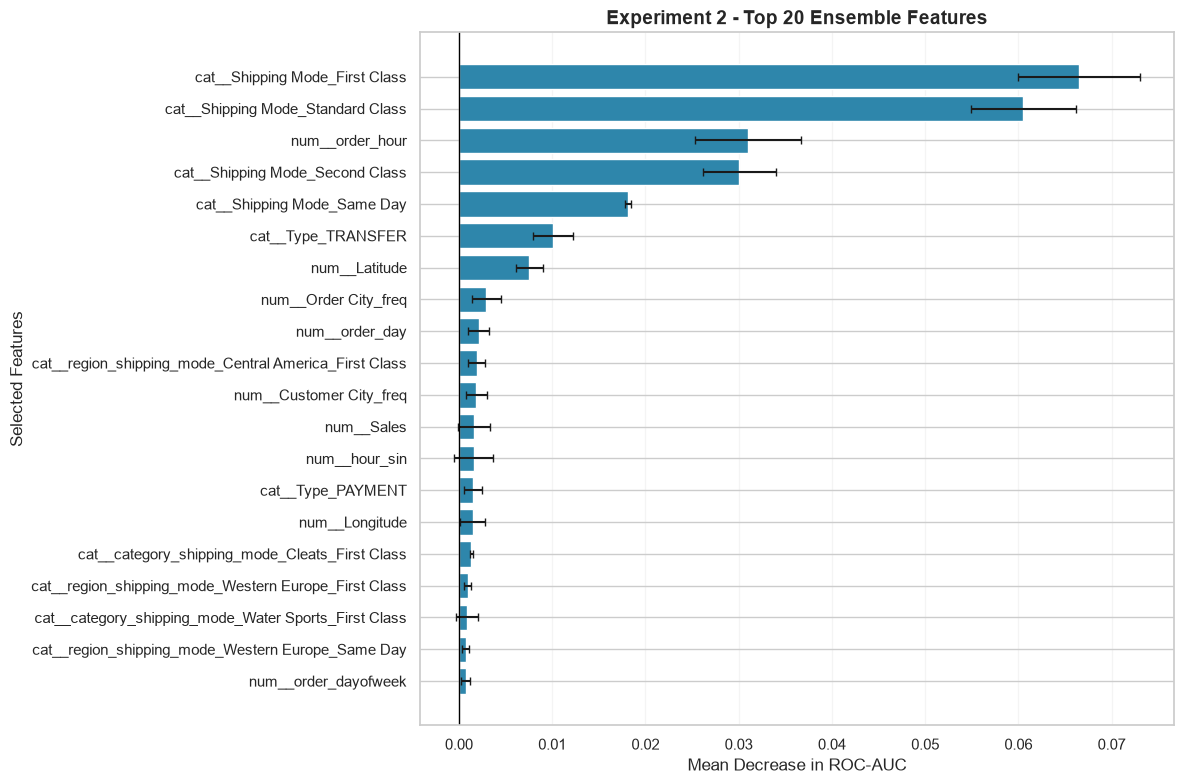

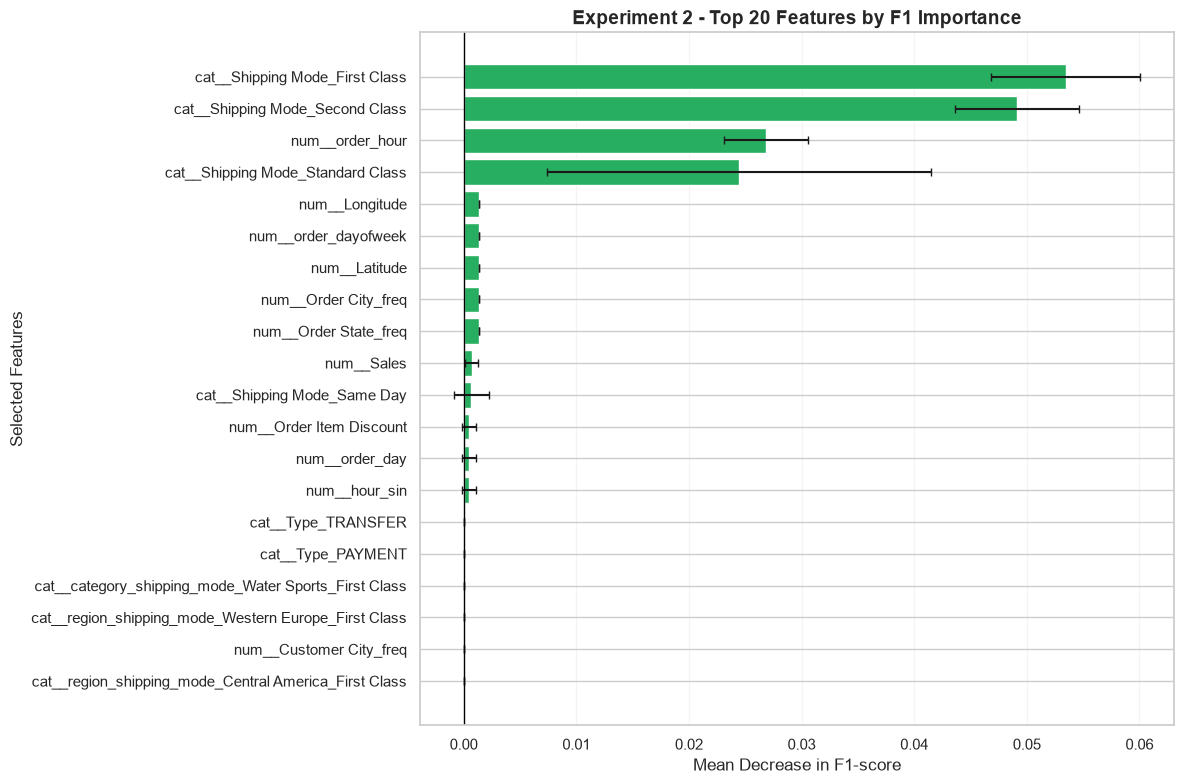

In [454]:

# ============================================================
# CELL 10 - EXPERIMENT 2
# ENSEMBLE PERMUTATION IMPORTANCE RESULTS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

fi_importance_results_exp2 = pd.DataFrame({
    "Feature": fi_feature_names_exp2,

    "ROC_AUC_Importance":
        fi_permutation_exp2["ROC_AUC"].importances_mean,

    "ROC_AUC_Std":
        fi_permutation_exp2["ROC_AUC"].importances_std,

    "F1_Importance":
        fi_permutation_exp2["F1"].importances_mean,

    "F1_Std":
        fi_permutation_exp2["F1"].importances_std
})

# Rank features using ROC-AUC importance
fi_importance_results_exp2 = (
    fi_importance_results_exp2.sort_values(
        "ROC_AUC_Importance",
        ascending=False
    ).reset_index(drop=True)
)

print("EXPERIMENT 2 - TOP 20 IMPORTANT FEATURES")

display(
    fi_importance_results_exp2.head(20).round(5)
)

# ============================================================
# VISUALIZATION - TOP 20 FEATURES
# ============================================================

top20_fi_exp2 = (
    fi_importance_results_exp2.head(20)
    .sort_values("ROC_AUC_Importance")
)

plt.figure(figsize=(12, 8))

plt.barh(
    top20_fi_exp2["Feature"],
    top20_fi_exp2["ROC_AUC_Importance"],
    xerr=top20_fi_exp2["ROC_AUC_Std"],
    color="#2E86AB",
    capsize=3
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Selected Features")

plt.title(
    "Experiment 2 - Top 20 Ensemble Features",
    fontsize=14,
    fontweight="bold"
)

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# VISUALIZATION - TOP 20 FEATURES BY F1
# ============================================================

top20_f1_exp2 = (
    fi_importance_results_exp2.sort_values(
        "F1_Importance",
        ascending=False
    ).head(20)
    .sort_values("F1_Importance")
)

plt.figure(figsize=(12, 8))

plt.barh(
    top20_f1_exp2["Feature"],
    top20_f1_exp2["F1_Importance"],
    xerr=top20_f1_exp2["F1_Std"],
    color="#27AE60",
    capsize=3
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Mean Decrease in F1-score")
plt.ylabel("Selected Features")

plt.title(
    "Experiment 2 - Top 20 Features by F1 Importance",
    fontsize=14,
    fontweight="bold"
)

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


In [455]:

# ============================================================
# EXPERIMENT 2 - FINAL VALIDATION MODEL COMPARISON
# Five Tuned Models + Five-Model Ensemble
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    log_loss
)

exp2_y_true = np.asarray(y_val).ravel()

# Selected operating threshold
exp2_operating_threshold = 0.50

# Helper: obtain the probability of late delivery (class 1)
def get_late_probability_exp2(model, X):
    class_index = list(model.classes_).index(1)
    return np.asarray(
        model.predict_proba(X)[:, class_index]
    ).ravel()

# Fresh probabilities from all fitted tuned models
exp2_model_probabilities = {
    "Logistic Regression - Tuned":
        get_late_probability_exp2(best_lr, X_val),

    "Decision Tree - Tuned":
        get_late_probability_exp2(
            grid_dt.best_estimator_, X_val
        ),

    "Random Forest - Tuned":
        get_late_probability_exp2(best_rf, X_val),

    "LightGBM - Tuned":
        get_late_probability_exp2(best_lgb, X_val),

    "Linear SVM - Tuned (Calibrated)":
        get_late_probability_exp2(
            calibrated_svm_exp2, X_svm_val
        )
}

# Reconstruct verified five-model probability
exp2_probability_matrix = np.column_stack(
    list(exp2_model_probabilities.values())
)

exp2_ensemble_prob_verified = (
    exp2_probability_matrix.mean(axis=1)
)

np.testing.assert_allclose(
    exp2_ensemble_prob_verified,
    np.asarray(ensemble_probability_exp2).ravel(),
    rtol=1e-7,
    atol=1e-8
)

exp2_model_probabilities[
    "Ensemble - Experiment 2 (5 Models)"
] = exp2_ensemble_prob_verified

# Common evaluation function
def evaluate_validation_exp2(name, probabilities, threshold):

    probabilities = np.asarray(probabilities).ravel()
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(exp2_y_true, predictions),
        "Precision": precision_score(
            exp2_y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            exp2_y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            exp2_y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            exp2_y_true, probabilities
        ),
        "Average Precision": average_precision_score(
            exp2_y_true, probabilities
        )
    }

# Evaluate all six configurations at threshold 0.50
final_validation_comparison_exp2 = pd.DataFrame([
    evaluate_validation_exp2(
        name, probabilities, exp2_operating_threshold
    )
    for name, probabilities in exp2_model_probabilities.items()
])

print("EXPERIMENT 2 - FINAL VALIDATION COMPARISON")
display(final_validation_comparison_exp2.round(4))


EXPERIMENT 2 - FINAL VALIDATION COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression - Tuned,0.5,0.7098,0.8440,0.5837,0.6901,0.7481,0.8197
1,Decision Tree - Tuned,0.5,0.7173,0.8495,0.5946,0.6996,0.7752,0.8032
2,Random Forest - Tuned,0.5,0.7176,0.8496,0.5951,0.7000,0.7763,0.8383
3,LightGBM - Tuned,0.5,0.7134,0.8123,0.6272,0.7078,0.7748,0.8383
4,Linear SVM - Tuned (Calibrated),0.5,0.7078,0.8396,0.5835,0.6885,0.7470,0.8194
5,Ensemble - Experiment 2 (5 Models),0.5,0.7178,0.8497,0.5955,0.7003,0.7762,0.8351


In [456]:

# ============================================================
# EXPERIMENT 2 - THRESHOLD COMPARISON
# Five Tuned Models + Five-Model Ensemble
# ============================================================

exp2_thresholds = np.round(
    np.arange(0.20, 0.801, 0.05), 2
)

exp2_threshold_records = []

for model_name, probabilities in exp2_model_probabilities.items():

    for threshold in exp2_thresholds:

        exp2_threshold_records.append(
            evaluate_validation_exp2(
                model_name,
                probabilities,
                float(threshold)
            )
        )

threshold_comparison_exp2 = pd.DataFrame(
    exp2_threshold_records
)

print("EXPERIMENT 2 - MODEL COMPARISON ACROSS THRESHOLDS")
display(threshold_comparison_exp2.round(4))

# Best F1 threshold for each model
best_thresholds_by_model_exp2 = (
    threshold_comparison_exp2
    .sort_values(
        ["Model", "F1", "Recall"],
        ascending=[True, False, False]
    )
    .drop_duplicates(subset="Model")
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

print("\nBEST TESTED THRESHOLD FOR EACH MODEL BY F1")
display(best_thresholds_by_model_exp2.round(4))

# Highlight the F1-optimal threshold of Experiment 2
exp2_ensemble_name = "Ensemble - Experiment 2 (5 Models)"

exp2_f1_optimal_row = (
    best_thresholds_by_model_exp2.loc[
        best_thresholds_by_model_exp2["Model"]
        == exp2_ensemble_name
    ].iloc[0]
)

print("\nExperiment 2 - F1-optimal threshold:")
print(exp2_f1_optimal_row)



EXPERIMENT 2 - MODEL COMPARISON ACROSS THRESHOLDS


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression - Tuned,0.20,0.5536,0.5536,1.0000,0.7126,0.7481,0.8197
1,Logistic Regression - Tuned,0.25,0.5536,0.5536,0.9997,0.7126,0.7481,0.8197
2,Logistic Regression - Tuned,0.30,0.5785,0.5705,0.9647,0.7170,0.7481,0.8197
3,Logistic Regression - Tuned,0.35,0.6062,0.5947,0.9061,0.7181,0.7481,0.8197
4,Logistic Regression - Tuned,0.40,0.6602,0.6708,0.7584,0.7119,0.7481,0.8197
5,Logistic Regression - Tuned,0.45,0.6864,0.7711,0.6163,0.6851,0.7481,0.8197
6,Logistic Regression - Tuned,0.50,0.7098,0.8440,0.5837,0.6901,0.7481,0.8197
7,Logistic Regression - Tuned,0.55,0.6981,0.8440,0.5577,0.6716,0.7481,0.8197
8,Logistic Regression - Tuned,0.60,0.6950,0.8427,0.5521,0.6671,0.7481,0.8197
9,Logistic Regression - Tuned,0.65,0.6951,0.8431,0.5518,0.6670,0.7481,0.8197



BEST TESTED THRESHOLD FOR EACH MODEL BY F1


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Ensemble - Experiment 2 (5 Models),0.35,0.6332,0.6126,0.9175,0.7347,0.7762,0.8351
1,Decision Tree - Tuned,0.35,0.6265,0.6075,0.9193,0.7315,0.7752,0.8032
2,LightGBM - Tuned,0.30,0.6106,0.5930,0.9459,0.7289,0.7748,0.8383
3,Random Forest - Tuned,0.35,0.6012,0.5844,0.9677,0.7288,0.7763,0.8383
4,Linear SVM - Tuned (Calibrated),0.35,0.6102,0.5985,0.8991,0.7186,0.7470,0.8194
5,Logistic Regression - Tuned,0.35,0.6062,0.5947,0.9061,0.7181,0.7481,0.8197



Experiment 2 - F1-optimal threshold:
Model                Ensemble - Experiment 2 (5 Models)
Threshold                                          0.35
Accuracy                                       0.633203
Precision                                      0.612645
Recall                                         0.917456
F1                                              0.73469
ROC-AUC                                        0.776206
Average Precision                              0.835055
Name: 0, dtype: object


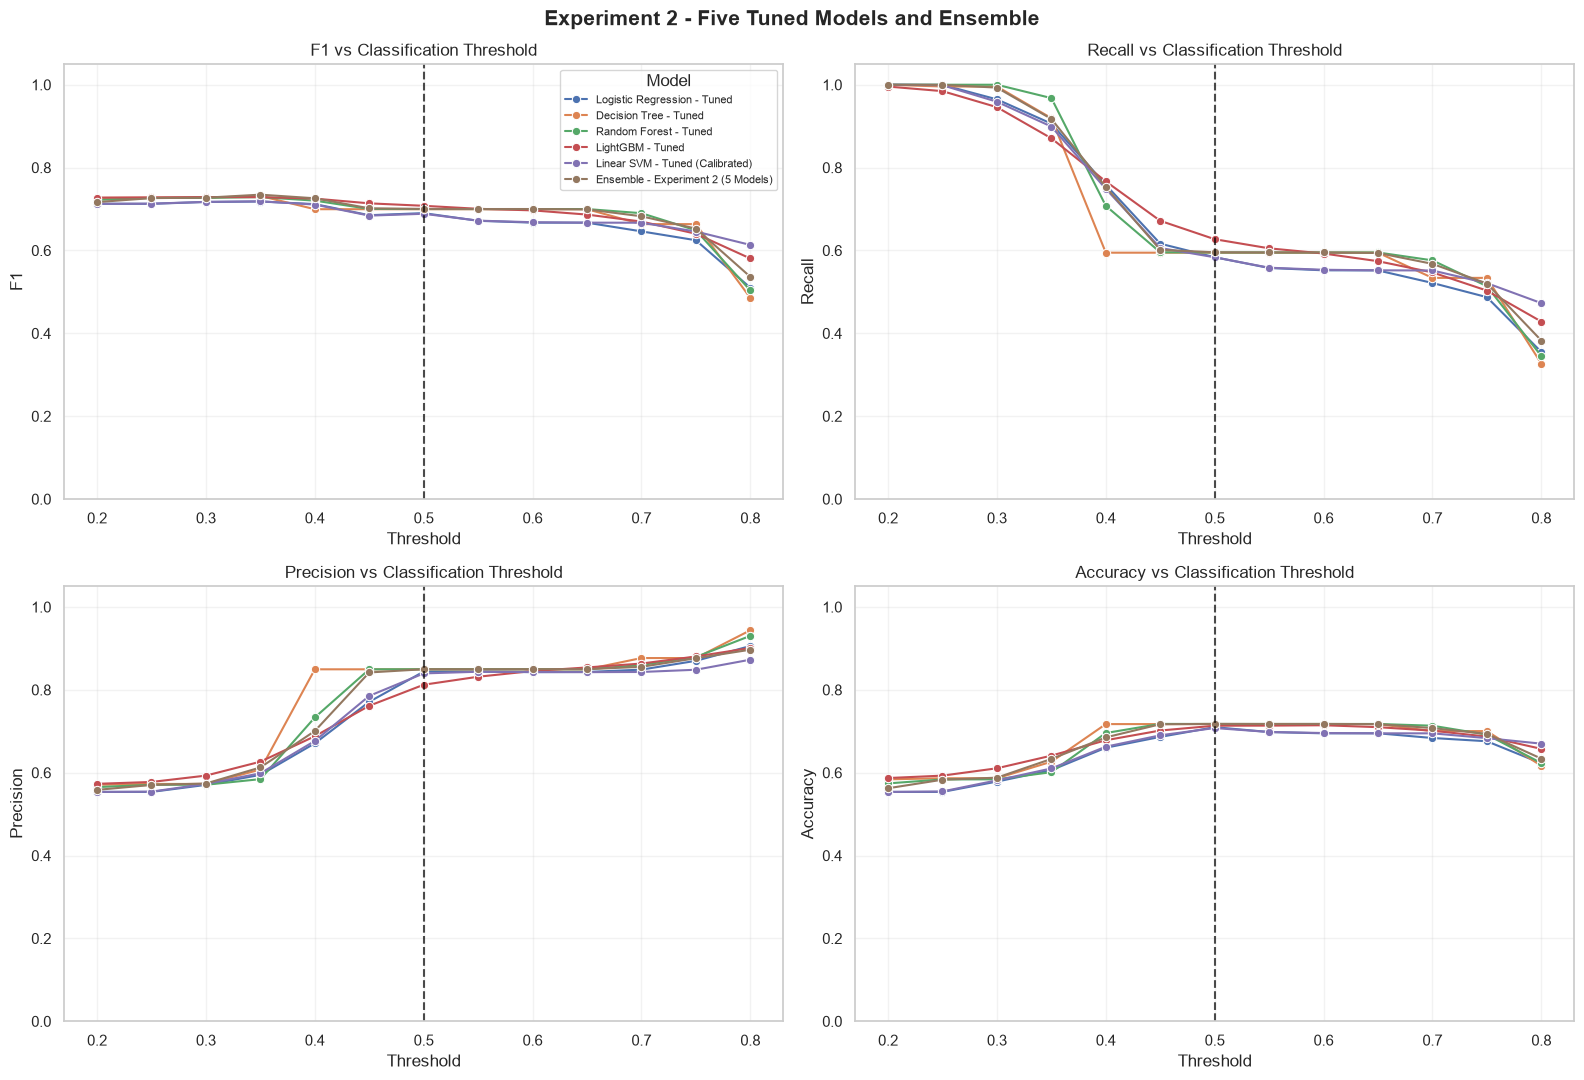

In [457]:

# ============================================================
# EXPERIMENT 2 - THRESHOLD OPTIMIZATION VISUALIZATIONS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

metrics_to_plot_exp2 = [
    "F1",
    "Recall",
    "Precision",
    "Accuracy"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, metric in zip(axes.flat, metrics_to_plot_exp2):

    sns.lineplot(
        data=threshold_comparison_exp2,
        x="Threshold",
        y=metric,
        hue="Model",
        marker="o",
        ax=ax
    )

    ax.axvline(
        exp2_operating_threshold,
        color="black",
        linestyle="--",
        alpha=0.7
    )

    ax.set_title(f"{metric} vs Classification Threshold")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)

    if ax is not axes.flat[0]:
        ax.get_legend().remove()

axes.flat[0].legend(
    title="Model",
    fontsize=8,
    loc="best"
)

plt.suptitle(
    "Experiment 2 - Five Tuned Models and Ensemble",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [458]:

# ============================================================
# EXPERIMENT 2 - FINAL VALIDATION CONFIGURATION
# Five-Model Ensemble + Linear SVM
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# ============================================================
# 1. SELECT FINAL MODEL AND THRESHOLD
# ============================================================

final_model_name_exp2 = "Ensemble - Experiment 2 (5 Models + SVM)"

# Selected operating threshold
final_threshold_exp2 = 0.50

# ============================================================
# 2. PREPARE VALIDATION DATA
# ============================================================

actual_exp2 = np.asarray(y_val).ravel()

final_val_probability_exp2 = np.asarray(
    ensemble_probability_exp2
).ravel()

# Validate data
assert len(actual_exp2) == len(final_val_probability_exp2), (
    "Validation labels and probabilities do not match."
)

assert np.isfinite(final_val_probability_exp2).all(), (
    "Invalid predicted probabilities detected."
)

assert np.all(
    (final_val_probability_exp2 >= 0) &
    (final_val_probability_exp2 <= 1)
), "Probabilities must be between 0 and 1."

# ============================================================
# 3. GENERATE FINAL VALIDATION PREDICTIONS
# ============================================================

final_val_prediction_exp2 = (
    final_val_probability_exp2 >= final_threshold_exp2
).astype(int)

# ============================================================
# 4. CALCULATE VALIDATION METRICS
# ============================================================

final_metrics_exp2 = {
    "Model": final_model_name_exp2,
    "Threshold": final_threshold_exp2,

    "Accuracy": accuracy_score(
        actual_exp2, final_val_prediction_exp2
    ),

    "Precision": precision_score(
        actual_exp2, final_val_prediction_exp2,
        zero_division=0
    ),

    "Recall": recall_score(
        actual_exp2, final_val_prediction_exp2,
        zero_division=0
    ),

    "F1": f1_score(
        actual_exp2, final_val_prediction_exp2,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        actual_exp2, final_val_probability_exp2
    ),

    "Average Precision": average_precision_score(
        actual_exp2, final_val_probability_exp2
    )
}

# ============================================================
# 5. DISPLAY FINAL VALIDATION RESULTS
# ============================================================

print("=" * 55)
print("EXPERIMENT 2 - FINAL VALIDATION CONFIGURATION")
print("=" * 55)

print("Model:", final_model_name_exp2)
print("Selected Threshold:", final_threshold_exp2)
print("Validation Observations:", len(actual_exp2))

print("\nFINAL VALIDATION PERFORMANCE")
print("-" * 55)

final_validation_results_exp2 = pd.DataFrame(
    [final_metrics_exp2]
)

display(final_validation_results_exp2.round(4))

# ============================================================
# 6. CONFUSION MATRIX
# ============================================================

final_confusion_matrix_exp2 = confusion_matrix(
    actual_exp2,
    final_val_prediction_exp2,
    labels=[0, 1]
)

print("\nFINAL CONFUSION MATRIX")
print(final_confusion_matrix_exp2)

# ============================================================
# INTERPRETATION
# ============================================================

# Experiment 2 combines five tuned classification models:
# Logistic Regression, Decision Tree, Random Forest,
# LightGBM, and calibrated Linear SVM.
#
# The operating threshold of 0.50 was selected to
# prioritize higher accuracy and precision compared
# with the F1-optimal threshold of 0.35.
#
# Validation metrics are calculated without changing
# the original ensemble probabilities.
#
# ROC-AUC and Average Precision evaluate ranking
# performance independently of the selected threshold.
#
# This evaluation uses validation data only.
# The independent test dataset remains untouched.
# ============================================================


EXPERIMENT 2 - FINAL VALIDATION CONFIGURATION
Model: Ensemble - Experiment 2 (5 Models + SVM)
Selected Threshold: 0.5
Validation Observations: 13547

FINAL VALIDATION PERFORMANCE
-------------------------------------------------------


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Ensemble - Experiment 2 (5 Models + SVM),0.5,0.7178,0.8497,0.5955,0.7003,0.7762,0.8351



FINAL CONFUSION MATRIX
[[5258  790]
 [3033 4466]]


EXPERIMENT 2 - ENSEMBLE PROBABILITY CALIBRATION
Brier Score: 0.1843
Log Loss: 0.5388
ROC-AUC: 0.7762

Actual Late-Delivery Rate: 0.5536
Mean Predicted Probability: 0.5554


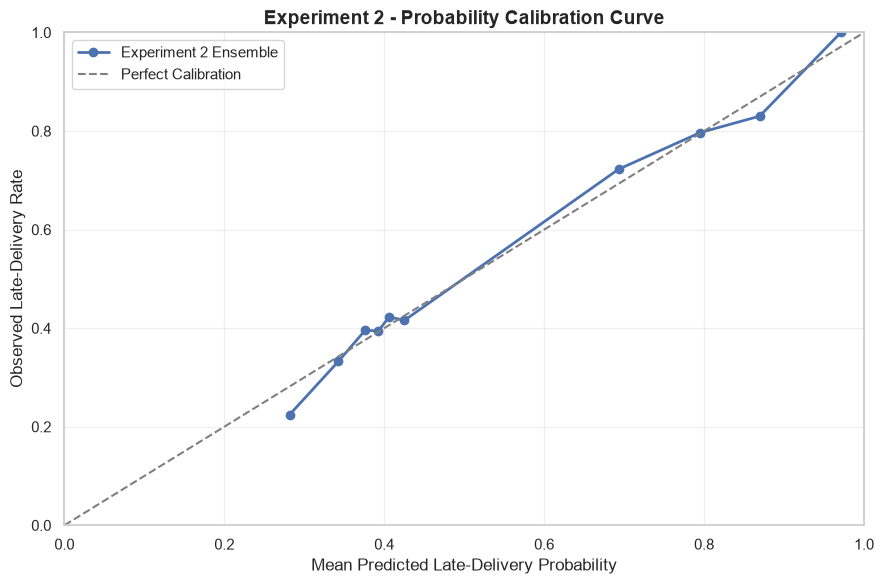

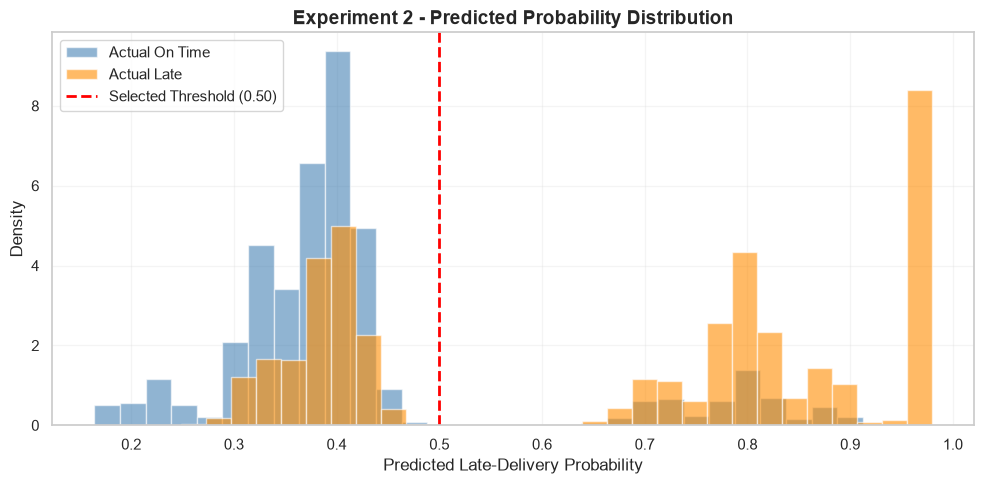

In [459]:

# ============================================================
# CELL 5 - EXPERIMENT 2
# ENSEMBLE PROBABILITY CALIBRATION ANALYSIS
# Five-Model Ensemble + Linear SVM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score
)

# ============================================================
# 1. PREPARE VALIDATION DATA
# ============================================================

y_true_cal_exp2 = np.asarray(actual_exp2).ravel()

y_prob_cal_exp2 = np.asarray(
    final_val_probability_exp2
).ravel()

# Verify inputs
assert len(y_true_cal_exp2) == len(y_prob_cal_exp2)

assert np.isfinite(y_prob_cal_exp2).all()

assert np.all(
    (y_prob_cal_exp2 >= 0) &
    (y_prob_cal_exp2 <= 1)
)

assert set(np.unique(y_true_cal_exp2)) == {0, 1}

# ============================================================
# 2. CALCULATE CALIBRATION METRICS
# ============================================================

brier_exp2 = brier_score_loss(
    y_true_cal_exp2,
    y_prob_cal_exp2
)

logloss_exp2 = log_loss(
    y_true_cal_exp2,
    y_prob_cal_exp2,
    labels=[0, 1]
)

auc_exp2 = roc_auc_score(
    y_true_cal_exp2,
    y_prob_cal_exp2
)

print("=" * 55)
print("EXPERIMENT 2 - ENSEMBLE PROBABILITY CALIBRATION")
print("=" * 55)

print(f"Brier Score: {brier_exp2:.4f}")
print(f"Log Loss: {logloss_exp2:.4f}")
print(f"ROC-AUC: {auc_exp2:.4f}")

print(
    f"\nActual Late-Delivery Rate: "
    f"{y_true_cal_exp2.mean():.4f}"
)

print(
    f"Mean Predicted Probability: "
    f"{y_prob_cal_exp2.mean():.4f}"
)

# ============================================================
# 3. CALIBRATION CURVE
# ============================================================

prob_true_exp2, prob_pred_exp2 = calibration_curve(
    y_true_cal_exp2,
    y_prob_cal_exp2,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(9, 6))

plt.plot(
    prob_pred_exp2,
    prob_true_exp2,
    marker="o",
    linewidth=2,
    label="Experiment 2 Ensemble"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Perfect Calibration"
)

plt.title(
    "Experiment 2 - Probability Calibration Curve",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Mean Predicted Late-Delivery Probability")
plt.ylabel("Observed Late-Delivery Rate")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 4. PROBABILITY DISTRIBUTION BY ACTUAL CLASS
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    y_prob_cal_exp2[y_true_cal_exp2 == 0],
    bins=30,
    alpha=0.6,
    label="Actual On Time",
    color="steelblue",
    density=True
)

plt.hist(
    y_prob_cal_exp2[y_true_cal_exp2 == 1],
    bins=30,
    alpha=0.6,
    label="Actual Late",
    color="darkorange",
    density=True
)

plt.axvline(
    final_threshold_exp2,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Selected Threshold ({final_threshold_exp2:.2f})"
)

plt.title(
    "Experiment 2 - Predicted Probability Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Late-Delivery Probability")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ============================================================
# INTERPRETATION
# ============================================================

# Brier Score measures the mean squared difference between
# predicted probabilities and actual binary outcomes.
#
# Log Loss penalizes incorrect confident predictions.
#
# Lower Brier Score and Log Loss indicate better
# probabilistic predictions.
#
# ROC-AUC measures ranking performance rather than
# probability calibration.
#
# The calibration curve compares predicted probabilities
# with the observed frequency of late deliveries.
#
# A curve close to the diagonal suggests better calibration.
#
# The probability distribution helps identify overlapping
# risk scores between late and on-time deliveries.
#
# These results describe validation performance only.
# ============================================================


In [460]:

# ============================================================
# CELL 6 - EXPERIMENT 2
# CALIBRATION BASELINE COMPARISON
# ============================================================

from sklearn.metrics import brier_score_loss, log_loss

# Training dataset late-delivery proportion
baseline_rate_exp2 = np.asarray(y_train).ravel().mean()

# Constant baseline probabilities
baseline_prob_exp2 = np.full(
    len(y_true_cal_exp2),
    baseline_rate_exp2
)

# Compare ensemble with constant baseline
calibration_baseline_exp2 = pd.DataFrame({
    "Model": [
        "Constant Baseline",
        "Experiment 2 - Five-Model Ensemble"
    ],

    "Brier Score": [
        brier_score_loss(
            y_true_cal_exp2,
            baseline_prob_exp2
        ),
        brier_score_loss(
            y_true_cal_exp2,
            y_prob_cal_exp2
        )
    ],

    "Log Loss": [
        log_loss(
            y_true_cal_exp2,
            baseline_prob_exp2,
            labels=[0, 1]
        ),
        log_loss(
            y_true_cal_exp2,
            y_prob_cal_exp2,
            labels=[0, 1]
        )
    ]
})

print("EXPERIMENT 2 - CALIBRATION BASELINE COMPARISON")
display(calibration_baseline_exp2.round(4))

# Calculate improvements
brier_improvement_exp2 = (
    calibration_baseline_exp2.iloc[0]["Brier Score"]
    - calibration_baseline_exp2.iloc[1]["Brier Score"]
)

logloss_improvement_exp2 = (
    calibration_baseline_exp2.iloc[0]["Log Loss"]
    - calibration_baseline_exp2.iloc[1]["Log Loss"]
)

print("\nBrier Score Improvement:",
      round(brier_improvement_exp2, 4))

print("Log Loss Improvement:",
      round(logloss_improvement_exp2, 4))

# ============================================================
# INTERPRETATION
# ============================================================

# The constant baseline assigns the same predicted risk
# to all observations, based on the training late-delivery rate.
#
# The comparison examines whether the five-model ensemble
# produces better probabilistic predictions than this
# simple reference model.
#
# Positive improvements indicate lower errors for the
# ensemble compared with the constant baseline.
#
# Negative improvements indicate that the ensemble
# performs worse than the constant baseline on that metric.
#
# Better scores than the baseline do not automatically
# demonstrate perfect calibration or generalization.
# ============================================================


EXPERIMENT 2 - CALIBRATION BASELINE COMPARISON


,Model,Brier Score,Log Loss
0,Constant Baseline,0.2472,0.6875
1,Experiment 2 - Five-Model Ensemble,0.1843,0.5388



Brier Score Improvement: 0.0628
Log Loss Improvement: 0.1486


EXPERIMENT 2 - CALIBRATION BY PROBABILITY RANGE


,Probability_Bin,Shipments,Mean_Predicted_Risk,Actual_Late_Rate,Calibration_Gap
0,"(-0.001, 0.1]",0,NaN,NaN,NaN
1,"(0.1, 0.2]",120,0.1845,0.0000,-0.1845
2,"(0.2, 0.3]",450,0.2505,0.1156,-0.1350
3,"(0.3, 0.4]",4915,0.3620,0.3660,0.0041
4,"(0.4, 0.5]",2806,0.4183,0.4212,0.0029
5,"(0.5, 0.6]",4,0.5318,0.7500,0.2182
6,"(0.6, 0.7]",276,0.6828,0.7464,0.0635
7,"(0.7, 0.8]",1777,0.7636,0.7811,0.0175
8,"(0.8, 0.9]",1601,0.8378,0.7989,-0.0389
9,"(0.9, 1.0]",1598,0.9681,0.9950,0.0269



Weighted Absolute Calibration Gap: 0.0196


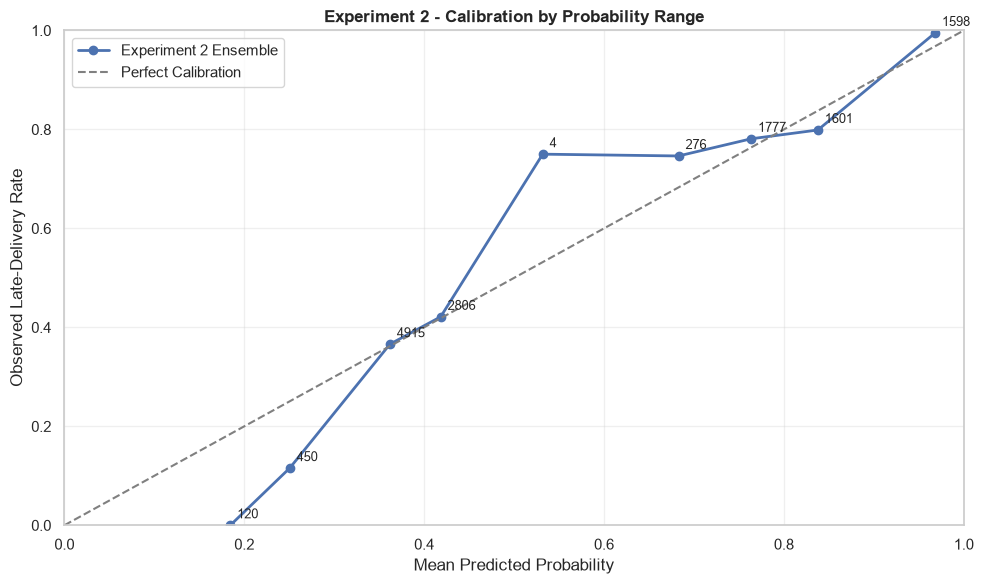


EXPERIMENT 2 - CALIBRATION INTERPRETATION
Positive calibration gap: actual late-delivery rate is higher than predicted risk.
Negative calibration gap: predicted risk is higher than the actual late-delivery rate.

Empty probability ranges:
['(-0.001, 0.1]']

The weighted gap summarizes average absolute calibration differences across populated bins.


In [461]:

# ============================================================
# CELL 7 - EXPERIMENT 2
# ENSEMBLE CALIBRATION BY PROBABILITY RANGE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CREATE PROBABILITY BINS
# ============================================================

calibration_df_exp2 = pd.DataFrame({
    "Actual": y_true_cal_exp2,
    "Predicted_Probability": y_prob_cal_exp2
})

calibration_df_exp2["Probability_Bin"] = pd.cut(
    calibration_df_exp2["Predicted_Probability"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

# ============================================================
# 2. CALCULATE CALIBRATION SUMMARY
# ============================================================

calibration_summary_exp2 = (
    calibration_df_exp2
    .groupby("Probability_Bin", observed=False)
    .agg(
        Shipments=("Actual", "size"),
        Mean_Predicted_Risk=("Predicted_Probability", "mean"),
        Actual_Late_Rate=("Actual", "mean")
    )
    .reset_index()
)

# Calculate calibration gap
calibration_summary_exp2["Calibration_Gap"] = (
    calibration_summary_exp2["Actual_Late_Rate"]
    - calibration_summary_exp2["Mean_Predicted_Risk"]
)

print("EXPERIMENT 2 - CALIBRATION BY PROBABILITY RANGE")

display(calibration_summary_exp2.round(4))

# ============================================================
# 3. WEIGHTED ABSOLUTE CALIBRATION GAP
# ============================================================

non_empty_bins_exp2 = calibration_summary_exp2[
    calibration_summary_exp2["Shipments"] > 0
].copy()

weighted_gap_exp2 = (
    non_empty_bins_exp2["Shipments"] *
    non_empty_bins_exp2["Calibration_Gap"].abs()
).sum() / non_empty_bins_exp2["Shipments"].sum()

print("\nWeighted Absolute Calibration Gap:",
      round(weighted_gap_exp2, 4))

# ============================================================
# 4. CALIBRATION GAP VISUALIZATION
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    non_empty_bins_exp2["Mean_Predicted_Risk"],
    non_empty_bins_exp2["Actual_Late_Rate"],
    marker="o",
    linewidth=2,
    label="Experiment 2 Ensemble"
)

ax.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Perfect Calibration"
)

# Add number of shipments near each point
for _, row in non_empty_bins_exp2.iterrows():

    ax.annotate(
        str(int(row["Shipments"])),
        (
            row["Mean_Predicted_Risk"],
            row["Actual_Late_Rate"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title(
    "Experiment 2 - Calibration by Probability Range",
    fontweight="bold"
)

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Late-Delivery Rate")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# ============================================================
# 5. AUTOMATIC CALIBRATION INTERPRETATION
# ============================================================

print("\nEXPERIMENT 2 - CALIBRATION INTERPRETATION")
print("=" * 55)

print(
    "Positive calibration gap: actual late-delivery rate "
    "is higher than predicted risk."
)

print(
    "Negative calibration gap: predicted risk is higher "
    "than the actual late-delivery rate."
)

print("\nEmpty probability ranges:")

print(
    calibration_summary_exp2.loc[
        calibration_summary_exp2["Shipments"] == 0,
        "Probability_Bin"
    ].astype(str).tolist()
)

print(
    "\nThe weighted gap summarizes average absolute "
    "calibration differences across populated bins."
)

# ============================================================
# INTERPRETATION
# ============================================================

# This analysis examines the reliability of predicted
# late-delivery probabilities across different risk ranges.
#
# A smaller absolute calibration gap indicates closer
# agreement between predicted risk and observed outcomes.
#
# Large gaps may indicate probability overestimation
# or underestimation within particular risk ranges.
#
# Shipment counts must also be considered because
# smaller bins may produce unstable estimates.
#
# These results are descriptive validation statistics.
# ============================================================


In [462]:

# ============================================================
# CELL 8 - EXPERIMENT 2
# FINAL FIVE-MODEL ENSEMBLE PREDICTION FUNCTION
# ============================================================

import numpy as np

# ============================================================
# 1. DEFINE FINAL MODEL CONFIGURATION
# ============================================================

FINAL_THRESHOLD_EXP2 = 0.50

FINAL_MODELS_EXP2 = {
    "Logistic Regression": best_lr,
    "Decision Tree": grid_dt.best_estimator_,
    "Random Forest": best_rf,
    "LightGBM": best_lgb,
    "Linear SVM": calibrated_svm_exp2
}

FINAL_FEATURE_NAMES_EXP2 = list(final_feature_names)

assert len(FINAL_MODELS_EXP2) == 5

assert len(FINAL_FEATURE_NAMES_EXP2) == 100

# ============================================================
# 2. DEFINE FINAL ENSEMBLE PROBABILITY FUNCTION
# ============================================================

def predict_ensemble_risk_exp2(X):
    """
    Calculate late-delivery probabilities using five
    tuned classification models.

    All models contribute equally (20% each).

    X must contain the same 100 selected encoded features
    in the exact training feature order.
    """

    if X.shape[1] != len(FINAL_FEATURE_NAMES_EXP2):
        raise ValueError(
            "Input does not contain the required "
            "100 selected features."
        )

    # Verify feature order when column names are available
    if hasattr(X, "columns"):
        if list(X.columns) != FINAL_FEATURE_NAMES_EXP2:
            raise ValueError(
                "Input feature names or order do not match."
            )

    probability_list = []

    for model_name, model in FINAL_MODELS_EXP2.items():

        class_index = list(model.classes_).index(1)

        model_probability = model.predict_proba(
            X
        )[:, class_index]

        probability_list.append(model_probability)

    # Equal-weight soft voting
    final_probabilities = np.mean(
        probability_list,
        axis=0
    )

    return final_probabilities


# ============================================================
# 3. DEFINE FINAL CLASSIFICATION FUNCTION
# ============================================================

def predict_ensemble_class_exp2(X):

    probabilities = predict_ensemble_risk_exp2(X)

    predictions = (
        probabilities >= FINAL_THRESHOLD_EXP2
    ).astype(int)

    return predictions


# ============================================================
# 4. VERIFY FUNCTION USING VALIDATION DATA
# ============================================================

recreated_probabilities_exp2 = (
    predict_ensemble_risk_exp2(X_val)
)

reconstruction_difference_exp2 = np.abs(
    recreated_probabilities_exp2 -
    np.asarray(ensemble_probability_exp2).ravel()
)

print("EXPERIMENT 2 - FINAL PREDICTION FUNCTION")
print("=" * 55)

print(
    "Maximum Reconstruction Difference:",
    reconstruction_difference_exp2.max()
)

print(
    "Mean Reconstruction Difference:",
    reconstruction_difference_exp2.mean()
)

assert np.allclose(
    recreated_probabilities_exp2,
    ensemble_probability_exp2,
    rtol=1e-7,
    atol=1e-8
), "Final prediction function does not match Experiment 2."

# Verify classification predictions
recreated_predictions_exp2 = (
    predict_ensemble_class_exp2(X_val)
)

assert np.array_equal(
    recreated_predictions_exp2,
    (np.asarray(ensemble_probability_exp2) >= 0.50).astype(int)
)

print("\nFinal Ensemble Function Verified Successfully.")
print("Number of Models:", len(FINAL_MODELS_EXP2))
print("Selected Threshold:", FINAL_THRESHOLD_EXP2)
print("Selected Features:", len(FINAL_FEATURE_NAMES_EXP2))

# ============================================================
# INTERPRETATION
# ============================================================

# The final Experiment 2 function combines probabilities
# from five tuned classification models.
#
# Each model contributes equally to the ensemble.
#
# The Linear SVM uses sigmoid-calibrated probabilities.
#
# The selected operating threshold is 0.50.
#
# The function is verified by reproducing previously
# calculated Experiment 2 validation probabilities.
#
# This establishes prediction consistency but does not
# independently establish test-set generalization.
# ============================================================


EXPERIMENT 2 - FINAL PREDICTION FUNCTION
Maximum Reconstruction Difference: 3.3306690738754696e-16
Mean Reconstruction Difference: 5.083161076428385e-18

Final Ensemble Function Verified Successfully.
Number of Models: 5
Selected Threshold: 0.5
Selected Features: 100


In [463]:

# ============================================================
# CELL 9 - EXPERIMENT 2
# FINAL FEATURE ALIGNMENT SAFETY CHECK
# ============================================================

from scipy import sparse
import numpy as np

print("EXPERIMENT 2 - FEATURE ALIGNMENT CHECK")
print("=" * 55)

# Expected selected feature count
expected_features_exp2 = len(FINAL_FEATURE_NAMES_EXP2)

# Training matrix
print("Training shape:", X_train.shape)

# Validation matrix
print("Validation shape:", X_val.shape)

# SVM validation matrix
print("SVM validation shape:", X_svm_val.shape)

# Feature-name verification
print("Selected feature count:", expected_features_exp2)

assert len(set(FINAL_FEATURE_NAMES_EXP2)) == expected_features_exp2, (
    "Duplicate selected feature names detected."
)

assert X_train.shape[1] == expected_features_exp2
assert X_val.shape[1] == expected_features_exp2
assert X_svm_val.shape[1] == expected_features_exp2

# Check whether regular and SVM validation matrices match
if sparse.issparse(X_val) and sparse.issparse(X_svm_val):

    matrix_difference_exp2 = (
        X_val.tocsr() - X_svm_val.tocsr()
    ).tocsr()

    svm_validation_matches_exp2 = (
        matrix_difference_exp2.nnz == 0
        or np.allclose(
            matrix_difference_exp2.data,
            0,
            atol=1e-10
        )
    )

else:

    svm_validation_matches_exp2 = np.allclose(
        X_val.toarray() if sparse.issparse(X_val) else X_val,
        X_svm_val.toarray() if sparse.issparse(X_svm_val)
        else X_svm_val
    )

print(
    "SVM validation matrix matches:",
    svm_validation_matches_exp2
)

assert svm_validation_matches_exp2

# Test matrix availability
if "X_test" in globals():

    print("\nTest shape:", X_test.shape)

    test_feature_count_matches_exp2 = (
        X_test.shape[1] == expected_features_exp2
    )

    print(
        "Test feature count matches:",
        test_feature_count_matches_exp2
    )

    if not test_feature_count_matches_exp2:
        raise ValueError(
            "Test feature count does not match training."
        )

else:

    print("\nX_test is not currently available.")

print("\nValidation input checks completed.")

print(
    "Note: Matching feature counts alone does not prove "
    "that the test columns have the correct order."
)


EXPERIMENT 2 - FEATURE ALIGNMENT CHECK
Training shape: (153594, 100)
Validation shape: (13547, 100)
SVM validation shape: (13547, 100)
Selected feature count: 100
SVM validation matrix matches: True

Test shape: (13378, 100)
Test feature count matches: True

Validation input checks completed.
Note: Matching feature counts alone does not prove that the test columns have the correct order.


Test feature alignment verified.
Test observations: 13378
Selected features: 100

FINAL ENSEMBLE MODEL - TEST PERFORMANCE


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Final Five-Model Ensemble,0.5,0.7169,0.8481,0.5895,0.6956,0.7675,0.8303



FINAL TEST CONFUSION MATRIX
[[5265  775]
 [3012 4326]]


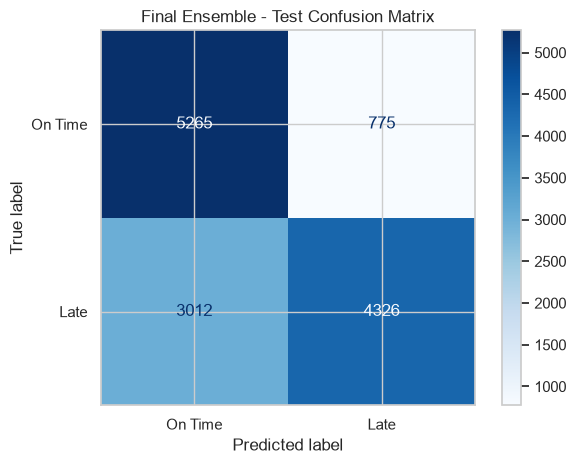


FINAL ENSEMBLE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

     On Time       0.64      0.87      0.74      6040
        Late       0.85      0.59      0.70      7338

    accuracy                           0.72     13378
   macro avg       0.74      0.73      0.72     13378
weighted avg       0.75      0.72      0.71     13378



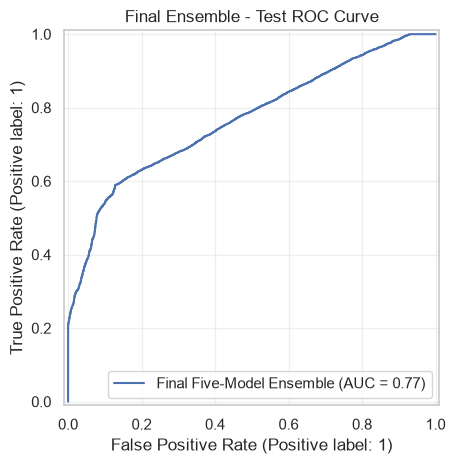


FINAL MODEL CONFIGURATION
Model: Five-Model Soft Voting Ensemble
Number of models: 5
Weight per model: 0.20
Selected features: 100
Classification threshold: 0.5
Test observations: 13378


In [464]:

# ============================================================
# FINAL ENSEMBLE MODEL - TEST EVALUATION
# EXPERIMENT 2: FIVE-MODEL SOFT VOTING ENSEMBLE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# ============================================================
# 1. FINAL ENSEMBLE CONFIGURATION
# ============================================================

final_test_threshold_exp2 = 0.50

final_ensemble_models_exp2 = {
    "Logistic Regression": best_lr,
    "Decision Tree": grid_dt.best_estimator_,
    "Random Forest": best_rf,
    "LightGBM": best_lgb,
    "Linear SVM": calibrated_svm_exp2
}

# ============================================================
# 2. PREPARE TEST DATA
# ============================================================

final_test_actual_exp2 = np.asarray(y_test).ravel()

assert X_test.shape[0] == len(final_test_actual_exp2)
assert X_test.shape[1] == len(final_feature_names)
assert set(np.unique(final_test_actual_exp2)) == {0, 1}

# Check column names if available
if hasattr(X_test, "columns"):
    assert list(X_test.columns) == list(final_feature_names), (
        "Test feature names/order do not match."
    )

# Additional feature alignment check when original
# transformed test matrix and selected indices exist
if (
    "X_test_tree" in globals()
    and "final_indices" in globals()
):
    indices = np.asarray(final_indices).astype(int)
    expected_test = X_test_tree[:, indices]

    if sparse.issparse(X_test) or sparse.issparse(expected_test):
        A = sparse.csr_matrix(X_test)
        B = sparse.csr_matrix(expected_test)
        difference = (A - B).tocsr()

        test_aligned = (
            difference.nnz == 0
            or np.allclose(difference.data, 0, atol=1e-10)
        )
    else:
        test_aligned = np.allclose(
            np.asarray(X_test),
            np.asarray(expected_test),
            atol=1e-10
        )

    assert test_aligned, (
        "Test features do not match selected feature order."
    )

    print("Test feature alignment verified.")
else:
    print(
        "WARNING: Test feature order was not independently "
        "verified against the original transformed matrix."
    )

print("Test observations:", len(final_test_actual_exp2))
print("Selected features:", X_test.shape[1])

# ============================================================
# 3. GENERATE FIVE-MODEL ENSEMBLE PROBABILITIES
# ============================================================

final_test_model_probabilities_exp2 = []

for name, model in final_ensemble_models_exp2.items():

    class_index = list(model.classes_).index(1)

    probability = model.predict_proba(
        X_test
    )[:, class_index]

    final_test_model_probabilities_exp2.append(probability)

# Equal-weight soft voting
final_test_probability_exp2 = np.mean(
    final_test_model_probabilities_exp2,
    axis=0
)

assert np.isfinite(final_test_probability_exp2).all()
assert np.all(
    (final_test_probability_exp2 >= 0) &
    (final_test_probability_exp2 <= 1)
)

# ============================================================
# 4. FINAL TEST CLASSIFICATION
# ============================================================

final_test_prediction_exp2 = (
    final_test_probability_exp2 >= final_test_threshold_exp2
).astype(int)

# ============================================================
# 5. FINAL ENSEMBLE TEST METRICS
# ============================================================

final_test_metrics_exp2 = {
    "Model": "Final Five-Model Ensemble",
    "Threshold": final_test_threshold_exp2,

    "Accuracy": accuracy_score(
        final_test_actual_exp2,
        final_test_prediction_exp2
    ),

    "Precision": precision_score(
        final_test_actual_exp2,
        final_test_prediction_exp2,
        zero_division=0
    ),

    "Recall": recall_score(
        final_test_actual_exp2,
        final_test_prediction_exp2,
        zero_division=0
    ),

    "F1": f1_score(
        final_test_actual_exp2,
        final_test_prediction_exp2,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        final_test_actual_exp2,
        final_test_probability_exp2
    ),

    "Average Precision": average_precision_score(
        final_test_actual_exp2,
        final_test_probability_exp2
    )
}

final_test_results_exp2 = pd.DataFrame(
    [final_test_metrics_exp2]
)

print("\n" + "=" * 60)
print("FINAL ENSEMBLE MODEL - TEST PERFORMANCE")
print("=" * 60)

display(final_test_results_exp2.round(4))

# ============================================================
# 6. CONFUSION MATRIX
# ============================================================

final_test_cm_exp2 = confusion_matrix(
    final_test_actual_exp2,
    final_test_prediction_exp2,
    labels=[0, 1]
)

print("\nFINAL TEST CONFUSION MATRIX")
print(final_test_cm_exp2)

ConfusionMatrixDisplay(
    confusion_matrix=final_test_cm_exp2,
    display_labels=["On Time", "Late"]
).plot(cmap="Blues", values_format="d")

plt.title("Final Ensemble - Test Confusion Matrix")
plt.tight_layout()
plt.show()

# ============================================================
# 7. CLASSIFICATION REPORT
# ============================================================

print("\nFINAL ENSEMBLE - CLASSIFICATION REPORT")

print(
    classification_report(
        final_test_actual_exp2,
        final_test_prediction_exp2,
        labels=[0, 1],
        target_names=["On Time", "Late"],
        zero_division=0
    )
)

# ============================================================
# 8. ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    final_test_actual_exp2,
    final_test_probability_exp2,
    name="Final Five-Model Ensemble"
)

plt.title("Final Ensemble - Test ROC Curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 9. FINAL CONFIGURATION SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL MODEL CONFIGURATION")
print("=" * 60)

print("Model: Five-Model Soft Voting Ensemble")
print("Number of models: 5")
print("Weight per model: 0.20")
print("Selected features:", X_test.shape[1])
print("Classification threshold:", final_test_threshold_exp2)
print("Test observations:", len(final_test_actual_exp2))

# ============================================================
# INTERPRETATION
# ============================================================

# This evaluation measures the final five-model ensemble
# on the independent test dataset.
#
# Each component contributes 20% of the final
# late-delivery probability.
#
# The classification threshold is fixed at 0.50,
# as selected during validation.
#
# Accuracy measures overall correct classifications.
#
# Precision measures how many predicted late deliveries
# are actually late.
#
# Recall measures how many actual late deliveries
# are correctly identified.
#
# F1-score balances precision and recall.
#
# ROC-AUC evaluates class-ranking performance.
#
# Average Precision summarizes precision-recall
# performance across thresholds.
#
# The confusion matrix shows TP, TN, FP and FN counts.
#
# Test performance should be compared with validation
# performance to assess generalization.
#
# This test set should not be used to choose new
# hyperparameters, features or classification thresholds.
# ============================================================


In [ ]:
fjkdkd

In [465]:

# ============================================================
# FINAL ENSEMBLE PROBABILITY FUNCTION - EXPERIMENT 2
# LENS 1 - LATE DELIVERY RISK PREDICTION
# ============================================================

import numpy as np

FINAL_THRESHOLD_EXP2 = 0.50

ENSEMBLE_WEIGHTS_EXP2 = {
    "Logistic Regression": 0.20,
    "Decision Tree": 0.20,
    "Random Forest": 0.20,
    "LightGBM": 0.20,
    "Linear SVM": 0.20
}

def predict_ensemble_risk_exp2(X):
    """
    Predict late-delivery probability using the verified
    five-model soft-voting ensemble.

    X must contain the same 100 selected encoded features
    in the original training feature order.
    """

    assert X.shape[1] == len(final_feature_names), (
        "Incorrect number of selected features."
    )

    if hasattr(X, "columns"):
        assert list(X.columns) == list(final_feature_names), (
            "Feature names or column order do not match."
        )

    models = {
        "Logistic Regression": best_lr,
        "Decision Tree": grid_dt.best_estimator_,
        "Random Forest": best_rf,
        "LightGBM": best_lgb,
        "Linear SVM": calibrated_svm_exp2
    }

    probabilities = np.zeros(X.shape[0], dtype=float)

    for name, model in models.items():

        class_index = list(model.classes_).index(1)

        model_prob = model.predict_proba(X)[:, class_index]

        probabilities += (
            ENSEMBLE_WEIGHTS_EXP2[name] * model_prob
        )

    return probabilities


# ============================================================
# VERIFY AGAINST EXISTING EXPERIMENT 2 VALIDATION ENSEMBLE
# ============================================================

recreated_probabilities_exp2 = predict_ensemble_risk_exp2(
    X_val
)

difference_exp2 = np.abs(
    recreated_probabilities_exp2 -
    np.asarray(ensemble_probability_exp2).ravel()
)

print("Maximum reconstruction error:", difference_exp2.max())
print("Mean reconstruction error:", difference_exp2.mean())

assert np.allclose(
    recreated_probabilities_exp2,
    ensemble_probability_exp2,
    rtol=1e-7,
    atol=1e-8
), "Reconstructed Experiment 2 ensemble probabilities differ."

print("\nExperiment 2 ensemble formula verified.")

# ============================================================
# APPLY SELECTED CLASSIFICATION THRESHOLD
# ============================================================

final_val_prob_exp2 = recreated_probabilities_exp2

final_val_pred_exp2 = (
    final_val_prob_exp2 >= FINAL_THRESHOLD_EXP2
).astype(int)

print("Threshold:", FINAL_THRESHOLD_EXP2)
print("Predicted late deliveries:", final_val_pred_exp2.sum())

# ============================================================
# FINAL FUNCTION VERIFICATION
# ============================================================

print("\nFINAL ENSEMBLE CONFIGURATION")
print("Number of models: 5")
print("Weight per model: 20%")
print("Selected features:", len(final_feature_names))
print("Classification threshold:", FINAL_THRESHOLD_EXP2)


Maximum reconstruction error: 3.3306690738754696e-16
Mean reconstruction error: 5.270014881414386e-17

Experiment 2 ensemble formula verified.
Threshold: 0.5
Predicted late deliveries: 5256

FINAL ENSEMBLE CONFIGURATION
Number of models: 5
Weight per model: 20%
Selected features: 100
Classification threshold: 0.5


In [466]:

# ============================================================
# EXPERIMENT 2 - FINAL TEST PREDICTIONS
# ============================================================

final_test_probability_exp2 = predict_ensemble_risk_exp2(
    X_test
)

final_test_prediction_exp2 = (
    final_test_probability_exp2 >= FINAL_THRESHOLD_EXP2
).astype(int)

print("Final ensemble test predictions generated.")
print("Total test observations:", len(final_test_prediction_exp2))
print("Predicted late:", final_test_prediction_exp2.sum())
print("Predicted on time:",
      (final_test_prediction_exp2 == 0).sum())


Final ensemble test predictions generated.
Total test observations: 13378
Predicted late: 5101
Predicted on time: 8277


FINAL ENSEMBLE - TEST PERFORMANCE


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Final Five-Model Ensemble,0.5,0.7169,0.8481,0.5895,0.6956,0.7675,0.8303,0.1854,0.5407



CONFUSION MATRIX
[[5265  775]
 [3012 4326]]

True Negatives: 5265
False Positives: 775
False Negatives: 3012
True Positives: 4326


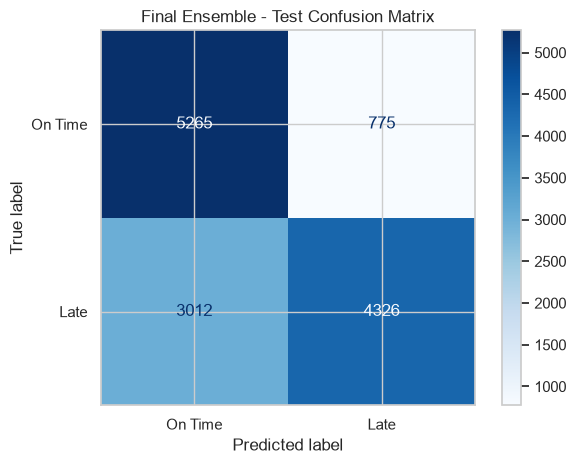


FINAL ENSEMBLE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

     On Time       0.64      0.87      0.74      6040
        Late       0.85      0.59      0.70      7338

    accuracy                           0.72     13378
   macro avg       0.74      0.73      0.72     13378
weighted avg       0.75      0.72      0.71     13378



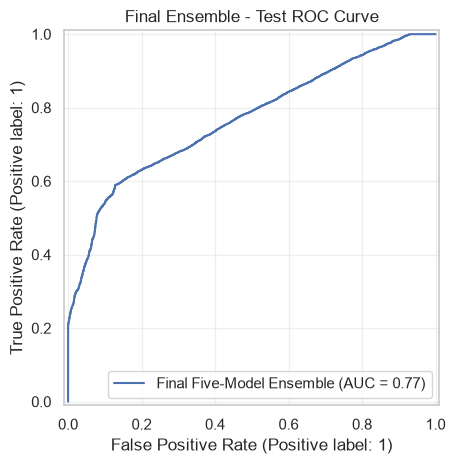

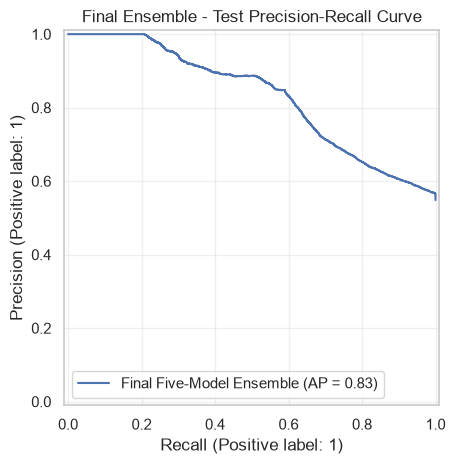


FINAL ENSEMBLE CONFIGURATION
Model: Five-Model Soft Voting Ensemble
Models: LR + DT + RF + LightGBM + Linear SVM
Equal weight per model: 20%
Selected features: 100
Threshold: 0.5
Total test observations: 13378
Predicted Late: 5101
Predicted On Time: 8277


In [467]:

# ============================================================
# FINAL ENSEMBLE MODEL - TEST EVALUATION
# EXPERIMENT 2: FIVE-MODEL SOFT VOTING ENSEMBLE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    brier_score_loss,
    log_loss
)

# ============================================================
# 1. PREPARE FINAL TEST DATA
# ============================================================

actual_test_exp2 = np.asarray(y_test).ravel()

assert len(actual_test_exp2) == X_test.shape[0]
assert X_test.shape[1] == len(final_feature_names)
assert set(np.unique(actual_test_exp2)) == {0, 1}

# Ensure that test preprocessing and feature order have
# already been verified against training preprocessing.

# ============================================================
# 2. GENERATE FINAL ENSEMBLE TEST PREDICTIONS
# ============================================================

final_test_probability_exp2 = predict_ensemble_risk_exp2(
    X_test
)

final_test_prediction_exp2 = (
    final_test_probability_exp2 >= FINAL_THRESHOLD_EXP2
).astype(int)

# Validate probabilities
assert np.isfinite(final_test_probability_exp2).all()
assert np.all(
    (final_test_probability_exp2 >= 0) &
    (final_test_probability_exp2 <= 1)
)

# ============================================================
# 3. CALCULATE ALL FINAL TEST METRICS
# ============================================================

final_test_metrics_exp2 = {
    "Model": "Final Five-Model Ensemble",
    "Threshold": FINAL_THRESHOLD_EXP2,

    "Accuracy": accuracy_score(
        actual_test_exp2, final_test_prediction_exp2
    ),

    "Precision": precision_score(
        actual_test_exp2, final_test_prediction_exp2,
        zero_division=0
    ),

    "Recall": recall_score(
        actual_test_exp2, final_test_prediction_exp2,
        zero_division=0
    ),

    "F1": f1_score(
        actual_test_exp2, final_test_prediction_exp2,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        actual_test_exp2, final_test_probability_exp2
    ),

    "Average Precision": average_precision_score(
        actual_test_exp2, final_test_probability_exp2
    ),

    "Brier Score": brier_score_loss(
        actual_test_exp2, final_test_probability_exp2
    ),

    "Log Loss": log_loss(
        actual_test_exp2, final_test_probability_exp2,
        labels=[0, 1]
    )
}

final_test_results_exp2 = pd.DataFrame(
    [final_test_metrics_exp2]
)

print("=" * 60)
print("FINAL ENSEMBLE - TEST PERFORMANCE")
print("=" * 60)

display(final_test_results_exp2.round(4))

# ============================================================
# 4. CONFUSION MATRIX
# ============================================================

cm_final_exp2 = confusion_matrix(
    actual_test_exp2,
    final_test_prediction_exp2,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_final_exp2.ravel()

print("\nCONFUSION MATRIX")
print(cm_final_exp2)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

ConfusionMatrixDisplay(
    confusion_matrix=cm_final_exp2,
    display_labels=["On Time", "Late"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Final Ensemble - Test Confusion Matrix")
plt.tight_layout()
plt.show()

# ============================================================
# 5. CLASSIFICATION REPORT
# ============================================================

print("\nFINAL ENSEMBLE - CLASSIFICATION REPORT")

print(
    classification_report(
        actual_test_exp2,
        final_test_prediction_exp2,
        labels=[0, 1],
        target_names=["On Time", "Late"],
        zero_division=0
    )
)

# ============================================================
# 6. ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    actual_test_exp2,
    final_test_probability_exp2,
    name="Final Five-Model Ensemble"
)

plt.title("Final Ensemble - Test ROC Curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 7. PRECISION-RECALL CURVE
# ============================================================

PrecisionRecallDisplay.from_predictions(
    actual_test_exp2,
    final_test_probability_exp2,
    name="Final Five-Model Ensemble"
)

plt.title("Final Ensemble - Test Precision-Recall Curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 8. FINAL MODEL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL ENSEMBLE CONFIGURATION")
print("=" * 60)

print("Model: Five-Model Soft Voting Ensemble")
print("Models: LR + DT + RF + LightGBM + Linear SVM")
print("Equal weight per model: 20%")
print("Selected features:", len(final_feature_names))
print("Threshold:", FINAL_THRESHOLD_EXP2)
print("Total test observations:", len(actual_test_exp2))
print("Predicted Late:", final_test_prediction_exp2.sum())
print("Predicted On Time:",
      (final_test_prediction_exp2 == 0).sum())

# ============================================================
# INTERPRETATION
# ============================================================

# The final Experiment 2 ensemble combines five tuned
# models using equal-weight probability averaging.
#
# The operating threshold was fixed at 0.50 during
# validation and is not changed on the test dataset.
#
# Accuracy measures overall classification correctness.
# Precision evaluates reliability of late predictions.
# Recall measures detection of actual late deliveries.
# F1-score balances precision and recall.
# ROC-AUC evaluates ranking performance.
# Average Precision summarizes precision-recall quality.
# Brier Score and Log Loss evaluate probability quality.
#
# The confusion matrix identifies TN, FP, FN and TP.
#
# These test results should be compared against
# validation performance to assess generalization.
#
# Do not use test results to retune the model.
# ============================================================


### Business Lens 02

EXPERIMENT 2 - SHIPMENT RISK DISTRIBUTION


,Probability_Range,Shipments,Mean_Risk,Actual_Late_Rate,Actual_Late_Count,Late_Rate_%
3,"(0.15, 0.2]",120,0.1845,0.0000,0,0.0000
4,"(0.2, 0.25]",284,0.2288,0.0070,2,0.7042
5,"(0.25, 0.3]",166,0.2878,0.3012,50,30.1205
6,"(0.3, 0.35]",1747,0.3268,0.3246,567,32.4556
7,"(0.35, 0.4]",3168,0.3813,0.3889,1232,38.8889
8,"(0.4, 0.45]",2704,0.4168,0.4205,1137,42.0488
9,"(0.45, 0.5]",102,0.4596,0.4412,45,44.1176
10,"(0.5, 0.55]",3,0.5115,1.0000,3,100.0000
11,"(0.55, 0.6]",1,0.5927,0.0000,0,0.0000
12,"(0.6, 0.65]",11,0.6363,0.8182,9,81.8182


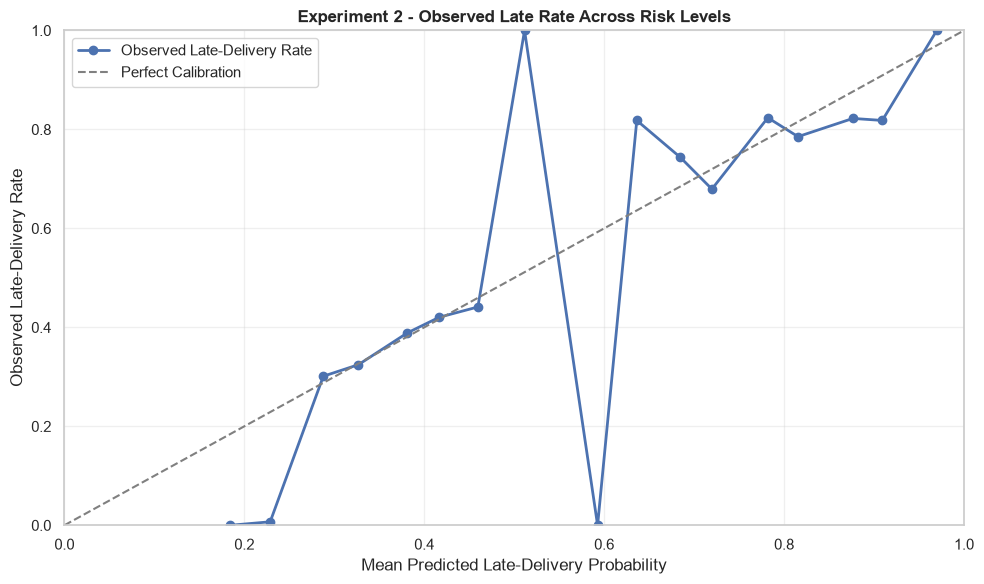


EXPERIMENT 2 - RISK BAND PERFORMANCE


,Risk_Band,Shipments,Actual_Late_Count,Actual_Late_Rate,Mean_Predicted_Risk,Shipment_Share_%,Late_Rate_%,Late_Capture_%
0,Low,570,52,0.09,0.24,4.21,9.12,0.69
1,Medium,7736,2993,0.39,0.38,57.10,38.69,39.91
2,High,5241,4454,0.85,0.84,38.69,84.98,59.39


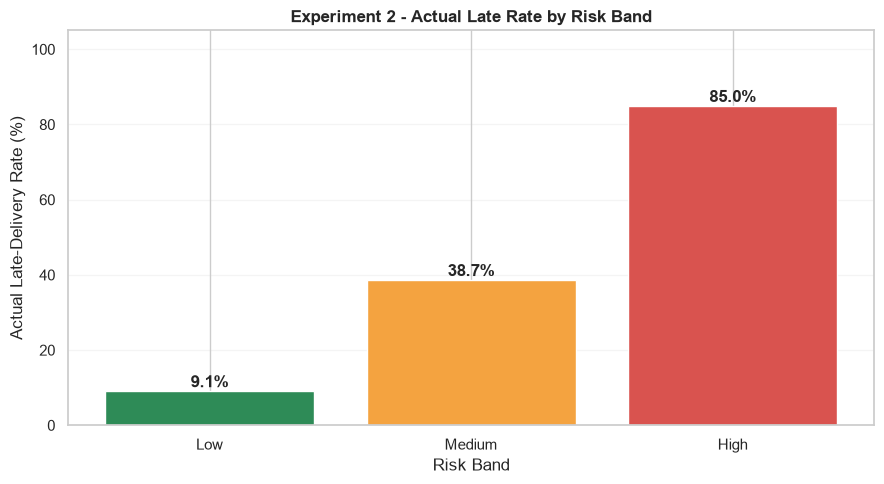


EXPERIMENT 2 - RISK BAND INTERPRETATION
Low Risk: 570 records | Late Rate: 9.12% | Late Capture: 0.69%
Medium Risk: 7736 records | Late Rate: 38.69% | Late Capture: 39.91%
High Risk: 5241 records | Late Rate: 84.98% | Late Capture: 59.39%

Risk bands are provisional and independent of the binary classification threshold 0.50.
Review risk separation and shipment counts before freezing the bands for test evaluation.


In [468]:

# ============================================================
# LENS 2 - EXPERIMENT 2
# SHIPMENT RISK DISTRIBUTION AND RISK BAND ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration - Experiment 2
# ------------------------------------------------------------

CLASSIFICATION_THRESHOLD_EXP2 = 0.50

# Provisional business risk-band boundaries
RISK_LOW_LIMIT_EXP2 = 0.30
RISK_HIGH_LIMIT_EXP2 = 0.65

assert (
    0 < RISK_LOW_LIMIT_EXP2 < RISK_HIGH_LIMIT_EXP2 < 1
)

# Use verified five-model ensemble validation predictions
risk_probabilities_exp2 = np.asarray(
    ensemble_probability_exp2
).ravel()

actual_labels_exp2 = np.asarray(y_val).ravel()

assert len(risk_probabilities_exp2) == len(actual_labels_exp2)
assert len(risk_probabilities_exp2) == len(X_val_encoded)
assert X_val_encoded.index.equals(y_val.index)

assert np.isfinite(risk_probabilities_exp2).all()
assert np.all(
    (risk_probabilities_exp2 >= 0) &
    (risk_probabilities_exp2 <= 1)
)
assert set(np.unique(actual_labels_exp2)) == {0, 1}

# ------------------------------------------------------------
# 2. Create validation risk analysis dataset
# ------------------------------------------------------------

risk_analysis_exp2 = pd.DataFrame({
    "Predicted_Risk": risk_probabilities_exp2,
    "Actual_Late": actual_labels_exp2
}, index=X_val_encoded.index)

# ------------------------------------------------------------
# 3. Analyze predicted probabilities in 5% intervals
# ------------------------------------------------------------

risk_analysis_exp2["Probability_Range"] = pd.cut(
    risk_analysis_exp2["Predicted_Risk"],
    bins=np.linspace(0, 1, 21),
    include_lowest=True
)

risk_distribution_exp2 = (
    risk_analysis_exp2
    .groupby("Probability_Range", observed=False)
    .agg(
        Shipments=("Actual_Late", "size"),
        Mean_Risk=("Predicted_Risk", "mean"),
        Actual_Late_Rate=("Actual_Late", "mean"),
        Actual_Late_Count=("Actual_Late", "sum")
    )
    .reset_index()
)

risk_distribution_exp2 = risk_distribution_exp2[
    risk_distribution_exp2["Shipments"] > 0
].copy()

risk_distribution_exp2["Late_Rate_%"] = (
    risk_distribution_exp2["Actual_Late_Rate"] * 100
)

print("EXPERIMENT 2 - SHIPMENT RISK DISTRIBUTION")
display(risk_distribution_exp2.round(4))

# ------------------------------------------------------------
# 4. Visualize probability vs observed late-delivery rate
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    risk_distribution_exp2["Mean_Risk"],
    risk_distribution_exp2["Actual_Late_Rate"],
    marker="o",
    linewidth=2,
    label="Observed Late-Delivery Rate"
)

plt.plot(
    [0, 1], [0, 1],
    "--",
    color="gray",
    label="Perfect Calibration"
)

plt.title(
    "Experiment 2 - Observed Late Rate Across Risk Levels",
    fontweight="bold"
)
plt.xlabel("Mean Predicted Late-Delivery Probability")
plt.ylabel("Observed Late-Delivery Rate")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Create Low, Medium and High risk bands
# ------------------------------------------------------------

risk_analysis_exp2["Risk_Band"] = pd.cut(
    risk_analysis_exp2["Predicted_Risk"],
    bins=[
        -np.inf,
        RISK_LOW_LIMIT_EXP2,
        RISK_HIGH_LIMIT_EXP2,
        np.inf
    ],
    labels=["Low", "Medium", "High"],
    right=False
)

# ------------------------------------------------------------
# 6. Evaluate risk-band performance
# ------------------------------------------------------------

risk_band_summary_exp2 = (
    risk_analysis_exp2
    .groupby("Risk_Band", observed=False)
    .agg(
        Shipments=("Actual_Late", "size"),
        Actual_Late_Count=("Actual_Late", "sum"),
        Actual_Late_Rate=("Actual_Late", "mean"),
        Mean_Predicted_Risk=("Predicted_Risk", "mean")
    )
    .reset_index()
)

total_shipments_exp2 = len(risk_analysis_exp2)
total_late_exp2 = risk_analysis_exp2["Actual_Late"].sum()

risk_band_summary_exp2["Shipment_Share_%"] = (
    100 * risk_band_summary_exp2["Shipments"]
    / total_shipments_exp2
)

risk_band_summary_exp2["Late_Rate_%"] = (
    100 * risk_band_summary_exp2["Actual_Late_Rate"]
)

risk_band_summary_exp2["Late_Capture_%"] = (
    100 * risk_band_summary_exp2["Actual_Late_Count"]
    / total_late_exp2
)

print("\nEXPERIMENT 2 - RISK BAND PERFORMANCE")
display(risk_band_summary_exp2.round(2))

# ------------------------------------------------------------
# 7. Visualize actual late rates
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(
    risk_band_summary_exp2["Risk_Band"].astype(str),
    risk_band_summary_exp2["Late_Rate_%"],
    color=["#2E8B57", "#F4A340", "#D9534F"]
)

for bar, value in zip(
    bars,
    risk_band_summary_exp2["Late_Rate_%"]
):
    if pd.notna(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.1f}%",
            ha="center",
            fontweight="bold"
        )

plt.title(
    "Experiment 2 - Actual Late Rate by Risk Band",
    fontweight="bold"
)

plt.xlabel("Risk Band")
plt.ylabel("Actual Late-Delivery Rate (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Automatic interpretation
# ------------------------------------------------------------

print("\nEXPERIMENT 2 - RISK BAND INTERPRETATION")
print("=" * 60)

for _, row in risk_band_summary_exp2.iterrows():
    print(
        f"{row['Risk_Band']} Risk: "
        f"{int(row['Shipments'])} records | "
        f"Late Rate: {row['Late_Rate_%']:.2f}% | "
        f"Late Capture: {row['Late_Capture_%']:.2f}%"
    )

print(
    "\nRisk bands are provisional and independent "
    "of the binary classification threshold 0.50."
)

print(
    "Review risk separation and shipment counts "
    "before freezing the bands for test evaluation."
)


In [469]:

# ============================================================
# LENS 2 - EXPERIMENT 2
# RECOVER VALIDATION ORDER IDS AND BUSINESS INFORMATION
# ============================================================

# ------------------------------------------------------------
# 1. Verify original data and validation row alignment
# ------------------------------------------------------------

required_columns_exp2 = [
    "Order Id",
    "Order Item Total",
    "Customer Segment"
]

assert df_ml.index.is_unique
assert X_val_encoded.index.is_unique
assert X_val_encoded.index.equals(y_val.index)

assert all(
    col in df_ml.columns
    for col in required_columns_exp2
)

assert all(
    col in X_val_encoded.columns
    for col in ["Order Item Total", "Customer Segment"]
)

assert X_val_encoded.index.isin(df_ml.index).all()

# ------------------------------------------------------------
# 2. Recover original business data
# ------------------------------------------------------------

validation_order_lines_exp2 = df_ml.loc[
    X_val_encoded.index,
    required_columns_exp2
].copy()

# Check monetary and segment alignment
original_values_exp2 = pd.to_numeric(
    validation_order_lines_exp2["Order Item Total"],
    errors="raise"
)

encoded_values_exp2 = pd.to_numeric(
    X_val_encoded["Order Item Total"],
    errors="raise"
)

value_match_exp2 = np.allclose(
    original_values_exp2.to_numpy(),
    encoded_values_exp2.to_numpy(),
    rtol=1e-5,
    atol=1e-4
)

segment_match_exp2 = (
    validation_order_lines_exp2["Customer Segment"]
    .fillna("<MISSING>")
    .astype(str).to_numpy()
    ==
    X_val_encoded["Customer Segment"]
    .fillna("<MISSING>")
    .astype(str).to_numpy()
).all()

assert value_match_exp2, "Order values do not match."
assert segment_match_exp2, "Customer segments do not match."

assert validation_order_lines_exp2["Order Id"].notna().all()
assert original_values_exp2.notna().all()
assert np.isfinite(original_values_exp2).all()

# ------------------------------------------------------------
# 3. Add Experiment 2 predictions and actual outcomes
# ------------------------------------------------------------

validation_order_lines_exp2["Predicted_Risk"] = (
    risk_probabilities_exp2
)

validation_order_lines_exp2["Actual_Late"] = (
    actual_labels_exp2
)

validation_order_lines_exp2["Risk_Band"] = (
    risk_analysis_exp2["Risk_Band"]
)

print("EXPERIMENT 2 - ORDER RECOVERY VERIFICATION")
print("=" * 60)

print("Validation records:", len(validation_order_lines_exp2))
print("Order values match:", value_match_exp2)
print("Customer segments match:", segment_match_exp2)

print(
    "Unique Order IDs:",
    validation_order_lines_exp2["Order Id"].nunique()
)

display(validation_order_lines_exp2.head(10))

# ------------------------------------------------------------
# 4. Monetary value distribution
# ------------------------------------------------------------

print("\nORDER-LINE VALUE DISTRIBUTION")

display(
    validation_order_lines_exp2["Order Item Total"]
    .describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    )
    .round(2)
)

# ------------------------------------------------------------
# 5. Customer segment and monetary value
# ------------------------------------------------------------

segment_value_summary_exp2 = (
    validation_order_lines_exp2
    .groupby("Customer Segment", dropna=False)
    .agg(
        Records=("Order Item Total", "size"),
        Average_Line_Value=("Order Item Total", "mean"),
        Median_Line_Value=("Order Item Total", "median"),
        Total_Line_Value=("Order Item Total", "sum"),
        Actual_Late_Rate=("Actual_Late", "mean")
    )
    .reset_index()
)

segment_value_summary_exp2["Record_Share_%"] = (
    100 * segment_value_summary_exp2["Records"]
    / len(validation_order_lines_exp2)
)

segment_value_summary_exp2["Late_Rate_%"] = (
    100 * segment_value_summary_exp2["Actual_Late_Rate"]
)

print("\nCUSTOMER SEGMENT BUSINESS ANALYSIS")
display(segment_value_summary_exp2.round(2))


EXPERIMENT 2 - ORDER RECOVERY VERIFICATION
Validation records: 13547
Order values match: True
Customer segments match: True
Unique Order IDs: 4932


,Order Id,Order Item Total,Customer Segment,Predicted_Risk,Actual_Late,Risk_Band
23,75917,294.980011,Corporate,0.712192,0,High
27,75913,275.309998,Corporate,0.409832,0,Medium
30,75910,262.200012,Consumer,0.393949,1,Medium
31,75909,245.809998,Consumer,0.395543,1,Medium
38,75902,309.720001,Consumer,0.774446,1,High
64,63936,269.970001,Home Office,0.801887,0,High
66,18108,176.369995,Home Office,0.812477,1,High
70,63936,139.500000,Home Office,0.801896,0,High
76,58613,170.970001,Home Office,0.810452,1,High
100,52478,225.000000,Consumer,0.336317,0,Medium



ORDER-LINE VALUE DISTRIBUTION


count    13547.00
mean       182.93
std        118.83
min          8.47
10%         52.19
25%        106.21
50%        164.00
75%        245.98
90%        339.98
95%        383.98
max       1939.99
Name: Order Item Total, dtype: float64


CUSTOMER SEGMENT BUSINESS ANALYSIS


,Customer Segment,Records,Average_Line_Value,Median_Line_Value,Total_Line_Value,Actual_Late_Rate,Record_Share_%,Late_Rate_%
0,Consumer,7134,182.46,163.99,1301668.23,0.57,52.66,56.92
1,Corporate,4180,183.60,165.99,767443.21,0.53,30.86,52.82
2,Home Office,2233,183.16,165.99,409001.83,0.55,16.48,55.08


In [470]:

# ============================================================
# LENS 2 - EXPERIMENT 2
# ORDER CONSISTENCY, COMPLETENESS AND AGGREGATION
# ============================================================

# ------------------------------------------------------------
# 1. Check consistency within each order
# ------------------------------------------------------------

order_consistency_exp2 = (
    validation_order_lines_exp2
    .groupby("Order Id")
    .agg(
        Line_Count=("Actual_Late", "size"),
        Unique_Labels=("Actual_Late", "nunique"),
        Unique_Segments=("Customer Segment", "nunique"),
        Minimum_Risk=("Predicted_Risk", "min"),
        Maximum_Risk=("Predicted_Risk", "max"),
        Mean_Risk=("Predicted_Risk", "mean")
    )
    .reset_index()
)

order_consistency_exp2["Risk_Range"] = (
    order_consistency_exp2["Maximum_Risk"]
    - order_consistency_exp2["Minimum_Risk"]
)

mixed_labels_exp2 = order_consistency_exp2[
    order_consistency_exp2["Unique_Labels"] != 1
]

mixed_segments_exp2 = order_consistency_exp2[
    order_consistency_exp2["Unique_Segments"] != 1
]

print("EXPERIMENT 2 - ORDER CONSISTENCY")
print("=" * 60)

print("Unique orders:", len(order_consistency_exp2))
print("Mixed-label orders:", len(mixed_labels_exp2))
print("Mixed-segment orders:", len(mixed_segments_exp2))

print("\nWITHIN-ORDER PREDICTION VARIATION")
display(
    order_consistency_exp2["Risk_Range"]
    .describe()
    .round(4)
)

# ------------------------------------------------------------
# 2. Verify order completeness
# ------------------------------------------------------------

original_order_counts_exp2 = (
    df_ml.groupby("Order Id").size()
)

validation_order_counts_exp2 = (
    validation_order_lines_exp2
    .groupby("Order Id").size()
)

order_completeness_exp2 = pd.DataFrame({
    "Original_Line_Count":
        original_order_counts_exp2.reindex(
            validation_order_counts_exp2.index
        ),
    "Validation_Line_Count":
        validation_order_counts_exp2
})

order_completeness_exp2["Is_Complete"] = (
    order_completeness_exp2["Original_Line_Count"]
    == order_completeness_exp2["Validation_Line_Count"]
)

print("\nEXPERIMENT 2 - ORDER COMPLETENESS")
print("=" * 60)

print("Orders:", len(order_completeness_exp2))
print("Complete orders:",
      int(order_completeness_exp2["Is_Complete"].sum()))
print("Incomplete orders:",
      int((~order_completeness_exp2["Is_Complete"]).sum()))

print(
    "Completeness percentage:",
    round(
        order_completeness_exp2["Is_Complete"].mean() * 100,
        2
    )
)

# ------------------------------------------------------------
# 3. Stop if order-level aggregation is not valid
# ------------------------------------------------------------

assert len(mixed_labels_exp2) == 0, (
    "Some orders have inconsistent late-delivery labels."
)

assert len(mixed_segments_exp2) == 0, (
    "Some orders have inconsistent customer segments."
)

assert order_completeness_exp2["Is_Complete"].all(), (
    "Some validation orders are incomplete."
)

# ------------------------------------------------------------
# 4. Aggregate one record per unique order
# ------------------------------------------------------------

order_level_val_exp2 = (
    validation_order_lines_exp2
    .groupby("Order Id", sort=False)
    .agg(
        Order_Line_Count=("Actual_Late", "size"),
        Total_Order_Value=("Order Item Total", "sum"),
        Predicted_Risk=("Predicted_Risk", "mean"),
        Actual_Late=("Actual_Late", "first"),
        Customer_Segment=("Customer Segment", "first"),
        Risk_Min=("Predicted_Risk", "min"),
        Risk_Max=("Predicted_Risk", "max")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 5. Verify order-level aggregation
# ------------------------------------------------------------

assert len(order_level_val_exp2) == (
    validation_order_lines_exp2["Order Id"].nunique()
)

assert np.isclose(
    order_level_val_exp2["Total_Order_Value"].sum(),
    validation_order_lines_exp2["Order Item Total"].sum()
)

print("\nEXPERIMENT 2 - ORDER-LEVEL VALIDATION DATASET")
display(order_level_val_exp2.head(10))

print("\nORDER-LEVEL VALUE DISTRIBUTION")
display(
    order_level_val_exp2["Total_Order_Value"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
    .round(2)
)

print("\nOrder-level aggregation completed.")


EXPERIMENT 2 - ORDER CONSISTENCY
Unique orders: 4932
Mixed-label orders: 0
Mixed-segment orders: 0

WITHIN-ORDER PREDICTION VARIATION


count    4932.0000
mean        0.0063
std         0.0070
min         0.0000
25%         0.0000
50%         0.0045
75%         0.0101
max         0.0495
Name: Risk_Range, dtype: float64


EXPERIMENT 2 - ORDER COMPLETENESS
Orders: 4932
Complete orders: 4932
Incomplete orders: 0
Completeness percentage: 100.0

EXPERIMENT 2 - ORDER-LEVEL VALIDATION DATASET


,Order Id,Order_Line_Count,Total_Order_Value,Predicted_Risk,Actual_Late,Customer_Segment,Risk_Min,Risk_Max
0,75917,1,294.980011,0.712192,0,Corporate,0.712192,0.712192
1,75913,1,275.309998,0.409832,0,Corporate,0.409832,0.409832
2,75910,1,262.200012,0.393949,1,Consumer,0.393949,0.393949
3,75909,1,245.809998,0.395543,1,Consumer,0.395543,0.395543
4,75902,1,309.720001,0.774446,1,Consumer,0.774446,0.774446
5,63936,3,537.440002,0.804131,0,Home Office,0.801887,0.808610
6,18108,3,435.050003,0.813225,1,Home Office,0.812477,0.813625
7,58613,4,671.430008,0.805531,1,Home Office,0.795536,0.810452
8,52478,5,928.320015,0.342513,0,Consumer,0.333752,0.352572
9,58034,3,881.930023,0.349000,1,Consumer,0.344080,0.357402



ORDER-LEVEL VALUE DISTRIBUTION


count    4932.00
mean      502.46
std       317.49
min         8.47
25%       249.38
50%       456.88
75%       720.79
90%       940.97
95%      1074.30
max      2517.07
Name: Total_Order_Value, dtype: float64


Order-level aggregation completed.


In [471]:

# ============================================================
# LENS 2 - EXPERIMENT 2
# TRAINING-BASED ORDER VALUE IMPACT THRESHOLDS
# ============================================================

# ------------------------------------------------------------
# 1. Recover training order information
# ------------------------------------------------------------

assert X_train_encoded.index.is_unique
assert X_train_encoded.index.equals(y_train.index)
assert X_train_encoded.index.isin(df_ml.index).all()

train_order_source_exp2 = df_ml.loc[
    X_train_encoded.index,
    ["Order Id", "Order Item Total"]
].copy()

assert train_order_source_exp2["Order Id"].notna().all()

# Check training order values
assert np.allclose(
    pd.to_numeric(
        train_order_source_exp2["Order Item Total"]
    ).to_numpy(),
    pd.to_numeric(
        X_train_encoded["Order Item Total"]
    ).to_numpy(),
    rtol=1e-5,
    atol=1e-4
)

# ------------------------------------------------------------
# 2. Check training/validation order separation
# ------------------------------------------------------------

train_order_ids_exp2 = set(
    train_order_source_exp2["Order Id"]
)

val_order_ids_exp2 = set(
    order_level_val_exp2["Order Id"]
)

assert train_order_ids_exp2.isdisjoint(
    val_order_ids_exp2
), "Training and validation contain overlapping orders."

# ------------------------------------------------------------
# 3. Check training order completeness
# ------------------------------------------------------------

training_order_counts_exp2 = (
    train_order_source_exp2.groupby("Order Id").size()
)

training_complete_exp2 = (
    training_order_counts_exp2
    == original_order_counts_exp2.reindex(
        training_order_counts_exp2.index
    )
)

print("EXPERIMENT 2 - TRAINING ORDER VERIFICATION")
print("=" * 60)

print("Training order lines:", len(train_order_source_exp2))
print("Unique training orders:", len(training_order_counts_exp2))
print("Complete training orders:",
      int(training_complete_exp2.sum()))
print("Incomplete training orders:",
      int((~training_complete_exp2).sum()))

assert training_complete_exp2.all(), (
    "Incomplete training orders detected."
)

# ------------------------------------------------------------
# 4. Calculate complete training order values
# ------------------------------------------------------------

train_order_values_exp2 = (
    train_order_source_exp2
    .groupby("Order Id")["Order Item Total"]
    .sum()
)

ORDER_IMPACT_LOW_EXP2 = (
    train_order_values_exp2.quantile(1/3)
)

ORDER_IMPACT_HIGH_EXP2 = (
    train_order_values_exp2.quantile(2/3)
)

assert ORDER_IMPACT_LOW_EXP2 < ORDER_IMPACT_HIGH_EXP2

print("\nTRAINING ORDER VALUE DISTRIBUTION")
display(
    train_order_values_exp2.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

print("\nEXPERIMENT 2 - MONETARY IMPACT BOUNDARIES")

print(
    f"Low/Medium: {ORDER_IMPACT_LOW_EXP2:.2f}"
)

print(
    f"Medium/High: {ORDER_IMPACT_HIGH_EXP2:.2f}"
)

# ------------------------------------------------------------
# Interpretation
# ------------------------------------------------------------

# These thresholds use complete order values from
# the training dataset only.
#
# They categorize monetary exposure into relative
# Low, Medium and High groups.
#
# The thresholds do not estimate the direct financial
# loss caused by late delivery.
#
# The thresholds will be frozen before test evaluation.


EXPERIMENT 2 - TRAINING ORDER VERIFICATION
Training order lines: 153594
Unique training orders: 55888
Complete training orders: 55888
Incomplete training orders: 0

TRAINING ORDER VALUE DISTRIBUTION


count    55888.00
mean       503.49
std        321.31
min          7.99
25%        243.68
50%        456.87
75%        723.11
90%        949.34
max       2768.41
Name: Order Item Total, dtype: float64


EXPERIMENT 2 - MONETARY IMPACT BOUNDARIES
Low/Medium: 314.55
Medium/High: 625.71


EXPERIMENT 2 - FINAL ORDER PRIORITY SUMMARY


,Operational_Priority,Orders,Actual_Late_Orders,Actual_Late_Rate,Total_Order_Value,Mean_Predicted_Risk,Workload_%,Late_Rate_%,Late_Capture_%,Value_Coverage_%
0,Low,1096,380,0.35,208118.67,0.37,22.22,34.67,14.00,8.40
1,Medium,3207,1794,0.56,1720178.88,0.56,65.02,55.94,66.08,69.41
2,Urgent,629,541,0.86,549815.73,0.85,12.75,86.01,19.93,22.19



RISK BAND VS MONETARY IMPACT


Impact_Band,Low,Medium,High
Risk_Band,,,
Low,62,63,73
Medium,971,938,939
High,617,640,629


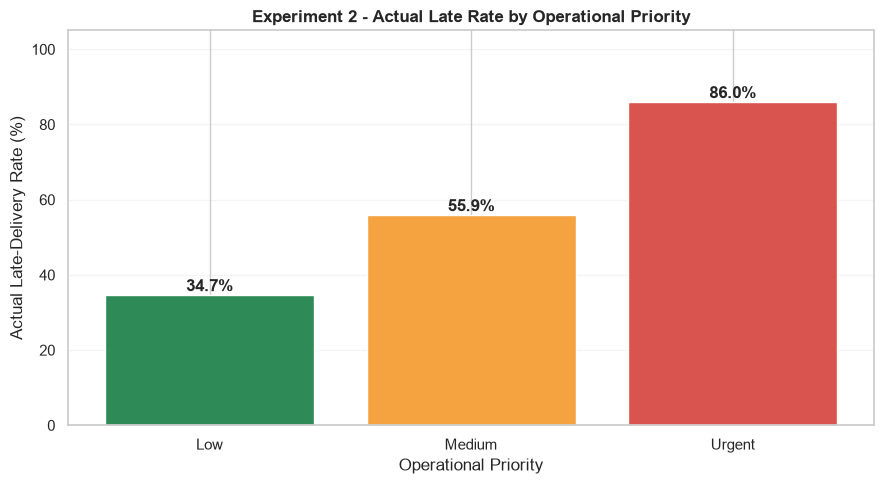


EXPERIMENT 2 - PRIORITIZED ORDER EXAMPLES


,Order Id,Order_Line_Count,Total_Order_Value,Customer_Segment,Predicted_Risk,Risk_Band,Impact_Band,Operational_Priority,Recommended_Action
2417,61789,1,227.960007,Consumer,0.979252,High,Low,Medium,Enhanced monitoring and review
1213,2247,4,729.920021,Corporate,0.978446,High,High,Urgent,Immediate operational escalation
1232,2665,2,392.970001,Corporate,0.978294,High,Medium,Medium,Enhanced monitoring and review
2681,4373,4,559.559998,Corporate,0.978259,High,Medium,Medium,Enhanced monitoring and review
4886,53157,2,333.450012,Consumer,0.978011,High,Medium,Medium,Enhanced monitoring and review
2396,67268,5,1239.380020,Consumer,0.977921,High,High,Urgent,Immediate operational escalation
2679,5463,1,129.990005,Corporate,0.977908,High,Low,Medium,Enhanced monitoring and review
2393,61638,5,947.620022,Consumer,0.977837,High,High,Urgent,Immediate operational escalation
561,14648,5,480.630001,Consumer,0.977705,High,Medium,Medium,Enhanced monitoring and review
1599,18072,2,260.160004,Consumer,0.977510,High,Low,Medium,Enhanced monitoring and review



One operational recommendation per unique order.


In [472]:

# ============================================================
# LENS 2 - EXPERIMENT 2
# FINAL VALIDATION ORDER-LEVEL PRIORITY SCORING
# ============================================================

final_order_priority_df_exp2 = (
    order_level_val_exp2.copy()
)

# ------------------------------------------------------------
# 1. Predicted risk bands
# ------------------------------------------------------------

final_order_priority_df_exp2["Risk_Band"] = pd.cut(
    final_order_priority_df_exp2["Predicted_Risk"],
    bins=[
        -np.inf,
        RISK_LOW_LIMIT_EXP2,
        RISK_HIGH_LIMIT_EXP2,
        np.inf
    ],
    labels=["Low", "Medium", "High"],
    right=False
)

# ------------------------------------------------------------
# 2. Monetary impact bands
# ------------------------------------------------------------

final_order_priority_df_exp2["Impact_Band"] = pd.cut(
    final_order_priority_df_exp2["Total_Order_Value"],
    bins=[
        -np.inf,
        ORDER_IMPACT_LOW_EXP2,
        ORDER_IMPACT_HIGH_EXP2,
        np.inf
    ],
    labels=["Low", "Medium", "High"],
    right=False
)

# ------------------------------------------------------------
# 3. Apply revised priority matrix
# ------------------------------------------------------------

urgent_exp2 = (
    (final_order_priority_df_exp2["Risk_Band"] == "High") &
    (final_order_priority_df_exp2["Impact_Band"] == "High")
)

low_exp2 = (
    (
        (final_order_priority_df_exp2["Risk_Band"] == "Low") &
        (
            final_order_priority_df_exp2["Impact_Band"]
            .isin(["Low", "Medium"])
        )
    )
    |
    (
        (final_order_priority_df_exp2["Risk_Band"] == "Medium") &
        (final_order_priority_df_exp2["Impact_Band"] == "Low")
    )
)

final_order_priority_df_exp2["Operational_Priority"] = (
    np.select(
        [urgent_exp2, low_exp2],
        ["Urgent", "Low"],
        default="Medium"
    )
)

operational_actions_exp2 = {
    "Low": "Routine tracking",
    "Medium": "Enhanced monitoring and review",
    "Urgent": "Immediate operational escalation"
}

final_order_priority_df_exp2["Recommended_Action"] = (
    final_order_priority_df_exp2["Operational_Priority"]
    .map(operational_actions_exp2)
)

# ------------------------------------------------------------
# 4. Order-level priority summary
# ------------------------------------------------------------

order_priority_summary_exp2 = (
    final_order_priority_df_exp2
    .groupby("Operational_Priority")
    .agg(
        Orders=("Order Id", "nunique"),
        Actual_Late_Orders=("Actual_Late", "sum"),
        Actual_Late_Rate=("Actual_Late", "mean"),
        Total_Order_Value=("Total_Order_Value", "sum"),
        Mean_Predicted_Risk=("Predicted_Risk", "mean")
    )
    .reindex(["Low", "Medium", "Urgent"])
    .reset_index()
)

order_priority_summary_exp2["Workload_%"] = (
    100 * order_priority_summary_exp2["Orders"]
    / len(final_order_priority_df_exp2)
)

order_priority_summary_exp2["Late_Rate_%"] = (
    100 * order_priority_summary_exp2["Actual_Late_Rate"]
)

order_priority_summary_exp2["Late_Capture_%"] = (
    100 * order_priority_summary_exp2["Actual_Late_Orders"]
    / final_order_priority_df_exp2["Actual_Late"].sum()
)

order_priority_summary_exp2["Value_Coverage_%"] = (
    100 * order_priority_summary_exp2["Total_Order_Value"]
    / final_order_priority_df_exp2["Total_Order_Value"].sum()
)

print("EXPERIMENT 2 - FINAL ORDER PRIORITY SUMMARY")
display(order_priority_summary_exp2.round(2))

# ------------------------------------------------------------
# 5. Risk vs impact matrix
# ------------------------------------------------------------

print("\nRISK BAND VS MONETARY IMPACT")

display(
    pd.crosstab(
        final_order_priority_df_exp2["Risk_Band"],
        final_order_priority_df_exp2["Impact_Band"]
    )
)

# ------------------------------------------------------------
# 6. Visualize actual late rates by priority
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(
    order_priority_summary_exp2["Operational_Priority"],
    order_priority_summary_exp2["Late_Rate_%"],
    color=["#2E8B57", "#F4A340", "#D9534F"]
)

for bar, value in zip(
    bars, order_priority_summary_exp2["Late_Rate_%"]
):
    if pd.notna(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.1f}%",
            ha="center",
            fontweight="bold"
        )

plt.title(
    "Experiment 2 - Actual Late Rate by Operational Priority",
    fontweight="bold"
)
plt.xlabel("Operational Priority")
plt.ylabel("Actual Late-Delivery Rate (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Example prioritized orders
# ------------------------------------------------------------

print("\nEXPERIMENT 2 - PRIORITIZED ORDER EXAMPLES")

display(
    final_order_priority_df_exp2[
        [
            "Order Id",
            "Order_Line_Count",
            "Total_Order_Value",
            "Customer_Segment",
            "Predicted_Risk",
            "Risk_Band",
            "Impact_Band",
            "Operational_Priority",
            "Recommended_Action"
        ]
    ]
    .sort_values(
        ["Predicted_Risk", "Total_Order_Value"],
        ascending=False
    )
    .head(10)
)

print("\nOne operational recommendation per unique order.")


In [473]:

# ============================================================
# LENS 2 - EXPERIMENT 2
# ORDER-LEVEL VALIDATION AND ESCALATION POLICY COMPARISON
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Evaluate order-level classification
# ------------------------------------------------------------

y_order_true_exp2 = (
    final_order_priority_df_exp2["Actual_Late"].to_numpy()
)

y_order_prob_exp2 = (
    final_order_priority_df_exp2["Predicted_Risk"].to_numpy()
)

y_order_pred_exp2 = (
    y_order_prob_exp2 >= CLASSIFICATION_THRESHOLD_EXP2
).astype(int)

order_model_metrics_exp2 = pd.DataFrame([{
    "Model": "Experiment 2 - Ensemble (Order Level)",
    "Threshold": CLASSIFICATION_THRESHOLD_EXP2,
    "Accuracy": accuracy_score(
        y_order_true_exp2, y_order_pred_exp2
    ),
    "Precision": precision_score(
        y_order_true_exp2, y_order_pred_exp2,
        zero_division=0
    ),
    "Recall": recall_score(
        y_order_true_exp2, y_order_pred_exp2,
        zero_division=0
    ),
    "F1": f1_score(
        y_order_true_exp2, y_order_pred_exp2,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_order_true_exp2, y_order_prob_exp2
    ),
    "Average Precision": average_precision_score(
        y_order_true_exp2, y_order_prob_exp2
    ),
    "Brier Score": brier_score_loss(
        y_order_true_exp2, y_order_prob_exp2
    ),
    "Log Loss": log_loss(
        y_order_true_exp2, y_order_prob_exp2,
        labels=[0, 1]
    )
}])

print("EXPERIMENT 2 - ORDER-LEVEL VALIDATION PERFORMANCE")
display(order_model_metrics_exp2.round(4))

print("\nORDER-LEVEL CONFUSION MATRIX")
print(
    confusion_matrix(
        y_order_true_exp2,
        y_order_pred_exp2,
        labels=[0, 1]
    )
)

# ------------------------------------------------------------
# 2. Policy A: broader escalation matrix
# ------------------------------------------------------------

policy_df_exp2 = final_order_priority_df_exp2.copy()

# Policy A includes:
# Medium Risk + High Impact
# High Risk + Medium Impact
# High Risk + High Impact

policy_df_exp2["Policy_A_Escalate"] = (
    (
        (policy_df_exp2["Risk_Band"] == "Medium") &
        (policy_df_exp2["Impact_Band"] == "High")
    )
    |
    (
        (policy_df_exp2["Risk_Band"] == "High") &
        (policy_df_exp2["Impact_Band"].isin(
            ["Medium", "High"]
        ))
    )
)

# ------------------------------------------------------------
# 3. Policy B: strict urgent escalation
# ------------------------------------------------------------

policy_df_exp2["Policy_B_Escalate"] = (
    (policy_df_exp2["Risk_Band"] == "High") &
    (policy_df_exp2["Impact_Band"] == "High")
)

# Verify selected final policy
assert (
    policy_df_exp2["Policy_B_Escalate"].to_numpy()
    ==
    (
        policy_df_exp2["Operational_Priority"]
        == "Urgent"
    ).to_numpy()
).all()

# ------------------------------------------------------------
# 4. Evaluate both policies
# ------------------------------------------------------------

total_orders_exp2 = len(policy_df_exp2)
total_late_orders_exp2 = policy_df_exp2["Actual_Late"].sum()
total_order_value_exp2 = policy_df_exp2[
    "Total_Order_Value"
].sum()

policy_results_exp2 = []

for policy_name, policy_column in [
    ("A - Broader Escalation", "Policy_A_Escalate"),
    ("B - Strict Escalation", "Policy_B_Escalate")
]:

    selected_exp2 = policy_df_exp2.loc[
        policy_df_exp2[policy_column]
    ]

    selected_count = len(selected_exp2)
    late_count = int(selected_exp2["Actual_Late"].sum())

    policy_results_exp2.append({
        "Policy": policy_name,
        "Escalated_Orders": selected_count,
        "Workload_%": (
            100 * selected_count / total_orders_exp2
        ),
        "Actual_Late_Orders": late_count,
        "Late_Capture_%": (
            100 * late_count / total_late_orders_exp2
        ),
        "Late_Rate_%": (
            100 * late_count / selected_count
            if selected_count > 0 else 0
        ),
        "False_Alerts": selected_count - late_count,
        "Value_Coverage_%": (
            100 * selected_exp2["Total_Order_Value"].sum()
            / total_order_value_exp2
            if total_order_value_exp2 > 0 else np.nan
        )
    })

policy_comparison_exp2 = pd.DataFrame(
    policy_results_exp2
)

print("\nEXPERIMENT 2 - ORDER-LEVEL ESCALATION POLICY COMPARISON")
display(policy_comparison_exp2.round(2))

# ------------------------------------------------------------
# 5. Interpretation
# ------------------------------------------------------------

print("\nPOLICY INTERPRETATION")
print("=" * 60)

print(
    "Policy A escalates more risk-impact combinations."
)

print(
    "Policy B reserves urgent escalation for orders "
    "that are both High Risk and High Impact."
)

print(
    "\nCompare workload, late-order capture, false "
    "alerts and monetary coverage."
)

print(
    "The final operational rule currently uses Policy B."
)

print(
    "\nOrder-level prediction metrics are based on "
    "mean order-line probabilities, not a separately "
    "trained or calibrated order-level classifier."
)


EXPERIMENT 2 - ORDER-LEVEL VALIDATION PERFORMANCE


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Experiment 2 - Ensemble (Order Level),0.5,0.7151,0.8462,0.5897,0.695,0.7706,0.8306,0.1859,0.5423



ORDER-LEVEL CONFUSION MATRIX
[[1926  291]
 [1114 1601]]

EXPERIMENT 2 - ORDER-LEVEL ESCALATION POLICY COMPARISON


,Policy,Escalated_Orders,Workload_%,Actual_Late_Orders,Late_Capture_%,Late_Rate_%,False_Alerts,Value_Coverage_%
0,A - Broader Escalation,2208,44.77,1434,52.82,64.95,774,67.36
1,B - Strict Escalation,629,12.75,541,19.93,86.01,88,22.19



POLICY INTERPRETATION
Policy A escalates more risk-impact combinations.
Policy B reserves urgent escalation for orders that are both High Risk and High Impact.

Compare workload, late-order capture, false alerts and monetary coverage.
The final operational rule currently uses Policy B.

Order-level prediction metrics are based on mean order-line probabilities, not a separately trained or calibrated order-level classifier.


In [474]:

# ============================================================
# LENS 2 - EXPERIMENT 2
# FINAL TEST ORDER INTEGRITY VERIFICATION
# ============================================================

from scipy import sparse

# ------------------------------------------------------------
# 1. Check test feature and target alignment
# ------------------------------------------------------------

assert X_test_encoded.index.is_unique
assert X_test_encoded.index.equals(y_test.index)
assert X_test_encoded.index.isin(df_ml.index).all()
assert X_test.shape[0] == len(y_test)
assert X_test.shape[1] == len(final_feature_names)

# ------------------------------------------------------------
# 2. Verify selected test feature matrix
# ------------------------------------------------------------

if (
    "X_test_tree" in globals()
    and "final_indices" in globals()
):

    selected_test_indices_exp2 = np.asarray(
        final_indices
    ).astype(int)

    if hasattr(X_test_tree, "iloc"):
        expected_test_features_exp2 = (
            X_test_tree.iloc[:, selected_test_indices_exp2]
        )
    else:
        expected_test_features_exp2 = (
            X_test_tree[:, selected_test_indices_exp2]
        )

    if hasattr(X_test, "columns"):
        assert list(X_test.columns) == list(final_feature_names)

    if (
        sparse.issparse(X_test)
        or sparse.issparse(expected_test_features_exp2)
    ):

        test_A_exp2 = sparse.csr_matrix(
            X_test.to_numpy()
            if hasattr(X_test, "to_numpy")
            else X_test
        )

        test_B_exp2 = sparse.csr_matrix(
            expected_test_features_exp2.to_numpy()
            if hasattr(expected_test_features_exp2, "to_numpy")
            else expected_test_features_exp2
        )

        test_diff_exp2 = (test_A_exp2 - test_B_exp2).tocsr()

        test_features_match_exp2 = (
            test_diff_exp2.nnz == 0
            or np.allclose(
                test_diff_exp2.data, 0,
                rtol=0, atol=1e-10
            )
        )

    else:

        test_features_match_exp2 = np.allclose(
            np.asarray(X_test),
            np.asarray(expected_test_features_exp2),
            rtol=0,
            atol=1e-10
        )

    assert test_features_match_exp2, (
        "Test feature values or selected order do not match."
    )

elif globals().get(
    "feature_alignment_verified_exp2", False
):
    test_features_match_exp2 = True

else:
    raise RuntimeError(
        "Test feature order has not been independently "
        "verified. Run the earlier feature-alignment check."
    )

print("Selected test features verified:",
      test_features_match_exp2)

# ------------------------------------------------------------
# 3. Recover original test order information
# ------------------------------------------------------------

test_order_source_exp2 = df_ml.loc[
    X_test_encoded.index,
    ["Order Id", "Order Item Total", "Customer Segment"]
].copy()

assert test_order_source_exp2["Order Id"].notna().all()

# ------------------------------------------------------------
# 4. Verify recovered business features
# ------------------------------------------------------------

test_value_match_exp2 = np.allclose(
    pd.to_numeric(
        test_order_source_exp2["Order Item Total"]
    ).to_numpy(),
    pd.to_numeric(
        X_test_encoded["Order Item Total"]
    ).to_numpy(),
    rtol=1e-5,
    atol=1e-4
)

test_segment_match_exp2 = (
    test_order_source_exp2["Customer Segment"]
    .fillna("<MISSING>").astype(str).to_numpy()
    ==
    X_test_encoded["Customer Segment"]
    .fillna("<MISSING>").astype(str).to_numpy()
).all()

assert test_value_match_exp2
assert test_segment_match_exp2

# ------------------------------------------------------------
# 5. Verify complete test orders
# ------------------------------------------------------------

test_counts_exp2 = (
    test_order_source_exp2.groupby("Order Id").size()
)

test_complete_exp2 = (
    test_counts_exp2
    == original_order_counts_exp2.reindex(
        test_counts_exp2.index
    )
)

# ------------------------------------------------------------
# 6. Verify group separation
# ------------------------------------------------------------

test_order_ids_exp2 = set(test_counts_exp2.index)

assert train_order_ids_exp2.isdisjoint(
    test_order_ids_exp2
), "Training and test orders overlap."

assert val_order_ids_exp2.isdisjoint(
    test_order_ids_exp2
), "Validation and test orders overlap."

assert test_complete_exp2.all(), (
    "Some test orders are incomplete."
)

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\nEXPERIMENT 2 - TEST ORDER INTEGRITY")
print("=" * 60)

print("Test order lines:", len(test_order_source_exp2))
print("Unique test orders:", len(test_counts_exp2))
print("Complete orders:", int(test_complete_exp2.sum()))
print("Incomplete orders:",
      int((~test_complete_exp2).sum()))

print("\nTRAIN / VAL / TEST GROUP SEPARATION")
print("Train-Test overlap:",
      len(train_order_ids_exp2 & test_order_ids_exp2))
print("Validation-Test overlap:",
      len(val_order_ids_exp2 & test_order_ids_exp2))

print("\nOrder integrity checks passed.")


Selected test features verified: True

EXPERIMENT 2 - TEST ORDER INTEGRITY
Test order lines: 13378
Unique test orders: 4932
Complete orders: 4932
Incomplete orders: 0

TRAIN / VAL / TEST GROUP SEPARATION
Train-Test overlap: 0
Validation-Test overlap: 0

Order integrity checks passed.


In [475]:

# ============================================================
# LENS 2 - EXPERIMENT 2
# FINAL ORDER-LEVEL TEST EVALUATION
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Use final five-model ensemble test probabilities
# ------------------------------------------------------------

if "final_test_probability_exp2" in globals():

    test_prob_exp2 = np.asarray(
        final_test_probability_exp2
    ).ravel()

    print("Using existing Lens 1 test probabilities.")

    # Verify the reusable function produces the same values
    if "predict_ensemble_risk_exp2" in globals():

        recomputed_test_prob_exp2 = (
            predict_ensemble_risk_exp2(X_test)
        )

        np.testing.assert_allclose(
            test_prob_exp2,
            recomputed_test_prob_exp2,
            rtol=1e-7,
            atol=1e-8
        )

else:

    test_prob_exp2 = np.asarray(
        predict_ensemble_risk_exp2(X_test)
    ).ravel()

    print("Generated five-model ensemble test probabilities.")

test_actual_exp2 = np.asarray(y_test).ravel()

assert len(test_prob_exp2) == len(test_actual_exp2)
assert len(test_prob_exp2) == len(test_order_source_exp2)
assert np.isfinite(test_prob_exp2).all()
assert np.all(
    (test_prob_exp2 >= 0) &
    (test_prob_exp2 <= 1)
)

# ------------------------------------------------------------
# 2. Create test order-line dataset
# ------------------------------------------------------------

test_order_lines_exp2 = test_order_source_exp2.copy()

test_order_lines_exp2["Predicted_Risk"] = test_prob_exp2
test_order_lines_exp2["Actual_Late"] = test_actual_exp2

# ------------------------------------------------------------
# 3. Aggregate to unique test orders
# ------------------------------------------------------------

test_order_level_exp2 = (
    test_order_lines_exp2
    .groupby("Order Id", sort=False)
    .agg(
        Order_Line_Count=("Actual_Late", "size"),
        Total_Order_Value=("Order Item Total", "sum"),
        Predicted_Risk=("Predicted_Risk", "mean"),
        Actual_Late=("Actual_Late", "first"),
        Customer_Segment=("Customer Segment", "first"),
        Unique_Labels=("Actual_Late", "nunique"),
        Unique_Segments=("Customer Segment", "nunique")
    )
    .reset_index()
)

assert (test_order_level_exp2["Unique_Labels"] == 1).all()
assert (test_order_level_exp2["Unique_Segments"] == 1).all()

assert len(test_order_level_exp2) == len(test_order_ids_exp2)

assert np.isclose(
    test_order_level_exp2["Total_Order_Value"].sum(),
    test_order_lines_exp2["Order Item Total"].sum()
)

# ------------------------------------------------------------
# 4. Evaluate order-level classification
# ------------------------------------------------------------

y_test_order_exp2 = (
    test_order_level_exp2["Actual_Late"].to_numpy()
)

p_test_order_exp2 = (
    test_order_level_exp2["Predicted_Risk"].to_numpy()
)

pred_test_order_exp2 = (
    p_test_order_exp2 >= CLASSIFICATION_THRESHOLD_EXP2
).astype(int)

order_test_metrics_exp2 = pd.DataFrame([{
    "Model": "Experiment 2 - Ensemble (Order Level)",
    "Threshold": CLASSIFICATION_THRESHOLD_EXP2,
    "Accuracy": accuracy_score(
        y_test_order_exp2, pred_test_order_exp2
    ),
    "Precision": precision_score(
        y_test_order_exp2, pred_test_order_exp2,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test_order_exp2, pred_test_order_exp2,
        zero_division=0
    ),
    "F1": f1_score(
        y_test_order_exp2, pred_test_order_exp2,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_order_exp2, p_test_order_exp2
    ),
    "Average Precision": average_precision_score(
        y_test_order_exp2, p_test_order_exp2
    ),
    "Brier Score": brier_score_loss(
        y_test_order_exp2, p_test_order_exp2
    ),
    "Log Loss": log_loss(
        y_test_order_exp2,
        p_test_order_exp2,
        labels=[0, 1]
    )
}])

print("EXPERIMENT 2 - ORDER-LEVEL TEST PERFORMANCE")
display(order_test_metrics_exp2.round(4))

print("\nORDER-LEVEL TEST CONFUSION MATRIX")
print(
    confusion_matrix(
        y_test_order_exp2,
        pred_test_order_exp2,
        labels=[0, 1]
    )
)

# ------------------------------------------------------------
# 5. Apply frozen business risk bands
# ------------------------------------------------------------

test_order_level_exp2["Risk_Band"] = pd.cut(
    test_order_level_exp2["Predicted_Risk"],
    bins=[
        -np.inf,
        RISK_LOW_LIMIT_EXP2,
        RISK_HIGH_LIMIT_EXP2,
        np.inf
    ],
    labels=["Low", "Medium", "High"],
    right=False
)

# ------------------------------------------------------------
# 6. Apply training-derived monetary impact bands
# ------------------------------------------------------------

test_order_level_exp2["Impact_Band"] = pd.cut(
    test_order_level_exp2["Total_Order_Value"],
    bins=[
        -np.inf,
        ORDER_IMPACT_LOW_EXP2,
        ORDER_IMPACT_HIGH_EXP2,
        np.inf
    ],
    labels=["Low", "Medium", "High"],
    right=False
)

# ------------------------------------------------------------
# 7. Apply frozen operational priority policy
# ------------------------------------------------------------

test_urgent_exp2 = (
    (test_order_level_exp2["Risk_Band"] == "High") &
    (test_order_level_exp2["Impact_Band"] == "High")
)

test_low_exp2 = (
    (
        (test_order_level_exp2["Risk_Band"] == "Low") &
        (
            test_order_level_exp2["Impact_Band"]
            .isin(["Low", "Medium"])
        )
    )
    |
    (
        (test_order_level_exp2["Risk_Band"] == "Medium") &
        (test_order_level_exp2["Impact_Band"] == "Low")
    )
)

test_order_level_exp2["Operational_Priority"] = (
    np.select(
        [test_urgent_exp2, test_low_exp2],
        ["Urgent", "Low"],
        default="Medium"
    )
)

test_order_level_exp2["Recommended_Action"] = (
    test_order_level_exp2["Operational_Priority"]
    .map(operational_actions_exp2)
)

# ------------------------------------------------------------
# 8. Evaluate business priority performance
# ------------------------------------------------------------

test_priority_summary_exp2 = (
    test_order_level_exp2
    .groupby("Operational_Priority")
    .agg(
        Orders=("Order Id", "nunique"),
        Actual_Late_Orders=("Actual_Late", "sum"),
        Total_Order_Value=("Total_Order_Value", "sum"),
        Mean_Predicted_Risk=("Predicted_Risk", "mean")
    )
    .reindex(["Low", "Medium", "Urgent"])
    .reset_index()
)

test_priority_summary_exp2["Workload_%"] = (
    100 * test_priority_summary_exp2["Orders"]
    / len(test_order_level_exp2)
)

test_priority_summary_exp2["Late_Rate_%"] = (
    100 * test_priority_summary_exp2["Actual_Late_Orders"]
    / test_priority_summary_exp2["Orders"].replace(0, np.nan)
)

test_priority_summary_exp2["Late_Capture_%"] = (
    100 * test_priority_summary_exp2["Actual_Late_Orders"]
    / test_order_level_exp2["Actual_Late"].sum()
)

test_priority_summary_exp2["Value_Coverage_%"] = (
    100 * test_priority_summary_exp2["Total_Order_Value"]
    / test_order_level_exp2["Total_Order_Value"].sum()
)

# Number of on-time orders within each tier
test_priority_summary_exp2["On_Time_Orders"] = (
    test_priority_summary_exp2["Orders"]
    - test_priority_summary_exp2["Actual_Late_Orders"]
)

print("\nEXPERIMENT 2 - FINAL TEST PRIORITY PERFORMANCE")
display(test_priority_summary_exp2.round(2))

# ------------------------------------------------------------
# 9. Final operational priority distribution
# ------------------------------------------------------------

print("\nTEST RISK BAND VS MONETARY IMPACT")

display(
    pd.crosstab(
        test_order_level_exp2["Risk_Band"],
        test_order_level_exp2["Impact_Band"]
    )
)

print("\nTEST OPERATIONAL PRIORITY COUNTS")

display(
    test_order_level_exp2["Operational_Priority"]
    .value_counts()
    .reindex(["Low", "Medium", "Urgent"], fill_value=0)
)

# ------------------------------------------------------------
# 10. Example final recommended actions
# ------------------------------------------------------------

print("\nEXAMPLE PRIORITIZED TEST ORDERS")

display(
    test_order_level_exp2[
        [
            "Order Id",
            "Total_Order_Value",
            "Customer_Segment",
            "Predicted_Risk",
            "Risk_Band",
            "Impact_Band",
            "Operational_Priority",
            "Recommended_Action"
        ]
    ]
    .sort_values(
        ["Predicted_Risk", "Total_Order_Value"],
        ascending=False
    )
    .head(10)
)

# ------------------------------------------------------------
# 11. Final result summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL PROJECT - EXPERIMENT 2 / LENS 2")
print("=" * 65)

print("Final model: Five-Model Soft Voting Ensemble")
print("Model weights: 20% each")
print("Classification threshold:", CLASSIFICATION_THRESHOLD_EXP2)

print(
    "Risk boundaries:",
    RISK_LOW_LIMIT_EXP2,
    RISK_HIGH_LIMIT_EXP2
)

print(
    "Monetary impact boundaries:",
    round(ORDER_IMPACT_LOW_EXP2, 2),
    round(ORDER_IMPACT_HIGH_EXP2, 2)
)

print("\nUnique test orders:", len(test_order_level_exp2))

print(
    "Actual late orders:",
    int(test_order_level_exp2["Actual_Late"].sum())
)

print(
    "Urgent orders:",
    int(
        (
            test_order_level_exp2["Operational_Priority"]
            == "Urgent"
        ).sum()
    )
)

print(
    "Total order value:",
    round(test_order_level_exp2["Total_Order_Value"].sum(), 2)
)

print("\nOne recommendation per unique order: True")


Using existing Lens 1 test probabilities.
EXPERIMENT 2 - ORDER-LEVEL TEST PERFORMANCE


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Experiment 2 - Ensemble (Order Level),0.5,0.72,0.8525,0.594,0.7001,0.7734,0.8344,0.1838,0.5371



ORDER-LEVEL TEST CONFUSION MATRIX
[[1939  279]
 [1102 1612]]

EXPERIMENT 2 - FINAL TEST PRIORITY PERFORMANCE


,Operational_Priority,Orders,Actual_Late_Orders,Total_Order_Value,Mean_Predicted_Risk,Workload_%,Late_Rate_%,Late_Capture_%,Value_Coverage_%,On_Time_Orders
0,Low,1114,380,211340.36,0.36,22.59,34.11,14.00,8.67,734
1,Medium,3243,1852,1722833.86,0.57,65.75,57.11,68.24,70.70,1391
2,Urgent,575,482,502803.81,0.84,11.66,83.83,17.76,20.63,93



TEST RISK BAND VS MONETARY IMPACT


Impact_Band,Low,Medium,High
Risk_Band,,,
Low,90,73,65
Medium,951,934,931
High,645,668,575



TEST OPERATIONAL PRIORITY COUNTS


Operational_Priority
Low       1114
Medium    3243
Urgent     575
Name: count, dtype: int64


EXAMPLE PRIORITIZED TEST ORDERS


,Order Id,Total_Order_Value,Customer_Segment,Predicted_Risk,Risk_Band,Impact_Band,Operational_Priority,Recommended_Action
894,19650,293.950012,Consumer,0.979716,High,Low,Medium,Enhanced monitoring and review
2632,16978,379.980011,Corporate,0.979159,High,Medium,Medium,Enhanced monitoring and review
1487,15681,775.870010,Consumer,0.978951,High,High,Urgent,Immediate operational escalation
1493,10822,47.990002,Consumer,0.978814,High,Low,Medium,Enhanced monitoring and review
4374,14797,846.310020,Home Office,0.978619,High,High,Urgent,Immediate operational escalation
2630,10812,431.429997,Corporate,0.978386,High,Medium,Medium,Enhanced monitoring and review
1160,20412,232.759995,Corporate,0.978071,High,Low,Medium,Enhanced monitoring and review
1788,28074,336.570007,Consumer,0.978012,High,Medium,Medium,Enhanced monitoring and review
1934,33907,278.950012,Corporate,0.977897,High,Low,Medium,Enhanced monitoring and review
1194,67249,616.740009,Corporate,0.977681,High,Medium,Medium,Enhanced monitoring and review



FINAL PROJECT - EXPERIMENT 2 / LENS 2
Final model: Five-Model Soft Voting Ensemble
Model weights: 20% each
Classification threshold: 0.5
Risk boundaries: 0.3 0.65
Monetary impact boundaries: 314.55 625.71

Unique test orders: 4932
Actual late orders: 2714
Urgent orders: 575
Total order value: 2436978.03

One recommendation per unique order: True


In [476]:

# ============================================================
# EXPERIMENT 2 - FINAL LENS 2 RESULTS COMPARISON
# ============================================================

# Order-level prediction metrics
order_validation_vs_test_exp2 = pd.concat([
    order_model_metrics_exp2.assign(Dataset="Validation"),
    order_test_metrics_exp2.assign(Dataset="Test")
], ignore_index=True)

print("EXPERIMENT 2 - ORDER-LEVEL MODEL COMPARISON")
display(order_validation_vs_test_exp2.round(4))

# Business priority performance
priority_validation_vs_test_exp2 = pd.concat([
    order_priority_summary_exp2.assign(Dataset="Validation"),
    test_priority_summary_exp2.assign(Dataset="Test")
], ignore_index=True)

comparison_columns_exp2 = [
    "Dataset",
    "Operational_Priority",
    "Orders",
    "Workload_%",
    "Late_Rate_%",
    "Late_Capture_%",
    "Value_Coverage_%"
]

print("\nEXPERIMENT 2 - OPERATIONAL PRIORITY COMPARISON")
display(
    priority_validation_vs_test_exp2[
        comparison_columns_exp2
    ].round(2)
)


EXPERIMENT 2 - ORDER-LEVEL MODEL COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score,Log Loss,Dataset
0,Experiment 2 - Ensemble (Order Level),0.5,0.7151,0.8462,0.5897,0.6950,0.7706,0.8306,0.1859,0.5423,Validation
1,Experiment 2 - Ensemble (Order Level),0.5,0.7200,0.8525,0.5940,0.7001,0.7734,0.8344,0.1838,0.5371,Test



EXPERIMENT 2 - OPERATIONAL PRIORITY COMPARISON


,Dataset,Operational_Priority,Orders,Workload_%,Late_Rate_%,Late_Capture_%,Value_Coverage_%
0,Validation,Low,1096,22.22,34.67,14.00,8.40
1,Validation,Medium,3207,65.02,55.94,66.08,69.41
2,Validation,Urgent,629,12.75,86.01,19.93,22.19
3,Test,Low,1114,22.59,34.11,14.00,8.67
4,Test,Medium,3243,65.75,57.11,68.24,70.70
5,Test,Urgent,575,11.66,83.83,17.76,20.63


In [478]:

# ============================================================
# CELL 01 - EXPERIMENT 2
# FINAL LENS 1 + LENS 2 CONNECTION
# TEST FEATURE, PROBABILITY AND ORDER INTEGRITY CHECK
# ============================================================

import numpy as np
import pandas as pd
from scipy import sparse

# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_exp2 = [
    "X_test",
    "y_test",
    "X_val",
    "y_val",
    "X_test_tree",
    "final_indices",
    "final_feature_names",
    "tree_preprocessor",
    "X_test_encoded",
    "X_train_encoded",
    "X_val_encoded",
    "df_ml",
    "ensemble_probability_exp2",
    "predict_ensemble_risk_exp2",
    "ORDER_IMPACT_LOW_EXP2",
    "ORDER_IMPACT_HIGH_EXP2"
]

missing_exp2 = [
    name for name in required_exp2
    if name not in globals()
]

if missing_exp2:
    raise NameError(
        "Missing required variables: "
        + ", ".join(missing_exp2)
    )

print("Required Experiment 2 variables: AVAILABLE")

# ============================================================
# 2. FREEZE FINAL EXPERIMENT 2 CONFIGURATION
# ============================================================

# Final five-model ensemble classification threshold
FINAL_TEST_THRESHOLD_EXP2 = 0.50

# Provisional risk boundaries selected before test evaluation
FINAL_RISK_LOW_EXP2 = 0.30
FINAL_RISK_HIGH_EXP2 = 0.65

# Validate risk boundaries
assert (
    0 < FINAL_RISK_LOW_EXP2 <
    FINAL_RISK_HIGH_EXP2 < 1
)

# Training-derived monetary impact thresholds
assert (
    0 <= ORDER_IMPACT_LOW_EXP2 <
    ORDER_IMPACT_HIGH_EXP2
)

print("\nFINAL EXPERIMENT 2 CONFIGURATION")
print("=" * 60)

print("Model: Five-Model Soft Voting Ensemble")
print("Number of models: 5")
print("Weight per model: 20%")
print("Classification threshold:", FINAL_TEST_THRESHOLD_EXP2)
print("Risk boundaries:",
      FINAL_RISK_LOW_EXP2,
      FINAL_RISK_HIGH_EXP2)

print(
    "Monetary impact boundaries:",
    round(ORDER_IMPACT_LOW_EXP2, 2),
    round(ORDER_IMPACT_HIGH_EXP2, 2)
)

# ============================================================
# 3. VERIFY VALIDATION AND TEST ROW ALIGNMENT
# CORRECTED FOR SCIPY SPARSE MATRICES
# ============================================================

assert df_ml.index.is_unique

assert X_train_encoded.index.is_unique
assert X_val_encoded.index.is_unique
assert X_test_encoded.index.is_unique

assert X_test_encoded.index.equals(y_test.index)
assert X_val_encoded.index.equals(y_val.index)

assert X_test_encoded.index.isin(df_ml.index).all()
assert X_train_encoded.index.isin(df_ml.index).all()
assert X_val_encoded.index.isin(df_ml.index).all()

# IMPORTANT:
# Use shape[0], not len(), for sparse feature matrices.

assert X_test.shape[0] == len(y_test), (
    "Test feature rows and target rows do not match."
)

assert X_val.shape[0] == len(y_val), (
    "Validation feature rows and target rows do not match."
)

# Verify selected feature counts
assert X_test.shape[1] == len(final_feature_names), (
    "Test feature count mismatch."
)

assert X_val.shape[1] == len(final_feature_names), (
    "Validation feature count mismatch."
)

# Check original encoded row counts
assert X_test_encoded.shape[0] == X_test.shape[0]
assert X_val_encoded.shape[0] == X_val.shape[0]

print("\nROW AND FEATURE ALIGNMENT VERIFICATION")
print("=" * 60)

print("Test observations:", X_test.shape[0])
print("Test selected features:", X_test.shape[1])

print("Validation observations:", X_val.shape[0])
print("Validation selected features:", X_val.shape[1])

print("\nRow and feature count checks: PASSED")

# ============================================================
# 4. VERIFY SELECTED FEATURE IDENTITIES AND ORDER
# ============================================================

selected_idx_exp2 = np.asarray(
    final_indices
).ravel().astype(int)

feature_names_exp2 = np.asarray(
    final_feature_names
)

all_names_exp2 = np.asarray(
    tree_preprocessor.get_feature_names_out()
)

# Verify valid feature indices
assert len(selected_idx_exp2) == len(feature_names_exp2)

assert len(np.unique(selected_idx_exp2)) == len(
    selected_idx_exp2
)

assert selected_idx_exp2.min() >= 0
assert selected_idx_exp2.max() < len(all_names_exp2)

# Verify selected feature names
assert np.array_equal(
    all_names_exp2[selected_idx_exp2],
    feature_names_exp2
), (
    "Selected feature names do not match "
    "the feature selection indices."
)

# Reconstruct selected test features
if hasattr(X_test_tree, "iloc"):

    expected_test_exp2 = X_test_tree.iloc[
        :, selected_idx_exp2
    ]

else:

    expected_test_exp2 = X_test_tree[
        :, selected_idx_exp2
    ]

# ============================================================
# 5. SPARSE-SAFE FEATURE MATRIX COMPARISON
# ============================================================

def matrices_match_integrated_exp2(A, B, atol=1e-10):

    if A.shape != B.shape:
        return False

    if sparse.issparse(A) or sparse.issparse(B):

        def to_csr(M):

            if hasattr(M, "to_numpy"):
                M = M.to_numpy()

            return sparse.csr_matrix(M)

        A_sparse = to_csr(A)
        B_sparse = to_csr(B)

        difference = (A_sparse - B_sparse).tocsr()
        difference.eliminate_zeros()

        return (
            difference.nnz == 0
            or np.allclose(
                difference.data,
                0,
                rtol=0,
                atol=atol
            )
        )

    A_array = (
        A.to_numpy()
        if hasattr(A, "to_numpy")
        else np.asarray(A)
    )

    B_array = (
        B.to_numpy()
        if hasattr(B, "to_numpy")
        else np.asarray(B)
    )

    return np.allclose(
        A_array,
        B_array,
        rtol=0,
        atol=atol
    )


# Verify test feature values and selected column order
test_features_match_exp2 = matrices_match_integrated_exp2(
    X_test,
    expected_test_exp2
)

assert test_features_match_exp2, (
    "Test feature values or column order mismatch."
)

# Verify column names if DataFrame
if hasattr(X_test, "columns"):

    assert list(X_test.columns) == list(
        final_feature_names
    ), "Test DataFrame columns are not in the correct order."

print("\nFEATURE MATRIX VERIFICATION")
print("=" * 60)

print("Selected features:", len(feature_names_exp2))
print("Test feature matrix matches:", test_features_match_exp2)
print("Feature identity and order check: PASSED")

# ============================================================
# 6. VERIFY FIVE-MODEL ENSEMBLE PROBABILITIES
# ============================================================

# Reconstruct validation probabilities
validation_prob_check_exp2 = np.asarray(
    predict_ensemble_risk_exp2(X_val)
).ravel()

stored_validation_prob_exp2 = np.asarray(
    ensemble_probability_exp2
).ravel()

# Verify previously validated Experiment 2 ensemble
np.testing.assert_allclose(
    validation_prob_check_exp2,
    stored_validation_prob_exp2,
    rtol=1e-7,
    atol=1e-8
)

print("\nENSEMBLE PROBABILITY VERIFICATION")
print("=" * 60)

print(
    "Maximum validation probability difference:",
    np.max(
        np.abs(
            validation_prob_check_exp2 -
            stored_validation_prob_exp2
        )
    )
)

print("Five-model ensemble verification: PASSED")

# ============================================================
# 7. GENERATE AND VERIFY TEST PROBABILITIES
# ============================================================

recomputed_test_prob_exp2 = np.asarray(
    predict_ensemble_risk_exp2(X_test)
).ravel()

# If Lens 1 already calculated test probabilities,
# verify that both lenses use exactly the same predictions.

if "final_test_probability_exp2" in globals():

    np.testing.assert_allclose(
        np.asarray(
            final_test_probability_exp2
        ).ravel(),
        recomputed_test_prob_exp2,
        rtol=1e-7,
        atol=1e-8
    )

    print("\nExisting Lens 1 test probabilities: MATCHED")

else:

    print("\nTest probabilities generated using final ensemble.")

# Shared probabilities for Lens 1 + Lens 2
integrated_test_prob_exp2 = recomputed_test_prob_exp2

integrated_test_actual_exp2 = np.asarray(
    y_test
).ravel()

assert integrated_test_prob_exp2.shape[0] == (
    integrated_test_actual_exp2.shape[0]
)

assert np.isfinite(integrated_test_prob_exp2).all()

assert np.all(
    (integrated_test_prob_exp2 >= 0) &
    (integrated_test_prob_exp2 <= 1)
)

assert set(
    np.unique(integrated_test_actual_exp2)
) == {0, 1}

print("Lens 1 -> Lens 2 probability connection: PASSED")

# ============================================================
# 8. RECOVER ORIGINAL TEST ORDER INFORMATION
# ============================================================

required_order_columns_exp2 = [
    "Order Id",
    "Order Item Total",
    "Customer Segment"
]

assert all(
    column in df_ml.columns
    for column in required_order_columns_exp2
)

original_test_lines_exp2 = df_ml.loc[
    X_test_encoded.index,
    required_order_columns_exp2
].copy()

assert original_test_lines_exp2["Order Id"].notna().all()

# Verify monetary value alignment
test_value_match_exp2 = np.allclose(
    pd.to_numeric(
        original_test_lines_exp2["Order Item Total"],
        errors="raise"
    ).to_numpy(),
    pd.to_numeric(
        X_test_encoded["Order Item Total"],
        errors="raise"
    ).to_numpy(),
    rtol=1e-5,
    atol=1e-4
)

# Verify customer segment alignment
test_segment_match_exp2 = (
    original_test_lines_exp2["Customer Segment"]
    .fillna("<MISSING>")
    .astype(str)
    .to_numpy()
    ==
    X_test_encoded["Customer Segment"]
    .fillna("<MISSING>")
    .astype(str)
    .to_numpy()
).all()

assert test_value_match_exp2, (
    "Test order monetary values do not align."
)

assert test_segment_match_exp2, (
    "Test customer segments do not align."
)

print("\nORIGINAL ORDER INFORMATION RECOVERY")
print("=" * 60)

print("Recovered test records:", len(original_test_lines_exp2))
print("Order monetary values match:", test_value_match_exp2)
print("Customer segments match:", test_segment_match_exp2)

# ============================================================
# 9. VERIFY COMPLETE ORDERS
# ============================================================

original_order_counts_exp2 = (
    df_ml.groupby("Order Id").size()
)

test_order_counts_integrated_exp2 = (
    original_test_lines_exp2
    .groupby("Order Id")
    .size()
)

test_complete_integrated_exp2 = (
    test_order_counts_integrated_exp2
    ==
    original_order_counts_exp2.reindex(
        test_order_counts_integrated_exp2.index
    )
)

print("\nORDER COMPLETENESS VERIFICATION")
print("=" * 60)

print(
    "Unique test orders:",
    len(test_order_counts_integrated_exp2)
)

print(
    "Complete test orders:",
    int(test_complete_integrated_exp2.sum())
)

print(
    "Incomplete test orders:",
    int((~test_complete_integrated_exp2).sum())
)

assert test_complete_integrated_exp2.all(), (
    "Some test orders are incomplete. "
    "Order-level aggregation is not safe."
)

print("Order completeness: PASSED")

# ============================================================
# 10. VERIFY TRAIN / VALIDATION / TEST ORDER SEPARATION
# ============================================================

train_order_ids_integrated_exp2 = set(
    df_ml.loc[
        X_train_encoded.index, "Order Id"
    ]
)

val_order_ids_integrated_exp2 = set(
    df_ml.loc[
        X_val_encoded.index, "Order Id"
    ]
)

test_order_ids_integrated_exp2 = set(
    original_test_lines_exp2["Order Id"]
)

train_val_overlap_exp2 = len(
    train_order_ids_integrated_exp2
    & val_order_ids_integrated_exp2
)

train_test_overlap_exp2 = len(
    train_order_ids_integrated_exp2
    & test_order_ids_integrated_exp2
)

val_test_overlap_exp2 = len(
    val_order_ids_integrated_exp2
    & test_order_ids_integrated_exp2
)

print("\nTRAIN / VALIDATION / TEST ORDER SEPARATION")
print("=" * 60)

print("Train/Validation overlap:", train_val_overlap_exp2)
print("Train/Test overlap:", train_test_overlap_exp2)
print("Validation/Test overlap:", val_test_overlap_exp2)

assert train_val_overlap_exp2 == 0
assert train_test_overlap_exp2 == 0
assert val_test_overlap_exp2 == 0

print("Order-level split separation: PASSED")

# ============================================================
# 11. FINAL LENS 1 + LENS 2 CONNECTION SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("EXPERIMENT 2 - FINAL LENS 1 + LENS 2 CONNECTION")
print("=" * 65)

print("Final Model: Five-Model Soft Voting Ensemble")
print("Equal Model Weights: 20% each")
print("Classification Threshold:", FINAL_TEST_THRESHOLD_EXP2)
print("Selected Features:", len(feature_names_exp2))

print("\nVERIFICATION RESULTS")
print("-" * 65)

print("Test row alignment: PASSED")
print("Feature matrix alignment: PASSED")
print("Five-model ensemble probability verification: PASSED")
print("Lens 1 -> Lens 2 prediction connection: PASSED")
print("Original business data alignment: PASSED")
print("Test order completeness: PASSED")
print("Train/Validation/Test order separation: PASSED")

print("\nTEST DATASET")
print("Order-line records:", X_test.shape[0])
print("Unique orders:", len(test_order_ids_integrated_exp2))

print("\nSUCCESS: Lens 1 and Lens 2 data connection verified.")
print("Ready for the combined final test evaluation.")

# ============================================================
# INTERPRETATION
# ============================================================

# The final Experiment 2 ensemble uses five tuned
# classification models with equal 20% weights.
#
# The selected classification threshold is 0.50.
#
# This verification confirms that the selected
# test matrix matches the recorded feature selection,
# that the prediction function reproduces saved
# validation probabilities, and that test predictions
# align with the original test order-line data.
#
# Complete orders are verified before aggregation.
#
# Train, validation and test order IDs are checked
# to prevent overlap between data splits.
#
# Lens 1 predicts late-delivery probabilities.
#
# Lens 2 reuses those probabilities and combines them
# with complete order values for prioritization.
#
# These checks do not independently prove that
# preprocessing was fitted on training data only.
#
# This cell does not retune any fitted model.
# ============================================================


Required Experiment 2 variables: AVAILABLE

FINAL EXPERIMENT 2 CONFIGURATION
Model: Five-Model Soft Voting Ensemble
Number of models: 5
Weight per model: 20%
Classification threshold: 0.5
Risk boundaries: 0.3 0.65
Monetary impact boundaries: 314.55 625.71

ROW AND FEATURE ALIGNMENT VERIFICATION
Test observations: 13378
Test selected features: 100
Validation observations: 13547
Validation selected features: 100

Row and feature count checks: PASSED

FEATURE MATRIX VERIFICATION
Selected features: 100
Test feature matrix matches: True
Feature identity and order check: PASSED

ENSEMBLE PROBABILITY VERIFICATION
Maximum validation probability difference: 4.440892098500626e-16
Five-model ensemble verification: PASSED

Existing Lens 1 test probabilities: MATCHED
Lens 1 -> Lens 2 probability connection: PASSED

ORIGINAL ORDER INFORMATION RECOVERY
Recovered test records: 13378
Order monetary values match: True
Customer segments match: True

ORDER COMPLETENESS VERIFICATION
Unique test orders: 493

EXPERIMENT 2 - CONNECTED FINAL TEST EVALUATION
Final Model: Five-Model Soft Voting Ensemble
Number of Models: 5
Model Weights: 20% each
Classification Threshold: 0.5
Connection Verification: PASSED

LENS 1 - FINAL TEST PERFORMANCE


,Evaluation_Level,Records,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Lens 1 - Order Lines,13378,0.5,0.7169,0.8481,0.5895,0.6956,0.7675,0.8303,0.1854,0.5407



LENS 1 -> LENS 2 ORDER-LINE DATA


,Order Id,Order Item Total,Customer Segment,Predicted_Risk,Actual_Late,Predicted_Class
8,75932,278.589996,Corporate,0.789159,1,1
34,75906,321.200012,Consumer,0.960905,1,1
36,75904,314.640015,Corporate,0.959459,1,1
43,75897,285.140015,Home Office,0.455036,0,0
46,75894,272.029999,Corporate,0.743367,1,1
97,52166,136.500000,Consumer,0.284969,0,0
108,54585,207.500000,Consumer,0.345980,1,0
111,60673,149.960007,Consumer,0.318346,0,0
114,10007,187.500000,Consumer,0.332847,0,0
131,53331,296.950012,Consumer,0.354488,0,0



Order-line records: 13378
Unique Order IDs: 4932

ORDER-LEVEL CONSISTENCY VERIFICATION
Mixed-label orders: 0
Mixed-segment orders: 0

Within-order risk variation:


count    4932.0000
mean        0.0063
std         0.0070
min         0.0000
25%         0.0000
50%         0.0045
75%         0.0101
max         0.0499
Name: Risk_Range, dtype: float64


LENS 2 - UNIQUE ORDER DATASET


,Order Id,Order_Line_Count,Total_Order_Value,Predicted_Risk,Actual_Late,Customer_Segment,Minimum_Risk,Maximum_Risk
0,75932,1,278.589996,0.789159,1,Corporate,0.789159,0.789159
1,75906,1,321.200012,0.960905,1,Consumer,0.960905,0.960905
2,75904,1,314.640015,0.959459,1,Corporate,0.959459,0.959459
3,75897,1,285.140015,0.455036,0,Home Office,0.455036,0.455036
4,75894,1,272.029999,0.743367,1,Corporate,0.743367,0.743367
5,52166,5,943.550022,0.295249,0,Consumer,0.282274,0.321350
6,54585,1,207.500000,0.345980,1,Consumer,0.345980,0.345980
7,60673,1,149.960007,0.318346,0,Consumer,0.318346,0.318346
8,10007,5,1139.440002,0.332550,0,Consumer,0.328803,0.334452
9,53331,4,1135.880035,0.354662,0,Consumer,0.352096,0.359877



Total unique orders: 4932
Order-level aggregation: PASSED

LENS 2 - FINAL ORDER-LEVEL TEST PERFORMANCE


,Evaluation_Level,Records,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Lens 2 - Unique Orders,4932,0.5,0.72,0.8525,0.594,0.7001,0.7734,0.8344,0.1838,0.5371



EXPERIMENT 2 - FINAL CONNECTED TEST COMPARISON


,Evaluation_Level,Records,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Lens 1 - Order Lines,13378,0.5,0.7169,0.8481,0.5895,0.6956,0.7675,0.8303,0.1854,0.5407
1,Lens 2 - Unique Orders,4932,0.5,0.7200,0.8525,0.5940,0.7001,0.7734,0.8344,0.1838,0.5371



Lens 1 - Order-Line Confusion Matrix
[[5265  775]
 [3012 4326]]
True Negatives: 5265
False Positives: 775
False Negatives: 3012
True Positives: 4326


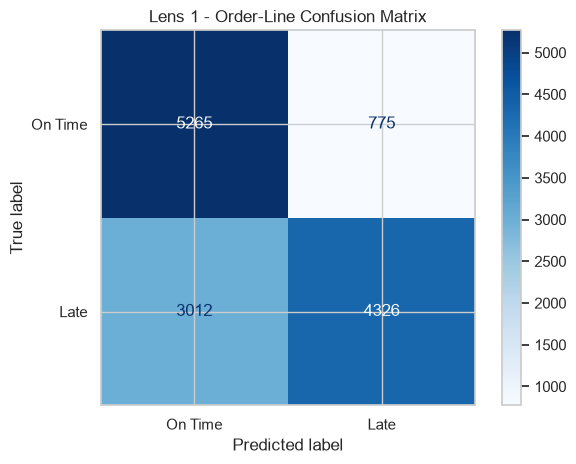


Lens 2 - Unique-Order Confusion Matrix
[[1939  279]
 [1102 1612]]
True Negatives: 1939
False Positives: 279
False Negatives: 1102
True Positives: 1612


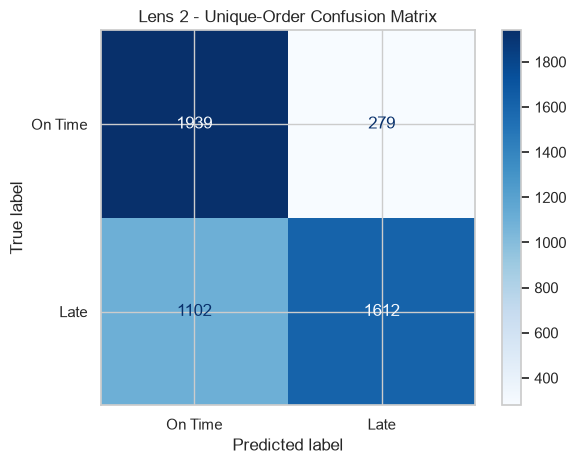


LENS 1 - ORDER-LINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

     On Time       0.64      0.87      0.74      6040
        Late       0.85      0.59      0.70      7338

    accuracy                           0.72     13378
   macro avg       0.74      0.73      0.72     13378
weighted avg       0.75      0.72      0.71     13378


LENS 2 - UNIQUE-ORDER CLASSIFICATION REPORT
              precision    recall  f1-score   support

     On Time       0.64      0.87      0.74      2218
        Late       0.85      0.59      0.70      2714

    accuracy                           0.72      4932
   macro avg       0.75      0.73      0.72      4932
weighted avg       0.76      0.72      0.72      4932



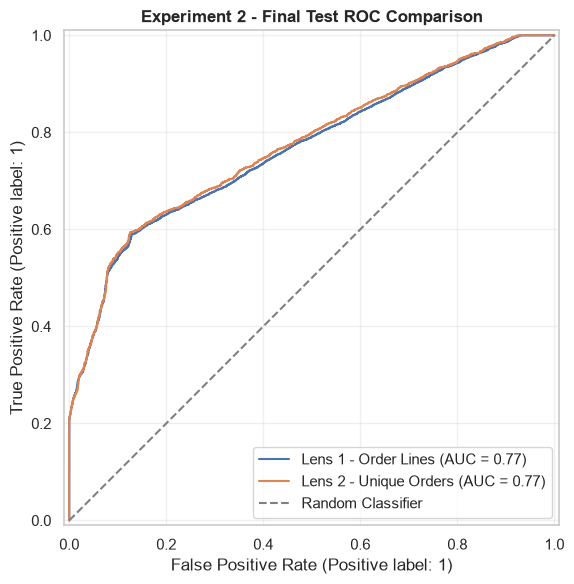

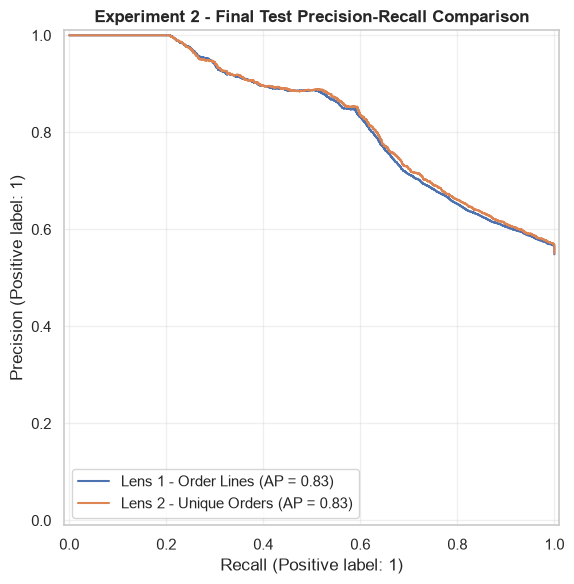


Stored Lens 1 probabilities: VERIFIED
Stored Lens 1 predictions: VERIFIED
Stored Lens 1 metrics: VERIFIED

FINAL EXPERIMENT 2 - LENS 1 + LENS 2
Model: Five-Model Soft Voting Ensemble
Model Weights: 20% each
Classification Threshold: 0.5

Lens 1 - Test Order Lines: 13378
Lens 2 - Unique Test Orders: 4932

Order-line to unique-order mapping: VERIFIED
Complete order aggregation: VERIFIED
Connected model test evaluation: COMPLETED


In [479]:

# ============================================================
# CELL 02 - EXPERIMENT 2
# FINAL CONNECTED TEST EVALUATION
# LENS 1: ORDER-LINE PREDICTION
# LENS 2: UNIQUE-ORDER PREDICTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# ============================================================
# 1. VERIFY CELL 01 RESULTS
# ============================================================

assert test_features_match_exp2
assert test_complete_integrated_exp2.all()

assert FINAL_TEST_THRESHOLD_EXP2 == 0.50

assert integrated_test_prob_exp2.shape[0] == (
    integrated_test_actual_exp2.shape[0]
)

assert len(original_test_lines_exp2) == (
    len(integrated_test_actual_exp2)
)

print("=" * 65)
print("EXPERIMENT 2 - CONNECTED FINAL TEST EVALUATION")
print("=" * 65)

print("Final Model: Five-Model Soft Voting Ensemble")
print("Number of Models: 5")
print("Model Weights: 20% each")
print("Classification Threshold:", FINAL_TEST_THRESHOLD_EXP2)
print("Connection Verification: PASSED")

# ============================================================
# 2. DEFINE COMMON EVALUATION FUNCTION
# ============================================================

def evaluate_integrated_exp2(y_true, y_prob, level):

    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()

    assert len(y_true) == len(y_prob)
    assert set(np.unique(y_true)) == {0, 1}
    assert np.isfinite(y_prob).all()
    assert np.all((y_prob >= 0) & (y_prob <= 1))

    y_pred = (
        y_prob >= FINAL_TEST_THRESHOLD_EXP2
    ).astype(int)

    results = {
        "Evaluation_Level": level,
        "Records": len(y_true),
        "Threshold": FINAL_TEST_THRESHOLD_EXP2,

        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true, y_prob
        ),

        "Average Precision": average_precision_score(
            y_true, y_prob
        ),

        "Brier Score": brier_score_loss(
            y_true, y_prob
        ),

        "Log Loss": log_loss(
            y_true,
            y_prob,
            labels=[0, 1]
        )
    }

    return results


# ============================================================
# 3. LENS 1 - FINAL ORDER-LINE TEST PREDICTIONS
# ============================================================

# Reuse the verified Experiment 2 test probabilities
lens1_line_prob_exp2 = np.asarray(
    integrated_test_prob_exp2
).ravel()

lens1_line_actual_exp2 = np.asarray(
    integrated_test_actual_exp2
).ravel()

lens1_line_pred_exp2 = (
    lens1_line_prob_exp2 >= FINAL_TEST_THRESHOLD_EXP2
).astype(int)

lens1_test_metrics_integrated_exp2 = (
    evaluate_integrated_exp2(
        lens1_line_actual_exp2,
        lens1_line_prob_exp2,
        "Lens 1 - Order Lines"
    )
)

print("\nLENS 1 - FINAL TEST PERFORMANCE")

lens1_test_results_exp2 = pd.DataFrame([
    lens1_test_metrics_integrated_exp2
])

display(lens1_test_results_exp2.round(4))


# ============================================================
# 4. CONNECT LENS 1 PREDICTIONS TO ORIGINAL ORDER IDS
# ============================================================

integrated_test_lines_exp2 = (
    original_test_lines_exp2.copy()
)

# Add the same final ensemble probabilities
integrated_test_lines_exp2["Predicted_Risk"] = (
    lens1_line_prob_exp2
)

integrated_test_lines_exp2["Actual_Late"] = (
    lens1_line_actual_exp2
)

integrated_test_lines_exp2["Predicted_Class"] = (
    lens1_line_pred_exp2
)

print("\nLENS 1 -> LENS 2 ORDER-LINE DATA")

display(integrated_test_lines_exp2.head(10))

print(
    "\nOrder-line records:",
    len(integrated_test_lines_exp2)
)

print(
    "Unique Order IDs:",
    integrated_test_lines_exp2["Order Id"].nunique()
)


# ============================================================
# 5. VERIFY WITHIN-ORDER CONSISTENCY
# ============================================================

test_order_consistency_exp2 = (
    integrated_test_lines_exp2
    .groupby("Order Id")
    .agg(
        Line_Count=("Actual_Late", "size"),

        Unique_Labels=(
            "Actual_Late",
            lambda s: s.nunique(dropna=False)
        ),

        Unique_Segments=(
            "Customer Segment",
            lambda s: s.nunique(dropna=False)
        ),

        Min_Risk=("Predicted_Risk", "min"),
        Max_Risk=("Predicted_Risk", "max")
    )
    .reset_index()
)

test_order_consistency_exp2["Risk_Range"] = (
    test_order_consistency_exp2["Max_Risk"]
    - test_order_consistency_exp2["Min_Risk"]
)

mixed_labels_exp2 = (
    test_order_consistency_exp2["Unique_Labels"] != 1
).sum()

mixed_segments_exp2 = (
    test_order_consistency_exp2["Unique_Segments"] != 1
).sum()

print("\nORDER-LEVEL CONSISTENCY VERIFICATION")
print("=" * 65)

print("Mixed-label orders:", mixed_labels_exp2)
print("Mixed-segment orders:", mixed_segments_exp2)

print("\nWithin-order risk variation:")
display(
    test_order_consistency_exp2["Risk_Range"]
    .describe()
    .round(4)
)

assert mixed_labels_exp2 == 0, (
    "Some orders have inconsistent actual labels."
)

assert mixed_segments_exp2 == 0, (
    "Some orders have inconsistent customer segments."
)


# ============================================================
# 6. AGGREGATE ORDER LINES INTO UNIQUE ORDERS
# ============================================================

integrated_test_orders_exp2 = (
    integrated_test_lines_exp2
    .groupby("Order Id", sort=False)
    .agg(
        Order_Line_Count=("Actual_Late", "size"),

        Total_Order_Value=("Order Item Total", "sum"),

        Predicted_Risk=("Predicted_Risk", "mean"),

        Actual_Late=("Actual_Late", "first"),

        Customer_Segment=("Customer Segment", "first"),

        Minimum_Risk=("Predicted_Risk", "min"),

        Maximum_Risk=("Predicted_Risk", "max")
    )
    .reset_index()
)

# Verify unique orders
assert len(integrated_test_orders_exp2) == (
    integrated_test_orders_exp2["Order Id"].nunique()
)

assert len(integrated_test_orders_exp2) == (
    len(test_order_ids_integrated_exp2)
)

# Verify complete order monetary values
assert np.isclose(
    integrated_test_orders_exp2["Total_Order_Value"].sum(),
    integrated_test_lines_exp2["Order Item Total"].sum()
)

# Verify prediction aggregation
expected_order_mean_exp2 = (
    integrated_test_lines_exp2
    .groupby("Order Id")["Predicted_Risk"]
    .mean()
)

np.testing.assert_allclose(
    integrated_test_orders_exp2["Predicted_Risk"].to_numpy(),
    expected_order_mean_exp2.reindex(
        integrated_test_orders_exp2["Order Id"]
    ).to_numpy(),
    rtol=1e-10,
    atol=1e-10
)

print("\nLENS 2 - UNIQUE ORDER DATASET")
display(integrated_test_orders_exp2.head(10))

print(
    "\nTotal unique orders:",
    len(integrated_test_orders_exp2)
)

print("Order-level aggregation: PASSED")


# ============================================================
# 7. LENS 2 - FINAL UNIQUE-ORDER TEST PREDICTIONS
# ============================================================

lens2_order_true_exp2 = (
    integrated_test_orders_exp2["Actual_Late"]
    .to_numpy()
)

lens2_order_prob_exp2 = (
    integrated_test_orders_exp2["Predicted_Risk"]
    .to_numpy()
)

lens2_order_pred_exp2 = (
    lens2_order_prob_exp2 >= FINAL_TEST_THRESHOLD_EXP2
).astype(int)

lens2_test_metrics_integrated_exp2 = (
    evaluate_integrated_exp2(
        lens2_order_true_exp2,
        lens2_order_prob_exp2,
        "Lens 2 - Unique Orders"
    )
)

print("\nLENS 2 - FINAL ORDER-LEVEL TEST PERFORMANCE")

lens2_test_results_exp2 = pd.DataFrame([
    lens2_test_metrics_integrated_exp2
])

display(lens2_test_results_exp2.round(4))


# ============================================================
# 8. COMBINED LENS 1 + LENS 2 TEST RESULTS
# ============================================================

connected_model_test_results_exp2 = pd.concat(
    [
        lens1_test_results_exp2,
        lens2_test_results_exp2
    ],
    ignore_index=True
)

print("\n" + "=" * 70)
print("EXPERIMENT 2 - FINAL CONNECTED TEST COMPARISON")
print("=" * 70)

display(
    connected_model_test_results_exp2.round(4)
)


# ============================================================
# 9. CONFUSION MATRICES
# ============================================================

for title, actual, predicted in [
    (
        "Lens 1 - Order-Line Confusion Matrix",
        lens1_line_actual_exp2,
        lens1_line_pred_exp2
    ),
    (
        "Lens 2 - Unique-Order Confusion Matrix",
        lens2_order_true_exp2,
        lens2_order_pred_exp2
    )
]:

    cm = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    print("\n" + title)
    print(cm)

    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["On Time", "Late"]
    ).plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(title)
    plt.tight_layout()
    plt.show()


# ============================================================
# 10. CLASSIFICATION REPORTS
# ============================================================

print("\nLENS 1 - ORDER-LINE CLASSIFICATION REPORT")

print(
    classification_report(
        lens1_line_actual_exp2,
        lens1_line_pred_exp2,
        labels=[0, 1],
        target_names=["On Time", "Late"],
        zero_division=0
    )
)

print("\nLENS 2 - UNIQUE-ORDER CLASSIFICATION REPORT")

print(
    classification_report(
        lens2_order_true_exp2,
        lens2_order_pred_exp2,
        labels=[0, 1],
        target_names=["On Time", "Late"],
        zero_division=0
    )
)


# ============================================================
# 11. ROC CURVES - BOTH EVALUATION LEVELS
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

RocCurveDisplay.from_predictions(
    lens1_line_actual_exp2,
    lens1_line_prob_exp2,
    name="Lens 1 - Order Lines",
    ax=ax
)

RocCurveDisplay.from_predictions(
    lens2_order_true_exp2,
    lens2_order_prob_exp2,
    name="Lens 2 - Unique Orders",
    ax=ax
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

ax.set_title(
    "Experiment 2 - Final Test ROC Comparison",
    fontweight="bold"
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 12. PRECISION-RECALL CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

PrecisionRecallDisplay.from_predictions(
    lens1_line_actual_exp2,
    lens1_line_prob_exp2,
    name="Lens 1 - Order Lines",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    lens2_order_true_exp2,
    lens2_order_prob_exp2,
    name="Lens 2 - Unique Orders",
    ax=ax
)

ax.set_title(
    "Experiment 2 - Final Test Precision-Recall Comparison",
    fontweight="bold"
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 13. VERIFY AGAINST EXISTING LENS 1 TEST RESULTS
# ============================================================

if "final_test_probability_exp2" in globals():

    np.testing.assert_allclose(
        lens1_line_prob_exp2,
        np.asarray(final_test_probability_exp2).ravel(),
        rtol=1e-7,
        atol=1e-8
    )

    print("\nStored Lens 1 probabilities: VERIFIED")

if "final_test_prediction_exp2" in globals():

    assert np.array_equal(
        lens1_line_pred_exp2,
        np.asarray(final_test_prediction_exp2).ravel()
    )

    print("Stored Lens 1 predictions: VERIFIED")

if "final_test_results_exp2" in globals():

    previous_metrics_exp2 = final_test_results_exp2.iloc[0]

    for metric in [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "Average Precision"
    ]:

        assert np.isclose(
            previous_metrics_exp2[metric],
            lens1_test_metrics_integrated_exp2[metric],
            rtol=1e-7,
            atol=1e-8
        ), f"Lens 1 metric mismatch: {metric}"

    print("Stored Lens 1 metrics: VERIFIED")


# ============================================================
# 14. FINAL CONNECTION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL EXPERIMENT 2 - LENS 1 + LENS 2")
print("=" * 70)

print("Model: Five-Model Soft Voting Ensemble")
print("Model Weights: 20% each")
print("Classification Threshold:", FINAL_TEST_THRESHOLD_EXP2)

print(
    "\nLens 1 - Test Order Lines:",
    len(lens1_line_actual_exp2)
)

print(
    "Lens 2 - Unique Test Orders:",
    len(lens2_order_true_exp2)
)

print("\nOrder-line to unique-order mapping: VERIFIED")
print("Complete order aggregation: VERIFIED")
print("Connected model test evaluation: COMPLETED")

# ============================================================
# INTERPRETATION
# ============================================================

# Lens 1 evaluates late-delivery probabilities at the
# individual order-line level using the final five-model
# Experiment 2 ensemble.
#
# Lens 2 reuses the same ensemble probabilities and
# aggregates them by Order Id.
#
# One unique order receives one predicted risk score,
# calculated as the mean of its order-line probabilities.
#
# Both levels use classification threshold 0.50.
#
# Accuracy, Precision, Recall and F1 describe
# threshold-based classification performance.
#
# ROC-AUC and Average Precision evaluate ranking.
#
# Brier Score and Log Loss measure probability quality.
#
# Differences between Lens 1 and Lens 2 can result
# from averaging line-level probabilities and from
# weighting each unique order equally rather than
# weighting each order-line record equally.
#
# Order-level probabilities are not independently
# calibrated merely because line-level predictions
# have been calibrated.
#
# This cell does not retrain or retune the ensemble.
# ============================================================


EXPERIMENT 2 - FINAL BUSINESS PRIORITY EVALUATION
Final Model: Five-Model Soft Voting Ensemble
Classification Threshold: 0.5
Risk Boundaries: 0.3 0.65
Monetary Impact Boundaries: 314.55 625.71

Unique Test Orders: 4932

LENS 2 - FINAL TEST RISK BAND PERFORMANCE


,Risk_Band,Orders,Actual_Late_Orders,Mean_Predicted_Risk,Actual_Late_Rate,Workload_%,Late_Rate_%,Late_Capture_%
0,Low,228,22,0.24,0.10,4.62,9.65,0.81
1,Medium,2816,1082,0.38,0.38,57.10,38.42,39.87
2,High,1888,1610,0.84,0.85,38.28,85.28,59.32



LENS 2 - FINAL OPERATIONAL PRIORITY PERFORMANCE


,Operational_Priority,Orders,Actual_Late_Orders,Total_Order_Value,Mean_Predicted_Risk,Workload_%,Late_Rate_%,Late_Capture_%,Value_Coverage_%,On_Time_Orders
0,Low,1114,380,211340.36,0.36,22.59,34.11,14.00,8.67,734
1,Medium,3243,1852,1722833.86,0.57,65.75,57.11,68.24,70.70,1391
2,Urgent,575,482,502803.81,0.84,11.66,83.83,17.76,20.63,93



RISK BAND VS MONETARY IMPACT - ORDER COUNTS


Impact_Band,Low,Medium,High
Risk_Band,,,
Low,90,73,65
Medium,951,934,931
High,645,668,575



RISK + IMPACT -> OPERATIONAL PRIORITY


,Low,Medium,High
Low,Low,Low,Medium
Medium,Low,Medium,Medium
High,Medium,Medium,Urgent


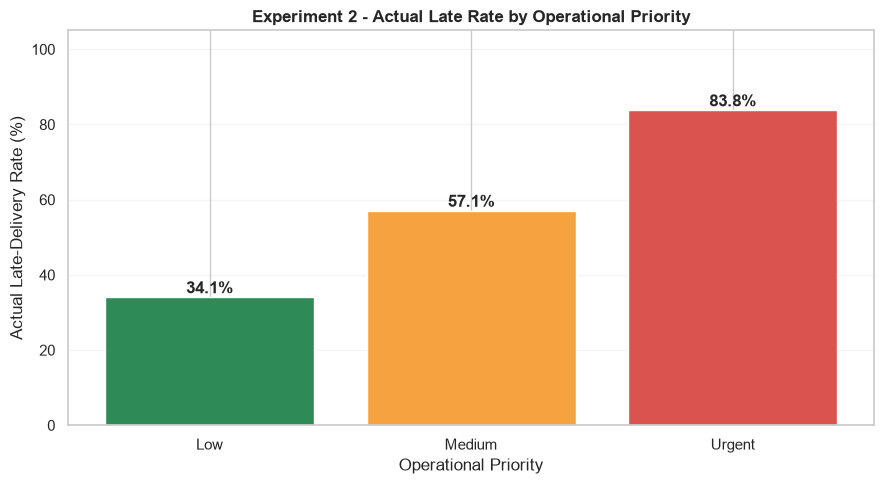

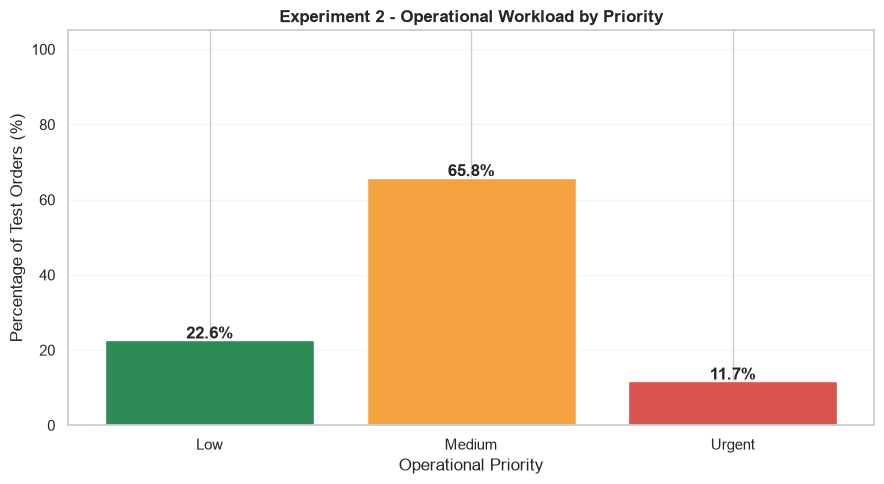


FINAL PRIORITIZED TEST ORDERS


,Order Id,Order_Line_Count,Total_Order_Value,Customer_Segment,Predicted_Risk,Risk_Band,Impact_Band,Operational_Priority,Recommended_Action
0,15681,4,775.87,Consumer,0.9790,High,High,Urgent,Immediate operational escalation
1,14797,4,846.31,Home Office,0.9786,High,High,Urgent,Immediate operational escalation
2,29169,4,627.13,Corporate,0.9773,High,High,Urgent,Immediate operational escalation
3,10464,5,850.41,Consumer,0.9769,High,High,Urgent,Immediate operational escalation
4,13626,5,835.79,Corporate,0.9767,High,High,Urgent,Immediate operational escalation
5,43145,5,1063.41,Home Office,0.9765,High,High,Urgent,Immediate operational escalation
6,65143,4,920.69,Consumer,0.9764,High,High,Urgent,Immediate operational escalation
7,25474,4,806.92,Consumer,0.9763,High,High,Urgent,Immediate operational escalation
8,16565,4,826.90,Consumer,0.9762,High,High,Urgent,Immediate operational escalation
9,4706,4,835.90,Home Office,0.9762,High,High,Urgent,Immediate operational escalation



FINAL EXPERIMENT 2 - LENS 2 BUSINESS SUMMARY
Final Model: Five-Model Soft Voting Ensemble
Classification Threshold: 0.5

Total Unique Test Orders: 4932
Actual Late Orders: 2714
Total Order Value: 2436978.03

Urgent Orders: 575
Actual Late Orders in Urgent Tier: 482
Urgent Tier Workload (%): 11.66
Urgent Tier Late Capture (%): 17.76
Urgent Tier On-Time Orders: 93

FINAL VERIFICATION
Lens 1 predictions connected to Lens 2: PASSED
One priority per unique test order: PASSED
Operational priority rules: PASSED
Final business evaluation: COMPLETED


In [480]:

# ============================================================
# CELL 03 - EXPERIMENT 2
# FINAL CONNECTED BUSINESS PRIORITY EVALUATION
# LENS 1 PREDICTIONS -> LENS 2 ORDER PRIORITIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. VERIFY PREVIOUS CELL OUTPUTS
# ============================================================

required_variables_exp2 = [
    "integrated_test_orders_exp2",
    "FINAL_TEST_THRESHOLD_EXP2",
    "FINAL_RISK_LOW_EXP2",
    "FINAL_RISK_HIGH_EXP2",
    "ORDER_IMPACT_LOW_EXP2",
    "ORDER_IMPACT_HIGH_EXP2",
    "lens2_order_true_exp2",
    "lens2_order_prob_exp2"
]

missing_variables_exp2 = [
    name for name in required_variables_exp2
    if name not in globals()
]

assert not missing_variables_exp2, (
    "Missing variables: "
    + ", ".join(missing_variables_exp2)
)

assert FINAL_TEST_THRESHOLD_EXP2 == 0.50

assert (
    0 < FINAL_RISK_LOW_EXP2 <
    FINAL_RISK_HIGH_EXP2 < 1
)

assert ORDER_IMPACT_LOW_EXP2 < ORDER_IMPACT_HIGH_EXP2

print("=" * 65)
print("EXPERIMENT 2 - FINAL BUSINESS PRIORITY EVALUATION")
print("=" * 65)

print("Final Model: Five-Model Soft Voting Ensemble")
print("Classification Threshold:", FINAL_TEST_THRESHOLD_EXP2)
print(
    "Risk Boundaries:",
    FINAL_RISK_LOW_EXP2,
    FINAL_RISK_HIGH_EXP2
)
print(
    "Monetary Impact Boundaries:",
    round(ORDER_IMPACT_LOW_EXP2, 2),
    round(ORDER_IMPACT_HIGH_EXP2, 2)
)

# ============================================================
# 2. PREPARE UNIQUE-ORDER TEST DATA
# ============================================================

final_business_test_exp2 = integrated_test_orders_exp2.copy()

required_columns_exp2 = [
    "Order Id",
    "Order_Line_Count",
    "Total_Order_Value",
    "Customer_Segment",
    "Predicted_Risk",
    "Actual_Late"
]

assert all(
    col in final_business_test_exp2.columns
    for col in required_columns_exp2
)

assert final_business_test_exp2["Order Id"].is_unique

assert len(final_business_test_exp2) == len(
    lens2_order_true_exp2
)

np.testing.assert_array_equal(
    final_business_test_exp2["Actual_Late"].to_numpy(),
    lens2_order_true_exp2
)

np.testing.assert_allclose(
    final_business_test_exp2["Predicted_Risk"].to_numpy(),
    lens2_order_prob_exp2
)

# Check data quality
final_business_test_exp2["Total_Order_Value"] = (
    pd.to_numeric(
        final_business_test_exp2["Total_Order_Value"],
        errors="raise"
    )
)

assert final_business_test_exp2[
    ["Predicted_Risk", "Total_Order_Value", "Actual_Late"]
].notna().all().all()

assert np.isfinite(
    final_business_test_exp2["Total_Order_Value"]
).all()

assert final_business_test_exp2[
    "Predicted_Risk"
].between(0, 1).all()

print("\nUnique Test Orders:", len(final_business_test_exp2))

# ============================================================
# 3. ASSIGN ORDER-LEVEL RISK BANDS
# ============================================================

# Business risk bands differ from the binary
# classification threshold of 0.50.

final_business_test_exp2["Risk_Band"] = pd.cut(
    final_business_test_exp2["Predicted_Risk"],
    bins=[
        -np.inf,
        FINAL_RISK_LOW_EXP2,
        FINAL_RISK_HIGH_EXP2,
        np.inf
    ],
    labels=["Low", "Medium", "High"],
    right=False
)

assert final_business_test_exp2[
    "Risk_Band"
].notna().all()

# ============================================================
# 4. ASSIGN MONETARY IMPACT BANDS
# ============================================================

# Boundaries calculated from complete training orders,
# not the test outcomes.

final_business_test_exp2["Impact_Band"] = pd.cut(
    final_business_test_exp2["Total_Order_Value"],
    bins=[
        -np.inf,
        ORDER_IMPACT_LOW_EXP2,
        ORDER_IMPACT_HIGH_EXP2,
        np.inf
    ],
    labels=["Low", "Medium", "High"],
    right=False
)

assert final_business_test_exp2[
    "Impact_Band"
].notna().all()

# ============================================================
# 5. ASSIGN FINAL OPERATIONAL PRIORITIES
# ============================================================

# Urgent:
# High Risk + High Monetary Impact

urgent_condition_exp2 = (
    (final_business_test_exp2["Risk_Band"] == "High") &
    (final_business_test_exp2["Impact_Band"] == "High")
)

# Low Priority:
# Low Risk + Low/Medium Impact
# OR Medium Risk + Low Impact

low_condition_exp2 = (
    (
        (final_business_test_exp2["Risk_Band"] == "Low") &
        final_business_test_exp2["Impact_Band"].isin(
            ["Low", "Medium"]
        )
    )
    |
    (
        (final_business_test_exp2["Risk_Band"] == "Medium") &
        (final_business_test_exp2["Impact_Band"] == "Low")
    )
)

# Remaining combinations receive Medium priority.

final_business_test_exp2["Operational_Priority"] = np.select(
    [urgent_condition_exp2, low_condition_exp2],
    ["Urgent", "Low"],
    default="Medium"
)

# ============================================================
# 6. ASSIGN OPERATIONAL RECOMMENDATIONS
# ============================================================

final_action_map_exp2 = {
    "Low": "Routine tracking",
    "Medium": "Enhanced monitoring and review",
    "Urgent": "Immediate operational escalation"
}

final_business_test_exp2["Recommended_Action"] = (
    final_business_test_exp2["Operational_Priority"]
    .map(final_action_map_exp2)
)

assert final_business_test_exp2[
    "Recommended_Action"
].notna().all()

# ============================================================
# 7. EVALUATE RISK BAND PERFORMANCE
# ============================================================

final_risk_band_test_summary_exp2 = (
    final_business_test_exp2
    .groupby("Risk_Band", observed=False)
    .agg(
        Orders=("Actual_Late", "size"),
        Actual_Late_Orders=("Actual_Late", "sum"),
        Mean_Predicted_Risk=("Predicted_Risk", "mean"),
        Actual_Late_Rate=("Actual_Late", "mean")
    )
    .reset_index()
)

total_orders_exp2 = len(final_business_test_exp2)

total_late_orders_exp2 = int(
    final_business_test_exp2["Actual_Late"].sum()
)

total_order_value_exp2 = (
    final_business_test_exp2["Total_Order_Value"].sum()
)

assert total_late_orders_exp2 > 0

final_risk_band_test_summary_exp2["Workload_%"] = (
    100 * final_risk_band_test_summary_exp2["Orders"]
    / total_orders_exp2
)

final_risk_band_test_summary_exp2["Late_Rate_%"] = (
    100 * final_risk_band_test_summary_exp2["Actual_Late_Rate"]
)

final_risk_band_test_summary_exp2["Late_Capture_%"] = (
    100 * final_risk_band_test_summary_exp2["Actual_Late_Orders"]
    / total_late_orders_exp2
)

print("\n" + "=" * 65)
print("LENS 2 - FINAL TEST RISK BAND PERFORMANCE")
print("=" * 65)

display(final_risk_band_test_summary_exp2.round(2))

# ============================================================
# 8. EVALUATE OPERATIONAL PRIORITY PERFORMANCE
# ============================================================

final_priority_test_summary_exp2 = (
    final_business_test_exp2
    .groupby("Operational_Priority")
    .agg(
        Orders=("Order Id", "nunique"),
        Actual_Late_Orders=("Actual_Late", "sum"),
        Total_Order_Value=("Total_Order_Value", "sum"),
        Mean_Predicted_Risk=("Predicted_Risk", "mean")
    )
    .reindex(["Low", "Medium", "Urgent"])
    .reset_index()
)

# Handle empty priority groups
final_priority_test_summary_exp2[
    ["Orders", "Actual_Late_Orders", "Total_Order_Value"]
] = final_priority_test_summary_exp2[
    ["Orders", "Actual_Late_Orders", "Total_Order_Value"]
].fillna(0)

# Percentage of total orders requiring each type of action
final_priority_test_summary_exp2["Workload_%"] = (
    100 * final_priority_test_summary_exp2["Orders"]
    / total_orders_exp2
)

# Percentage of late orders within each priority tier
final_priority_test_summary_exp2["Late_Rate_%"] = (
    100 * final_priority_test_summary_exp2["Actual_Late_Orders"]
    / final_priority_test_summary_exp2["Orders"].replace(
        0, np.nan
    )
)

# Percentage of all actual late orders captured in each tier
final_priority_test_summary_exp2["Late_Capture_%"] = (
    100 * final_priority_test_summary_exp2["Actual_Late_Orders"]
    / total_late_orders_exp2
)

# Percentage of total monetary value represented by each tier
final_priority_test_summary_exp2["Value_Coverage_%"] = (
    100 * final_priority_test_summary_exp2["Total_Order_Value"]
    / total_order_value_exp2
    if total_order_value_exp2 != 0
    else np.nan
)

# On-time orders in each priority tier
final_priority_test_summary_exp2["On_Time_Orders"] = (
    final_priority_test_summary_exp2["Orders"]
    - final_priority_test_summary_exp2["Actual_Late_Orders"]
)

print("\n" + "=" * 65)
print("LENS 2 - FINAL OPERATIONAL PRIORITY PERFORMANCE")
print("=" * 65)

display(final_priority_test_summary_exp2.round(2))

# ============================================================
# 9. RISK VS MONETARY IMPACT MATRIX
# ============================================================

print("\nRISK BAND VS MONETARY IMPACT - ORDER COUNTS")

risk_impact_matrix_exp2 = pd.crosstab(
    final_business_test_exp2["Risk_Band"],
    final_business_test_exp2["Impact_Band"],
    dropna=False
)

display(risk_impact_matrix_exp2)

print("\nRISK + IMPACT -> OPERATIONAL PRIORITY")

priority_rule_matrix_exp2 = (
    final_business_test_exp2
    .pivot_table(
        index="Risk_Band",
        columns="Impact_Band",
        values="Operational_Priority",
        aggfunc="first",
        observed=False
    )
)

# Show the complete rule matrix, including
# combinations absent from the test set.
priority_rule_matrix_exp2 = pd.DataFrame(
    [
        ["Low", "Low", "Medium"],
        ["Low", "Medium", "Medium"],
        ["Medium", "Medium", "Urgent"]
    ],
    index=["Low", "Medium", "High"],
    columns=["Low", "Medium", "High"]
)

display(priority_rule_matrix_exp2)

# ============================================================
# 10. VISUALIZATION - LATE RATE BY PRIORITY
# ============================================================

plot_priority_exp2 = final_priority_test_summary_exp2.copy()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_priority_exp2["Operational_Priority"],
    plot_priority_exp2["Late_Rate_%"].fillna(0),
    color=["#2E8B57", "#F4A340", "#D9534F"]
)

for bar, value in zip(
    bars,
    plot_priority_exp2["Late_Rate_%"]
):
    if pd.notna(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.1f}%",
            ha="center",
            fontweight="bold"
        )

plt.title(
    "Experiment 2 - Actual Late Rate by Operational Priority",
    fontweight="bold"
)
plt.xlabel("Operational Priority")
plt.ylabel("Actual Late-Delivery Rate (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# 11. VISUALIZATION - OPERATIONAL WORKLOAD
# ============================================================

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_priority_exp2["Operational_Priority"],
    plot_priority_exp2["Workload_%"],
    color=["#2E8B57", "#F4A340", "#D9534F"]
)

for bar, value in zip(
    bars,
    plot_priority_exp2["Workload_%"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Experiment 2 - Operational Workload by Priority",
    fontweight="bold"
)
plt.xlabel("Operational Priority")
plt.ylabel("Percentage of Test Orders (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# 12. DISPLAY FINAL OPERATIONAL RECOMMENDATIONS
# ============================================================

print("\nFINAL PRIORITIZED TEST ORDERS")

# Show urgent orders first, followed by
# medium and low priority orders.
priority_rank_exp2 = {
    "Urgent": 0,
    "Medium": 1,
    "Low": 2
}

final_business_test_exp2["Priority_Rank"] = (
    final_business_test_exp2["Operational_Priority"]
    .map(priority_rank_exp2)
)

final_prioritized_orders_exp2 = (
    final_business_test_exp2
    .sort_values(
        [
            "Priority_Rank",
            "Predicted_Risk",
            "Total_Order_Value"
        ],
        ascending=[True, False, False]
    )
    .drop(columns="Priority_Rank")
    .reset_index(drop=True)
)

display(
    final_prioritized_orders_exp2[
        [
            "Order Id",
            "Order_Line_Count",
            "Total_Order_Value",
            "Customer_Segment",
            "Predicted_Risk",
            "Risk_Band",
            "Impact_Band",
            "Operational_Priority",
            "Recommended_Action"
        ]
    ].head(20).round(4)
)

# ============================================================
# 13. VERIFY FINAL RESULTS
# ============================================================

# One record per unique order
assert final_business_test_exp2["Order Id"].is_unique

# All orders must be assigned a priority
assert final_business_test_exp2[
    "Operational_Priority"
].notna().all()

# No orders lost during priority classification
assert (
    final_priority_test_summary_exp2["Orders"].sum()
    == len(final_business_test_exp2)
)

# No actual late orders lost
assert (
    final_priority_test_summary_exp2[
        "Actual_Late_Orders"
    ].sum()
    == total_late_orders_exp2
)

# Every order has one business recommendation
assert final_business_test_exp2[
    "Recommended_Action"
].notna().all()

# Check operational priority assignment
assert (
    (final_business_test_exp2["Operational_Priority"] == "Urgent")
    == urgent_condition_exp2
).all()

# ============================================================
# 14. FINAL EXPERIMENT 2 BUSINESS SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("FINAL EXPERIMENT 2 - LENS 2 BUSINESS SUMMARY")
print("=" * 65)

print("Final Model: Five-Model Soft Voting Ensemble")
print("Classification Threshold:", FINAL_TEST_THRESHOLD_EXP2)

print("\nTotal Unique Test Orders:", total_orders_exp2)
print("Actual Late Orders:", total_late_orders_exp2)

print(
    "Total Order Value:",
    round(total_order_value_exp2, 2)
)

urgent_orders_exp2 = final_business_test_exp2[
    final_business_test_exp2["Operational_Priority"]
    == "Urgent"
]

print("\nUrgent Orders:", len(urgent_orders_exp2))

print(
    "Actual Late Orders in Urgent Tier:",
    int(urgent_orders_exp2["Actual_Late"].sum())
)

print(
    "Urgent Tier Workload (%):",
    round(
        100 * len(urgent_orders_exp2) / total_orders_exp2,
        2
    )
)

print(
    "Urgent Tier Late Capture (%):",
    round(
        100 * urgent_orders_exp2["Actual_Late"].sum()
        / total_late_orders_exp2,
        2
    )
)

print(
    "Urgent Tier On-Time Orders:",
    len(urgent_orders_exp2)
    - int(urgent_orders_exp2["Actual_Late"].sum())
)

print("\nFINAL VERIFICATION")
print("Lens 1 predictions connected to Lens 2: PASSED")
print("One priority per unique test order: PASSED")
print("Operational priority rules: PASSED")
print("Final business evaluation: COMPLETED")

# ============================================================
# INTERPRETATION
# ============================================================

# Lens 2 uses the same five-model ensemble predictions
# already evaluated in Lens 1.
#
# Risk_Band represents predicted late-delivery likelihood.
#
# Impact_Band represents relative monetary exposure,
# calculated from complete order value.
#
# Operational_Priority combines predicted risk and
# monetary impact to recommend an intervention level.
#
# Low Priority:
# Routine shipment tracking.
#
# Medium Priority:
# Enhanced monitoring and review.
#
# Urgent Priority:
# Immediate operational escalation.
#
# Workload_% measures the percentage of orders
# assigned to each operational priority.
#
# Late_Rate_% measures observed late-delivery
# frequency within each priority tier.
#
# Late_Capture_% measures the percentage of all
# late orders included in each tier.
#
# Value_Coverage_% measures the percentage of total
# order value represented by each tier.
#
# On_Time_Orders measures orders that did not
# experience late delivery within each tier.
#
# Higher late rates in higher-priority tiers
# would support meaningful risk differentiation.
#
# The evaluation describes prioritization performance,
# not proven intervention benefits or monetary savings.
#
# All model parameters, risk boundaries, and business
# rules must remain frozen after test evaluation.
# ============================================================


# Final Project Summary — DataCo Supply Chain Late-Delivery Prediction and Shipment Prioritization

## 1. Project Overview

This project developed an integrated machine learning and business decision-support system for predicting late deliveries and prioritizing shipments within the DataCo Supply Chain dataset.

The system consists of two interconnected components:

- **Lens 1 — Late-Delivery Risk Prediction:** Predicts the probability of a shipment being delivered late using a five-model ensemble.
- **Lens 2 — Shipment Risk Profiling and Business Prioritization:** Combines predicted late-delivery probabilities with monetary order value to categorize orders by risk and recommend operational actions.

The final system uses **Experiment 2**, which combines five tuned machine learning models through equal-weight soft voting.

## 2. Final Model Configuration

| Component | Final Configuration |
|---|---|
| Model | Five-Model Soft Voting Ensemble |
| Base models | Logistic Regression, Decision Tree, Random Forest, LightGBM, Linear SVM |
| Ensemble weights | 20% per model |
| Selected features | 100 encoded features |
| Classification threshold | 0.50 |
| Low-risk boundary | Below 0.30 |
| Medium-risk boundary | 0.30 to below 0.65 |
| High-risk boundary | 0.65 and above |
| Monetary impact thresholds | 314.55 and 625.71 |
| Final evaluation | Order-line level and unique-order level |

The ensemble calculates the average predicted late-delivery probability across all five tuned models. Linear SVM predictions were calibrated to produce probabilities before inclusion in the ensemble.

The classification threshold of **0.50** was selected to maintain relatively high precision and accuracy, rather than maximizing F1-score.

## 3. Lens 1 — Late-Delivery Risk Prediction

### Final Validation vs Test Performance

| Metric | Validation | Test |
|---|---:|---:|
| Accuracy | 0.7178 | 0.7169 |
| Precision | 0.8497 | 0.8481 |
| Recall | 0.5955 | 0.5895 |
| F1-score | 0.7003 | 0.6956 |
| ROC-AUC | 0.7762 | 0.7675 |
| Average Precision | 0.8351 | 0.8303 |
| Brier Score | — | 0.1854 |
| Log Loss | — | 0.5407 |

The final ensemble achieved **71.69% test accuracy**, **84.81% precision**, **58.95% recall**, and an **F1-score of 69.56%**.

The similarity between validation and test performance indicates relatively stable performance across these evaluation splits. The test ROC-AUC of 0.7675 demonstrates moderate ability to distinguish late deliveries from on-time deliveries.

However, recall remains an important limitation because approximately 41% of actual late order-line deliveries were not identified at the selected classification threshold.

### Final Order-Line Test Confusion Matrix

| Actual / Predicted | On Time | Late |
|---|---:|---:|
| Actual On Time | 5,265 (TN) | 775 (FP) |
| Actual Late | 3,012 (FN) | 4,326 (TP) |

Across **13,378 test order-line records**, the ensemble correctly identified 4,326 late deliveries and 5,265 on-time deliveries.

Nevertheless, 3,012 late deliveries were incorrectly classified as on time, highlighting the need for further improvement in late-delivery detection.

## 4. Lens 2 — Shipment Risk Profiling

Lens 2 converts the final ensemble's late-delivery probabilities into business risk categories.

Order-line probabilities are connected to their original Order IDs and averaged to generate one risk score per unique order.

The test dataset contained **4,932 unique orders**, with 2,714 actual late orders.

### Final Risk Band Performance

| Risk Band | Orders | Actual Late Orders | Actual Late Rate | Workload Share | Late-Order Capture |
|---|---:|---:|---:|---:|---:|
| Low | 228 | 22 | 9.65% | 4.62% | 0.81% |
| Medium | 2,816 | 1,082 | 38.42% | 57.10% | 39.87% |
| High | 1,888 | 1,610 | 85.28% | 38.28% | 59.32% |

The risk bands demonstrate clear separation in observed late-delivery frequency.

- **Low Risk:** Only 9.65% of orders experienced late delivery.
- **Medium Risk:** 38.42% of orders experienced late delivery.
- **High Risk:** 85.28% of orders experienced late delivery.

The High Risk category captured **59.32% of all actual late orders** while containing 38.28% of total test orders.

These results indicate that the ensemble's predicted probabilities are useful for distinguishing groups with different observed late-delivery frequencies.

## 5. Business Impact and Operational Prioritization

The second component of Lens 2 considers monetary exposure using complete order values.

Monetary impact boundaries were calculated using training-order value quantiles:

- Low Impact: Below 314.55
- Medium Impact: 314.55 to below 625.71
- High Impact: 625.71 and above

Predicted delivery risk and monetary impact were combined to assign three operational priorities.

| Priority | Recommended Action |
|---|---|
| Low | Routine tracking |
| Medium | Enhanced monitoring and review |
| Urgent | Immediate operational escalation |

Urgent priority is assigned only when an order has both High Risk and High Monetary Impact.

### Final Operational Priority Performance

| Metric | Low | Medium | Urgent |
|---|---:|---:|---:|
| Total Orders | 1,114 | 3,243 | 575 |
| Actual Late Orders | 380 | 1,852 | 482 |
| Late-Delivery Rate | 34.11% | 57.11% | 83.83% |
| Operational Workload | 22.59% | 65.75% | 11.66% |
| Late-Order Capture | 14.00% | 68.24% | 17.76% |
| Monetary Value Coverage | 8.67% | 70.70% | 20.63% |
| On-Time Orders | 734 | 1,391 | 93 |

The final priority system classified **575 orders as Urgent**, representing only **11.66% of total test orders**.

Among these urgent orders, 482 actually experienced late delivery, resulting in an observed late-delivery rate of **83.83%**.

The Urgent tier also represented **20.63% of the total order value**, despite accounting for only 11.66% of orders.

This suggests that the priority system successfully concentrates a subset of high-risk, high-value orders into a manageable intervention group.

However, the Urgent category captured only **17.76% of all actual late orders**. The Medium category contained the majority of late orders (68.24%) and therefore remains important for operational monitoring.

The total order value represented in the evaluated test dataset was **2,436,978.03**.

## 6. Integrated Lens 1 and Lens 2 Evaluation

The two lenses were successfully connected using the same final five-model ensemble probabilities.

### Final Test Performance by Evaluation Level

| Metric | Lens 1 — Order Lines | Lens 2 — Unique Orders |
|---|---:|---:|
| Evaluation Records | 13,378 | 4,932 |
| Accuracy | 0.7169 | 0.7200 |
| Precision | 0.8481 | 0.8525 |
| Recall | 0.5895 | 0.5940 |
| F1-score | 0.6956 | 0.7001 |
| ROC-AUC | 0.7675 | 0.7734 |
| Average Precision | 0.8303 | 0.8344 |
| Brier Score | 0.1854 | 0.1838 |
| Log Loss | 0.5407 | 0.5371 |

Order-level aggregation resulted in slightly improved evaluation metrics compared with order-line predictions.

The unique-order evaluation achieved:

- Accuracy: **72.00%**
- Precision: **85.25%**
- Recall: **59.40%**
- F1-score: **70.01%**
- ROC-AUC: **0.7734**

The improvement may result from averaging individual order-line risk probabilities and evaluating each order equally rather than weighting orders by their number of lines.

### Order-Level Confusion Matrix

| Actual / Predicted | On Time | Late |
|---|---:|---:|
| Actual On Time | 1,939 (TN) | 279 (FP) |
| Actual Late | 1,102 (FN) | 1,612 (TP) |

The system correctly identified 1,612 late orders and 1,939 on-time orders.

However, 1,102 late orders remained undetected, showing that improving recall remains an important opportunity.

## 7. Feature Importance and Error Analysis Findings

Feature importance analysis across the tuned individual models consistently identified **Shipping Mode** as a highly influential predictor.

In the earlier validation error analysis, the ensemble exhibited particularly weak performance for Standard Class shipments, accounting for all 3,033 validation false negatives.

This suggests that the ensemble relies strongly on shipping-mode-related patterns and has difficulty distinguishing late and on-time deliveries within certain shipping categories.

Additional analysis showed that geographical market performance varied less substantially, although LATAM recorded relatively higher prediction-error percentages.

These findings support further investigation into shipping-mode dependence, feature interactions, target definition and potential shortcut learning.

## 8. Limitations

Although the final system demonstrated useful classification performance and risk differentiation, several limitations remain.

**Late-delivery recall:** The model identifies approximately 59% of actual late deliveries at threshold 0.50, leaving a significant proportion undetected.

**Dependence on Shipping Mode:** Model importance and error analysis indicate that Shipping Mode strongly influences predictions, potentially limiting discrimination within individual shipping categories.

**Order-level probability aggregation:** Order risks are calculated using the mean of their order-line probabilities rather than a separately trained order-level model. The resulting order-level probabilities require independent calibration assessment.

**Operational policy:** The Low, Medium and Urgent priority categories are based on predefined business rules. They were not optimized using real intervention costs or measured operational outcomes.

**Monetary impact:** Total order value represents monetary exposure, not the actual financial loss caused by delivery delays.

**Generalization and leakage:** Similar validation and test results provide evidence of performance stability, but do not independently establish that every preprocessing or feature-selection step was leakage-free.

## 9. Final Project Conclusion

The DataCo Supply Chain Late-Delivery Prediction project successfully integrated machine learning classification with business-oriented shipment prioritization.

**Lens 1** used a five-model soft-voting ensemble to predict late-delivery risk, achieving 71.69% order-line test accuracy and a ROC-AUC of 0.7675. Although prediction precision was relatively high, recall remained moderate, highlighting the difficulty of identifying all late deliveries.

**Lens 2** translated predicted probabilities into meaningful risk categories and combined them with training-derived monetary impact bands to assign operational priorities.

The final order-level system achieved 72.00% accuracy and demonstrated clear risk differentiation, with observed late-delivery rates increasing from 9.65% in the Low Risk category to 85.28% in the High Risk category.

The revised operational priority system identified 575 Urgent orders, representing 11.66% of the test workload, with an observed late-delivery rate of 83.83% and 20.63% of total monetary value.

These results demonstrate that the proposed system can identify higher-risk orders and organize them into operationally meaningful priority groups.

**Overall, the project provides a validated proof of concept for combining late-delivery prediction and business-impact-based prioritization.** Further improvements should focus on reducing false negatives, investigating shipping-mode dependence, validating order-level probability calibration, and assessing intervention costs and benefits before real-world deployment.